In [ ]:
# Configuración: el código de los capítulos se escribió para ejecutarse desde docs/
import os
import sys
from pathlib import Path

if Path("docs").is_dir():
    os.chdir("docs")
sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

# Clasificación de la cobertura forestal a partir de variables cartográficas

**Curso:** Machine Learning  
**Entrega:** Entregable 4 (final)  
**Autoras:** Ana Galván, Valeria Oñate y María José Ruiz  
**Fecha:** 23 de octubre de 2026

## Resumen

La cartografía de la cobertura forestal es un insumo básico para el manejo de bosques, la evaluación del
riesgo de incendio y la conservación de hábitats, pero su levantamiento en campo es costoso y, en áreas
protegidas o remotas, difícil de mantener actualizado. Este estudio evalúa en qué medida variables
cartográficas (topografía, hidrografía, red vial, área administrativa y tipo de suelo) permiten predecir el
tipo de cobertura dominante en celdas de 30 × 30 m del Roosevelt National Forest (Colorado, Estados Unidos).
Usa el conjunto *Covertype*: 581.012 celdas, 54 predictoras y 7 clases con una razón de desbalance de 103:1
(Blackard, 1998; Blackard y Dean, 1999).

La **Parte I** documenta el análisis exploratorio, una auditoría de fuga de información, el preprocesamiento
y un modelo base de regresión logística multinomial (F1 macro de 0,558 en la prueba reservada). La
**Parte II** construye un diseño factorial de **112 combinaciones** (7 algoritmos × 4 estrategias de
balanceo × 4 métodos de optimización), con el mismo espacio de búsqueda y el mismo presupuesto para todas,
evaluadas con validación cruzada anidada. **Random Forest con SMOTE es la mejor combinación** (F1 macro de
0,783 en la validación anidada y de 0,866 en la prueba reservada con el conjunto completo).

La **Parte III** propone un modelo original, el **ensamble por competencia local y por clase (ECLC)**. Para
cada celda nueva y cada cobertura, pondera a los siete modelos del benchmark según su pérdida logarítmica en
las celdas vecinas, con pesos en forma cerrada derivados de un objetivo regularizado con entropía, contracción
hacia la pérdida global y balanceo de clases. Se demuestran la unicidad de los pesos, una cota de la pérdida
local y la complejidad del algoritmo.

**Con el conjunto de entrenamiento completo, el ECLC alcanza un F1 macro de 0,907 en validación cruzada y de
0,915 en la prueba reservada.** Supera al mejor benchmark (árbol de decisión, 0,897) en los 10 pliegues, con
diferencias significativas según las pruebas de Friedman, Wilcoxon con corrección de Holm y t corregida de
Nadeau-Bengio. Con la submuestra de 40.000 celdas también supera en promedio a los siete benchmarks, aunque la
diferencia con el mejor es menor. El *stacking* lineal y HistGradientBoosting obtienen un F1 macro mayor que el
ECLC.

**Palabras clave:** clasificación multiclase, cobertura forestal, desbalance de clases, validación cruzada
anidada, selección dinámica de ensambles, competencia local, pruebas de hipótesis.

## Pregunta de investigación

¿Puede un ensamble que pondera a cada modelo según su desempeño local y por clase superar, de forma
estadísticamente significativa, a los mejores modelos del benchmark al predecir la cobertura forestal a partir
de variables cartográficas? Y, como base para responderla, ¿qué combinación de algoritmo, tratamiento del
desbalance y estrategia de optimización ofrece el mejor desempeño cuando todas se comparan en igualdad de
condiciones?

## Objetivos

1. Comparar 112 combinaciones de algoritmo, balanceo y optimización con el mismo espacio de búsqueda y el mismo
   presupuesto, y seleccionar con criterios estadísticos la mejor combinación de cada algoritmo (Parte II).
2. Diseñar e implementar un modelo original con novedad documentada y propiedades demostradas (capítulos 10 y 11).
3. Validar estadísticamente su superioridad frente a los modelos del benchmark (capítulo 12).

## Organización del documento

| Parte | Capítulo | Contenido |
|---|---|---|
| I | 1–4. Datos, EDA y modelo base | Base de datos, análisis exploratorio, fuga y estructura, preprocesamiento, modelo base |
| II | 5. Benchmark combinatorio | 112 combinaciones con validación anidada, finalista y evaluación en la prueba reservada |
| II | 6. Optimización de hiperparámetros | Grid, Random, Bayesiana (TPE) y Genética; desempeño en cualquier momento y *Successive Halving* |
| II | 7. Comparación estadística | Friedman, Nemenyi, DeLong, *bootstrap* y tamaño del efecto |
| II | 8. Interpretabilidad | SHAP global y local, y comparación con LIME |
| II | 9. Eficiencia y conclusiones del benchmark | Complejidad, implementaciones optimizadas, paralelización, revisión crítica |
| III | 10. Revisión de literatura | Bases, cadenas de búsqueda, matriz de novedad, trabajos cercanos y declaración de novedad |
| III | 11. Modelo original (ECLC) | Formulación, demostraciones, algoritmo, complejidad, pruebas, ablación, robustez y SHAP |
| III | 12. Validación estadística | Protocolo, supuestos, pruebas con Holm, intervalos, tamaños del efecto y entrenamiento completo |
| III | 13. Conclusiones | Hallazgos, limitaciones, trabajo futuro y declaración de autoría |
| III | 14. Reproducibilidad | Entorno, semillas, orden de ejecución y tabla maestra de experimentos |
| — | Apéndices | Código auxiliar, registro de cambios del benchmark y bibliografía |


# 1. Base de datos

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from _utils import (
    BIN_COLS, CLASS_NAMES, CLASS_PALETTE, DISPLAY_NAMES, FEATURES, NUM_COLS, RANDOM_STATE,
    SOIL_COLS, TARGET, WILD_COLS, WILD_NAMES, load_covertype, split_covertype, wilderness_label,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

df, X, y = load_covertype()
X_train, X_test, y_train, y_test = split_covertype(X, y)

## 1.1 Definición del problema

El objetivo es **clasificar el tipo de cobertura forestal dominante** de una celda de terreno de 30 × 30 m a partir de variables cartográficas. La variable objetivo `Cover_Type` toma siete valores, cada uno correspondiente a una especie o asociación forestal dominante. Las predictoras describen la topografía (elevación, orientación, pendiente y sombreado), la proximidad a elementos del paisaje (agua superficial, carreteras y puntos de ignición de incendios históricos), el área silvestre a la que pertenece la celda y su tipo de suelo.

Formalmente, se busca una función $f: \mathbb{R}^{54} \to \{1, \dots, 7\}$ que asigne a cada celda su clase de cobertura, aprendida a partir de ejemplos etiquetados y evaluada sobre celdas no vistas durante el entrenamiento.

## 1.2 Justificación de la selección

La elección del conjunto *Covertype* se apoya en cuatro razones:

1. **Relevancia aplicada.** La cobertura forestal condiciona la gestión de bosques, el riesgo y el comportamiento de incendios, la conservación de hábitats y la regulación hídrica. Inferirla a partir de cartografía reduce la dependencia de inventarios de campo costosos.
2. **Tamaño y calidad.** Con 581.012 observaciones, el conjunto es lo bastante grande para sostener validación cruzada anidada y particiones de prueba holgadas sin agotar las clases minoritarias; además no tiene valores faltantes y proviene de fuentes oficiales (US Forest Service y US Geological Survey).
3. **Dificultad adecuada.** Es un problema multiclase con desbalance fuerte y fronteras de decisión no lineales. Es además un conjunto de referencia habitual en la evaluación de algoritmos para datos tabulares (Grinsztajn et al., 2022). Un clasificador lineal obtiene un desempeño intermedio, lo que deja margen de mejora real para modelos más complejos y evita un problema trivial.
4. **Baja exposición a fuga de información.** Las variables son atributos físicos del terreno medidos de forma independiente de la etiqueta, y no existen identificadores ni variables derivadas de la cobertura.

## 1.3 Fuente de los datos y licencia

| Atributo | Detalle |
|---|---|
| Nombre | Covertype |
| Repositorio | UCI Machine Learning Repository: <https://archive.ics.uci.edu/dataset/31/covertype> |
| DOI | [10.24432/C50K5N](https://doi.org/10.24432/C50K5N) |
| Autor original | Jock A. Blackard (US Forest Service), con Denis J. Dean y Charles W. Anderson (Colorado State University) |
| Fuentes primarias | Sistema de Información de Recursos de la Región 2 del US Forest Service (cobertura) y datos del US Geological Survey y del USFS (variables cartográficas) |
| Fecha de donación | 1 de agosto de 1998 |
| Licencia | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| Referencia | (Blackard y Dean, 1999) |

La licencia CC BY 4.0 permite usar, compartir y adaptar los datos con fines académicos siempre que se reconozca la autoría, como se hace en este documento.

## 1.4 Diccionario de variables

| Variable | Tipo | Unidad | Significado |
|---|---|---|---|
| `Elevation` | Numérica continua | m | Elevación sobre el nivel del mar |
| `Aspect` | Numérica circular | ° azimut (0–360) | Orientación de la ladera respecto al norte |
| `Slope` | Numérica continua | ° | Pendiente del terreno |
| `Horizontal_Distance_To_Hydrology` | Numérica continua | m | Distancia horizontal a la fuente de agua superficial más cercana |
| `Vertical_Distance_To_Hydrology` | Numérica continua | m | Diferencia de altura con esa fuente de agua (negativa si la celda está por debajo) |
| `Horizontal_Distance_To_Roadways` | Numérica continua | m | Distancia horizontal a la carretera más cercana |
| `Hillshade_9am` | Numérica discreta | índice 0–255 | Iluminación relativa a las 9 a. m. en el solsticio de verano |
| `Hillshade_Noon` | Numérica discreta | índice 0–255 | Iluminación relativa al mediodía en el solsticio de verano |
| `Hillshade_3pm` | Numérica discreta | índice 0–255 | Iluminación relativa a las 3 p. m. en el solsticio de verano |
| `Horizontal_Distance_To_Fire_Points` | Numérica continua | m | Distancia horizontal al punto de ignición de incendio forestal más cercano |
| `Wilderness_Area_1` … `_4` | Binaria (*one-hot*) | 0/1 | Área silvestre: 1 Rawah, 2 Neota, 3 Comanche Peak, 4 Cache la Poudre |
| `Soil_Type_1` … `_40` | Binaria (*one-hot*) | 0/1 | Tipo de suelo según la clasificación de unidades ecológicas terrestres (ELU) del USFS |
| `Cover_Type` | Categórica nominal (objetivo) | 1–7 | Tipo de cobertura forestal dominante |

Las siete clases de la variable objetivo son:

In [2]:
pd.DataFrame(
    {"Clase": list(CLASS_NAMES.keys()), "Cobertura": list(CLASS_NAMES.values())}
).set_index("Clase")

Clase,Cobertura
1,Abeto/pícea (Spruce/Fir)
2,Pino lodgepole
3,Pino ponderosa
4,Álamo/sauce (Cottonwood/Willow)
5,Álamo temblón (Aspen)
6,Abeto de Douglas
7,Krummholz


Los 40 tipos de suelo corresponden a unidades ELU del US Forest Service. Su descripción completa se incluye a continuación de forma plegable, porque resulta útil para interpretar los coeficientes del modelo, pero no para la lectura general.

In [3]:
soil_desc = [
    (2702, "Cathedral family - Rock outcrop complex, extremely stony"),
    (2703, "Vanet - Ratake families complex, very stony"),
    (2704, "Haploborolis - Rock outcrop complex, rubbly"),
    (2705, "Ratake family - Rock outcrop complex, rubbly"),
    (2706, "Vanet family - Rock outcrop complex, rubbly"),
    (2717, "Vanet - Wetmore families - Rock outcrop complex, stony"),
    (3501, "Gothic family"),
    (3502, "Supervisor - Limber families complex"),
    (4201, "Troutville family, very stony"),
    (4703, "Bullwark - Catamount families - Rock outcrop complex, rubbly"),
    (4704, "Bullwark - Catamount families - Rock land complex, rubbly"),
    (4744, "Legault family - Rock land complex, stony"),
    (4758, "Catamount family - Rock land - Bullwark family complex, rubbly"),
    (5101, "Pachic Argiborolis - Aquolis complex"),
    (5151, "Sin especificar en el inventario de suelos del USFS"),
    (6101, "Cryaquolis - Cryoborolis complex"),
    (6102, "Gateview family - Cryaquolis complex"),
    (6731, "Rogert family, very stony"),
    (7101, "Typic Cryaquolis - Borohemists complex"),
    (7102, "Typic Cryaquepts - Typic Cryaquolls complex"),
    (7103, "Typic Cryaquolls - Leighcan family, till substratum complex"),
    (7201, "Leighcan family, till substratum, extremely bouldery"),
    (7202, "Leighcan family, till substratum - Typic Cryaquolls complex"),
    (7700, "Leighcan family, extremely stony"),
    (7701, "Leighcan family, warm, extremely stony"),
    (7702, "Granile - Catamount families complex, very stony"),
    (7709, "Leighcan family, warm - Rock outcrop complex, extremely stony"),
    (7710, "Leighcan family - Rock outcrop complex, extremely stony"),
    (7745, "Como - Legault families complex, extremely stony"),
    (7746, "Como family - Rock land - Legault family complex, extremely stony"),
    (7755, "Leighcan - Catamount families complex, extremely stony"),
    (7756, "Catamount family - Rock outcrop - Leighcan family complex, extremely stony"),
    (7757, "Leighcan - Catamount families - Rock outcrop complex, extremely stony"),
    (7790, "Cryorthents - Rock land complex, extremely stony"),
    (8703, "Cryumbrepts - Rock outcrop - Cryaquepts complex"),
    (8707, "Bross family - Rock land - Cryumbrepts complex, extremely stony"),
    (8708, "Rock outcrop - Cryumbrepts - Cryorthents complex, extremely stony"),
    (8771, "Leighcan - Moran families - Cryaquolls complex, extremely stony"),
    (8772, "Moran family - Cryorthents - Leighcan family complex, extremely stony"),
    (8776, "Moran family - Cryorthents - Rock land complex, extremely stony"),
]
pd.DataFrame(
    [(f"Soil_Type_{i}", code, desc) for i, (code, desc) in enumerate(soil_desc, start=1)],
    columns=["Variable", "Código ELU", "Descripción"],
).set_index("Variable")

Variable,Código ELU,Descripción
Soil_Type_1,2702,"Cathedral family - Rock outcrop complex, extremely stony"
Soil_Type_2,2703,"Vanet - Ratake families complex, very stony"
Soil_Type_3,2704,"Haploborolis - Rock outcrop complex, rubbly"
Soil_Type_4,2705,"Ratake family - Rock outcrop complex, rubbly"
Soil_Type_5,2706,"Vanet family - Rock outcrop complex, rubbly"
Soil_Type_6,2717,"Vanet - Wetmore families - Rock outcrop complex, stony"
Soil_Type_7,3501,Gothic family
Soil_Type_8,3502,Supervisor - Limber families complex
Soil_Type_9,4201,"Troutville family, very stony"
Soil_Type_10,4703,"Bullwark - Catamount families - Rock outcrop complex, rubbly"


## 1.5 Estructura de los datos

In [4]:
estructura = pd.DataFrame(
    {
        "Tipo de dato en el archivo": df.dtypes.astype(str).value_counts(),
    }
)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]} (54 predictoras + 1 objetivo)".replace(",", "."))
print(f"Predictoras numéricas: {len(NUM_COLS)} | Indicadoras de área silvestre: {len(WILD_COLS)} | Indicadoras de suelo: {len(SOIL_COLS)}")
estructura

Filas: 581.012 | Columnas: 55 (54 predictoras + 1 objetivo)
Predictoras numéricas: 10 | Indicadoras de área silvestre: 4 | Indicadoras de suelo: 40


,Tipo de dato en el archivo
int64,55


- **Unidad de observación:** una celda de 30 × 30 m del terreno.
- **Nivel de agregación:** cada fila resume la celda completa; la cobertura corresponde al tipo dominante en ella según el sistema de información del USFS, y las variables cartográficas se derivan de modelos digitales de elevación y capas del USGS y del USFS.
- **Tipo de datos:** transversal. No hay variable temporal: la información describe el estado del bosque en el momento de construcción de la cartografía, y todas las celdas corresponden a una misma fecha de referencia.
- **Componente espacial:** existe de forma implícita. Las celdas pertenecen a cuatro áreas silvestres contiguas del norte de Colorado, pero el conjunto no incluye coordenadas geográficas. La única referencia espacial disponible es el área silvestre, que se analiza en la sección 2.7.
- **Codificación:** las dos variables categóricas originales (área silvestre, 4 niveles, y tipo de suelo, 40 niveles) vienen codificadas en formato *one-hot*.

## 1.6 Reserva del conjunto de prueba

Antes de cualquier análisis que pueda influir en el modelado, se reserva el 20 % de los datos como conjunto de prueba. La partición es **estratificada por la variable objetivo** para conservar las proporciones de las siete clases, algo imprescindible con clases que representan menos del 1 % de los datos, y usa la semilla `42`. El conjunto de prueba solo se utiliza en la evaluación final del capítulo 3.

In [5]:
particion = pd.DataFrame(
    {
        "Entrenamiento (n)": y_train.value_counts().sort_index(),
        "Prueba (n)": y_test.value_counts().sort_index(),
        "Entrenamiento (%)": (100 * y_train.value_counts(normalize=True).sort_index()).round(2),
        "Prueba (%)": (100 * y_test.value_counts(normalize=True).sort_index()).round(2),
    }
)
particion.index = [f"{k} {CLASS_NAMES[k]}" for k in particion.index]
particion.loc["Total"] = [len(y_train), len(y_test), 100.0, 100.0]
particion = particion.astype({"Entrenamiento (n)": int, "Prueba (n)": int})
particion

,Entrenamiento (n),Prueba (n),Entrenamiento (%),Prueba (%)
1 Abeto/pícea (Spruce/Fir),169472,42368,36.46,36.46
2 Pino lodgepole,226640,56661,48.76,48.76
3 Pino ponderosa,28603,7151,6.15,6.15
4 Álamo/sauce (Cottonwood/Willow),2198,549,0.47,0.47
5 Álamo temblón (Aspen),7594,1899,1.63,1.63
6 Abeto de Douglas,13894,3473,2.99,2.99
7 Krummholz,16408,4102,3.53,3.53
Total,464809,116203,100.00,100.00


Las proporciones por clase coinciden en ambos conjuntos hasta la segunda cifra decimal, lo que confirma que la estratificación funcionó. Los diagnósticos que implican decisiones de modelado, como los umbrales de valores atípicos, se calculan desde aquí solo con el conjunto de entrenamiento. Los chequeos estructurales que no conducen a ninguna decisión (dimensiones, tipos, faltantes y rangos válidos) se reportan sobre el conjunto completo.

## 1.7 Tamaño de la muestra

In [6]:
n, p = X.shape
conteos = y.value_counts().sort_index()
resumen = pd.Series(
    {
        "Observaciones (n)": f"{n:,}".replace(",", "."),
        "Predictoras (p)": p,
        "Relación n/p": f"{n / p:,.0f}".replace(",", "."),
        "Relación n/p (solo entrenamiento)": f"{len(X_train) / p:,.0f}".replace(",", "."),
        "Clase mayoritaria": f"{CLASS_NAMES[conteos.idxmax()]} ({conteos.max():,})".replace(",", "."),
        "Clase minoritaria": f"{CLASS_NAMES[conteos.idxmin()]} ({conteos.min():,})".replace(",", "."),
        "Razón de desbalance (mayoritaria/minoritaria)": f"{conteos.max() / conteos.min():.1f}",
        "Áreas silvestres (entidades de nivel superior)": 4,
    },
    name="Valor",
)
resumen.to_frame()

,Valor
Observaciones (n),581.012
Predictoras (p),54
Relación n/p,10.759
Relación n/p (solo entrenamiento),8.608
Clase mayoritaria,Pino lodgepole (283.301)
Clase minoritaria,Álamo/sauce (Cottonwood/Willow) (2.747)
Razón de desbalance (mayoritaria/minoritaria),103.1
Áreas silvestres (entidades de nivel superior),4


La relación entre observaciones y predictoras es alta tanto en el conjunto completo (más
de 10.000) como en el de entrenamiento, que es el que de verdad importa para ajustar el
modelo (más de 8.000), de modo que el riesgo de sobreajuste por dimensionalidad es bajo
para un modelo lineal. Aun así, el **tamaño efectivo de la muestra es menor que el número
de filas** por dos motivos:

- **Autocorrelación espacial.** Las celdas vecinas comparten elevación, suelo y cobertura. Aunque el conjunto no trae coordenadas, es razonable suponer que muchas celdas del muestreo son adyacentes y, por tanto, no son observaciones independientes.
- **Pocas entidades de nivel superior.** Solo hay cuatro áreas silvestres, y algunas clases dependen casi por completo de una de ellas (sección 2.1). Para aprender la clase 4 (álamo/sauce) hay 2.747 celdas, todas del área Cache la Poudre, lo que equivale en la práctica a un número pequeño de rodales.

## 1.8 Calidad de los datos

### Valores faltantes

In [7]:
faltantes = df.isna().sum()
print(f"Celdas faltantes en todo el conjunto: {int(faltantes.sum())}")
print(f"Columnas con al menos un faltante: {int((faltantes > 0).sum())}")

Celdas faltantes en todo el conjunto: 0
Columnas con al menos un faltante: 0


El conjunto **no tiene valores faltantes** en ninguna de sus 55 columnas, lo que coincide con la documentación del repositorio. Por lo tanto, no es necesario analizar el mecanismo de ausencia (MCAR, MAR o MNAR) ni aplicar pruebas como la de Little (Little, 1988), y el *pipeline* no incluye imputación. Sí se revisa que no existan valores centinela que oculten faltantes (por ejemplo, ceros o códigos como −999 en lugar de nulos); ese análisis se presenta en la subsección de valores imposibles.

### Duplicados exactos y casi-duplicados

In [8]:
dup_full = df.duplicated().sum()
dup_X = X.duplicated().sum()

# Casi-duplicados: celdas idénticas en área, suelo, orientación y pendiente, con diferencias
# menores a la resolución de los datos en las variables continuas.
redondeo = X_train.copy()
redondeo["Elevation"] = (redondeo["Elevation"] / 10).round()
for col in ["Horizontal_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points"]:
    redondeo[col] = (redondeo[col] / 30).round()
redondeo["Vertical_Distance_To_Hydrology"] = (redondeo["Vertical_Distance_To_Hydrology"] / 5).round()
for col in ["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]:
    redondeo[col] = (redondeo[col] / 5).round()

grupos = redondeo.assign(y=y_train).groupby(FEATURES, sort=False)["y"]
tam = grupos.transform("size")
n_clases = grupos.transform("nunique")
casi = tam > 1

pd.Series(
    {
        "Duplicados exactos (filas completas)": dup_full,
        "Duplicados exactos en predictoras": dup_X,
        "Casi-duplicados en entrenamiento (filas)": int(casi.sum()),
        "Casi-duplicados con etiquetas distintas (filas)": int((casi & (n_clases > 1)).sum()),
    },
    name="Filas",
).to_frame()

,Filas
Duplicados exactos (filas completas),0
Duplicados exactos en predictoras,0
Casi-duplicados en entrenamiento (filas),392
Casi-duplicados con etiquetas distintas (filas),16


No hay duplicados exactos, ni en las filas completas ni en las predictoras. Para detectar casi-duplicados se redondearon las variables continuas a una resolución cercana a la del dato original (10 m de elevación, 30 m en distancias horizontales, que es el tamaño de la celda, 5 m en distancia vertical y 5 unidades de sombreado) y se buscaron coincidencias en las 54 predictoras. Solo 392 filas de entrenamiento (0,08 %) tienen al menos un casi-duplicado, una cantidad despreciable frente a las 464.809 filas. De ellas, 16 pertenecen a grupos con etiquetas distintas, lo cual es una señal, aunque pequeña, de **ruido irreducible**: sitios cartográficamente casi idénticos con cobertura distinta. Esto fija un techo para cualquier modelo que use solo estas variables. Los casi-duplicados se conservan, porque corresponden a celdas reales y no a registros repetidos.

### Valores imposibles o inconsistentes

In [9]:
chequeos = pd.DataFrame(
    [
        ("Aspect fuera de [0, 360]", int(((X["Aspect"] < 0) | (X["Aspect"] > 360)).sum())),
        ("Slope fuera de [0, 90]", int(((X["Slope"] < 0) | (X["Slope"] > 90)).sum())),
        ("Hillshade fuera de [0, 255]", int(((X[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]] < 0) | (X[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]] > 255)).any(axis=1).sum())),
        ("Distancias horizontales negativas", int((X[["Horizontal_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points"]] < 0).any(axis=1).sum())),
        ("Filas sin exactamente un área silvestre", int((X[WILD_COLS].sum(axis=1) != 1).sum())),
        ("Filas sin exactamente un tipo de suelo", int((X[SOIL_COLS].sum(axis=1) != 1).sum())),
        ("Etiquetas fuera de 1–7", int((~y.isin(range(1, 8))).sum())),
        ("Códigos centinela (−999, −9999)", int(X.isin([-999, -9999]).any(axis=1).sum())),
        ("Distancia vertical negativa (válida)", int((X["Vertical_Distance_To_Hydrology"] < 0).sum())),
        ("Hillshade_3pm igual a 0", int((X["Hillshade_3pm"] == 0).sum())),
        ("Aspect igual a 360 (equivale a 0)", int((X["Aspect"] == 360).sum())),
    ],
    columns=["Chequeo", "Filas"],
).set_index("Chequeo")
chequeos

Chequeo,Filas
"Aspect fuera de [0, 360]",0
"Slope fuera de [0, 90]",0
"Hillshade fuera de [0, 255]",0
Distancias horizontales negativas,0
Filas sin exactamente un área silvestre,0
Filas sin exactamente un tipo de suelo,0
Etiquetas fuera de 1–7,0
"Códigos centinela (−999, −9999)",0
Distancia vertical negativa (válida),55143
Hillshade_3pm igual a 0,1338


Todas las variables respetan sus rangos físicos, las codificaciones *one-hot* son consistentes (cada celda pertenece a exactamente un área y un tipo de suelo) y no hay códigos centinela. Tres casos merecen comentario:

- **Distancia vertical negativa.** No es un error: indica que la celda está por debajo del nivel de la fuente de agua más cercana.
- **Orientación igual a 360°.** Es la misma dirección que 0° (norte). La discontinuidad artificial entre 359° y 0° se resuelve en el preprocesamiento con la transformación seno-coseno (sección 2.9).
- **Sombreado de las 3 p. m. igual a 0.** Podría parecer un faltante codificado como cero, pero no lo es:

In [10]:
ceros = X_train["Hillshade_3pm"] == 0
comparacion = pd.DataFrame(
    {
        "Hillshade_3pm = 0": X_train.loc[ceros, ["Aspect", "Slope", "Hillshade_9am"]].median(),
        "Resto de celdas": X_train.loc[~ceros, ["Aspect", "Slope", "Hillshade_9am"]].median(),
    }
).round(1)
comparacion.index = ["Orientación mediana (°)", "Pendiente mediana (°)", "Sombreado 9 a. m. mediano"]
comparacion

,Hillshade_3pm = 0,Resto de celdas
Orientación mediana (°),86.0,128.0
Pendiente mediana (°),36.0,13.0
Sombreado 9 a. m. mediano,241.0,218.0


Las celdas con sombreado nulo a las 3 p. m. son laderas **empinadas (pendiente mediana cercana a 36°) orientadas al este (orientación mediana cercana a 86°)** y muy iluminadas en la mañana. Es exactamente la geometría que queda en sombra total cuando el sol está al oeste por la tarde, de modo que los ceros son valores físicamente válidos y se conservan.

### Valores atípicos

In [11]:
q1 = X_train[NUM_COLS].quantile(0.25)
q3 = X_train[NUM_COLS].quantile(0.75)
iqr = q3 - q1
fuera = (X_train[NUM_COLS] < q1 - 1.5 * iqr) | (X_train[NUM_COLS] > q3 + 1.5 * iqr)
atipicos = pd.DataFrame(
    {
        "Límite inferior": (q1 - 1.5 * iqr).round(1),
        "Límite superior": (q3 + 1.5 * iqr).round(1),
        "Atípicos (n)": fuera.sum(),
        "Atípicos (%)": (100 * fuera.mean()).round(2),
    }
)
atipicos.index = [DISPLAY_NAMES[c] for c in atipicos.index]
atipicos

,Límite inferior,Límite superior,Atípicos (n),Atípicos (%)
Elevación (m),2276.5,3696.5,12356,2.66
Orientación (° azimut),-246.5,565.5,0,0.00
Pendiente (°),-4.5,31.5,12187,2.62
Dist. horizontal a agua (m),-306.0,798.0,11632,2.50
Dist. vertical a agua (m),-86.0,162.0,25064,5.39
Dist. a carreteras (m),-2231.5,6668.5,523,0.11
Sombreado 9 a. m. (0-255),148.5,280.5,13904,2.99
Sombreado mediodía (0-255),177.0,273.0,12491,2.69
Sombreado 3 p. m. (0-255),45.5,241.5,6238,1.34
Dist. a puntos de incendio (m),-1265.0,4839.0,24859,5.35


Con la regla de 1,5 veces el rango intercuartílico (calculada solo en entrenamiento), cada variable tiene entre 0 % y 5,4 % de valores atípicos. Estos valores no son errores de medición: corresponden a zonas reales del bosque, como las cotas más bajas del valle del río Cache la Poudre, pendientes muy pronunciadas o celdas alejadas de cursos de agua. Además, varias de estas zonas concentran clases minoritarias (por ejemplo, el álamo/sauce en elevaciones bajas), por lo que eliminarlas sesgaría el aprendizaje justamente de las clases más difíciles. **Decisión:** se conservan todos los valores atípicos; el escalado estándar y la transformación logarítmica de las distancias (sección 2.9) reducen su influencia en la regresión logística. El análisis gráfico y multivariado de atípicos se presenta en las secciones 2.2 y 2.4.

### Sesgos de muestreo y representatividad

- **Cobertura geográfica limitada.** Los datos provienen de cuatro áreas silvestres del Roosevelt National Forest, entre unos 1.860 y 3.860 m de altitud. Un modelo entrenado aquí es representativo de bosques montanos y subalpinos de las Montañas Rocosas del norte de Colorado, no de bosques en general.
- **Áreas con mínima intervención humana.** Las áreas silvestres tienen poca perturbación antrópica, por lo que la cobertura refleja sobre todo procesos ecológicos naturales. Esto favorece la relación entre cartografía y cobertura, pero limita la aplicación del modelo a zonas intervenidas.
- **Tamaños desiguales de las áreas.** Rawah y Comanche Peak aportan cerca del 88 % de las celdas; Neota y Cache la Poudre, el resto. Los patrones de las áreas grandes dominan el ajuste.
- **Dependencia de clases respecto al área.** El álamo/sauce aparece solo en Cache la Poudre, y el pino ponderosa y el abeto de Douglas se concentran allí. El modelo puede aprender el área como atajo para esas clases, lo que se analiza en la sección 2.7.
- **Etiquetas derivadas de un sistema de información.** La cobertura proviene del sistema de información de recursos del USFS, no de un inventario de campo celda por celda, por lo que las etiquetas pueden contener errores de clasificación.

## 1.9 Consideraciones éticas

El conjunto no contiene datos personales ni información sobre individuos, de modo que no existen riesgos de reidentificación ni se requiere anonimización. Las celdas no tienen coordenadas geográficas precisas, lo que además impide ubicar con exactitud recursos sensibles (por ejemplo, hábitats de especies protegidas). Los datos son públicos y se usan bajo licencia CC BY 4.0, con la debida atribución.

El principal riesgo ético es de **uso indebido de las predicciones**: un modelo con errores sistemáticos en las clases minoritarias podría llevar a subestimar ecosistemas raros, como los bosques ribereños de álamo y sauce, en decisiones de manejo o conservación. Por eso el documento reporta métricas por clase, y no solo exactitud global.

# 2. Análisis exploratorio de datos

Todo el análisis de este capítulo se realiza sobre el **conjunto de entrenamiento** (464.809 celdas). El conjunto de prueba permanece reservado y no interviene en ninguna decisión de preprocesamiento, selección de variables o interpretación. Cuando un procedimiento es computacionalmente costoso (información mutua, t-SNE, *clustering*), se usa una submuestra estratificada del entrenamiento con semilla fija, lo que se indica en cada caso.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from _utils import (
    BIN_COLS, CLASS_NAMES, CLASS_PALETTE, CLASS_SHORT, DISPLAY_NAMES, FEATURES, NUM_COLS,
    RANDOM_STATE, SOIL_COLS, WILD_COLS, WILD_NAMES, load_covertype, soil_label,
    split_covertype, stratified_sample, wilderness_label,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

df, X, y = load_covertype()
X_train, X_test, y_train, y_test = split_covertype(X, y)
train = X_train.assign(Cover_Type=y_train)
area = wilderness_label(X_train)
suelo = soil_label(X_train)
palette = [CLASS_PALETTE[k] for k in range(1, 8)]

## 2.1 Análisis de la variable objetivo

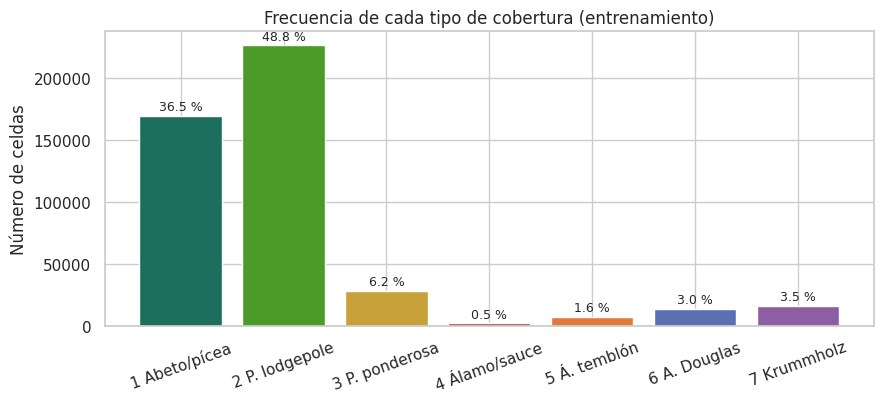

Clase,Cobertura,Celdas,Porcentaje (%),Razón respecto a la mayoritaria
1,Abeto/pícea (Spruce/Fir),169472,36.46,1.3
2,Pino lodgepole,226640,48.76,1.0
3,Pino ponderosa,28603,6.15,7.9
4,Álamo/sauce (Cottonwood/Willow),2198,0.47,103.1
5,Álamo temblón (Aspen),7594,1.63,29.8
6,Abeto de Douglas,13894,2.99,16.3
7,Krummholz,16408,3.53,13.8


In [2]:
conteo = y_train.value_counts().sort_index()
tabla = pd.DataFrame(
    {
        "Cobertura": [CLASS_NAMES[k] for k in conteo.index],
        "Celdas": conteo.values,
        "Porcentaje (%)": (100 * conteo / conteo.sum()).round(2).values,
        "Razón respecto a la mayoritaria": (conteo.max() / conteo).round(1).values,
    },
    index=conteo.index,
)
tabla.index.name = "Clase"

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar([CLASS_SHORT[k] for k in conteo.index], conteo.values, color=palette)
for bar, pct in zip(bars, tabla["Porcentaje (%)"]):
    ax.annotate(f"{pct:.1f} %", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
ax.set_title("Frecuencia de cada tipo de cobertura (entrenamiento)")
ax.set_ylabel("Número de celdas")
ax.set_xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
tabla

La distribución de la variable objetivo está **fuertemente desbalanceada**. El pino lodgepole (48,8 %) y el abeto/pícea (36,5 %) suman el 85 % de las celdas, mientras que las cinco clases restantes se reparten el 15 %. La clase minoritaria, álamo/sauce, tiene 2.198 celdas en entrenamiento (0,47 %), 103 veces menos que la mayoritaria. Aun así, el número absoluto de casos minoritarios es suficiente para estimar un modelo, a diferencia de lo que ocurre en conjuntos pequeños con desbalance similar.

**Comportamiento de la variable objetivo en el espacio.** Aunque no hay coordenadas, el área silvestre permite ver cómo cambia la composición de la cobertura entre zonas:

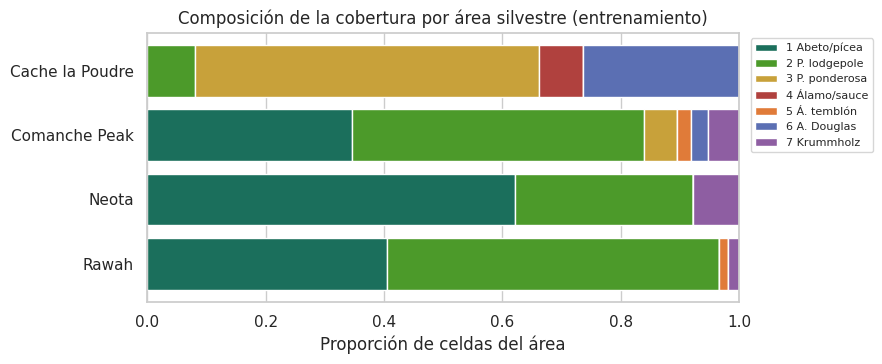

Área silvestre,1 Abeto/pícea,2 P. lodgepole,3 P. ponderosa,4 Álamo/sauce,5 Á. temblón,6 A. Douglas,7 Krummholz,Total
Rawah,84483,117006,0,0,2993,0,4039,208521
Neota,14841,7175,0,0,0,0,1854,23870
Comanche Peak,70148,100063,11378,0,4601,6082,10515,202787
Cache la Poudre,0,2396,17225,2198,0,7812,0,29631
Total,169472,226640,28603,2198,7594,13894,16408,464809


In [3]:
comp = pd.crosstab(area, y_train, normalize="index").loc[list(WILD_NAMES.values())]
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(comp))
for k in range(1, 8):
    ax.barh(comp.index, comp[k], left=left, color=CLASS_PALETTE[k], label=CLASS_SHORT[k])
    left += comp[k].values
ax.set_xlabel("Proporción de celdas del área")
ax.set_title("Composición de la cobertura por área silvestre (entrenamiento)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()
conteo_area = pd.crosstab(area.rename("Área silvestre"), y_train, margins=True,
                          margins_name="Total").loc[list(WILD_NAMES.values()) + ["Total"]]
conteo_area.columns = [CLASS_SHORT.get(c, c) for c in conteo_area.columns]
conteo_area

La composición cambia de forma drástica entre áreas. En Rawah, Neota y Comanche Peak dominan el abeto/pícea y el pino lodgepole, mientras que Cache la Poudre, el área más baja, tiene una composición completamente distinta: predominan el pino ponderosa y el abeto de Douglas, y es la **única área donde aparece el álamo/sauce**. Varias clases no existen en ciertas áreas (por ejemplo, ni el pino ponderosa ni el abeto de Douglas aparecen en Rawah o Neota).

**Implicaciones para la evaluación y la validación:**

- El *accuracy* es engañoso: un clasificador que siempre prediga pino lodgepole obtiene cerca del 49 %. Se reportarán además el **F1 macro** (promedio simple del F1 de cada clase, que da el mismo peso a las clases minoritarias), la **exactitud balanceada** (promedio de la sensibilidad por clase), las métricas por clase y las curvas precisión-*recall*.
- Todas las particiones y la validación cruzada deben ser **estratificadas** (`StratifiedKFold`), para que cada pliegue contenga las siete clases en su proporción original.
- Conviene evaluar el ajuste con **ponderación de clases** (`class_weight="balanced"`), que penaliza más los errores en las clases minoritarias.
- La fuerte dependencia entre área y clase obliga a revisar si el modelo generaliza a zonas no vistas (sección 2.7 y capítulo 3).

## 2.2 Análisis unidimensional

### Variables numéricas: estadísticos descriptivos

In [4]:
num = X_train[NUM_COLS]
desc = pd.DataFrame(
    {
        "Media": num.mean(),
        "Mediana": num.median(),
        "Desv. est.": num.std(),
        "P1": num.quantile(0.01),
        "P5": num.quantile(0.05),
        "P25": num.quantile(0.25),
        "P75": num.quantile(0.75),
        "P95": num.quantile(0.95),
        "P99": num.quantile(0.99),
        "Mínimo": num.min(),
        "Máximo": num.max(),
        "Asimetría": num.skew(),
        "Curtosis (exceso)": num.kurt(),
        "Valores distintos": num.nunique(),
    }
).round(2)
desc.index = [DISPLAY_NAMES[c] for c in desc.index]
desc

,Media,Mediana,Desv. est.,P1,P5,P25,P75,P95,P99,Mínimo,Máximo,Asimetría,Curtosis (exceso),Valores distintos
Elevación (m),2959.51,2996.0,280.03,2123.0,2405.0,2809.0,3164.0,3336.0,3439.0,1860,3858,-0.82,0.75,1962
Orientación (° azimut),155.83,127.0,111.98,1.0,12.0,58.0,261.0,344.0,356.0,0,360,0.40,-1.22,361
Pendiente (°),14.10,13.0,7.49,2.0,4.0,9.0,18.0,28.0,35.0,0,66,0.79,0.58,66
Dist. horizontal a agua (m),269.35,218.0,212.39,0.0,30.0,108.0,384.0,684.0,938.0,0,1397,1.14,1.37,545
Dist. vertical a agua (m),46.42,30.0,58.23,-42.0,-8.0,7.0,69.0,165.0,250.0,-166,601,1.79,5.27,675
Dist. a carreteras (m),2351.82,1999.0,1559.33,150.0,379.0,1106.0,3331.0,5484.0,6113.0,0,7117,0.71,-0.39,5747
Sombreado 9 a. m. (0-255),212.13,218.0,26.76,127.0,160.0,198.0,231.0,246.0,252.0,0,254,-1.18,1.87,207
Sombreado mediodía (0-255),223.32,226.0,19.77,162.0,186.0,213.0,237.0,250.0,254.0,0,254,-1.06,2.08,182
Sombreado 3 p. m. (0-255),142.55,143.0,38.27,41.0,78.0,119.0,168.0,204.0,226.0,0,254,-0.28,0.39,255
Dist. a puntos de incendio (m),1979.97,1710.0,1323.56,182.0,418.0,1024.0,2550.0,4938.0,6264.0,0,7172,1.29,1.65,5796


### Distribuciones

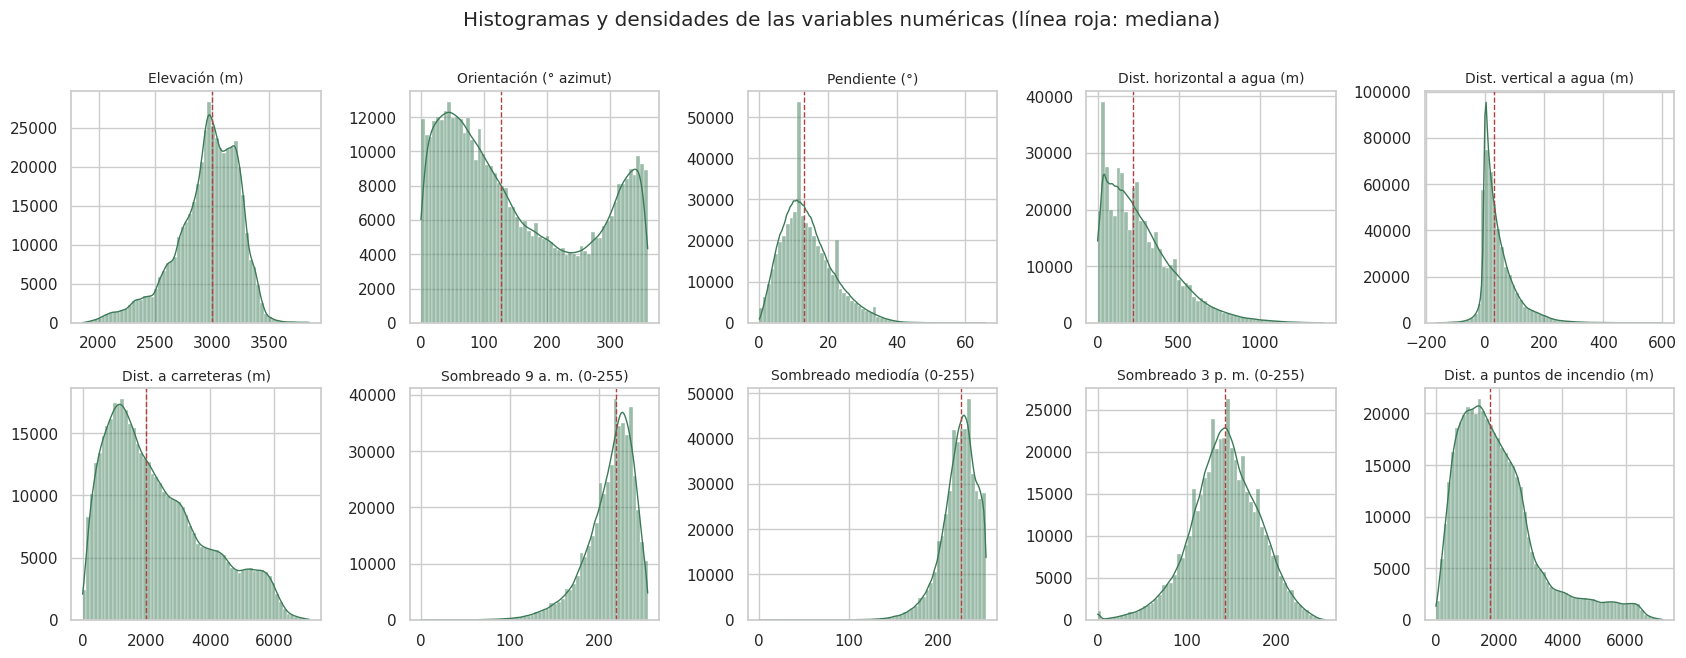

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(num[col], bins=60, ax=ax, color="#3b7a57", kde=True, line_kws={"lw": 1})
    ax.axvline(num[col].median(), color="#b0413e", ls="--", lw=1)
    ax.set_title(DISPLAY_NAMES[col], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Histogramas y densidades de las variables numéricas (línea roja: mediana)", y=1.01)
plt.tight_layout()
plt.show()

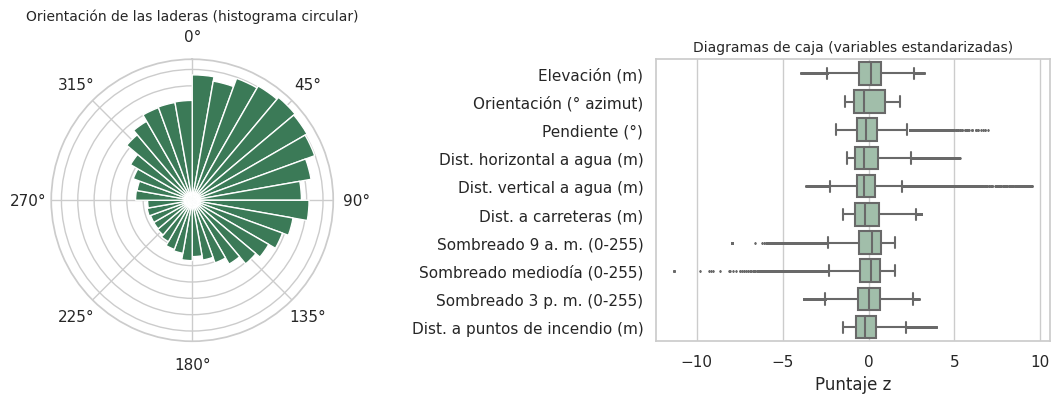

In [6]:
fig = plt.figure(figsize=(11, 4.2))
ax1 = fig.add_subplot(1, 2, 1, projection="polar")
theta = np.deg2rad(num["Aspect"])
counts, edges = np.histogram(theta, bins=36, range=(0, 2 * np.pi))
ax1.bar(edges[:-1], counts, width=2 * np.pi / 36, align="edge", color="#3b7a57", edgecolor="white")
ax1.set_theta_zero_location("N")
ax1.set_theta_direction(-1)
ax1.set_title("Orientación de las laderas (histograma circular)", fontsize=10)
ax1.set_yticklabels([])

ax2 = fig.add_subplot(1, 2, 2)
z = (num - num.mean()) / num.std()
z.columns = [DISPLAY_NAMES[c] for c in z.columns]
sns.boxplot(data=z, orient="h", ax=ax2, fliersize=1, color="#9cc3a8")
ax2.set_title("Diagramas de caja (variables estandarizadas)", fontsize=10)
ax2.set_xlabel("Puntaje z")
plt.tight_layout()
plt.show()

### Pruebas de normalidad

Se aplica la prueba de D'Agostino-Pearson sobre una submuestra aleatoria de 5.000 celdas. Con muestras de cientos de miles de observaciones cualquier prueba rechaza la normalidad ante desviaciones mínimas, por lo que el resultado se interpreta junto con la asimetría y la curtosis, y no de forma aislada.

In [7]:
muestra = num.sample(5000, random_state=RANDOM_STATE)
normalidad = pd.DataFrame(
    [(DISPLAY_NAMES[c], *stats.normaltest(muestra[c])) for c in NUM_COLS],
    columns=["Variable", "Estadístico K²", "Valor p"],
).set_index("Variable")
normalidad["¿Se rechaza normalidad (α = 0,05)?"] = np.where(normalidad["Valor p"] < 0.05, "Sí", "No")
normalidad["Estadístico K²"] = normalidad["Estadístico K²"].round(1)
normalidad["Valor p"] = normalidad["Valor p"].map(lambda p: f"{p:.2e}")
normalidad

Variable,Estadístico K²,Valor p,"¿Se rechaza normalidad (α = 0,05)?"
Elevación (m),528.4,1.78e-115,Sí
Orientación (° azimut),5713.4,0.00e+00,Sí
Pendiente (°),419.0,1.03e-91,Sí
Dist. horizontal a agua (m),899.7,4.25e-196,Sí
Dist. vertical a agua (m),1749.1,0.00e+00,Sí
Dist. a carreteras (m),383.1,6.49e-84,Sí
Sombreado 9 a. m. (0-255),1003.9,1.00e-218,Sí
Sombreado mediodía (0-255),790.9,1.83e-172,Sí
Sombreado 3 p. m. (0-255),55.5,9.03e-13,Sí
Dist. a puntos de incendio (m),1123.0,1.39e-244,Sí


**Interpretación de las variables numéricas:**

- **Elevación.** Tiene una masa principal entre 2.800 y 3.300 m, con dos picos cercanos (alrededor de 3.000 y 3.200 m), y una cola izquierda larga hacia los 1.860 m (asimetría −0,82). Esa cola corresponde a las zonas bajas de Cache la Poudre, donde se concentran las clases minoritarias.
- **Orientación.** Es una variable circular: 0° y 360° son la misma dirección. El histograma lineal parece bimodal, con picos cerca de 40° y de 340°, pero el histograma circular muestra que ambos picos forman una sola concentración de laderas orientadas al norte y al noreste. Las laderas orientadas al sur y al suroeste son las menos frecuentes. Tratarla como lineal parte artificialmente esa concentración en dos, por lo que se transforma en seno y coseno (sección 2.9).
- **Distancias horizontales** (a agua, carreteras y puntos de incendio). Tienen asimetría positiva (entre 0,7 y 1,3) y colas derechas largas; son candidatas a una transformación logarítmica.
- **Distancia vertical al agua.** Es la variable más leptocúrtica (curtosis 5,3): la mayoría de las celdas está entre 0 y 70 m por encima de la fuente de agua, pero hay valores extremos de hasta 601 m y valores negativos de hasta −166 m.
- **Índices de sombreado.** Tienen asimetría negativa (salvo el de las 3 p. m.), porque la mayoría de las laderas recibe mucha luz en verano y solo unas pocas quedan en sombra.
- **Pruebas de normalidad.** Ninguna variable es normal. Esto no es un problema para la regresión logística, que no supone normalidad de las predictoras, pero sí justifica usar pruebas no paramétricas (Kruskal-Wallis) y correlación de Spearman en el análisis bidimensional.
- **Atípicos.** Los diagramas de caja confirman lo discutido en la sección 1.8: las colas son largas pero continuas, sin valores aislados que sugieran errores de registro.

### Variables categóricas

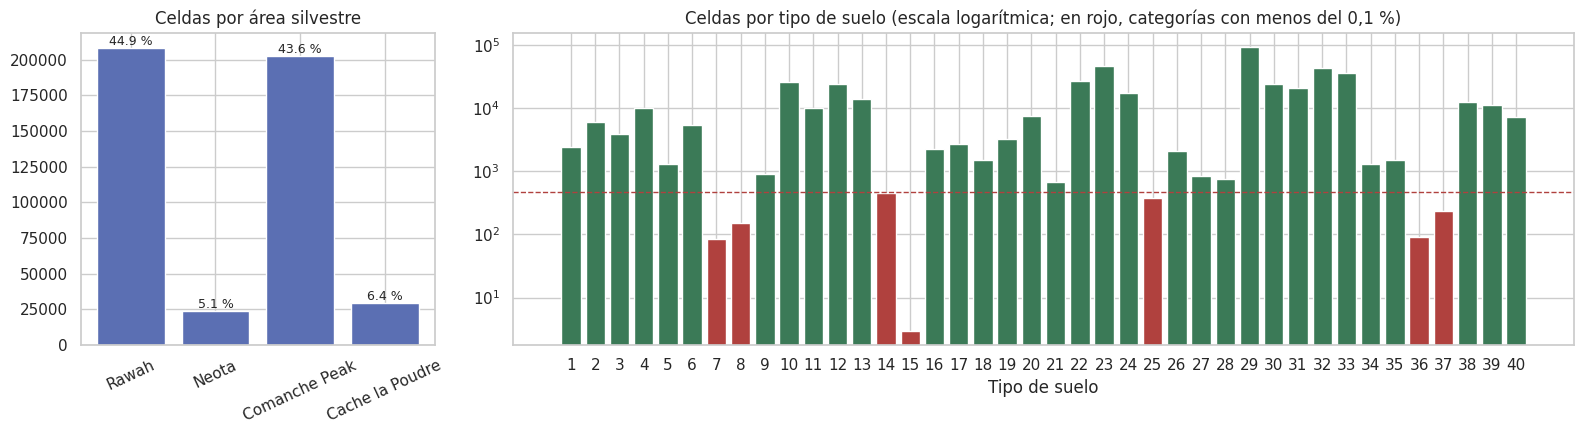

,Celdas,Porcentaje (%),Clases presentes
Soil_Type_15,3,0.001,6
Soil_Type_7,83,0.018,2
Soil_Type_36,90,0.019,"1, 2, 7"
Soil_Type_8,149,0.032,"1, 2"
Soil_Type_37,236,0.051,7
Soil_Type_25,372,0.080,"1, 2"
Soil_Type_14,457,0.098,"3, 4, 6"


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 3]})
area_counts = area.value_counts().loc[list(WILD_NAMES.values())]
axes[0].bar(area_counts.index, area_counts.values, color="#5b6fb3")
axes[0].set_title("Celdas por área silvestre")
axes[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(area_counts.values):
    axes[0].annotate(f"{100 * v / len(area):.1f} %", (i, v), ha="center", va="bottom", fontsize=9)

suelo_counts = X_train[SOIL_COLS].sum()
suelo_counts.index = [c.replace("Soil_Type_", "") for c in suelo_counts.index]
colors = ["#b0413e" if v / len(X_train) < 0.001 else "#3b7a57" for v in suelo_counts.values]
axes[1].bar(suelo_counts.index, suelo_counts.values, color=colors)
axes[1].set_yscale("log")
axes[1].axhline(0.001 * len(X_train), color="#b0413e", ls="--", lw=1)
axes[1].set_title("Celdas por tipo de suelo (escala logarítmica; en rojo, categorías con menos del 0,1 %)")
axes[1].set_xlabel("Tipo de suelo")
plt.tight_layout()
plt.show()

raras = suelo_counts[suelo_counts / len(X_train) < 0.001].sort_values()
raras_tabla = pd.DataFrame({"Celdas": raras, "Porcentaje (%)": (100 * raras / len(X_train)).round(3)})
raras_tabla["Clases presentes"] = [
    ", ".join(str(k) for k in sorted(y_train[X_train[f"Soil_Type_{s}"] == 1].unique())) for s in raras.index
]
raras_tabla.index = [f"Soil_Type_{s}" for s in raras_tabla.index]
raras_tabla

- **Área silvestre (4 niveles).** Rawah y Comanche Peak concentran cerca del 88 % de las celdas; Neota (5,1 %) y Cache la Poudre (6,4 %) están mucho menos representadas.
- **Tipo de suelo (40 niveles).** La distribución es muy concentrada: el suelo 29 (familia Como–Legault) aparece en casi el 20 % de las celdas, mientras que siete tipos de suelo tienen menos del 0,1 % de las celdas. El caso extremo es el suelo 15, con solo 3 celdas en entrenamiento (y 3 en todo el conjunto).
- **Tratamiento de categorías raras.** Se conservan como indicadoras independientes. Agruparlas en una categoría "otros" mezclaría suelos de composición muy distinta (los suelos raros aparecen en clases diferentes, como muestra la tabla), y la regularización L2 de la regresión logística ya encoge hacia cero los coeficientes estimados con pocos datos. Los modelos basados en árboles de la Parte II tampoco requieren agruparlos, porque solo usan una indicadora cuando una partición basada en ella reduce la impureza.

## 2.3 Análisis bidimensional

### Numéricas contra numéricas

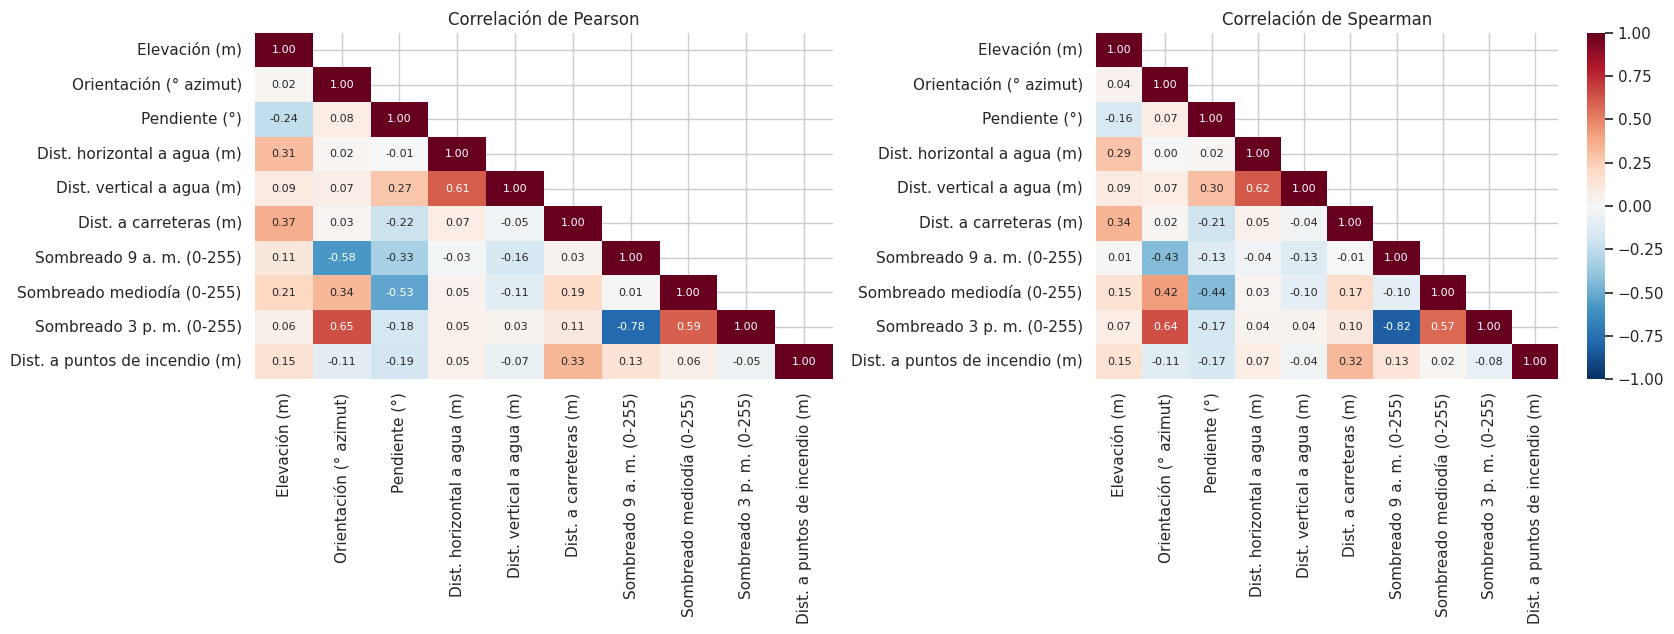

In [9]:
etiquetas = [DISPLAY_NAMES[c] for c in NUM_COLS]
pearson = num.corr(method="pearson")
spearman = num.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
for ax, mat, titulo in [(axes[0], pearson, "Pearson"), (axes[1], spearman, "Spearman")]:
    sns.heatmap(mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
                xticklabels=etiquetas, yticklabels=etiquetas, cbar=ax is axes[1], annot_kws={"size": 8})
    ax.set_title(f"Correlación de {titulo}")
plt.tight_layout()
plt.show()

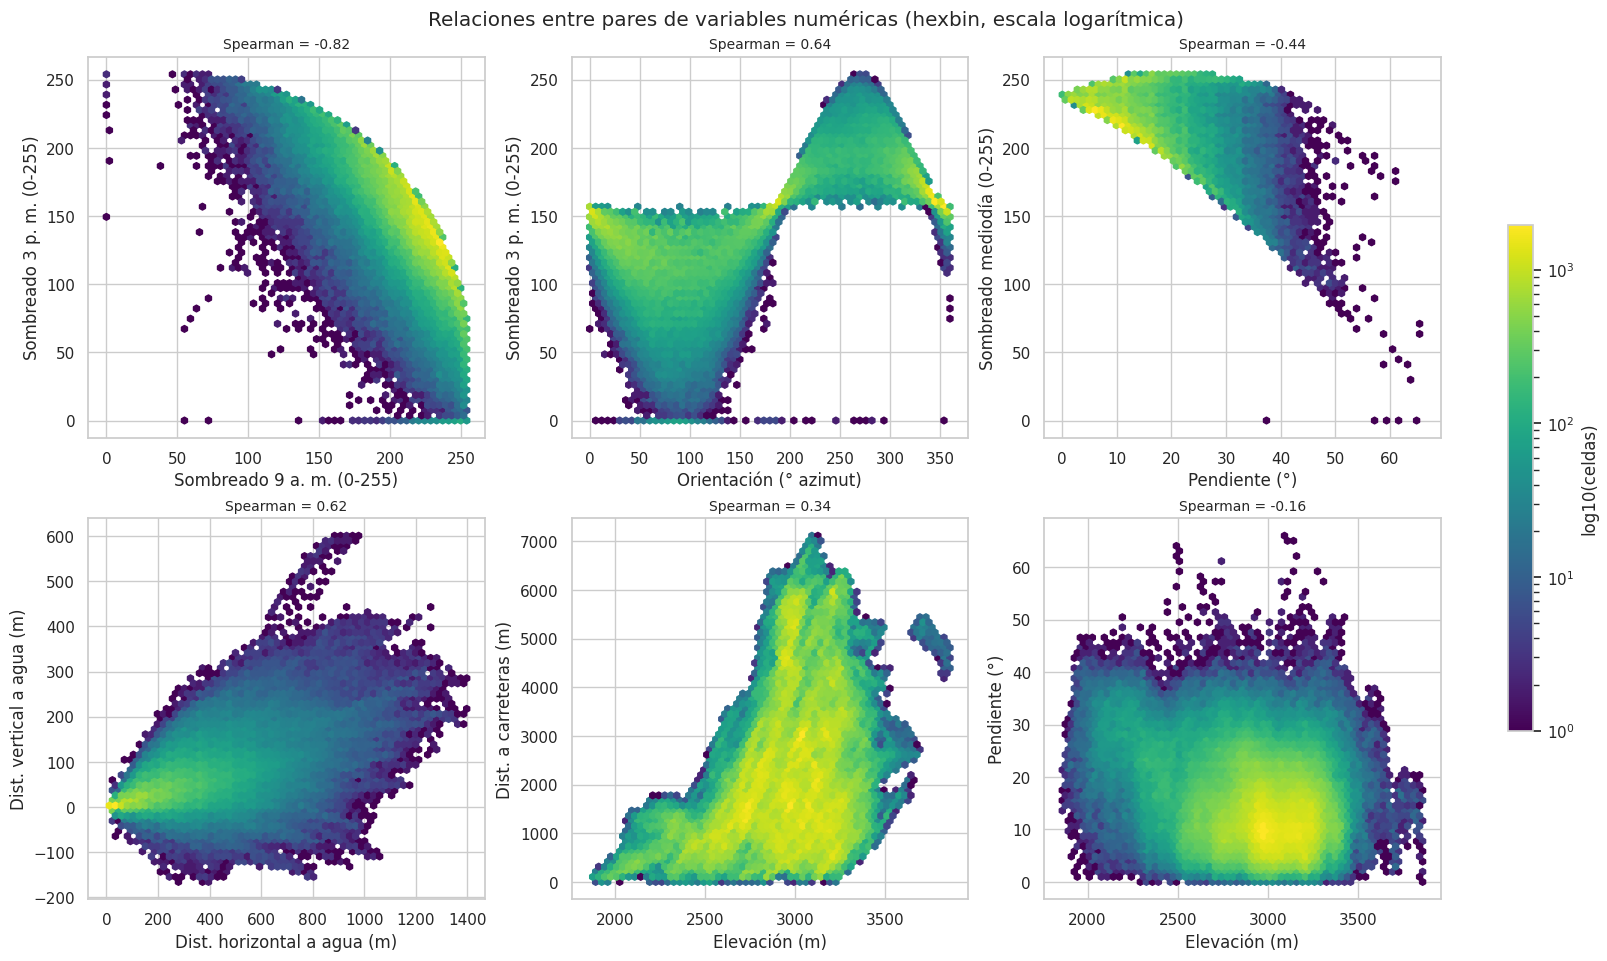

In [10]:
pares = [
    ("Hillshade_9am", "Hillshade_3pm"),
    ("Aspect", "Hillshade_3pm"),
    ("Slope", "Hillshade_Noon"),
    ("Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology"),
    ("Elevation", "Horizontal_Distance_To_Roadways"),
    ("Elevation", "Slope"),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), constrained_layout=True)
for ax, (a, b) in zip(axes.ravel(), pares):
    hb = ax.hexbin(num[a], num[b], gridsize=60, bins="log", cmap="viridis", mincnt=1)
    ax.set_xlabel(DISPLAY_NAMES[a])
    ax.set_ylabel(DISPLAY_NAMES[b])
    ax.set_title(f"Spearman = {spearman.loc[a, b]:.2f}", fontsize=10)
fig.colorbar(hb, ax=axes, shrink=0.6, label="log10(celdas)")
fig.suptitle("Relaciones entre pares de variables numéricas (hexbin, escala logarítmica)")
plt.show()

**Interpretación:**

- **Sombreado, orientación y pendiente forman un bloque redundante.** El sombreado es una función determinística de la orientación, la pendiente y la posición del sol. Por eso el sombreado de las 9 a. m. y el de las 3 p. m. tienen correlación −0,78 (Pearson) y una relación curva muy nítida en el hexbin: una ladera iluminada en la mañana está en sombra en la tarde y viceversa. La orientación se relaciona con el sombreado de la tarde (0,65), y la pendiente con el del mediodía (−0,53).
- **Distancia horizontal y vertical al agua** están moderadamente correlacionadas (0,61): cuanto más lejos está el agua, mayor suele ser el desnivel. Esto motiva construir la distancia euclidiana al agua como variable adicional.
- **La elevación es casi independiente del resto** (correlaciones menores a 0,40), lo que anticipa que su información no es redundante.
- **Relaciones no lineales.** Pearson y Spearman difieren en varios pares (por ejemplo, orientación y sombreado de las 9 a. m.: −0,58 frente a −0,43), lo que indica relaciones monótonas no lineales o no monótonas, como la forma de arco del par orientación–sombreado.

### Multicolinealidad

In [11]:
vif = {}
for col in NUM_COLS:
    otras = [c for c in NUM_COLS if c != col]
    r2 = LinearRegression().fit(num[otras], num[col]).score(num[otras], num[col])
    vif[DISPLAY_NAMES[col]] = 1 / (1 - r2)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False).round(2).to_frame()
vif["Diagnóstico"] = np.select([vif["VIF"] > 10, vif["VIF"] > 5], ["Alta", "Moderada"], "Baja")
vif

,VIF,Diagnóstico
Sombreado 3 p. m. (0-255),144.34,Alta
Sombreado 9 a. m. (0-255),104.82,Alta
Sombreado mediodía (0-255),38.15,Alta
Pendiente (°),6.84,Moderada
Orientación (° azimut),1.86,Baja
Dist. vertical a agua (m),1.83,Baja
Dist. horizontal a agua (m),1.81,Baja
Elevación (m),1.34,Baja
Dist. a carreteras (m),1.30,Baja
Dist. a puntos de incendio (m),1.16,Baja


El factor de inflación de la varianza (VIF) (OBrien, 2007) confirma la redundancia del bloque de iluminación: los tres índices de sombreado tienen VIF entre 38 y 144, y la pendiente tiene un VIF moderado (6,8). Sin embargo, el sombreado no es una combinación *lineal* exacta de orientación y pendiente, sino una función trigonométrica, así que cada índice conserva algo de información propia.

**Decisión:** para el modelo base se conservan los tres índices, porque la regularización L2 estabiliza los coeficientes ante la colinealidad. La consecuencia práctica es que **los coeficientes individuales del bloque de iluminación no deben interpretarse de forma aislada** (capítulo 3). Los modelos basados en árboles de la Parte II se ajustan con el mismo conjunto de variables, porque la colinealidad no afecta su capacidad predictiva, aunque sí reparte la importancia entre las variables redundantes (capítulo 8).

### Categóricas contra numéricas

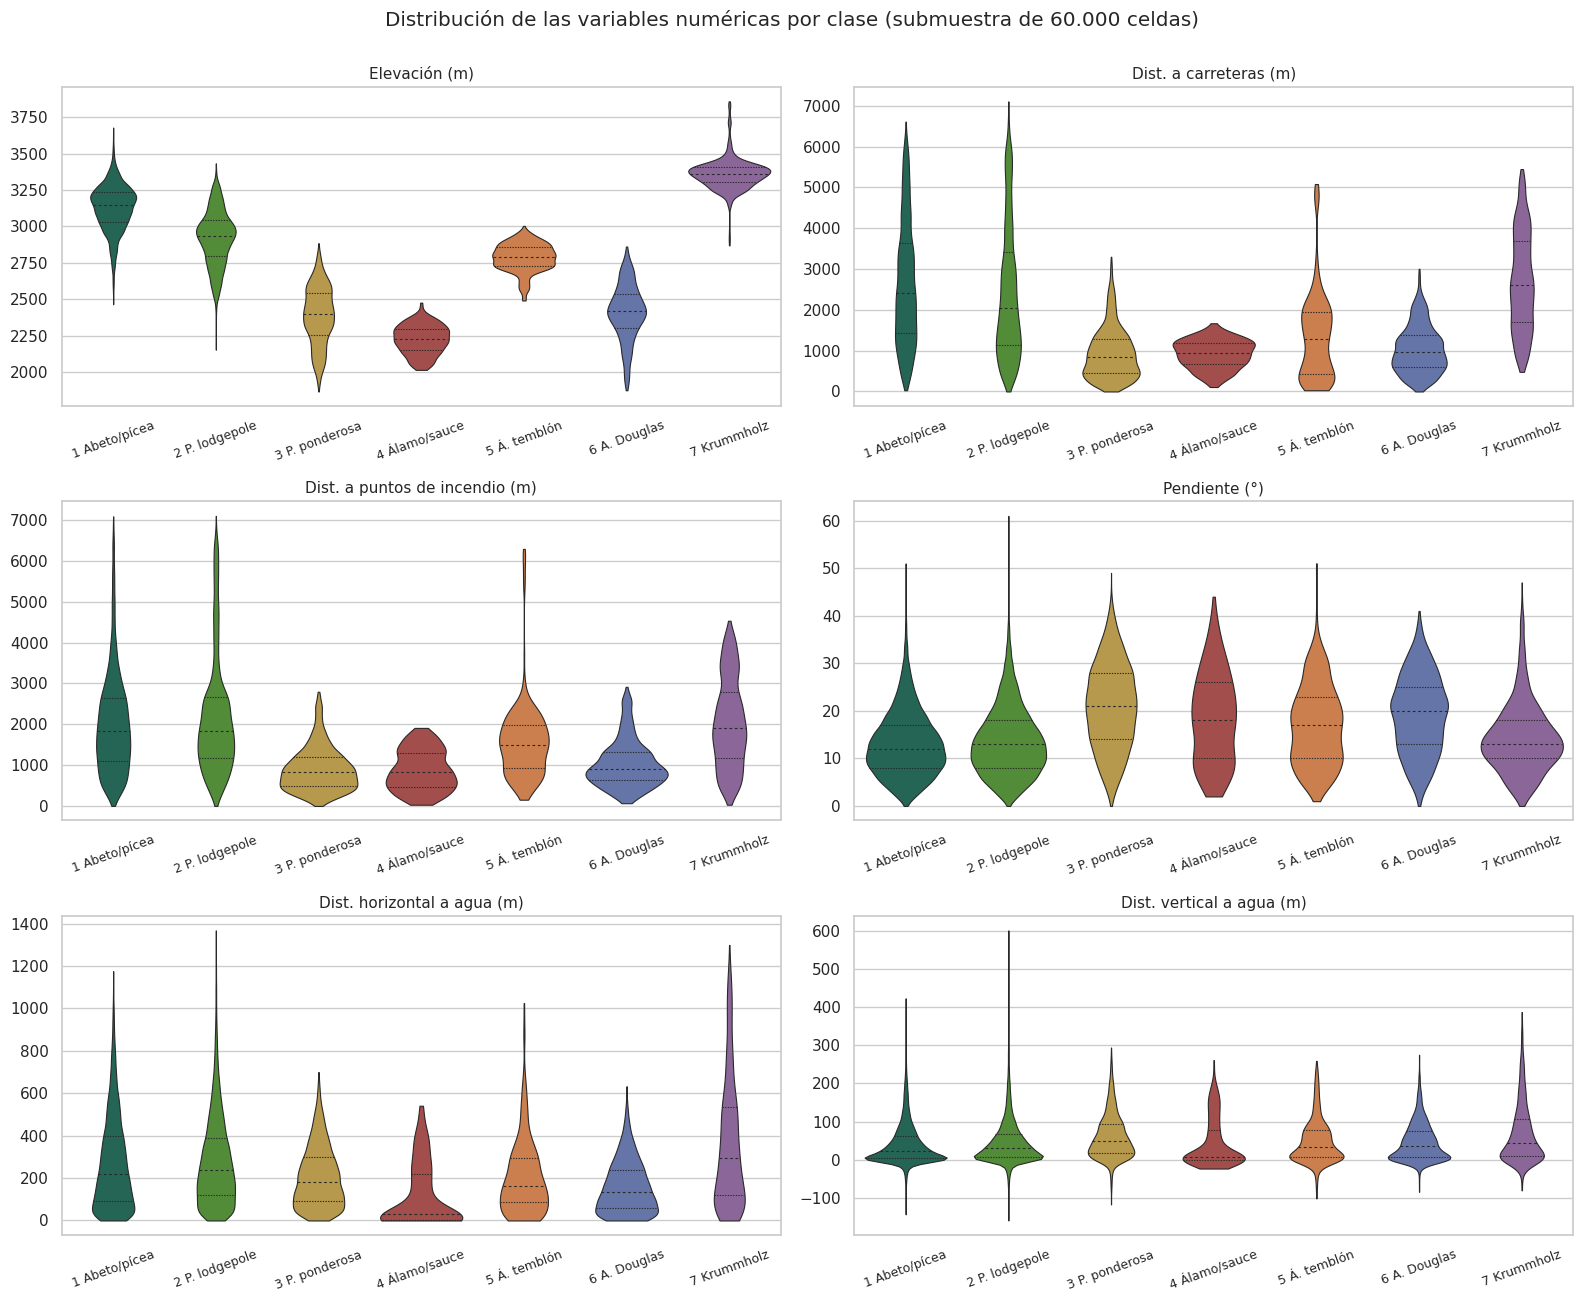

In [12]:
vars_violin = [
    "Elevation", "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points",
    "Slope", "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
]
plot_df = train.sample(60000, random_state=RANDOM_STATE)
plot_df["Clase"] = plot_df["Cover_Type"].map(CLASS_SHORT)
orden = [CLASS_SHORT[k] for k in range(1, 8)]
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
for ax, col in zip(axes.ravel(), vars_violin):
    sns.violinplot(data=plot_df, x="Clase", y=col, order=orden, palette=palette, ax=ax,
                   cut=0, linewidth=0.8, inner="quartile")
    ax.set_title(DISPLAY_NAMES[col], fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=20, labelsize=9)
fig.suptitle("Distribución de las variables numéricas por clase (submuestra de 60.000 celdas)", y=1.0)
plt.tight_layout()
plt.show()

Para cuantificar las diferencias entre clases se usa la prueba de **Kruskal-Wallis** (Kruskal y Wallis, 1952), alternativa no paramétrica al ANOVA de una vía, justificada por la ausencia de normalidad. Con $n$ cercano a 465.000 cualquier diferencia resulta significativa, así que la prueba se acompaña del **tamaño del efecto** $\varepsilon^2 = H / \frac{n^2 - 1}{n + 1}$, que se interpreta con los umbrales habituales: 0,01 pequeño, 0,08 moderado y 0,26 grande (Tomczak y Tomczak, 2014). Los valores p se corrigen por comparaciones múltiples con el método de Holm.

In [13]:
def holm(pvals):
    """Corrección de Holm-Bonferroni para una serie de valores p."""
    p = np.asarray(pvals, dtype=float)
    orden = np.argsort(p)
    m = len(p)
    ajust = np.empty(m)
    acumulado = 0.0
    for rank, idx in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (m - rank) * p[idx]))
        ajust[idx] = acumulado
    return ajust

n = len(X_train)
filas = []
for col in NUM_COLS:
    H, p = stats.kruskal(*[num.loc[y_train == k, col] for k in range(1, 8)])
    filas.append((DISPLAY_NAMES[col], H, p, H / ((n ** 2 - 1) / (n + 1))))
kw = pd.DataFrame(filas, columns=["Variable", "H de Kruskal-Wallis", "p", "ε²"]).set_index("Variable")
kw["p ajustado (Holm)"] = holm(kw["p"])
kw["Efecto"] = pd.cut(kw["ε²"], [-np.inf, 0.01, 0.08, 0.26, np.inf], labels=["Despreciable", "Pequeño", "Moderado", "Grande"])
kw = kw.sort_values("ε²", ascending=False)
kw["H de Kruskal-Wallis"] = kw["H de Kruskal-Wallis"].round(0)
kw["ε²"] = kw["ε²"].round(3)
kw[["p", "p ajustado (Holm)"]] = kw[["p", "p ajustado (Holm)"]].applymap(lambda v: f"{v:.1e}")
kw

Variable,H de Kruskal-Wallis,p,ε²,p ajustado (Holm),Efecto
Elevación (m),237619.0,0.0e+00,0.511,0.0e+00,Grande
Dist. a carreteras (m),56907.0,0.0e+00,0.122,0.0e+00,Moderado
Dist. a puntos de incendio (m),44640.0,0.0e+00,0.096,0.0e+00,Moderado
Pendiente (°),26247.0,0.0e+00,0.056,0.0e+00,Pequeño
Sombreado 9 a. m. (0-255),9643.0,0.0e+00,0.021,0.0e+00,Pequeño
Dist. horizontal a agua (m),9596.0,0.0e+00,0.021,0.0e+00,Pequeño
Sombreado mediodía (0-255),8657.0,0.0e+00,0.019,0.0e+00,Pequeño
Dist. vertical a agua (m),6504.0,0.0e+00,0.014,0.0e+00,Pequeño
Sombreado 3 p. m. (0-255),3077.0,0.0e+00,0.007,0.0e+00,Despreciable
Orientación (° azimut),1624.0,0.0e+00,0.003,0.0e+00,Despreciable


Todas las diferencias son estadísticamente significativas después de la corrección de Holm, pero solo algunas son relevantes en magnitud:

- **La elevación tiene un efecto grande** (ε² ≈ 0,51): por sí sola explica cerca de la mitad de la variabilidad de rangos entre clases. Los violines muestran un gradiente altitudinal claro, desde el álamo/sauce (mediana ≈ 2.230 m) y el pino ponderosa (≈ 2.400 m) hasta el abeto/pícea (≈ 3.150 m) y el *krummholz* (≈ 3.360 m), que es la vegetación achaparrada del límite superior del bosque. Este gradiente es coherente con la zonación altitudinal descrita para los bosques del Front Range de Colorado (Peet, 1981).
- **Las distancias a carreteras y a puntos de incendio tienen efectos moderados** (ε² ≈ 0,12 y 0,10). Las clases de zonas bajas (3, 4 y 6) están más cerca de ambas, en buena medida porque las carreteras y los incendios históricos se concentran en los valles.
- **La pendiente y las distancias al agua tienen efectos pequeños**, y **la orientación y el sombreado, despreciables** en la comparación global, aunque pueden aportar en combinación con otras variables.
- Se observa **solapamiento importante entre el abeto/pícea y el pino lodgepole** en todas las variables, lo que anticipa que la confusión entre las dos clases mayoritarias será la principal fuente de error del modelo.

### Categóricas contra categóricas

In [14]:
def cramer_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2, p, dof, _ = stats.chi2_contingency(tabla)
    m = tabla.values.sum()
    r, k = tabla.shape
    return chi2, dof, p, np.sqrt(chi2 / (m * (min(r, k) - 1)))

asociaciones = pd.DataFrame(
    [
        ("Área silvestre × Cobertura", *cramer_v(area, y_train)),
        ("Tipo de suelo × Cobertura", *cramer_v(suelo, y_train)),
        ("Área silvestre × Tipo de suelo", *cramer_v(area, suelo)),
    ],
    columns=["Par de variables", "χ²", "gl", "p", "V de Cramér"],
).set_index("Par de variables")
asociaciones["χ²"] = asociaciones["χ²"].round(0)
asociaciones["V de Cramér"] = asociaciones["V de Cramér"].round(3)
asociaciones["p"] = asociaciones["p"].map(lambda v: f"{v:.1e}")
asociaciones

Par de variables,χ²,gl,p,V de Cramér
Área silvestre × Cobertura,274996.0,18,0.0e+00,0.444
Tipo de suelo × Cobertura,610751.0,234,0.0e+00,0.468
Área silvestre × Tipo de suelo,655756.0,117,0.0e+00,0.686


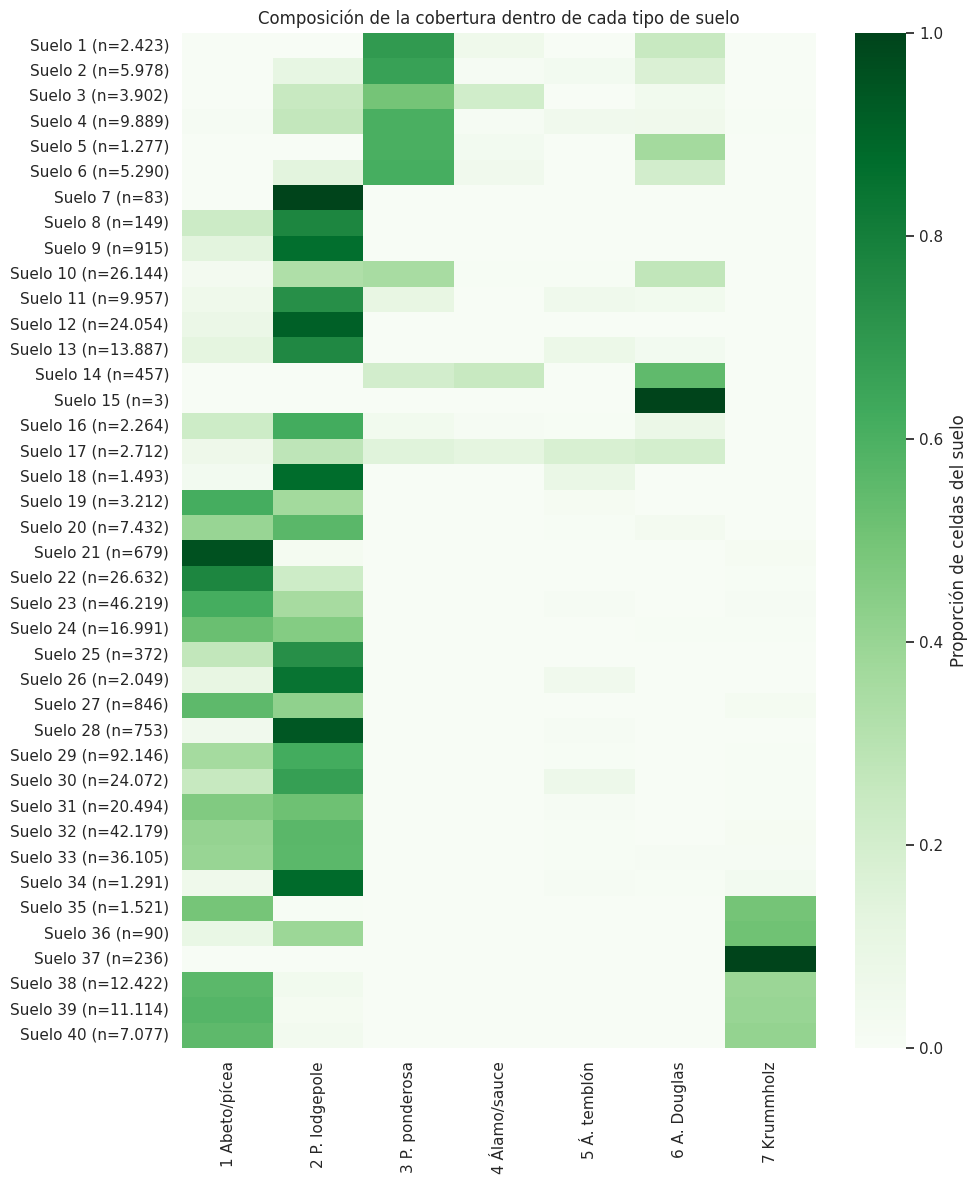

In [15]:
prop_suelo = pd.crosstab(suelo, y_train, normalize="index")
prop_suelo.columns = [CLASS_SHORT[k] for k in prop_suelo.columns]
prop_suelo.index = [f"Suelo {s} (n={int(c):,})".replace(",", ".") for s, c in suelo.value_counts().sort_index().items()]
fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(prop_suelo, cmap="Greens", ax=ax, cbar_kws={"label": "Proporción de celdas del suelo"})
ax.set_title("Composición de la cobertura dentro de cada tipo de suelo")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

- Las asociaciones del **área silvestre** (V ≈ 0,44) y del **tipo de suelo** (V ≈ 0,47) con la cobertura son fuertes, y en ambos casos la prueba χ² es significativa con valores p prácticamente nulos.
- El mapa de calor muestra que **muchos suelos son casi exclusivos de una o dos clases**. Los suelos 35 a 40 (complejos Cryumbrepts, Leighcan–Moran y Moran, de alta montaña) se asocian con el *krummholz* y el abeto/pícea; los suelos 1 a 6 (familias Cathedral, Vanet y Ratake, de zonas bajas y rocosas) se asocian sobre todo con el pino ponderosa y, en menor medida, con el abeto de Douglas y el álamo/sauce; y los suelos 7, 12, 18, 26, 28 y 34 están dominados por el pino lodgepole. El abeto/pícea y el pino lodgepole comparten, en cambio, la mayoría de los suelos más frecuentes (22 a 33).
- **El área silvestre y el tipo de suelo están fuertemente asociados entre sí** (V ≈ 0,69): cada área tiene su propio conjunto de suelos. Ambas variables comparten, por tanto, una parte importante de su información, lo que refuerza la idea de que el área actúa como un indicador geográfico general.

### Predictoras contra variable objetivo: información mutua

La información mutua mide la dependencia, lineal o no lineal, entre cada predictora y la clase. Se estima con el método de vecinos más cercanos (Kraskov et al., 2004; Ross, 2014) sobre una submuestra estratificada de 60.000 celdas, tratando las indicadoras como variables discretas.

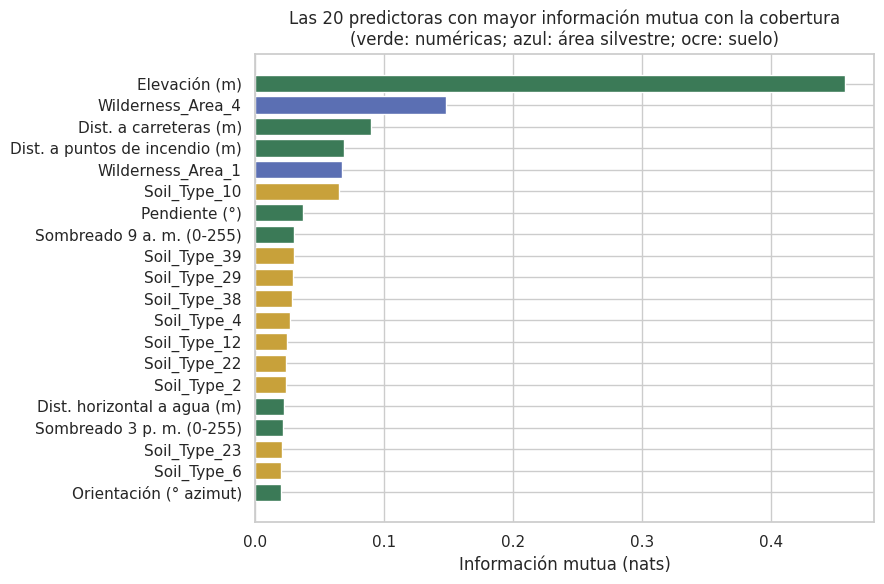

Predictoras con información mutua menor a 0,001 nats: 9 de 54


,Información mutua (nats)
Elevación (m),0.4572
Wilderness_Area_4,0.1478
Dist. a carreteras (m),0.0897
Dist. a puntos de incendio (m),0.0687
Wilderness_Area_1,0.0672
Soil_Type_10,0.0652
Pendiente (°),0.0371
Sombreado 9 a. m. (0-255),0.0302
Soil_Type_39,0.0301
Soil_Type_29,0.0293


In [16]:
Xs, ys = stratified_sample(X_train, y_train, 60000)
mi = mutual_info_classif(
    Xs, ys, discrete_features=[c in BIN_COLS for c in FEATURES], random_state=RANDOM_STATE
)
mi = pd.Series(mi, index=FEATURES).sort_values(ascending=False)
top = mi.head(20)
fig, ax = plt.subplots(figsize=(9, 6))
colores = ["#3b7a57" if c in NUM_COLS else ("#5b6fb3" if c in WILD_COLS else "#c8a13a") for c in top.index]
ax.barh([DISPLAY_NAMES.get(c, c) for c in top.index][::-1], top.values[::-1], color=colores[::-1])
ax.set_xlabel("Información mutua (nats)")
ax.set_title("Las 20 predictoras con mayor información mutua con la cobertura\n(verde: numéricas; azul: área silvestre; ocre: suelo)")
plt.tight_layout()
plt.show()
print(f"Predictoras con información mutua menor a 0,001 nats: {(mi < 0.001).sum()} de {len(mi)}")
mi.head(10).rename(index=DISPLAY_NAMES).round(4).rename("Información mutua (nats)").to_frame()

La elevación es, por amplio margen, la predictora más informativa (0,46 nats), el triple que la siguiente: el indicador del área Cache la Poudre (`Wilderness_Area_4`, 0,15 nats). Siguen la distancia a carreteras, la distancia a puntos de incendio, el área Rawah (`Wilderness_Area_1`) y el suelo 10. Este orden es coherente con los tamaños de efecto de Kruskal-Wallis y con la V de Cramér (Cramer, 1946), lo que da solidez a la conclusión. Nueve predictoras tienen información mutua menor a 0,001 nats; se trata sobre todo de indicadoras de suelos raros, que afectan a muy pocas celdas.

**Selección preliminar de variables.** No se elimina ninguna predictora en esta etapa:

- Las variables con poca asociación marginal (orientación, sombreado, suelos raros) pueden aportar en combinación con otras, y la regresión logística con regularización tolera bien predictoras poco informativas.
- La información más relevante para el modelo base está en la elevación, las distancias a carreteras y a puntos de incendio, el área silvestre y el tipo de suelo.
- La redundancia del bloque de iluminación se documenta, pero se maneja mediante regularización y no mediante eliminación.

## 2.4 Análisis multivariado

### Reducción de dimensionalidad: PCA

El análisis de componentes principales (Jolliffe y Cadima, 2016) se aplica a las diez variables numéricas estandarizadas. Las indicadoras binarias se excluyen porque el PCA sobre variables 0/1 dispersas refleja sobre todo su frecuencia y no su estructura.

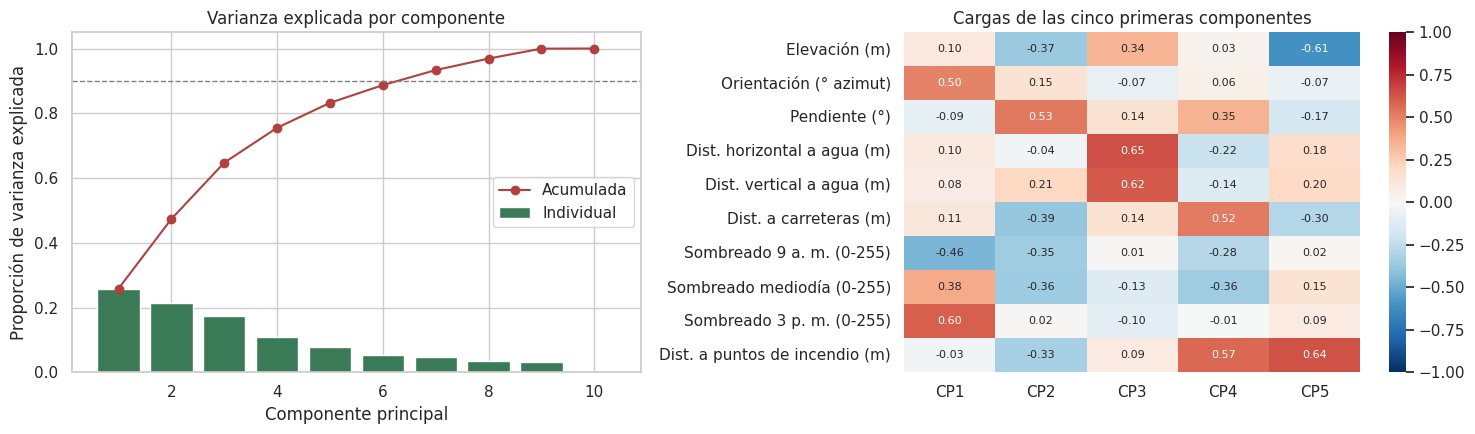

Varianza acumulada: CP1: 25.9% | CP2: 47.4% | CP3: 64.7% | CP4: 75.5% | CP5: 83.2% | CP6: 88.7% | CP7: 93.3% | CP8: 96.9% | CP9: 100.0% | CP10: 100.0%
Componentes necesarias para explicar el 90 % de la varianza: 7


In [17]:
Z = StandardScaler().fit_transform(num)
pca = PCA(random_state=RANDOM_STATE).fit(Z)
var = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(range(1, 11), var, color="#3b7a57", label="Individual")
axes[0].plot(range(1, 11), np.cumsum(var), "o-", color="#b0413e", label="Acumulada")
axes[0].axhline(0.9, ls="--", color="grey", lw=1)
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Proporción de varianza explicada")
axes[0].set_title("Varianza explicada por componente")
axes[0].legend()
cargas = pd.DataFrame(pca.components_[:5].T, index=[DISPLAY_NAMES[c] for c in NUM_COLS],
                      columns=[f"CP{i}" for i in range(1, 6)])
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], annot_kws={"size": 8})
axes[1].set_title("Cargas de las cinco primeras componentes")
plt.tight_layout()
plt.show()
print("Varianza acumulada:", " | ".join(f"CP{i + 1}: {v:.1%}" for i, v in enumerate(np.cumsum(var))))
print(f"Componentes necesarias para explicar el 90 % de la varianza: {int(np.argmax(np.cumsum(var) >= 0.9)) + 1}")

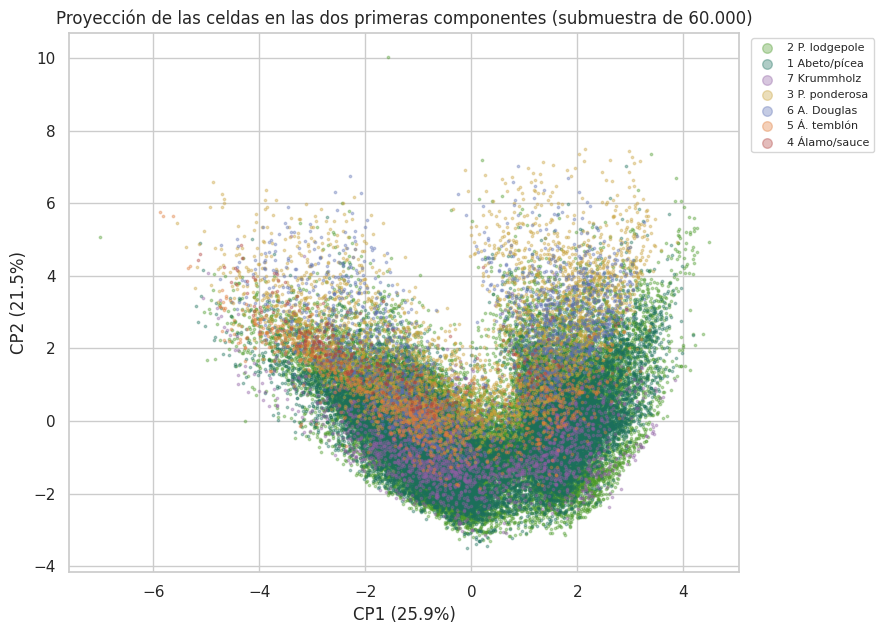

In [18]:
idx = plot_df.index
proy = pca.transform(StandardScaler().fit(num).transform(num.loc[idx]))[:, :2]
fig, ax = plt.subplots(figsize=(9, 6.5))
for k in [2, 1, 7, 3, 6, 5, 4]:
    sel = plot_df["Cover_Type"].values == k
    ax.scatter(proy[sel, 0], proy[sel, 1], s=3, alpha=0.35, color=CLASS_PALETTE[k], label=CLASS_SHORT[k])
ax.set_xlabel(f"CP1 ({var[0]:.1%})")
ax.set_ylabel(f"CP2 ({var[1]:.1%})")
ax.set_title("Proyección de las celdas en las dos primeras componentes (submuestra de 60.000)")
ax.legend(markerscale=4, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Visualización no lineal: t-SNE

El t-SNE (van der Maaten y Hinton, 2008) se usa solo como herramienta visual, no inferencial: las distancias entre grupos y el tamaño de los grupos en el mapa no tienen interpretación cuantitativa. Se aplica sobre 6.000 celdas estratificadas, con las variables numéricas estandarizadas y las indicadoras de área y suelo.

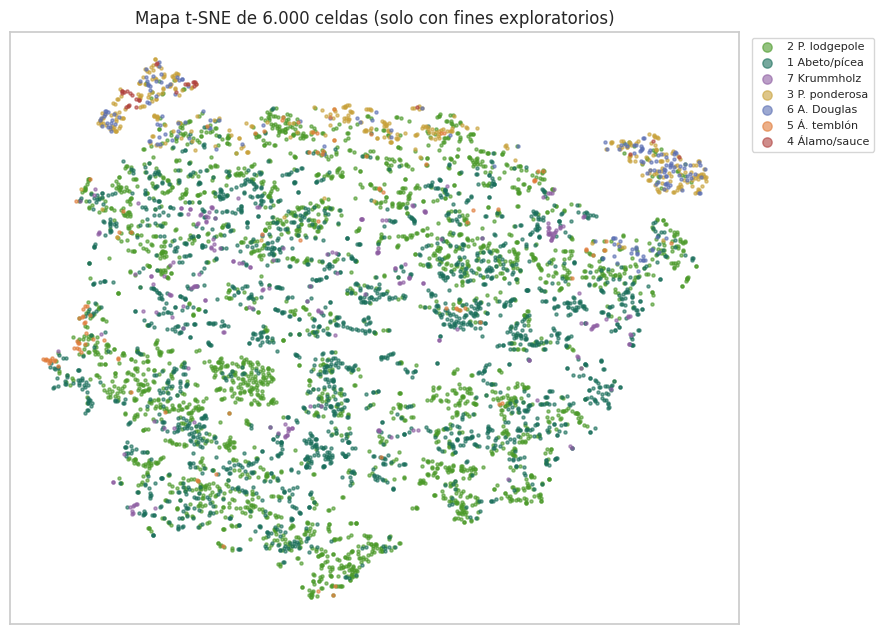

In [19]:
Xt, yt = stratified_sample(X_train, y_train, 6000)
Zt = np.hstack([StandardScaler().fit_transform(Xt[NUM_COLS]), Xt[BIN_COLS].to_numpy()])
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=RANDOM_STATE).fit_transform(Zt)
fig, ax = plt.subplots(figsize=(9, 6.5))
for k in [2, 1, 7, 3, 6, 5, 4]:
    sel = yt.values == k
    ax.scatter(emb[sel, 0], emb[sel, 1], s=5, alpha=0.6, color=CLASS_PALETTE[k], label=CLASS_SHORT[k])
ax.set_title("Mapa t-SNE de 6.000 celdas (solo con fines exploratorios)")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Valores atípicos multivariados

Se usan dos criterios complementarios sobre las variables numéricas del entrenamiento:

- **Distancia de Mahalanobis** (Mahalanobis, 1936), que supone una estructura elíptica de los datos. Se marca como atípica una celda cuya distancia al cuadrado supera el cuantil 0,999 de una distribución χ² con 10 grados de libertad.
- **Isolation Forest** (Liu et al., 2008), que no supone ninguna forma de la distribución y aísla las observaciones fáciles de separar con particiones aleatorias. Se fija una contaminación del 1 %.

In [20]:
centro = num.mean().to_numpy()
inv_cov = np.linalg.inv(np.cov(num.to_numpy(), rowvar=False))
dif = num.to_numpy() - centro
d2 = np.einsum("ij,jk,ik->i", dif, inv_cov, dif)
umbral = stats.chi2.ppf(0.999, df=len(NUM_COLS))
out_maha = d2 > umbral

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
out_iso = iso.fit_predict(num) == -1

resumen_out = pd.DataFrame(
    {
        "Mahalanobis": [out_maha.sum(), 100 * out_maha.mean()],
        "Isolation Forest": [out_iso.sum(), 100 * out_iso.mean()],
        "Ambos métodos": [(out_maha & out_iso).sum(), 100 * (out_maha & out_iso).mean()],
    },
    index=["Celdas atípicas", "Porcentaje (%)"],
).round(2)
display(resumen_out)

dist_clase = pd.DataFrame(
    {
        "Todas las celdas (%)": 100 * y_train.value_counts(normalize=True).sort_index(),
        "Atípicas Mahalanobis (%)": 100 * y_train[out_maha].value_counts(normalize=True).reindex(range(1, 8), fill_value=0),
        "Atípicas Isolation Forest (%)": 100 * y_train[out_iso].value_counts(normalize=True).reindex(range(1, 8), fill_value=0),
    }
).round(2)
dist_clase.index = [CLASS_SHORT[k] for k in dist_clase.index]
dist_clase

,Mahalanobis,Isolation Forest,Ambos métodos
Celdas atípicas,8827.0,4649.0,3665.00
Porcentaje (%),1.9,1.0,0.79


,Todas las celdas (%),Atípicas Mahalanobis (%),Atípicas Isolation Forest (%)
1 Abeto/pícea,36.46,25.67,18.26
2 P. lodgepole,48.76,38.48,23.04
3 P. ponderosa,6.15,20.73,34.27
4 Álamo/sauce,0.47,1.05,1.57
5 Á. temblón,1.63,1.18,0.80
6 A. Douglas,2.99,3.07,7.12
7 Krummholz,3.53,9.81,14.95


La distancia de Mahalanobis marca el 1,9 % de las celdas y el Isolation Forest el 1,0 %; 3.665 celdas (0,8 %) son atípicas según ambos criterios, lo que indica un acuerdo alto entre métodos con supuestos muy distintos. El hallazgo más relevante es que **las celdas atípicas no se distribuyen como el resto**: están sobrerrepresentadas las clases de los dos extremos del gradiente altitudinal. El pino ponderosa pasa del 6 % de las celdas al 21 % (Mahalanobis) o al 34 % (Isolation Forest) de los atípicos; el *krummholz*, del 3,5 % al 10 % o al 15 %, y el álamo/sauce y el abeto de Douglas también aumentan su participación. Es decir, muchos "atípicos" son en realidad ejemplos de las clases minoritarias, que ocupan regiones periféricas del espacio de variables. Esto refuerza la decisión de **no eliminar atípicos**, porque hacerlo reduciría todavía más los ejemplos de las clases más difíciles.

### Estructura de grupos: *clustering* exploratorio

Se aplica *k-means* sobre las variables numéricas estandarizadas de una submuestra de 30.000 celdas, para valores de $k$ entre 2 y 10. Se evalúa la cohesión con el coeficiente de silueta y la correspondencia con las clases reales con el índice de Rand ajustado (ARI).

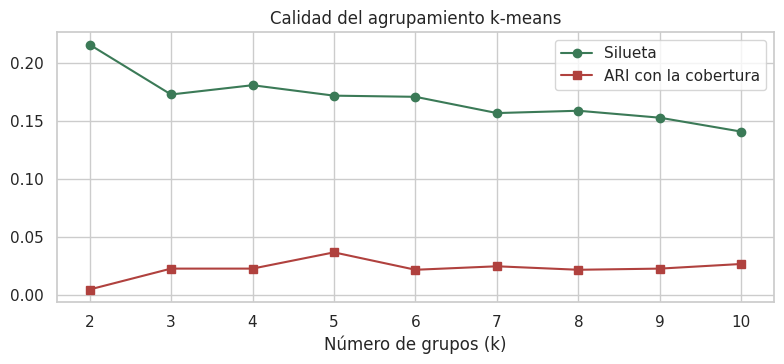

k,2,3,4,5,6,7,8,9,10
Silueta,0.216,0.173,0.181,0.172,0.171,0.157,0.159,0.153,0.141
ARI con la cobertura,0.005,0.023,0.023,0.037,0.022,0.025,0.022,0.023,0.027


In [21]:
Xk, yk = stratified_sample(X_train, y_train, 30000)
Zk = StandardScaler().fit_transform(Xk[NUM_COLS])
res = []
modelos_k = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zk)
    modelos_k[k] = km
    res.append((k, silhouette_score(Zk, km.labels_, sample_size=10000, random_state=RANDOM_STATE),
                adjusted_rand_score(yk, km.labels_)))
res = pd.DataFrame(res, columns=["k", "Silueta", "ARI con la cobertura"]).set_index("k").round(3)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(res.index, res["Silueta"], "o-", label="Silueta", color="#3b7a57")
ax.plot(res.index, res["ARI con la cobertura"], "s-", label="ARI con la cobertura", color="#b0413e")
ax.set_xlabel("Número de grupos (k)")
ax.set_title("Calidad del agrupamiento k-means")
ax.legend()
plt.tight_layout()
plt.show()
res.T

In [22]:
k_mejor = int(res["Silueta"].idxmax())
cruce = pd.crosstab(
    pd.Series(modelos_k[7].labels_, name="Grupo (k = 7)"),
    pd.Series(yk.map(CLASS_SHORT).to_numpy(), name="Cobertura"),
    normalize="index",
).round(2)
print(f"k con mayor silueta: {k_mejor}. Se muestra k = 7 (igual al número de clases) para comparar con la cobertura.")
cruce

k con mayor silueta: 2. Se muestra k = 7 (igual al número de clases) para comparar con la cobertura.


Grupo (k = 7),1 Abeto/pícea,2 P. lodgepole,3 P. ponderosa,4 Álamo/sauce,5 Á. temblón,6 A. Douglas,7 Krummholz
0,0.46,0.46,0.02,0.00,0.01,0.01,0.03
1,0.52,0.40,0.00,0.00,0.00,0.00,0.08
2,0.29,0.41,0.14,0.02,0.04,0.07,0.03
3,0.43,0.45,0.01,0.00,0.01,0.00,0.09
4,0.29,0.56,0.08,0.01,0.02,0.03,0.01
5,0.26,0.73,0.00,0.00,0.00,0.00,0.01
6,0.20,0.41,0.22,0.00,0.01,0.14,0.01


**Interpretación del análisis multivariado:**

- **Dimensionalidad efectiva.** Las diez variables numéricas no se comprimen en pocas componentes: se necesitan siete para explicar el 90 % de la varianza. La primera componente (26 %) es el bloque de iluminación (orientación y los tres índices de sombreado); la segunda (22 %) contrapone la pendiente a la elevación, la distancia a carreteras y el sombreado; la tercera (17 %) recoge las distancias horizontal y vertical al agua. La redundancia está concentrada en el bloque de iluminación y no se extiende al conjunto.
- **Las direcciones de mayor varianza no son las que separan las clases.** En la proyección sobre las dos primeras componentes las siete clases se superponen casi por completo, porque esas componentes están dominadas por la geometría de la iluminación, que tiene una asociación despreciable con la cobertura (sección 2.3). La elevación, la variable más discriminante, casi no pesa en la primera componente y se reparte entre la segunda, la tercera y la quinta. Por eso el PCA no es una buena herramienta de reducción de dimensión para este problema supervisado.
- **Separabilidad de las clases.** En el mapa t-SNE, que incluye las indicadoras de área y suelo, las clases de zonas bajas (pino ponderosa, abeto de Douglas y álamo/sauce) forman grupos separados en la periferia, apoyados en los suelos y el área característicos de Cache la Poudre. En cambio, **el abeto/pícea y el pino lodgepole se entremezclan en toda la región central**, y el *krummholz* y el álamo temblón aparecen dispersos dentro de ella. Las fronteras entre clases son curvas y entrelazadas, lo que anticipa que un modelo lineal tendrá un techo de desempeño limitado.
- **Subpoblaciones.** No hay una estructura de grupos marcada: el coeficiente de silueta es bajo para todos los valores de $k$ (el máximo, 0,22, se alcanza con $k = 2$) y el agrupamiento no recupera la cobertura (ARI menor a 0,04 para cualquier $k$). Con siete grupos, todos están dominados por la mezcla de abeto/pícea y pino lodgepole; solo dos concentran algo más de clases de zonas bajas (entre 14 % y 22 % de pino ponderosa y entre 7 % y 14 % de abeto de Douglas), y ninguno aísla una clase. Los datos forman un continuo en el espacio de las variables numéricas y la cobertura depende de combinaciones específicas de variables, incluidos el suelo y el área, que un modelo supervisado debe aprender.
- **Atípicos.** Los atípicos multivariados se concentran en las clases minoritarias, por lo que se conservan.

# 2.5–2.8 Fuga de información y estructura de los datos

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from _utils import (
    CLASS_PALETTE, CLASS_SHORT, DISPLAY_NAMES, FEATURES, NUM_COLS, RANDOM_STATE, WILD_NAMES,
    load_covertype, split_covertype, wilderness_label,
)

sns.set_theme(style="whitegrid", context="notebook")

df, X, y = load_covertype()
X_train, X_test, y_train, y_test = split_covertype(X, y)
area = wilderness_label(X_train)

## 2.5 Auditoría de fuga de información

### Disponibilidad de las variables en el momento de la predicción

El uso previsto del modelo es estimar la cobertura de una celda **sin visitarla**, a partir de cartografía existente. Se sigue la definición de fuga de Kaufman et al. (2012): información en las predictoras que no estaría disponible en el momento real de la predicción. La pregunta clave de la auditoría es si cada predictora estaría disponible en ese momento y si fue construida sin conocer la cobertura.

| Grupo de variables | ¿Disponible antes de conocer la cobertura? | Justificación |
|---|---|---|
| Elevación, orientación y pendiente | Sí | Se derivan de modelos digitales de elevación del USGS, independientes de la vegetación |
| Índices de sombreado | Sí | Se calculan de forma determinística a partir de la orientación, la pendiente y la posición del sol |
| Distancias horizontal y vertical al agua | Sí | Provienen de la red hidrográfica cartografiada |
| Distancia a carreteras | Sí | Proviene de la red vial cartografiada |
| Distancia a puntos de incendio | Sí, con una salvedad | Proviene del registro histórico de puntos de ignición; es anterior a la etiqueta, pero los incendios pueden haber influido en la cobertura actual (relación causal legítima, no fuga) |
| Área silvestre | Sí | Es una delimitación administrativa |
| Tipo de suelo | Sí, con una salvedad | Proviene del inventario de unidades ecológicas terrestres (ELU) del USFS. Algunas unidades ELU se definen combinando suelo y vegetación, por lo que ciertos tipos podrían codificar información parcial sobre la cobertura |

**Identificadores y variables derivadas del objetivo.** El conjunto no contiene identificadores de fila, códigos de rodal ni variables calculadas a partir de `Cover_Type`. Tampoco hay variables posteriores a la etiqueta, como cambios de cobertura o variables de manejo forestal.

### Desempeño individual de cada predictora

Se calcula el AUC univariado de cada predictora para cada clase, usando el valor crudo de la variable como puntaje en un esquema uno contra el resto. Se reporta $\max(\text{AUC}, 1 - \text{AUC})$, de modo que 0,5 indica ausencia de señal y 1 una separación perfecta. Valores superiores a 0,95 se consideran una señal de alerta que debe justificarse.

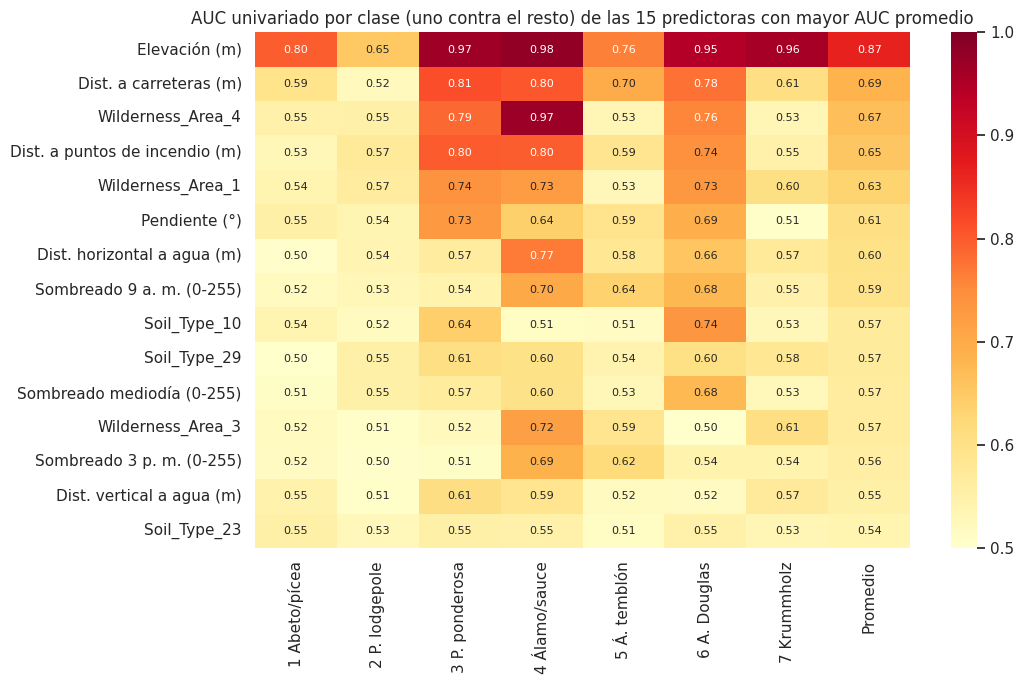

Predictora,Clase,AUC
Elevation,4 Álamo/sauce,0.980
Wilderness_Area_4,4 Álamo/sauce,0.970
Elevation,3 P. ponderosa,0.967
Elevation,7 Krummholz,0.959


In [2]:
filas = {}
for col in FEATURES:
    filas[col] = [
        max(a, 1 - a) for a in (roc_auc_score(y_train == k, X_train[col]) for k in range(1, 8))
    ]
auc = pd.DataFrame(filas, index=[CLASS_SHORT[k] for k in range(1, 8)]).T
auc["Promedio"] = auc.mean(axis=1)
auc = auc.sort_values("Promedio", ascending=False)

fig, ax = plt.subplots(figsize=(11, 7))
top = auc.head(15)
sns.heatmap(top, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0.5, vmax=1, ax=ax,
            yticklabels=[DISPLAY_NAMES.get(c, c) for c in top.index], annot_kws={"size": 8})
ax.set_title("AUC univariado por clase (uno contra el resto) de las 15 predictoras con mayor AUC promedio")
plt.tight_layout()
plt.show()

alertas = auc.drop(columns="Promedio").stack()
alertas = alertas[alertas > 0.95].sort_values(ascending=False).rename("AUC").to_frame()
alertas.index.names = ["Predictora", "Clase"]
alertas.round(3)

Ninguna predictora separa de forma casi perfecta el conjunto de clases: el AUC promedio más alto es el de la elevación (≈ 0,87). Sin embargo, **cuatro combinaciones de predictora y clase superan el umbral de 0,95**:

- **La elevación para el álamo/sauce, el pino ponderosa y el *krummholz*** (y, muy cerca del umbral, para el abeto de Douglas, con 0,947). No es fuga: es el gradiente altitudinal de la vegetación de montaña. Las especies se distribuyen en franjas de altitud por su tolerancia a la temperatura y a la humedad, algo documentado en la ecología de las Montañas Rocosas. La elevación está disponible antes de la predicción y no se deriva de la cobertura.
- **El área silvestre 4 (Cache la Poudre) para el álamo/sauce.** Tampoco es fuga en sentido estricto, porque la delimitación del área es independiente de la vegetación. Pero sí es un **proxy geográfico**: el álamo/sauce solo existe en esa área dentro de la muestra, de modo que el modelo puede aprender "Cache la Poudre implica álamo/sauce posible", una regla que no se trasladaría a otras regiones.

### Duplicados y entidades repetidas entre particiones

In [3]:
def redondear(df_):
    r = df_.copy()
    r["Elevation"] = (r["Elevation"] / 10).round()
    for col in ["Horizontal_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points"]:
        r[col] = (r[col] / 30).round()
    r["Vertical_Distance_To_Hydrology"] = (r["Vertical_Distance_To_Hydrology"] / 5).round()
    for col in ["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]:
        r[col] = (r[col] / 5).round()
    return r

claves_train = pd.MultiIndex.from_frame(X_train)
claves_test = pd.MultiIndex.from_frame(X_test)
exactos = claves_test.isin(claves_train).sum()

rtrain = pd.MultiIndex.from_frame(redondear(X_train))
rtest = pd.MultiIndex.from_frame(redondear(X_test))
casi = rtest.isin(rtrain)

pd.Series(
    {
        "Filas de prueba con un duplicado exacto en entrenamiento": f"{int(exactos)}",
        "Filas de prueba con un casi-duplicado en entrenamiento": f"{int(casi.sum())}",
        "Porcentaje de la prueba con casi-duplicado": f"{100 * casi.mean():.2f} %",
    },
    name="Valor",
).to_frame()

,Valor
Filas de prueba con un duplicado exacto en entrenamiento,0
Filas de prueba con un casi-duplicado en entrenamiento,102
Porcentaje de la prueba con casi-duplicado,0.09 %


No hay filas de prueba idénticas a filas de entrenamiento, y solo 102 celdas de prueba (0,09 %) tienen un casi-duplicado en entrenamiento, es decir, una celda con el mismo suelo y área y valores prácticamente iguales en todas las variables continuas. Probablemente se trata de **celdas vecinas** de un mismo rodal. Su número es tan pequeño que la fuga directa por celdas casi idénticas es despreciable. Sin embargo, la dependencia espacial puede operar a una escala mayor: celdas cercanas que se parecen sin ser casi idénticas y que comparten la misma cobertura. Esa forma de dependencia no se detecta con este chequeo, y se analiza en la sección 2.7 y en el capítulo 3.

### Conclusión de la auditoría

| Variable | Estado | Justificación |
|---|---|---|
| Todas las variables cartográficas | Se conservan | Disponibles antes de la predicción e independientes de la etiqueta |
| `Elevation` | Se conserva, en observación | AUC > 0,95 para tres clases por el gradiente altitudinal; relación causal legítima |
| `Wilderness_Area_4` | Se conserva, en observación | Proxy geográfico del álamo/sauce; se evalúa su efecto con validación por área |
| `Soil_Type_*` | Se conservan, en observación | Algunas unidades ELU pueden incorporar información de vegetación en su definición |
| Variables descartadas | Ninguna | No hay identificadores, variables posteriores a la etiqueta ni derivadas del objetivo |

## 2.6 Componente temporal

El conjunto **no tiene componente temporal**: no incluye fechas, horas ni periodos, y todas las celdas describen el estado del bosque en una misma fecha de referencia de la cartografía del USFS. Los índices de sombreado se refieren a horas del día (9 a. m., mediodía y 3 p. m.), pero son atributos geométricos del terreno calculados para el solsticio de verano, no mediciones en el tiempo.

En consecuencia, no aplican la partición cronológica, las pruebas de estacionariedad (ADF y KPSS), la descomposición STL (Cleveland et al., 1990) ni el análisis de autocorrelación temporal. La principal limitación temporal es la **antigüedad de los datos**: la cartografía es anterior a 1998, de modo que no refleja cambios posteriores de la cobertura por incendios, plagas (como el escarabajo del pino de montaña) o cambio climático. Un modelo entrenado con estos datos debe validarse con cartografía reciente antes de usarse para decisiones actuales.

## 2.7 Componente espacial

El conjunto no incluye latitud ni longitud, ni coordenadas proyectadas. Por eso no es posible calcular el I de Moran, los indicadores LISA, los *hotspots* de Getis-Ord ni el semivariograma, ni construir bloques espaciales con celdas o *clusters* geográficos. Aun así, los datos tienen estructura espacial, y se analiza con la información disponible: el **área silvestre**, que funciona como una unidad geográfica gruesa.

### Heterogeneidad espacial entre áreas

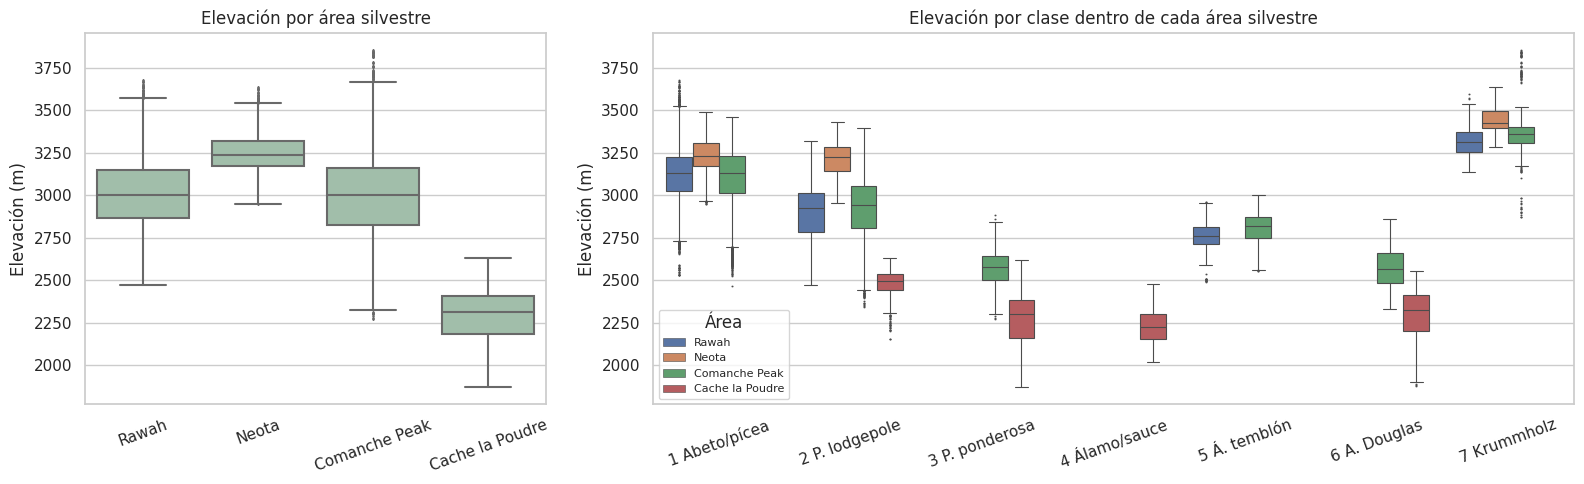

,Celdas,Elevación mediana (m),Clases presentes,Clase dominante
Rawah,208521,3002.0,4,2 P. lodgepole
Neota,23870,3240.0,3,1 Abeto/pícea
Comanche Peak,202787,2997.0,6,2 P. lodgepole
Cache la Poudre,29631,2314.0,4,3 P. ponderosa


In [4]:
orden_areas = list(WILD_NAMES.values())
datos = X_train[["Elevation"]].assign(Area=area.values, Clase=y_train.map(CLASS_SHORT).values)
muestra = datos.sample(60000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})
sns.boxplot(data=muestra, x="Area", y="Elevation", order=orden_areas, ax=axes[0], color="#9cc3a8", fliersize=1)
axes[0].set_title("Elevación por área silvestre")
axes[0].set_xlabel("")
axes[0].set_ylabel("Elevación (m)")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=muestra, x="Clase", y="Elevation", hue="Area", hue_order=orden_areas,
            order=[CLASS_SHORT[k] for k in range(1, 8)], ax=axes[1], fliersize=0.5, linewidth=0.8)
axes[1].set_title("Elevación por clase dentro de cada área silvestre")
axes[1].set_xlabel("")
axes[1].set_ylabel("Elevación (m)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="Área", fontsize=8)
plt.tight_layout()
plt.show()

resumen_area = pd.DataFrame(
    {
        "Celdas": area.value_counts(),
        "Elevación mediana (m)": X_train.groupby(area.values)["Elevation"].median(),
        "Clases presentes": pd.Series({a: y_train[area == a].nunique() for a in orden_areas}),
        "Clase dominante": pd.Series({a: CLASS_SHORT[y_train[area == a].mode()[0]] for a in orden_areas}),
    }
).loc[orden_areas]
resumen_area

**Interpretación:**

- **Las áreas difieren en su rango altitudinal.** Cache la Poudre es mucho más baja que las otras tres (mediana de 2.314 m) y Neota es la más alta (3.240 m); Rawah y Comanche Peak están cerca de los 3.000 m. Parte de la asociación entre área y cobertura es, en realidad, la asociación entre elevación y cobertura.
- **La relación entre elevación y cobertura cambia según el área.** Como muestra el panel derecho, la franja de altitud de una misma clase depende del área: el pino lodgepole tiene una elevación mediana cercana a 2.500 m en Cache la Poudre y a 3.200 m en Neota, y el pino ponderosa y el abeto de Douglas están unos 250 m más abajo en Cache la Poudre que en Comanche Peak. Una misma altitud, por tanto, no implica la misma cobertura en todas las áreas. Esto es heterogeneidad espacial: el efecto de una variable depende de la ubicación, lo que un modelo lineal global sin interacciones no puede capturar.
- **La diversidad de clases varía entre áreas.** Comanche Peak tiene seis de las siete clases; Neota, solo tres.
- **Algunas clases están restringidas a un área.** El álamo/sauce solo aparece en Cache la Poudre y el pino ponderosa, casi solo allí. Para esas clases, generalizar a zonas nuevas es difícil, porque el modelo nunca ha visto la clase en otro contexto.

### Autocorrelación espacial y efecto de la escala

En datos de cobertura vegetal a 30 m de resolución, es de esperar autocorrelación espacial: los rodales ocupan muchas celdas contiguas con condiciones parecidas y la misma cobertura. Sin coordenadas no se puede medir su alcance con el I de Moran, pero sí anticipar su efecto: **con una partición aleatoria, la validación es optimista para zonas nuevas**, porque el modelo se evalúa en celdas vecinas de las que usó para aprender.

Respecto a la escala, la unidad de análisis es fija (celdas de 30 m) y la etiqueta corresponde a la cobertura dominante de cada celda. Agregar a rodales o a cuencas cambiaría las proporciones de clase y las relaciones con las variables (problema de la unidad de área modificable), lo que conviene tener presente al comparar estos resultados con estudios a otras escalas.

### Prueba de vecindad entre prueba y entrenamiento

Sin coordenadas, el I de Moran no se puede calcular, pero el optimismo que produce la
autocorrelación espacial sí se puede cuantificar de otra forma: para cada celda de
prueba se busca su **vecino más cercano en el espacio de las variables cartográficas
numéricas** (estandarizadas) dentro del conjunto de entrenamiento, y se compara su clase
con la de ese vecino. Dos celdas contiguas en el terreno comparten casi los mismos
valores de elevación, distancias y sombreado, de modo que esta cercanía en el espacio de
variables es el mejor sustituto disponible de la cercanía geográfica real.

In [5]:
escalador = StandardScaler().fit(X_train[NUM_COLS])
Xtr_num = escalador.transform(X_train[NUM_COLS])
Xte_num = escalador.transform(X_test[NUM_COLS])

vecinos = NearestNeighbors(n_neighbors=1, algorithm="kd_tree", n_jobs=-1).fit(Xtr_num)
dist_vecino, idx_vecino = vecinos.kneighbors(Xte_num)
dist_vecino = dist_vecino.ravel()
clase_vecino = y_train.to_numpy()[idx_vecino.ravel()]
misma_clase = clase_vecino == y_test.to_numpy()

decil = pd.qcut(dist_vecino, 10, labels=[f"D{i+1}" for i in range(10)])
tabla_vecindad = pd.DataFrame({"Distancia": dist_vecino, "Misma clase que el vecino": misma_clase, "Decil": decil})
resumen_vecindad = tabla_vecindad.groupby("Decil", observed=True).agg(
    Distancia_media=("Distancia", "mean"),
    Coincidencia_de_clase=("Misma clase que el vecino", "mean"),
)
resumen_vecindad.round(3)

Decil,Distancia_media,Coincidencia_de_clase
D1,0.091,0.962
D2,0.141,0.947
D3,0.169,0.942
D4,0.192,0.936
D5,0.213,0.927
D6,0.236,0.913
D7,0.262,0.901
D8,0.295,0.883
D9,0.343,0.870
D10,0.469,0.840


In [6]:
print(f"Coincidencia de clase con el vecino más cercano (global): {misma_clase.mean():.3f}")
print(f"Coincidencia en el decil más cercano (D1): {tabla_vecindad[tabla_vecindad['Decil'] == 'D1']['Misma clase que el vecino'].mean():.3f}")
print(f"Coincidencia en el decil más lejano (D10): {tabla_vecindad[tabla_vecindad['Decil'] == 'D10']['Misma clase que el vecino'].mean():.3f}")

Coincidencia de clase con el vecino más cercano (global): 0.912
Coincidencia en el decil más cercano (D1): 0.962
Coincidencia en el decil más lejano (D10): 0.840


La coincidencia de clase con el vecino más cercano de entrenamiento cae de forma
monótona conforme aumenta la distancia: del 96,2 % en el decil más cercano al 84,0 % en
el más lejano (91,2 % en conjunto). Esto confirma, sin necesidad de coordenadas, que las
celdas de prueba más próximas en el espacio de variables a una celda de entrenamiento
heredan buena parte de su etiqueta por simple cercanía —el mecanismo típico de la
autocorrelación espacial—, mientras que las celdas más alejadas de cualquier punto de
entrenamiento son, de entrada, más difíciles de acertar. La validación con partición
aleatoria estratificada (capítulo 3) es, por tanto, optimista para el subconjunto de
celdas de prueba que caen muy cerca de una celda de entrenamiento, y ese optimismo se
suma al que ya identifica la validación por área del mismo capítulo.

### Consecuencias para el modelado

1. **Pregunta de generalización.** El objetivo principal del proyecto es predecir la cobertura de celdas no inventariadas **dentro de las mismas áreas** que cubre la muestra. Para ese objetivo, la partición estratificada aleatoria es adecuada, con la salvedad del leve optimismo por vecindad.
2. **Prueba de sensibilidad.** Para medir la capacidad de generalizar a **zonas nuevas**, en el capítulo 3 se evalúa el modelo con validación por grupos (`GroupKFold`), dejando fuera un área silvestre completa en cada pliegue. Es el análogo disponible de la validación por bloques espaciales.
3. **Coordenadas crudas.** No se dispone de coordenadas, de modo que no hay riesgo de que el modelo memorice la ubicación exacta. El área silvestre sí actúa como variable geográfica gruesa y se conserva por ser una delimitación administrativa conocida en el momento de la predicción.

## 2.8 Componente espacio-temporal

El conjunto no tiene componente temporal (sección 2.6), de modo que el análisis espacio-temporal no aplica: no hay mapas por periodo, series por zona, *hotspots* emergentes ni autocorrelación espacio-temporal que estudiar.

# 2.9 Preprocesamiento

Todo el preprocesamiento se implementa dentro de un `Pipeline` de scikit-learn. Así, cualquier parámetro aprendido de los datos (medias y desviaciones del escalado) se estima solo con la porción de entrenamiento de cada pliegue de validación cruzada, y el conjunto de prueba se transforma con los parámetros aprendidos en entrenamiento, sin intervenir en su estimación.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config

from _utils import (
    DISPLAY_NAMES, ENG_NUM_COLS, LOG_COLS, NUM_COLS, build_logreg, engineer_features,
    load_covertype, split_covertype,
)

sns.set_theme(style="whitegrid", context="notebook")
set_config(display="diagram")

df, X, y = load_covertype()
X_train, X_test, y_train, y_test = split_covertype(X, y)

## Decisiones y hallazgos que las motivan

| Paso | Decisión | Hallazgo del EDA que la motiva |
|---|---|---|
| Imputación | No se imputa | No hay valores faltantes ni códigos centinela (sección 1.8) |
| Valores atípicos | Se conservan todos | Son valores físicamente válidos y se concentran en las clases minoritarias (secciones 1.8 y 2.4) |
| Orientación | Se sustituye por su seno y su coseno | Es una variable circular: 0° y 360° son la misma dirección (secciones 1.8 y 2.2) |
| Distancias horizontales | Transformación $\log(1 + x)$ | Asimetría positiva y colas derechas largas (sección 2.2) |
| Distancia euclidiana al agua | Nueva variable: $\sqrt{d_h^2 + d_v^2}$ | Correlación moderada entre distancia horizontal y vertical (sección 2.3) |
| Elevación relativa al agua | Nueva variable: elevación menos distancia vertical | La elevación es la variable más informativa; la altitud de la fuente de agua más cercana describe la posición en la cuenca (secciones 2.3 y 2.5) |
| Escalado | `StandardScaler` en las variables numéricas | Las escalas son muy distintas (grados, metros e índices de 0 a 255), y la regularización de la regresión logística es sensible a la escala |
| Variables categóricas | Se conservan las 44 indicadoras *one-hot* originales, sin escalar | Ya vienen codificadas y son consistentes (sección 1.8) |
| Categorías raras | Se conservan sin agrupar | Los suelos raros se asocian con clases distintas; la regularización L2 controla sus coeficientes (sección 2.2) |
| Multicolinealidad | Se conservan los tres índices de sombreado | Colinealidad alta (VIF de 38 a 144) que la regularización L2 controla; se advierte al interpretar coeficientes (sección 2.3) |
| Desbalance | `class_weight` se evalúa como hiperparámetro | Razón de desbalance de 103 a 1 (sección 2.1) |

Todas las transformaciones de ingeniería de variables son **funciones fijas** (seno, coseno, logaritmo, sumas y restas), sin parámetros aprendidos de los datos, por lo que no pueden introducir fuga. El único paso con parámetros aprendidos es el escalado, y se ajusta dentro del `Pipeline`.

## Efecto de las transformaciones

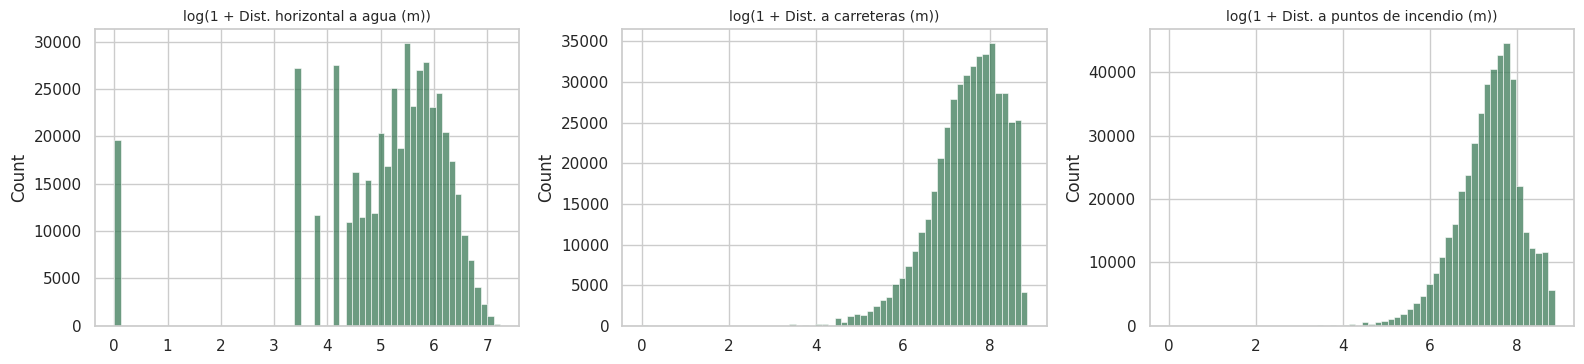

,Asimetría original,Asimetría con log(1 + x)
Dist. horizontal a agua (m),1.14,-2.14
Dist. a carreteras (m),0.71,-1.00
Dist. a puntos de incendio (m),1.29,-0.80


In [2]:
X_eng = engineer_features(X_train)
comparacion = pd.DataFrame(
    {
        "Asimetría original": X_train[LOG_COLS].skew(),
        "Asimetría con log(1 + x)": X_eng[LOG_COLS].skew(),
    }
).round(2)
comparacion.index = [DISPLAY_NAMES[c] for c in comparacion.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, LOG_COLS):
    sns.histplot(X_eng[col], bins=60, ax=ax, color="#3b7a57")
    ax.set_title(f"log(1 + {DISPLAY_NAMES[col]})", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()
comparacion

La transformación logarítmica elimina la cola derecha de las distancias, aunque genera asimetría negativa en la distancia horizontal al agua por la acumulación de celdas junto a un curso de agua (distancia cero). Por esa razón, en el capítulo 3 la ingeniería de variables se trata como **un hiperparámetro más**: se comparan por validación cruzada un preprocesamiento básico (solo escalado) y el preprocesamiento con ingeniería de variables, y se elige el que mejor desempeño obtenga, en lugar de asumir que la transformación ayuda.

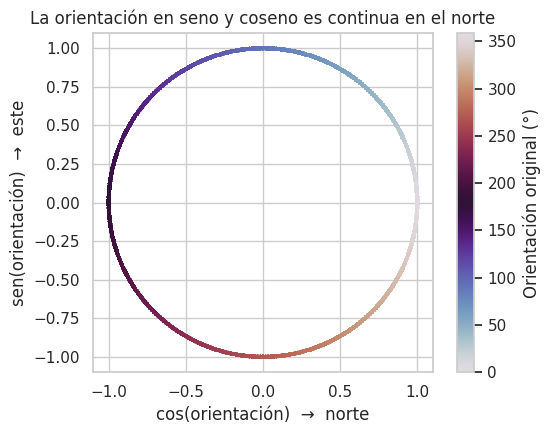

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
muestra = X_eng.sample(20000, random_state=42)
sc = ax.scatter(muestra["Aspect_cos"], muestra["Aspect_sin"], c=X_train.loc[muestra.index, "Aspect"],
                cmap="twilight", s=3)
ax.set_xlabel("cos(orientación)  →  norte")
ax.set_ylabel("sen(orientación)  →  este")
ax.set_title("La orientación en seno y coseno es continua en el norte")
ax.set_aspect("equal")
fig.colorbar(sc, label="Orientación original (°)")
plt.tight_layout()
plt.show()

Con la representación en seno y coseno, una ladera orientada a 359° y otra a 1° quedan una junto a la otra, como corresponde, en lugar de quedar en los extremos opuestos de la escala.

## Pipeline resultante

In [4]:
pipeline = build_logreg(engineered=True)
pipeline

,steps,"[('prep', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('features', ...), ('scale', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function eng...x7fd63fb197e0>
,inverse_func,None
,validate,False


El `Pipeline` tiene dos etapas: el preprocesamiento (ingeniería de variables seguida de un `ColumnTransformer` que escala las 13 variables numéricas y deja pasar las 44 indicadoras) y el clasificador. Al entrenar, el modelo recibe 57 predictoras:

In [5]:
print(f"Numéricas escaladas ({len(ENG_NUM_COLS)}): {', '.join(ENG_NUM_COLS)}")
print("Indicadoras sin transformar: 4 de área silvestre y 40 de tipo de suelo")

Numéricas escaladas (13): Elevation, Slope, Horizontal_Distance_To_Hydrology, Vertical_Distance_To_Hydrology, Horizontal_Distance_To_Roadways, Hillshade_9am, Hillshade_Noon, Hillshade_3pm, Horizontal_Distance_To_Fire_Points, Aspect_sin, Aspect_cos, Dist_Hydrology_Euclid, Elevation_Minus_VDH
Indicadoras sin transformar: 4 de área silvestre y 40 de tipo de suelo


# 3. Modelo base

Este capítulo construye la referencia de desempeño del estudio. Se compara una **línea base trivial** (`DummyClassifier`) con un **modelo base** de regresión logística multinomial entrenado (Hosmer et al., 2013) dentro de un `Pipeline`, se eligen sus hiperparámetros con validación cruzada estratificada y se evalúa una única vez sobre el conjunto de prueba reservado en la sección 1.6.

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, log_loss, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, GroupKFold, StratifiedKFold, cross_validate, learning_curve,
)
from sklearn.preprocessing import label_binarize

from _utils import (
    CLASS_NAMES, CLASS_PALETTE, CLASS_SHORT, DISPLAY_NAMES, ENG_NUM_COLS, RANDOM_STATE,
    SOIL_COLS, WILD_COLS, WILD_NAMES, build_logreg, build_preprocessor, load_covertype,
    split_covertype, stratified_sample, wilderness_label,
)

sns.set_theme(style="whitegrid", context="notebook")
CLASES = list(range(1, 8))

df, X, y = load_covertype()
X_train, X_test, y_train, y_test = split_covertype(X, y)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 3.1 Variable objetivo y esquema de evaluación

- **Variable objetivo:** `Cover_Type`, tipo de cobertura forestal dominante, con siete clases nominales (sección 1.4).
- **Partición:** 80 % entrenamiento y 20 % prueba, estratificada por clase y con semilla 42, definida antes de cualquier preprocesamiento (sección 1.6).
- **Validación cruzada:** `StratifiedKFold` con 5 pliegues, del mismo tipo que la partición. Como prueba de sensibilidad espacial se usa además `GroupKFold` por área silvestre (sección 3.8).
- **Métrica de selección:** F1 macro, porque da el mismo peso a las siete clases y no premia al modelo que ignora las minoritarias (sección 2.1). Se reportan también *accuracy*, exactitud balanceada, precisión y *recall* macro, F1 ponderado, AUC uno contra el resto y log loss.

## 3.2 Línea base trivial

Se evalúan tres estrategias de `DummyClassifier`: predecir siempre la clase más frecuente, predecir al azar respetando las proporciones de clase (estratificada) y predecir al azar con probabilidad uniforme.

In [2]:
def metricas(y_true, pred, proba):
    """Métricas de clasificación multiclase usadas en todo el capítulo."""
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Exactitud balanceada": balanced_accuracy_score(y_true, pred),
        "Precisión macro": precision_score(y_true, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_true, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_true, pred, average="macro", zero_division=0),
        "F1 ponderado": f1_score(y_true, pred, average="weighted", zero_division=0),
        "AUC OvR macro": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
        "Log loss": log_loss(y_true, proba, labels=CLASES),
    }

dummies = {
    "Dummy (más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Dummy (estratificado)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Dummy (uniforme)": DummyClassifier(strategy="uniform", random_state=RANDOM_STATE),
}
res_test = {}
for nombre, modelo in dummies.items():
    modelo.fit(X_train, y_train)
    res_test[nombre] = metricas(y_test, modelo.predict(X_test), modelo.predict_proba(X_test))
pd.DataFrame(res_test).T.round(3)

,Accuracy,Exactitud balanceada,Precisión macro,Recall macro,F1 macro,F1 ponderado,AUC OvR macro,Log loss
Dummy (más frecuente),0.488,0.143,0.070,0.143,0.094,0.320,0.500,18.469
Dummy (estratificado),0.374,0.141,0.141,0.141,0.141,0.374,0.499,22.561
Dummy (uniforme),0.143,0.145,0.142,0.145,0.094,0.191,0.500,1.946


El clasificador que siempre predice pino lodgepole alcanza cerca del 49 % de *accuracy*, pero su F1 macro es de apenas 0,09 y su exactitud balanceada es exactamente 1/7 (0,143), porque acierta en una clase y falla en las otras seis. Esta es la referencia mínima que cualquier modelo útil debe superar con claridad, sobre todo en las métricas que ponderan todas las clases por igual.

## 3.3 Selección de hiperparámetros

Se busca en una rejilla la mejor combinación de:

- **Preprocesamiento:** básico (solo escalado) o con ingeniería de variables (sección 2.9).
- **Regularización:** inverso de la fuerza de regularización L2, $C \in \{0{,}1;\ 1;\ 10\}$.
- **Ponderación de clases:** sin ponderación o `class_weight="balanced"`.

Cada una de las 12 combinaciones se evalúa con validación cruzada estratificada de 5 pliegues. Ajustar una regresión logística sobre las 464.809 celdas de entrenamiento toma varios minutos, así que la búsqueda se hace sobre una **submuestra estratificada de 30.000 celdas** del entrenamiento. La curva de aprendizaje de la sección 3.9 muestra que el desempeño de la regresión logística ya está prácticamente estabilizado con ese tamaño de muestra, de modo que la submuestra no cambia la elección de hiperparámetros. El modelo final sí se entrena con todo el conjunto de entrenamiento.

In [3]:
X_sub, y_sub = stratified_sample(X_train, y_train, 30000)
rejilla = {
    "prep": [build_preprocessor(engineered=False), build_preprocessor(engineered=True)],
    "clf__C": [0.1, 1.0, 10.0],
    "clf__class_weight": [None, "balanced"],
}
busqueda = GridSearchCV(
    build_logreg(),
    rejilla,
    scoring={"f1_macro": "f1_macro", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
    refit=False,
    cv=cv5,
    n_jobs=-1,
)
inicio = time.time()
busqueda.fit(X_sub, y_sub)
print(f"Tiempo de la búsqueda: {time.time() - inicio:.0f} s")

cvr = pd.DataFrame(busqueda.cv_results_)
cvr["Preprocesamiento"] = np.where(cvr["param_prep"].astype(str).str.startswith("Pipeline"), "Con ingeniería", "Básico")
cvr["Ponderación"] = cvr["param_clf__class_weight"].fillna("ninguna").astype(str)
tabla_cv = cvr[["Preprocesamiento", "param_clf__C", "Ponderación", "mean_test_f1_macro", "std_test_f1_macro",
                "mean_test_accuracy", "mean_test_balanced_accuracy"]].rename(columns={
    "param_clf__C": "C", "mean_test_f1_macro": "F1 macro (media)", "std_test_f1_macro": "F1 macro (desv.)",
    "mean_test_accuracy": "Accuracy (media)", "mean_test_balanced_accuracy": "Exactitud balanceada (media)",
}).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)
tabla_cv.round(4)

Tiempo de la búsqueda: 54 s


,Preprocesamiento,C,Ponderación,F1 macro (media),F1 macro (desv.),Accuracy (media),Exactitud balanceada (media)
0,Con ingeniería,10.0,ninguna,0.5670,0.0118,0.7232,0.5401
1,Con ingeniería,1.0,ninguna,0.5666,0.0124,0.7235,0.5383
2,Básico,10.0,ninguna,0.5500,0.0172,0.7223,0.5267
3,Con ingeniería,0.1,ninguna,0.5367,0.0135,0.7217,0.5055
4,Básico,1.0,ninguna,0.5359,0.0152,0.7210,0.5121
5,Con ingeniería,1.0,balanced,0.5166,0.0042,0.6022,0.7062
6,Con ingeniería,10.0,balanced,0.5164,0.0070,0.6016,0.7038
7,Con ingeniería,0.1,balanced,0.5112,0.0051,0.6000,0.7015
8,Básico,0.1,ninguna,0.5066,0.0158,0.7200,0.4795
9,Básico,1.0,balanced,0.4989,0.0043,0.5979,0.6970


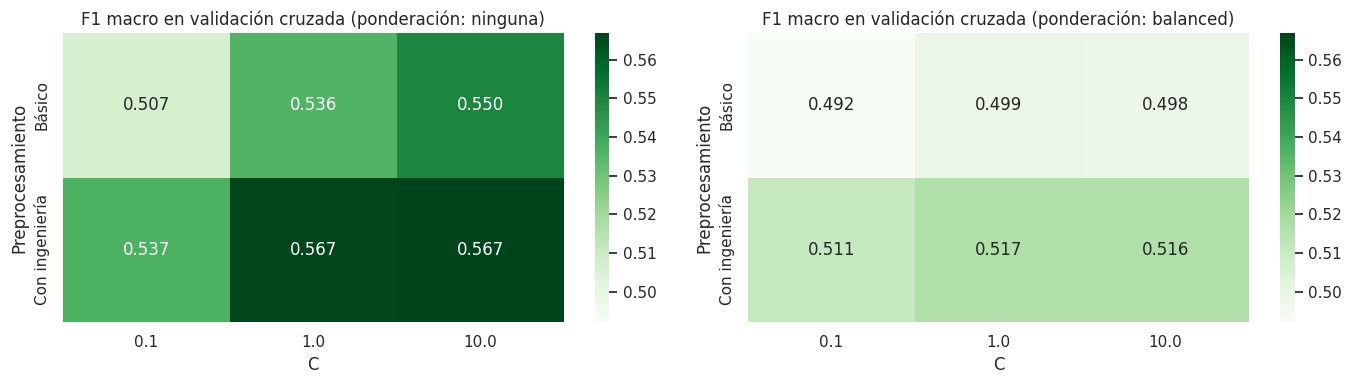

Mejor configuración: preprocesamiento con ingeniería, C = 10.0, ponderación = ninguna (F1 macro = 0.567 ± 0.012)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, pond in zip(axes, ["ninguna", "balanced"]):
    piv = tabla_cv[tabla_cv["Ponderación"] == pond].pivot(index="Preprocesamiento", columns="C", values="F1 macro (media)")
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="Greens", ax=ax, vmin=tabla_cv["F1 macro (media)"].min(),
                vmax=tabla_cv["F1 macro (media)"].max())
    ax.set_title(f"F1 macro en validación cruzada (ponderación: {pond})")
plt.tight_layout()
plt.show()

mejor = tabla_cv.iloc[0]
MEJOR_ENG = mejor["Preprocesamiento"] == "Con ingeniería"
MEJOR_C = float(mejor["C"])
MEJOR_CW = None if mejor["Ponderación"] == "ninguna" else "balanced"
print(f"Mejor configuración: preprocesamiento {mejor['Preprocesamiento'].lower()}, C = {MEJOR_C}, "
      f"ponderación = {mejor['Ponderación']} (F1 macro = {mejor['F1 macro (media)']:.3f} ± {mejor['F1 macro (desv.)']:.3f})")

Tres conclusiones se desprenden de la búsqueda:

1. **La ingeniería de variables mejora el modelo** en todas las combinaciones de $C$ y ponderación. La representación circular de la orientación, el logaritmo de las distancias y las dos variables nuevas de posición respecto al agua aportan información que la regresión logística no puede construir por sí sola, porque es lineal en sus entradas.
2. **La regularización tiene poco efecto** para $C \geq 1$: con más de 8.000 observaciones de entrenamiento por predictora (sección 1.7), la varianza del estimador es baja y la penalización deja de ser determinante. Solo la regularización más fuerte ($C = 0{,}1$) reduce un poco el desempeño.
3. **La ponderación de clases implica un compromiso claro.** Con `class_weight="balanced"` la exactitud balanceada sube de forma notable, porque el modelo detecta mucho mejor las clases minoritarias, pero el *accuracy* y el F1 macro bajan, porque el modelo empieza a asignar muchas celdas de las clases mayoritarias a las minoritarias y su precisión en estas cae. Según el criterio de selección definido (F1 macro), el modelo base se entrena sin ponderación; la versión ponderada se evalúa también en prueba (sección 3.6) para documentar el compromiso.

## 3.4 Entrenamiento del modelo final

In [5]:
inicio = time.time()
modelo = build_logreg(engineered=MEJOR_ENG, C=MEJOR_C, class_weight=MEJOR_CW, max_iter=3000)
modelo.fit(X_train, y_train)
print(f"Tiempo de entrenamiento con {len(X_train):,} celdas: {time.time() - inicio:.0f} s".replace(",", "."))
print(f"Iteraciones del optimizador: {modelo.named_steps['clf'].n_iter_[0]} (máximo 3000)")

X_cv, y_cv = stratified_sample(X_train, y_train, 100000)
cv_final = cross_validate(
    build_logreg(engineered=MEJOR_ENG, C=MEJOR_C, class_weight=MEJOR_CW, max_iter=3000),
    X_cv, y_cv, cv=cv5, n_jobs=-1, return_train_score=True,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
)
resumen_cv = pd.DataFrame(
    {
        "Entrenamiento (media)": [cv_final[f"train_{m}"].mean() for m in ["accuracy", "f1_macro", "balanced_accuracy"]],
        "Validación (media)": [cv_final[f"test_{m}"].mean() for m in ["accuracy", "f1_macro", "balanced_accuracy"]],
        "Validación (desv. est.)": [cv_final[f"test_{m}"].std() for m in ["accuracy", "f1_macro", "balanced_accuracy"]],
    },
    index=["Accuracy", "F1 macro", "Exactitud balanceada"],
).round(4)
resumen_cv

Tiempo de entrenamiento con 464.809 celdas: 56 s
Iteraciones del optimizador: 301 (máximo 3000)


,Entrenamiento (media),Validación (media),Validación (desv. est.)
Accuracy,0.7278,0.7269,0.0024
F1 macro,0.5667,0.5646,0.0114
Exactitud balanceada,0.5394,0.5387,0.0113


La tabla muestra la validación cruzada estratificada de 5 pliegues del modelo elegido sobre una submuestra de 100.000 celdas. Las métricas de entrenamiento y validación son prácticamente iguales y la desviación estándar entre pliegues es muy pequeña, lo que indica un modelo **estable y sin sobreajuste**. Si el modelo tiene alguna limitación, es de sesgo (su forma lineal es demasiado simple), no de varianza.

## 3.5 Evaluación en el conjunto de prueba

### Métricas globales con intervalos de confianza

Los intervalos de confianza del 95 % se obtienen con *bootstrap* percentil: se remuestrean con reemplazo las 116.203 celdas de prueba 200 veces y se recalcula cada métrica.

In [6]:
pred = modelo.predict(X_test)
proba = modelo.predict_proba(X_test)
res_test["Regresión logística"] = metricas(y_test, pred, proba)

rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
boot = {m: [] for m in ["Accuracy", "Exactitud balanceada", "F1 macro", "AUC OvR macro"]}
for _ in range(200):
    i = rng.integers(0, len(yt), len(yt))
    boot["Accuracy"].append(accuracy_score(yt[i], pred[i]))
    boot["Exactitud balanceada"].append(balanced_accuracy_score(yt[i], pred[i]))
    boot["F1 macro"].append(f1_score(yt[i], pred[i], average="macro"))
    boot["AUC OvR macro"].append(roc_auc_score(yt[i], proba[i], multi_class="ovr", average="macro"))
ic = pd.DataFrame(
    {
        "Estimación": [res_test["Regresión logística"][m] for m in boot],
        "IC 95 % inferior": [np.percentile(v, 2.5) for v in boot.values()],
        "IC 95 % superior": [np.percentile(v, 97.5) for v in boot.values()],
    },
    index=list(boot),
).round(4)
ic

,Estimación,IC 95 % inferior,IC 95 % superior
Accuracy,0.7242,0.7216,0.7269
Exactitud balanceada,0.5322,0.5255,0.5388
F1 macro,0.5579,0.5511,0.5648
AUC OvR macro,0.9373,0.9362,0.9383


In [7]:
comparacion = pd.DataFrame(res_test).T[
    ["Accuracy", "Exactitud balanceada", "Precisión macro", "Recall macro", "F1 macro", "F1 ponderado", "AUC OvR macro", "Log loss"]
]
comparacion.round(3)

,Accuracy,Exactitud balanceada,Precisión macro,Recall macro,F1 macro,F1 ponderado,AUC OvR macro,Log loss
Dummy (más frecuente),0.488,0.143,0.070,0.143,0.094,0.320,0.500,18.469
Dummy (estratificado),0.374,0.141,0.141,0.141,0.141,0.374,0.499,22.561
Dummy (uniforme),0.143,0.145,0.142,0.145,0.094,0.191,0.500,1.946
Regresión logística,0.724,0.532,0.651,0.532,0.558,0.716,0.937,0.627


In [8]:
base = res_test["Dummy (más frecuente)"]
lr = res_test["Regresión logística"]
mejoras = pd.DataFrame(
    {
        "Dummy (más frecuente)": [base[m] for m in ["Accuracy", "Exactitud balanceada", "F1 macro", "AUC OvR macro"]],
        "Regresión logística": [lr[m] for m in ["Accuracy", "Exactitud balanceada", "F1 macro", "AUC OvR macro"]],
    },
    index=["Accuracy", "Exactitud balanceada", "F1 macro", "AUC OvR macro"],
)
mejoras["Mejora absoluta"] = mejoras["Regresión logística"] - mejoras["Dummy (más frecuente)"]
mejoras.round(3)

,Dummy (más frecuente),Regresión logística,Mejora absoluta
Accuracy,0.488,0.724,0.237
Exactitud balanceada,0.143,0.532,0.389
F1 macro,0.094,0.558,0.464
AUC OvR macro,0.500,0.937,0.437


La regresión logística **supera ampliamente a todas las líneas base triviales** en todas las métricas: gana 23,7 puntos de *accuracy* (0,724 frente a 0,488), 38,9 puntos de exactitud balanceada y 46,4 puntos de F1 macro sobre el clasificador de la clase más frecuente. Los intervalos de confianza son estrechos (alrededor de medio punto porcentual de amplitud para el *accuracy*) gracias al tamaño del conjunto de prueba. Las métricas de prueba coinciden con las de validación cruzada (0,727 de *accuracy* y 0,565 de F1 macro), lo que confirma que la estimación no está sesgada por la selección de hiperparámetros.

Sin embargo, la brecha entre el *accuracy* (0,72) y la exactitud balanceada o el F1 macro (0,53 y 0,56) revela que **el buen desempeño global descansa sobre las clases mayoritarias**. El AUC uno contra el resto es alto (0,94), lo que indica que el modelo ordena bien las celdas según su probabilidad de pertenecer a cada clase, aunque la regla de asignar la clase con mayor probabilidad favorece a las clases frecuentes.

### Desempeño por clase

Los intervalos de confianza del 95 % para las métricas por clase se obtienen con el
mismo procedimiento de *bootstrap* percentil (200 remuestreos) usado en las métricas
globales.

In [9]:
reporte = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
reporte = reporte.loc[[str(k) for k in CLASES]]
reporte.index = [CLASS_SHORT[k] for k in CLASES]
reporte.columns = ["Precisión", "Recall", "F1", "Soporte"]
reporte["Soporte"] = reporte["Soporte"].astype(int)

rng_clase = np.random.default_rng(RANDOM_STATE)
n_test = len(yt)
boot_clase = {k: {"Precisión": [], "Recall": [], "F1": []} for k in CLASES}
for _ in range(200):
    i = rng_clase.integers(0, n_test, n_test)
    p_i = precision_score(yt[i], pred[i], average=None, labels=CLASES, zero_division=0)
    r_i = recall_score(yt[i], pred[i], average=None, labels=CLASES, zero_division=0)
    f_i = f1_score(yt[i], pred[i], average=None, labels=CLASES, zero_division=0)
    for idx, k in enumerate(CLASES):
        boot_clase[k]["Precisión"].append(p_i[idx])
        boot_clase[k]["Recall"].append(r_i[idx])
        boot_clase[k]["F1"].append(f_i[idx])

def _fmt_ic(punto, muestras):
    lo, hi = np.percentile(muestras, [2.5, 97.5])
    return f"{punto:.3f} [{lo:.3f}, {hi:.3f}]"

filas_ic = []
for k in CLASES:
    nombre = CLASS_SHORT[k]
    filas_ic.append({
        "Precisión": _fmt_ic(reporte.loc[nombre, "Precisión"], boot_clase[k]["Precisión"]),
        "Recall": _fmt_ic(reporte.loc[nombre, "Recall"], boot_clase[k]["Recall"]),
        "F1": _fmt_ic(reporte.loc[nombre, "F1"], boot_clase[k]["F1"]),
        "Soporte": reporte.loc[nombre, "Soporte"],
    })
reporte_ic = pd.DataFrame(filas_ic, index=[CLASS_SHORT[k] for k in CLASES])
reporte_ic

,Precisión,Recall,F1,Soporte
1 Abeto/pícea,"0.710 [0.706, 0.714]","0.696 [0.692, 0.701]","0.703 [0.700, 0.706]",42368
2 P. lodgepole,"0.747 [0.743, 0.750]","0.799 [0.795, 0.802]","0.772 [0.769, 0.774]",56661
3 P. ponderosa,"0.691 [0.681, 0.701]","0.798 [0.790, 0.806]","0.741 [0.732, 0.749]",7151
4 Álamo/sauce,"0.691 [0.648, 0.737]","0.530 [0.492, 0.570]","0.600 [0.566, 0.634]",549
5 Á. temblón,"0.482 [0.409, 0.569]","0.042 [0.034, 0.051]","0.077 [0.063, 0.093]",1899
6 A. Douglas,"0.495 [0.475, 0.513]","0.301 [0.286, 0.315]","0.374 [0.359, 0.390]",3473
7 Krummholz,"0.742 [0.728, 0.759]","0.560 [0.546, 0.575]","0.639 [0.627, 0.650]",4102


Las clases mayoritarias (pino lodgepole, abeto/pícea) tienen intervalos muy estrechos
gracias a su gran soporte; las minoritarias (álamo temblón, álamo/sauce) tienen
intervalos bastante más amplios, lo que es consistente con un tamaño de muestra efectivo
mucho menor para esas clases.

### Matriz de confusión

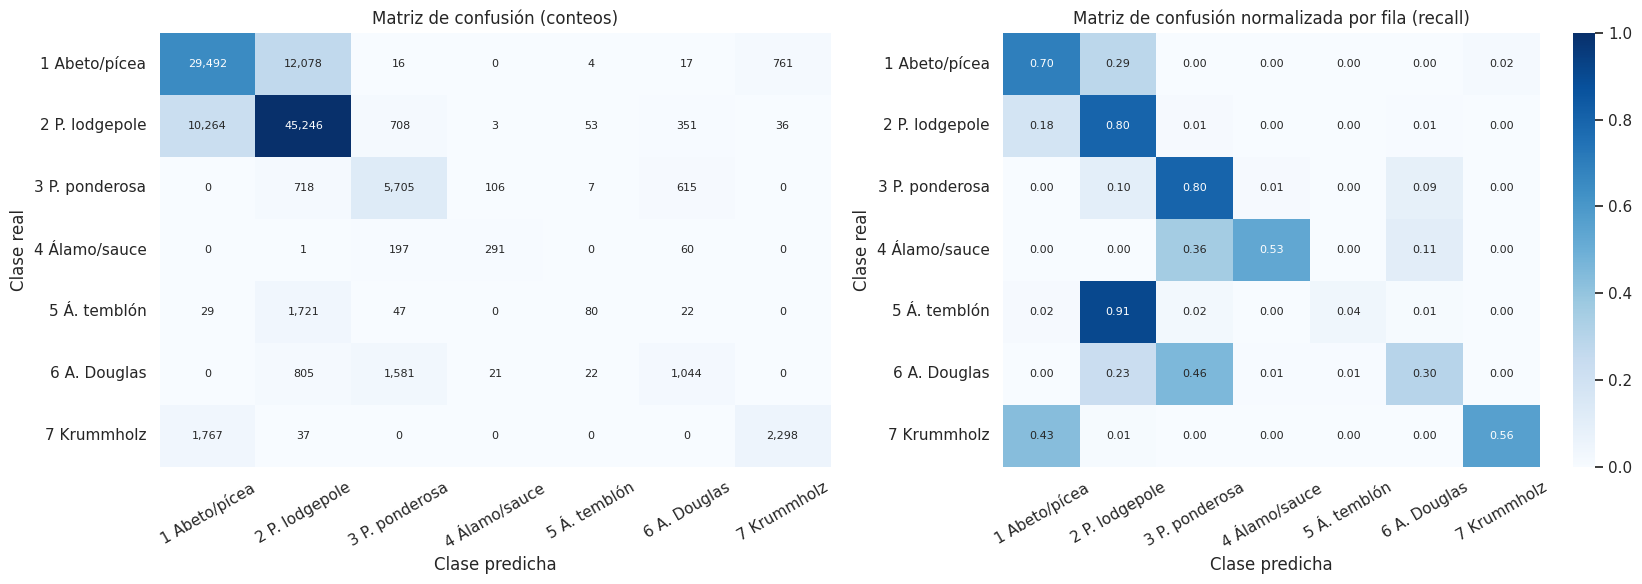

In [10]:
cm = confusion_matrix(y_test, pred, labels=CLASES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
etiquetas = [CLASS_SHORT[k] for k in CLASES]
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[0], xticklabels=etiquetas, yticklabels=etiquetas,
            cbar=False, annot_kws={"size": 8})
axes[0].set_title("Matriz de confusión (conteos)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[1], xticklabels=etiquetas, yticklabels=etiquetas,
            vmin=0, vmax=1, annot_kws={"size": 8})
axes[1].set_title("Matriz de confusión normalizada por fila (recall)")
for ax in axes:
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

La matriz de confusión identifica cuatro patrones de error:

- **Confusión entre abeto/pícea y pino lodgepole.** Es el error más frecuente en términos absolutos: el 29 % del abeto/pícea se clasifica como pino lodgepole y el 18 % del pino lodgepole como abeto/pícea (más de 22.000 celdas entre ambos sentidos). Las dos clases comparten elevaciones, suelos y áreas (sección 2.3), y el modelo lineal no encuentra una frontera que las separe bien.
- **Confusión en el límite superior del bosque.** El 43 % del *krummholz* se clasifica como abeto/pícea, la especie con la que comparte la franja más alta.
- **Confusión dentro del grupo de zonas bajas.** El 46 % del abeto de Douglas se asigna al pino ponderosa, y el 36 % del álamo/sauce también. Las tres clases comparten el área de Cache la Poudre, las elevaciones bajas y suelos similares.
- **El álamo temblón (clase 5) prácticamente no se reconoce.** Solo el 4 % de sus celdas se clasifica bien; el 91 % se asigna al pino lodgepole. Es una clase minoritaria cuyo rango de variables se superpone con el de una clase mayoritaria, el peor escenario para un modelo lineal sin ponderación.

### Curvas ROC y precisión-*recall*

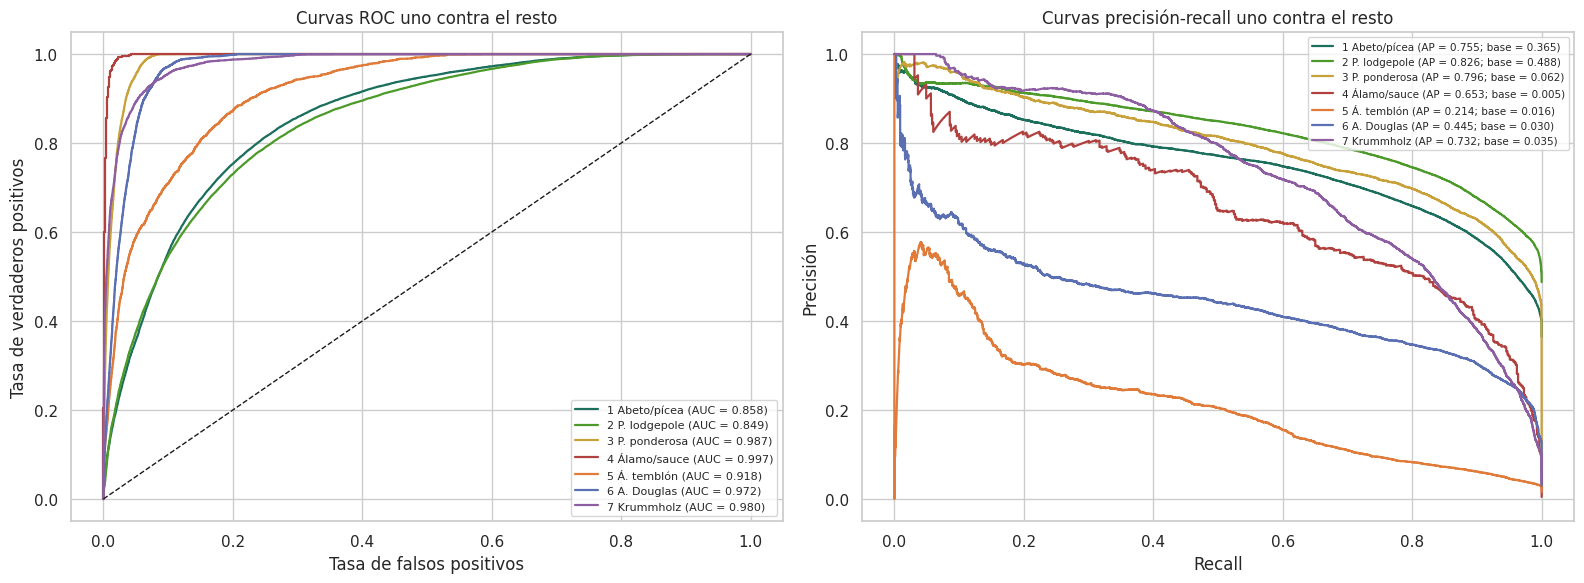

In [11]:
Y_bin = label_binarize(y_test, classes=CLASES)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for j, k in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(Y_bin[:, j], proba[:, j])
    auc_k = roc_auc_score(Y_bin[:, j], proba[:, j])
    axes[0].plot(fpr, tpr, color=CLASS_PALETTE[k], lw=1.6, label=f"{CLASS_SHORT[k]} (AUC = {auc_k:.3f})")
    prec, rec, _ = precision_recall_curve(Y_bin[:, j], proba[:, j])
    ap = average_precision_score(Y_bin[:, j], proba[:, j])
    axes[1].plot(rec, prec, color=CLASS_PALETTE[k], lw=1.6, label=f"{CLASS_SHORT[k]} (AP = {ap:.3f}; base = {Y_bin[:, j].mean():.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curvas ROC uno contra el resto")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisión")
axes[1].set_title("Curvas precisión-recall uno contra el resto")
axes[1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout()
plt.show()

Las curvas ROC son altas para todas las clases: el AUC va de 0,85 (pino lodgepole) a 0,997 (álamo/sauce). Paradójicamente, las clases mayoritarias tienen el AUC más bajo, porque son las que más se confunden entre sí. Pero con clases muy desbalanceadas la curva ROC es optimista, ya que la tasa de falsos positivos se calcula sobre una clase negativa enorme. Las **curvas precisión-*recall*** dan una imagen más realista:

- La precisión promedio (AP) de todas las clases supera con amplitud su prevalencia, que es la AP de un clasificador aleatorio. Por ejemplo, el álamo/sauce tiene una AP de 0,66 con una prevalencia de 0,005, lo que confirma que el modelo sí contiene señal para las clases minoritarias.
- El álamo temblón (AP = 0,22) y el abeto de Douglas (AP = 0,45) son los casos más difíciles: su precisión cae rápidamente al aumentar el *recall*, de modo que detectarlos exige aceptar muchos falsos positivos.

### Calibración

Un modelo está bien calibrado si, entre las celdas a las que asigna una probabilidad de 0,7 para una clase, cerca del 70 % pertenecen realmente a ella. Se evalúa con curvas de confiabilidad uno contra el resto (10 intervalos por cuantiles de la probabilidad predicha) y con la puntuación de Brier multiclase (Brier, 1950), que es el error cuadrático medio entre el vector de probabilidades y el vector *one-hot* de la clase real.

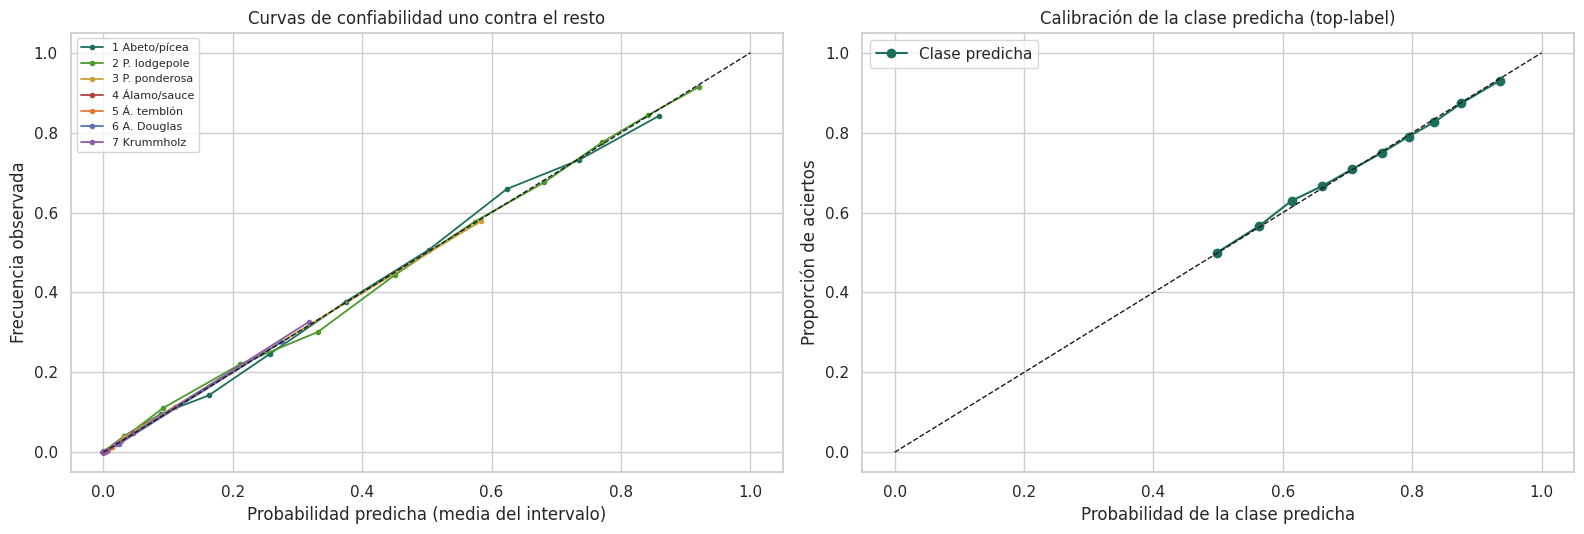

Brier multiclase de la regresión logística: 0.3808
Brier multiclase de predecir siempre las proporciones de clase: 0.6231


,1 Abeto/pícea,2 P. lodgepole,3 P. ponderosa,4 Álamo/sauce,5 Á. temblón,6 A. Douglas,7 Krummholz
Brier uno contra el resto,0.1469,0.158,0.0227,0.0025,0.0142,0.0202,0.0164


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
brier = {}
for j, k in enumerate(CLASES):
    frac, media = calibration_curve(Y_bin[:, j], proba[:, j], n_bins=10, strategy="quantile")
    axes[0].plot(media, frac, "o-", color=CLASS_PALETTE[k], ms=3, lw=1.3, label=CLASS_SHORT[k])
    brier[CLASS_SHORT[k]] = np.mean((proba[:, j] - Y_bin[:, j]) ** 2)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("Probabilidad predicha (media del intervalo)")
axes[0].set_ylabel("Frecuencia observada")
axes[0].set_title("Curvas de confiabilidad uno contra el resto")
axes[0].legend(fontsize=8)

confianza = proba.max(axis=1)
acierto = (pred == yt).astype(int)
frac_top, media_top = calibration_curve(acierto, confianza, n_bins=10, strategy="quantile")
axes[1].plot(media_top, frac_top, "o-", color="#1b6f5c", label="Clase predicha")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("Probabilidad de la clase predicha")
axes[1].set_ylabel("Proporción de aciertos")
axes[1].set_title("Calibración de la clase predicha (top-label)")
axes[1].legend()
plt.tight_layout()
plt.show()

brier_multi = np.mean(np.sum((proba - Y_bin) ** 2, axis=1))
brier_dummy = np.mean(np.sum((dummies["Dummy (estratificado)"].predict_proba(X_test) - Y_bin) ** 2, axis=1))
prior = y_train.value_counts(normalize=True).sort_index().to_numpy()
brier_prior = np.mean(np.sum((prior - Y_bin) ** 2, axis=1))
print(f"Brier multiclase de la regresión logística: {brier_multi:.4f}")
print(f"Brier multiclase de predecir siempre las proporciones de clase: {brier_prior:.4f}")
pd.Series(brier, name="Brier uno contra el resto").round(4).to_frame().T

Las curvas de confiabilidad están prácticamente sobre la diagonal, tanto por clase como para la clase predicha, lo que indica que **el modelo está muy bien calibrado**: cuando asigna una probabilidad de 0,8 a su predicción, acierta en cerca del 80 % de los casos. Para las clases minoritarias las probabilidades predichas rara vez superan 0,3, por eso sus curvas cubren un rango más corto, pero dentro de ese rango también siguen la diagonal. El Brier multiclase (0,381) mejora de forma sustancial respecto a la referencia que asigna a cada celda las proporciones de clase (0,623). La buena calibración es una propiedad conocida de la regresión logística, que optimiza directamente la verosimilitud.

## 3.6 Efecto de la ponderación de clases

Para documentar el compromiso observado en la búsqueda de hiperparámetros, se entrena la misma configuración con `class_weight="balanced"` sobre todo el entrenamiento y se evalúa en prueba.

In [13]:
modelo_bal = build_logreg(engineered=MEJOR_ENG, C=MEJOR_C, class_weight="balanced", max_iter=3000)
modelo_bal.fit(X_train, y_train)
pred_bal = modelo_bal.predict(X_test)
res_bal = metricas(y_test, pred_bal, modelo_bal.predict_proba(X_test))

comp_pond = pd.DataFrame({"Sin ponderación": res_test["Regresión logística"], "Ponderación balanceada": res_bal}).T
display(comp_pond[["Accuracy", "Exactitud balanceada", "F1 macro", "AUC OvR macro", "Log loss"]].round(3))

recall_clases = pd.DataFrame(
    {
        "Recall sin ponderación": recall_score(y_test, pred, average=None, labels=CLASES),
        "Recall con ponderación": recall_score(y_test, pred_bal, average=None, labels=CLASES),
        "Precisión sin ponderación": precision_score(y_test, pred, average=None, labels=CLASES, zero_division=0),
        "Precisión con ponderación": precision_score(y_test, pred_bal, average=None, labels=CLASES, zero_division=0),
    },
    index=[CLASS_SHORT[k] for k in CLASES],
).round(3)
recall_clases

,Accuracy,Exactitud balanceada,F1 macro,AUC OvR macro,Log loss
Sin ponderación,0.724,0.532,0.558,0.937,0.627
Ponderación balanceada,0.604,0.726,0.527,0.927,0.923


,Recall sin ponderación,Recall con ponderación,Precisión sin ponderación,Precisión con ponderación
1 Abeto/pícea,0.696,0.664,0.710,0.679
2 P. lodgepole,0.799,0.524,0.747,0.789
3 P. ponderosa,0.798,0.606,0.691,0.694
4 Álamo/sauce,0.530,0.925,0.691,0.367
5 Á. temblón,0.042,0.785,0.482,0.109
6 A. Douglas,0.301,0.682,0.495,0.353
7 Krummholz,0.560,0.897,0.742,0.406


La ponderación balanceada **eleva el *recall* de las clases minoritarias**: el del álamo temblón pasa de 0,04 a 0,79, el del álamo/sauce de 0,53 a 0,93 y el del *krummholz* de 0,56 a 0,90. El costo es una **caída de su precisión** (la del álamo temblón baja de 0,49 a 0,11) y del *recall* del pino lodgepole (de 0,80 a 0,53). En conjunto, la exactitud balanceada sube de 0,53 a 0,73, pero el *accuracy* baja de 0,72 a 0,60 y el F1 macro, de 0,56 a 0,53. La elección entre ambas versiones depende del uso: si el objetivo es inventariar ecosistemas raros, donde omitir un rodal es más costoso que revisar una falsa alarma, la versión ponderada es preferible; si el objetivo es la exactitud cartográfica global, lo es la versión sin ponderación. La Parte II resuelve esta disyuntiva adoptando el F1 macro como criterio de selección (sección 5.1) y comparando de forma sistemática cuatro estrategias de balanceo en siete algoritmos.

## 3.7 Diagnóstico de errores según la estructura de los datos

Los datos no tienen componente temporal ni coordenadas, así que no aplican el análisis de autocorrelación de residuos (ACF) ni el I de Moran de los residuos. El diagnóstico equivalente disponible es revisar si los errores se concentran en ciertas zonas (área silvestre) o en ciertos rangos del principal gradiente ambiental (elevación). Una concentración sistemática indicaría información estructural que el modelo no está capturando.

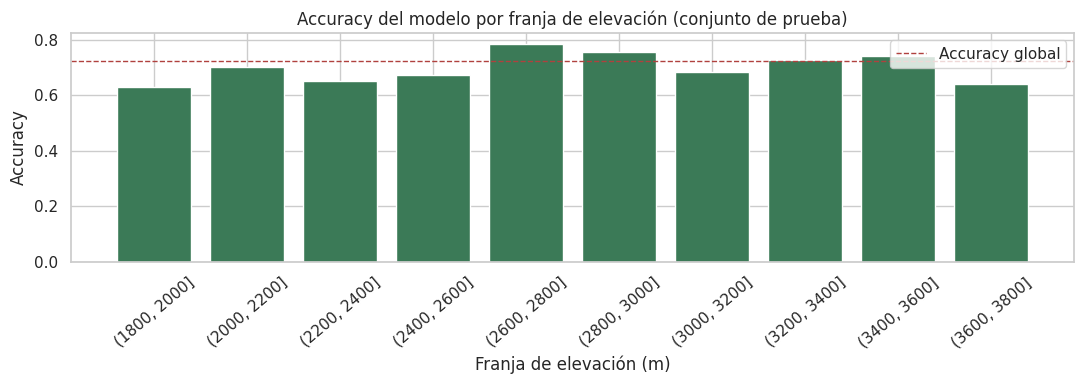

Area,Celdas de prueba,Accuracy,F1 macro (clases presentes)
Rawah,52275,0.758,0.480
Neota,6014,0.634,0.521
Comanche Peak,50577,0.714,0.566
Cache la Poudre,7337,0.628,0.548


In [14]:
area_test = wilderness_label(X_test)
errores = pd.DataFrame({"Area": area_test.values, "Elevacion": X_test["Elevation"].values,
                        "Real": yt, "Pred": pred})
errores["Acierto"] = errores["Real"] == errores["Pred"]
por_area = errores.groupby("Area").apply(
    lambda g: pd.Series({"Celdas de prueba": len(g), "Accuracy": g["Acierto"].mean(),
                         "F1 macro (clases presentes)": f1_score(g["Real"], g["Pred"], average="macro",
                                                                labels=sorted(g["Real"].unique()), zero_division=0)})
).loc[list(WILD_NAMES.values())]
por_area["Celdas de prueba"] = por_area["Celdas de prueba"].astype(int)

errores["Franja de elevación"] = pd.cut(errores["Elevacion"], bins=range(1800, 4000, 200))
por_elev = errores.groupby("Franja de elevación").agg(Celdas=("Acierto", "size"), Accuracy=("Acierto", "mean"))
por_elev = por_elev[por_elev["Celdas"] > 50]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(por_elev.index.astype(str), por_elev["Accuracy"], color="#3b7a57")
ax.axhline(errores["Acierto"].mean(), color="#b0413e", ls="--", lw=1, label="Accuracy global")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Franja de elevación (m)")
ax.set_title("Accuracy del modelo por franja de elevación (conjunto de prueba)")
ax.tick_params(axis="x", rotation=40)
ax.legend()
plt.tight_layout()
plt.show()
por_area.round(3)

Los errores **no se distribuyen de forma homogénea**:

- **Por área**, el *accuracy* va de 0,76 en Rawah a 0,63 en Neota y Cache la Poudre. Las áreas pequeñas, con menos peso en el ajuste, tienen peor desempeño.
- **Por elevación**, el *accuracy* es más alto entre 2.600 y 3.000 m (0,75–0,78), donde domina el pino lodgepole, y más bajo en los extremos del gradiente: 0,62–0,65 por debajo de 2.400 m, donde se mezclan el pino ponderosa, el abeto de Douglas y el álamo/sauce, y 0,64 por encima de 3.600 m, donde el *krummholz* se confunde con el abeto/pícea.

Este patrón es el equivalente, en estos datos, a residuos con dependencia estructural: el modelo comete errores sistemáticos en ciertas zonas y franjas de altitud, lo que indica que el efecto de las variables cambia según la ubicación y requeriría interacciones o un modelo no lineal.

## 3.8 Sensibilidad a la partición: generalización a áreas no vistas

Como prueba de sensibilidad espacial (sección 2.7), se evalúa el modelo con `GroupKFold` dejando fuera un área silvestre completa en cada pliegue. Por costo computacional, se usa una submuestra estratificada de 60.000 celdas del entrenamiento.

In [15]:
X_g, y_g = stratified_sample(X_train, y_train, 60000)
grupos = wilderness_label(X_g)
filas = []
modelo_g = build_logreg(engineered=MEJOR_ENG, C=MEJOR_C, class_weight=MEJOR_CW, max_iter=3000)
for tr, te in GroupKFold(n_splits=4).split(X_g, y_g, grupos):
    area_fuera = grupos.iloc[te].iloc[0]
    modelo_g.fit(X_g.iloc[tr], y_g.iloc[tr])
    p = modelo_g.predict(X_g.iloc[te])
    clases_no_vistas = sorted(set(y_g.iloc[te]) - set(y_g.iloc[tr]))
    filas.append({
        "Área evaluada (no vista)": area_fuera,
        "Celdas": len(te),
        "Accuracy": accuracy_score(y_g.iloc[te], p),
        "F1 macro (clases presentes)": f1_score(y_g.iloc[te], p, average="macro",
                                                 labels=sorted(y_g.iloc[te].unique()), zero_division=0),
        "Clases del área nunca vistas en entrenamiento": ", ".join(CLASS_SHORT[k] for k in clases_no_vistas) or "Ninguna",
    })
loao = pd.DataFrame(filas).set_index("Área evaluada (no vista)").round(3)
display(loao)
print(f"Accuracy promedio dejando un área fuera: {loao['Accuracy'].mean():.3f} "
      f"(frente a {res_test['Regresión logística']['Accuracy']:.3f} con partición estratificada aleatoria)")

Área evaluada (no vista),Celdas,Accuracy,F1 macro (clases presentes),Clases del área nunca vistas en entrenamiento
Rawah,26955,0.585,0.373,Ninguna
Comanche Peak,26166,0.572,0.375,Ninguna
Cache la Poudre,3814,0.530,0.389,4 Álamo/sauce
Neota,3065,0.563,0.429,Ninguna


Accuracy promedio dejando un área fuera: 0.562 (frente a 0.724 con partición estratificada aleatoria)


Cuando el modelo debe predecir un área que nunca vio, el *accuracy* promedio cae de 0,72 a 0,56, y el descenso afecta a todas las áreas: el valor va de 0,58 en Rawah a 0,53 en Cache la Poudre, con un F1 macro de las clases presentes entre 0,37 y 0,43. Cache la Poudre es el caso extremo: al dejar fuera Cache la Poudre, el modelo nunca ve el álamo/sauce, que solo existe allí, y tampoco ve la mayor parte de los ejemplos de pino ponderosa y abeto de Douglas. Esto confirma dos cosas:

1. La partición estratificada aleatoria mide bien el desempeño **dentro de las áreas muestreadas**, que es el objetivo del proyecto, pero es optimista para zonas geográficas nuevas.
2. El modelo aprovecha el área silvestre y los suelos específicos de cada área como información geográfica. Para usarlo fuera del Roosevelt National Forest haría falta muestrear otras regiones.

## 3.9 Curva de aprendizaje

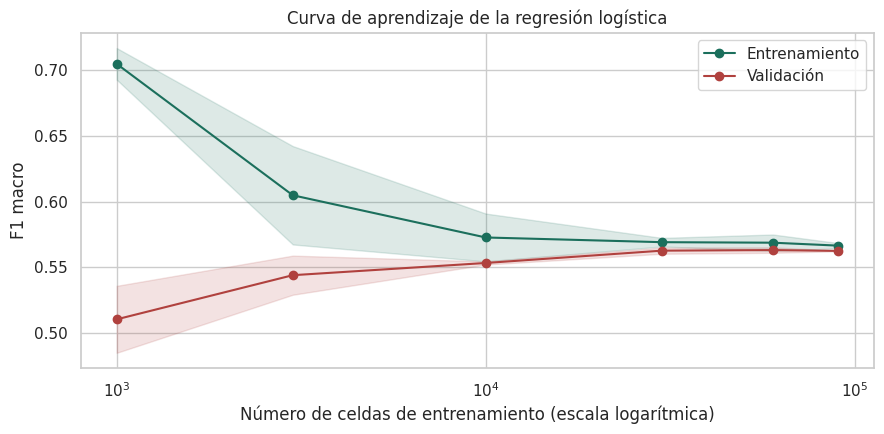

Tamaño,1000,3000,10000,30000,60000,90000
F1 entrenamiento,0.7048,0.6049,0.5728,0.5692,0.5688,0.5666
F1 validación,0.5105,0.5441,0.5534,0.5628,0.5632,0.5626


In [16]:
X_lc, y_lc = stratified_sample(X_train, y_train, 120000)
tamanos, sc_train, sc_val = learning_curve(
    build_logreg(engineered=MEJOR_ENG, C=MEJOR_C, class_weight=MEJOR_CW, max_iter=3000),
    X_lc, y_lc, train_sizes=[1000, 3000, 10000, 30000, 60000, 90000],
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro", n_jobs=-1, shuffle=True, random_state=RANDOM_STATE,
)
fig, ax = plt.subplots(figsize=(9, 4.5))
for sc, nombre, color in [(sc_train, "Entrenamiento", "#1b6f5c"), (sc_val, "Validación", "#b0413e")]:
    ax.plot(tamanos, sc.mean(axis=1), "o-", color=color, label=nombre)
    ax.fill_between(tamanos, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=0.15)
ax.set_xscale("log")
ax.set_xlabel("Número de celdas de entrenamiento (escala logarítmica)")
ax.set_ylabel("F1 macro")
ax.set_title("Curva de aprendizaje de la regresión logística")
ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({"Tamaño": tamanos, "F1 entrenamiento": sc_train.mean(axis=1),
              "F1 validación": sc_val.mean(axis=1)}).set_index("Tamaño").round(4).T

Con 1.000 observaciones el modelo sobreajusta (F1 de 0,71 en entrenamiento frente a 0,51 en validación), pero las dos curvas convergen rápidamente y a partir de unas 30.000 celdas son prácticamente planas y coincidentes (0,570 frente a 0,564). Dos conclusiones:

- **El tamaño de muestra es más que suficiente** para la regresión logística: agregar datos no mejoraría el modelo. Esto justifica también haber hecho la búsqueda de hiperparámetros con una submuestra de 30.000 celdas.
- **No hay sobreajuste**; la limitación del modelo es de **sesgo**. Las dos curvas convergen en un F1 macro cercano a 0,56, muy por debajo de lo que permitiría la señal disponible (sección 3.11). Para mejorar se necesitan modelos más flexibles, no más datos.

## 3.10 Interpretación de los coeficientes

En la regresión logística multinomial cada clase tiene su propio vector de coeficientes. Como las variables numéricas están estandarizadas, cada coeficiente numérico indica cuánto cambia el logaritmo de la razón de probabilidades (*log-odds*) de la clase cuando la variable aumenta una desviación estándar, manteniendo las demás constantes. Las indicadoras de área y suelo se interpretan respecto al promedio de las demás categorías, porque se incluyen todas sin categoría de referencia.

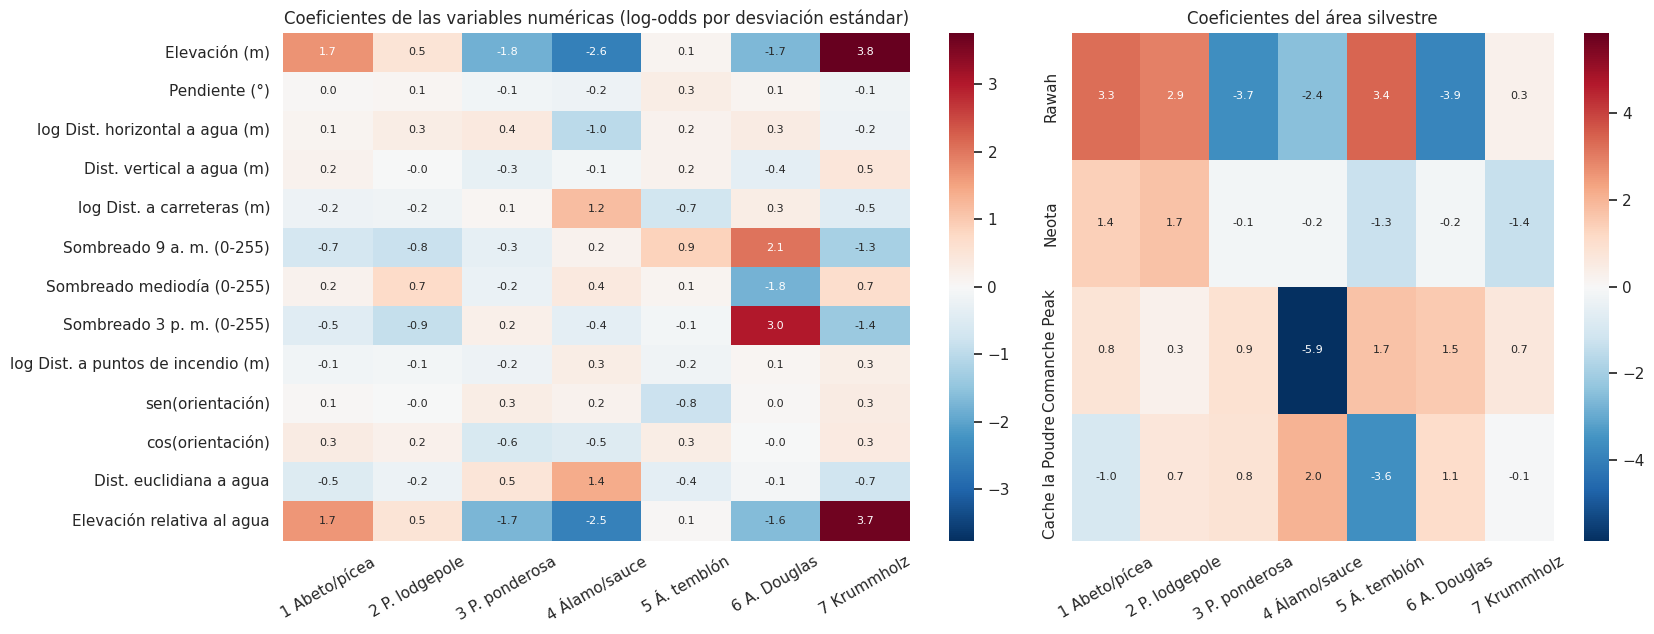

In [17]:
clf = modelo.named_steps["clf"]
nombres = modelo.named_steps["prep"][-1].get_feature_names_out() if MEJOR_ENG else modelo.named_steps["prep"].get_feature_names_out()
nombres = [n.split("__", 1)[1] for n in nombres]
coef = pd.DataFrame(clf.coef_.T, index=nombres, columns=[CLASS_SHORT[k] for k in clf.classes_])

numericas = [c for c in coef.index if c not in SOIL_COLS + WILD_COLS]
nombres_legibles = {**DISPLAY_NAMES, "Aspect_sin": "sen(orientación)", "Aspect_cos": "cos(orientación)",
                    "Dist_Hydrology_Euclid": "Dist. euclidiana a agua", "Elevation_Minus_VDH": "Elevación relativa al agua"}
if MEJOR_ENG:
    nombres_legibles.update({c: f"log {DISPLAY_NAMES[c]}" for c in ["Horizontal_Distance_To_Hydrology",
                             "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points"]})

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
lim = np.abs(coef.loc[numericas]).max().max()
sns.heatmap(coef.loc[numericas].rename(index=nombres_legibles), annot=True, fmt=".1f", cmap="RdBu_r",
            center=0, vmin=-lim, vmax=lim, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("Coeficientes de las variables numéricas (log-odds por desviación estándar)")
areas_coef = coef.loc[WILD_COLS].rename(index={c: WILD_NAMES[i + 1] for i, c in enumerate(WILD_COLS)})
lim2 = np.abs(areas_coef).max().max()
sns.heatmap(areas_coef, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-lim2, vmax=lim2, ax=axes[1], annot_kws={"size": 8})
axes[1].set_title("Coeficientes del área silvestre")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [18]:
# Un aumento de 100 m en la altitud del terreno, con la distancia vertical al agua fija,
# incrementa en 100 m tanto la elevación como la elevación relativa al agua. Como ambas
# están casi perfectamente correlacionadas, el efecto interpretable es el conjunto.
escalador = modelo.named_steps["prep"][-1].named_transformers_["num"]
sd = dict(zip(escalador.feature_names_in_, escalador.scale_))
b_elev = coef.loc["Elevation"]
b_rel = coef.loc["Elevation_Minus_VDH"] if "Elevation_Minus_VDH" in coef.index else 0 * b_elev
log_odds_100 = b_elev * 100 / sd["Elevation"] + (b_rel * 100 / sd["Elevation_Minus_VDH"] if "Elevation_Minus_VDH" in sd else 0)
pd.DataFrame(
    {
        "Coef. elevación (por 1 DE)": b_elev.round(2),
        "Coef. elevación relativa (por 1 DE)": b_rel.round(2),
        "Razón de odds aislada por +100 m (solo elevación)": np.exp(b_elev * 100 / sd["Elevation"]).round(3),
        "Razón de odds conjunta por +100 m": np.exp(log_odds_100).round(3),
    }
)

,Coef. elevación (por 1 DE),Coef. elevación relativa (por 1 DE),Razón de odds aislada por +100 m (solo elevación),Razón de odds conjunta por +100 m
1 Abeto/pícea,1.69,1.65,1.828,3.294
2 P. lodgepole,0.52,0.53,1.205,1.454
3 P. ponderosa,-1.80,-1.73,0.527,0.284
4 Álamo/sauce,-2.57,-2.54,0.400,0.162
5 Á. temblón,0.09,0.06,1.034,1.055
6 A. Douglas,-1.71,-1.63,0.544,0.305
7 Krummholz,3.76,3.66,3.836,14.124


**Interpretación:**

- **La elevación domina el modelo** y reproduce el gradiente altitudinal, pero su
  coeficiente no puede leerse de forma aislada. La elevación relativa al agua está
  correlacionada casi por completo con ella (difieren solo en la distancia vertical al
  agua, pequeña frente a la altitud), de modo que "aumentar la elevación manteniendo
  constantes las demás variables" no describe una situación real: si el terreno sube
  100 m, ambas variables aumentan 100 m. El modelo reparte el efecto altitudinal casi a
  partes iguales entre las dos, y el efecto interpretable es el **conjunto**. Sumando
  ambos coeficientes por desviación estándar, el efecto es positivo en el extremo alto
  (*krummholz*: 3,76 + 3,66 ≈ 7,4; abeto/pícea: 1,69 + 1,65 ≈ 3,3) y negativo en el
  bajo (álamo/sauce: −2,57 − 2,54 ≈ −5,1; pino ponderosa: −1,80 − 1,73 ≈ −3,5; abeto de
  Douglas: −1,71 − 1,63 ≈ −3,3).
- **La lectura aislada de la razón de *odds* subestima el efecto altitudinal.** La tabla
  anterior compara la razón de *odds* por cada 100 m calculada solo con el coeficiente de
  la elevación con la razón de *odds* conjunta, que combina ambos coeficientes en sus
  escalas originales. Por cada 100 m adicionales de altitud, las *odds* del *krummholz* se
  multiplican por 14,1, y no por 3,8 como sugiere la lectura aislada; las del abeto/pícea,
  por 3,3 en lugar de 1,8. En el extremo bajo, las del álamo/sauce se reducen a 0,16 veces
  su valor (frente a 0,40 en la lectura aislada) y las del pino ponderosa, a 0,28 veces
  (frente a 0,53). Ignorar la colinealidad llevaría, por tanto, a estimar en escala de *log-odds*
  solo la mitad de la intensidad real del gradiente altitudinal.
- **El área silvestre** actúa como ajuste regional. Cache la Poudre tiene coeficientes positivos grandes para el álamo/sauce (3,6), el pino ponderosa y el abeto de Douglas, lo que refleja el proxy geográfico identificado en la auditoría de fuga. Rawah tiene un coeficiente alto para el álamo temblón (3,2), que es más frecuente allí que en las demás áreas.
- **Los índices de sombreado** tienen coeficientes grandes y de signos opuestos para el abeto de Douglas (2,0 a las 9 a. m., −1,7 al mediodía y 2,9 a las 3 p. m.). Es el síntoma típico de la colinealidad detectada en la sección 2.3: los coeficientes se compensan entre sí y no deben interpretarse de forma aislada.
- **Las distancias a carreteras, agua y puntos de incendio** tienen coeficientes pequeños en la mayoría de las clases, con la excepción del álamo/sauce, cuya probabilidad aumenta con la distancia euclidiana al agua (1,4) y con la distancia a carreteras (1,2) cuando las demás variables se mantienen constantes. Como estas variables también están correlacionadas entre sí, estos efectos parciales deben tomarse con cautela.

## 3.11 Revisión crítica del desempeño

El modelo base obtiene un *accuracy* cercano al 72 %, por debajo del rango de 80–90 % a partir del cual un desempeño alto obliga a sospechar de fuga de información o de un problema trivial. Aun así, se revisaron los puntos de control correspondientes:

1. **Fuga de información.** La auditoría de la sección 2.5 no encontró identificadores, variables derivadas del objetivo ni variables posteriores a la predicción. Las predictoras con AUC univariado superior a 0,95 tienen una explicación ecológica directa.
2. **Comparación con la línea base.** La mejora sobre el `DummyClassifier` es sustancial en todas las métricas, incluidas las que dan el mismo peso a todas las clases.
3. **Estructura espacial.** La validación por área silvestre muestra que el desempeño baja para zonas no vistas; el resultado principal se interpreta como desempeño dentro de las áreas muestreadas.
4. **Complejidad del problema.** Para confirmar que el problema no es trivial pero sí tiene margen de mejora, se estima como referencia un modelo no lineal (*gradient boosting* basado en histogramas (Ke et al., 2017)) con la misma validación cruzada. No forma parte del modelo base; solo indica cuánta señal queda sin aprovechar.

In [19]:
hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
cv_hgb = cross_validate(hgb, X_cv, y_cv, cv=cv5, n_jobs=-1, scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"})
referencia = pd.DataFrame(
    {
        "Accuracy (validación cruzada)": [resumen_cv.loc["Accuracy", "Validación (media)"], cv_hgb["test_accuracy"].mean()],
        "F1 macro (validación cruzada)": [resumen_cv.loc["F1 macro", "Validación (media)"], cv_hgb["test_f1_macro"].mean()],
    },
    index=["Regresión logística (modelo base)", "Gradient boosting (referencia no lineal)"],
).round(3)
referencia

,Accuracy (validación cruzada),F1 macro (validación cruzada)
Regresión logística (modelo base),0.727,0.565
Gradient boosting (referencia no lineal),0.814,0.739


Con los mismos datos y la misma validación, un modelo no lineal sin ajuste de hiperparámetros alcanza 0,81 de *accuracy* y 0,74 de F1 macro, frente a 0,73 y 0,56 de la regresión logística. Esto confirma que el problema **no es trivial para un modelo lineal** y que la señal disponible permite mejoras sustanciales con modelos más flexibles, lo que motiva el benchmark de la Parte II. Al mismo tiempo, cualquier modelo que supere el 90 % de *accuracy* debe someterse de nuevo a la revisión de fuga y a la validación por área; el modelo finalista de la Parte II se somete a esa revisión en la sección 9.4.

# 4. Conclusiones de la Parte I

## 4.1 Hallazgos principales

**Sobre la base de datos.** El conjunto *Covertype* cumple los requisitos de tamaño (581.012 celdas y 54 predictoras), calidad (sin faltantes, sin duplicados, sin valores imposibles ni códigos centinela) y licencia de uso (CC BY 4.0). Su principal característica es el desbalance: la clase mayoritaria (pino lodgepole) es 103 veces más frecuente que la minoritaria (álamo/sauce).

**Sobre el análisis exploratorio.**

1. **La elevación es la variable dominante.** Explica cerca de la mitad de la variabilidad entre clases (ε² = 0,51) y reproduce el gradiente altitudinal de la vegetación de montaña: el álamo/sauce y el pino ponderosa en las zonas bajas y el abeto/pícea y el *krummholz* cerca del límite superior del bosque.
2. **El área silvestre y el tipo de suelo están fuertemente asociados con la cobertura** (V de Cramér de 0,44 y 0,47) y entre sí (V = 0,69). Algunas clases están confinadas a un área: el álamo/sauce solo existe en Cache la Poudre.
3. **La iluminación forma un bloque redundante.** Los tres índices de sombreado dependen de la orientación y la pendiente, tienen VIF entre 38 y 144 y una asociación despreciable con la cobertura.
4. **Las dos clases mayoritarias se superponen** en todas las variables, y los datos no presentan grupos naturales que coincidan con la cobertura (ARI menor a 0,04). Las fronteras entre clases son no lineales.
5. **Los valores atípicos son legítimos** y se concentran en las clases de los extremos del gradiente altitudinal, por lo que se conservaron.

**Sobre la fuga de información y la estructura.** No hay identificadores, variables derivadas del objetivo ni variables posteriores a la predicción. La elevación y el área de Cache la Poudre superan un AUC univariado de 0,95 para algunas clases, pero por razones ecológicas y geográficas legítimas; quedan en observación. Los datos no tienen componente temporal ni coordenadas, y la dependencia espacial se evaluó a través del área silvestre.

**Sobre el modelo base.** La regresión logística multinomial, con ingeniería de variables y sin ponderación de clases, obtuvo en el conjunto de prueba:

| Métrica | Dummy (más frecuente) | Regresión logística | IC 95 % |
|---|---|---|---|
| Accuracy | 0,488 | 0,724 | 0,722–0,727 |
| Exactitud balanceada | 0,143 | 0,532 | 0,525–0,539 |
| F1 macro | 0,094 | 0,558 | 0,551–0,565 |
| AUC OvR macro | 0,500 | 0,937 | 0,936–0,938 |

El modelo supera ampliamente a la línea base trivial, está muy bien calibrado y no presenta sobreajuste: las métricas de entrenamiento, validación cruzada y prueba coinciden, y la curva de aprendizaje se estabiliza a partir de unas 30.000 celdas. Su limitación es de **sesgo**. No reconoce el álamo temblón (*recall* de 0,04), confunde el abeto/pícea con el pino lodgepole y comete más errores en los extremos del gradiente altitudinal. Un modelo no lineal de referencia alcanza 0,81 de *accuracy* y 0,74 de F1 macro con los mismos datos, lo que confirma que el problema no es trivial y que existe un margen amplio de mejora, que la Parte II cuantifica de forma sistemática.

## 4.2 Limitaciones

- **Representatividad geográfica.** Los datos cubren cuatro áreas silvestres del norte de Colorado con poca intervención humana. Cuando se deja fuera un área completa, el *accuracy* cae a 0,56 en promedio (0,53 para Cache la Poudre), de modo que el modelo no debe aplicarse a otras regiones sin datos locales.
- **Ausencia de coordenadas.** No fue posible medir la autocorrelación espacial (I de Moran, semivariogramas) ni construir bloques espaciales finos. La partición aleatoria puede ser ligeramente optimista incluso dentro de las áreas muestreadas.
- **Antigüedad de los datos.** La cartografía es anterior a 1998 y no refleja cambios posteriores por incendios, plagas o cambio climático.
- **Calidad de las etiquetas.** La cobertura proviene de un sistema de información del USFS, no de un inventario de campo celda por celda, y algunas unidades de suelo podrían incorporar información de la vegetación en su definición.
- **Compromiso entre clases.** Con la ponderación de clases el *recall* de las clases minoritarias mejora mucho (por ejemplo, el del álamo temblón pasa de 0,04 a 0,79), a costa del *accuracy* global. La Parte II resuelve este compromiso con el F1 macro como criterio de selección y con modelos no lineales capaces de reconocer las clases minoritarias sin sacrificar las mayoritarias.


# 5. Benchmark combinatorio de modelos

La Parte I estableció que la regresión logística multinomial alcanza un F1 macro de 0,558
en la prueba reservada y que su limitación es de sesgo, no de varianza (sección 3.9). Esta
parte del documento aborda la pregunta que se deriva de ese diagnóstico: **¿qué familia de
modelos, qué estrategia de balanceo de clases y qué método de optimización de
hiperparámetros permiten superar ese desempeño de forma estadística y prácticamente
significativa?**

Para responderla se construye un diseño factorial completo de **7 algoritmos × 4
estrategias de balanceo × 4 métodos de optimización = 112 combinaciones**. Cada
combinación se entrena y se evalúa de forma independiente mediante validación cruzada
anidada, y todas comparten la partición, la semilla y el preprocesamiento de la Parte I.
Como *Covertype* no contiene una variable respuesta continua, el estudio se restringe a la
rama de clasificación; la regresión no tiene un objetivo natural en este conjunto de datos.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import _utils3 as u3

sns.set_theme(style="whitegrid", context="notebook")
RESULTS3 = Path.cwd().parent / "resultados"
tabla = pd.read_csv(RESULTS3 / "tabla_maestra.csv", encoding="utf-8-sig")
tabla["f1_macro_pliegues"] = tabla["f1_macro_pliegues"].apply(
    lambda s: json.loads(s) if isinstance(s, str) else s
)
print(f"Combinaciones registradas: {len(tabla)} de 112")
print(f"Aplicables: {int(tabla['aplicable'].sum())} · "
      f"No aplicables (balanceo no soportado por el algoritmo): {int((~tabla['aplicable']).sum())}")

Combinaciones registradas: 112 de 112
Aplicables: 108 · No aplicables (balanceo no soportado por el algoritmo): 4


## 5.1 Diseño experimental

### Métrica principal de validación

El criterio de selección en todas las etapas es el **F1 macro**, es decir, la media no
ponderada del F1 de las siete clases. La elección responde a la estructura del problema:
con una razón de desbalance de 103:1 (sección 1.7), la *accuracy* está dominada por las
dos clases mayoritarias, que suman el 85 % de las celdas, y puede mejorar aunque el modelo
ignore por completo las clases raras. Esto fue lo que ocurrió con la regresión logística,
que alcanzó 0,72 de *accuracy* con un *recall* de 0,04 en el álamo temblón (sección 3.5).
El F1 macro asigna el mismo peso a cada clase y penaliza tanto los falsos positivos como
los falsos negativos, lo que lo hace adecuado para un inventario forestal en el que omitir
un ecosistema raro y sobrestimarlo son errores de costo comparable. La *accuracy*, la
exactitud balanceada, el AUC uno-contra-el-resto y el *log loss* se reportan como métricas
complementarias.

### Validación cruzada anidada

Seleccionar hiperparámetros y estimar el desempeño con los mismos pliegues produce una
estimación optimista, conocida como sesgo de selección del modelo (Cawley y Talbot, 2010; Varma y Simon, 2006). Para evitarlo, cada combinación se
evalúa con dos bucles:

- **Bucle externo (3 pliegues estratificados):** estima el desempeño de generalización.
  Cada pliegue externo deja fuera un tercio de la submuestra, que no interviene en la
  búsqueda de hiperparámetros.
- **Bucle interno (3 pliegues estratificados):** dentro de cada partición de entrenamiento
  externa, ejecuta el método de optimización completo y elige la configuración con mayor
  F1 macro medio.

Todas las métricas que se reportan en los capítulos 5 a 7 provienen del bucle externo.
El preprocesamiento (ingeniería de variables, escalado y, cuando corresponde, SMOTE o
ADASYN) se encapsula en un `Pipeline` de scikit-learn o de imbalanced-learn y se ajusta
dentro de cada pliegue, de modo que ninguna observación de validación interviene en el
ajuste de las transformaciones ni en la generación de muestras sintéticas.

**Número de pliegues.** Con tres pliegues externos e internos, cada evaluación interna se
entrena con unas 17.800 celdas y se valida con unas 8.900. En consecuencia, la clase menos
frecuente (álamo/sauce, 0,47 %) aporta alrededor de 40 observaciones a cada partición de
validación interna, suficientes para estimar su F1. Con cinco o diez pliegues, el número
de ajustes se multiplicaría por un factor de 2,8 a 11 sin una ganancia proporcional en la
precisión de la estimación, porque el error de muestreo del F1 macro entre pliegues ya es
del orden de 0,005 (sección 5.4). La contrapartida es que tres pliegues externos ofrecen
poca potencia a las pruebas no paramétricas sobre rangos, un aspecto que se analiza en el
capítulo 7.

### Submuestra para el benchmark

Entrenar 112 combinaciones con validación anidada sobre las 464.809 filas de
entrenamiento implicaría decenas de miles de ajustes de modelos de conjunto. La curva de
aprendizaje de la sección 3.9 muestra que el F1 macro de validación del modelo lineal se
estabiliza a partir de unas 30.000 celdas; con base en ese resultado, el benchmark se
ejecuta sobre una **submuestra estratificada de 40.000 filas** del conjunto de
entrenamiento (`N_BENCHMARK` en `_utils3.py`). La SVM con núcleo RBF, cuyo costo de
entrenamiento crece entre $O(n^2)$ y $O(n^3)$, se evalúa sobre una submuestra estratificada
de 9.000 filas.

> **Nota.**
> La submuestra modifica únicamente el número de filas de **entrenamiento** empleadas en la
> búsqueda y en la validación anidada. La partición 80/20, la semilla y el preprocesamiento
> son los de la Parte I. El modelo finalista se reentrena con el conjunto de entrenamiento
> completo antes de evaluarse, una sola vez, en la prueba reservada (sección 5.5).

## 5.2 Algoritmos y espacios de búsqueda

Los rangos se fijaron a partir de la escala del problema (57 predictoras tras la
ingeniería de variables, 40.000 filas y 7 clases) y de los resultados de la Parte I, no de
valores arbitrarios. Los parámetros continuos de regularización y suavizado se exploran en
escala logarítmica.

| Algoritmo | Hiperparámetros explorados | Justificación del rango |
|---|---|---|
| KNN (Cover y Hart, 1967) | `n_neighbors` ∈ {5, 11, 21, 41}; `weights` ∈ {uniform, distance} | Valores impares, desde vecindades locales hasta suavizados amplios; la ponderación por distancia favorece la frontera local en las zonas de solapamiento entre clases (sección 2.3) |
| Naive Bayes gaussiano (Hand y Yu, 2001) | `var_smoothing` ∈ [10⁻¹⁰, 10⁻⁶] (log) | Intervalo estándar de suavizado de la varianza, que estabiliza las variables binarias de suelo con varianza casi nula |
| Regresión logística (L1/L2) (Hosmer et al., 2013) | `C` ∈ [0,1; 10] (log); `penalty` ∈ {L1, L2} | Cubre C = 10, el óptimo de la sección 3.3, y C = 1, con un F1 de validación prácticamente idéntico; la penalización L1 permite contrastar la selección implícita de variables frente a la contracción L2 |
| Árbol de decisión (Breiman et al., 1984) | `max_depth` ∈ {5, 10, 20, sin límite}; `min_samples_leaf` ∈ {1, 10, 50} | Desde árboles interpretables hasta árboles completamente desarrollados, con hojas mínimas que controlan el sobreajuste |
| Random Forest | `n_estimators` ∈ {100, 200}; `max_depth` ∈ {10, 20} | Profundidad máxima de 20 para acotar el costo de cada ajuste en la validación anidada; el mismo espacio se usa con las cuatro estrategias de balanceo |
| XGBoost (`hist`) | `n_estimators` ∈ {100, 150}; `max_depth` ∈ {4, 6}; `learning_rate` ∈ [0,05; 0,1] | Árboles poco profundos y tasas de aprendizaje moderadas, el rango habitual del *boosting*; el mismo espacio se usa con las cuatro estrategias de balanceo |
| SVM (núcleo RBF) (Cortes y Vapnik, 1995) | `C` ∈ [0,1; 10] (log); `gamma` ∈ {scale, 0,01, 0,1} | `gamma = "scale"` es la referencia de scikit-learn; los otros dos valores exploran fronteras más y menos suaves |

El presupuesto de cada método por pliegue externo fue el siguiente: Grid Search recorre la
rejilla completa (entre 4 y 12 configuraciones, según el algoritmo, idénticas para todas sus variantes de balanceo); Random Search evalúa 6
configuraciones; la optimización bayesiana, 6 ensayos de Optuna, y el algoritmo genético,
una población de 4 individuos durante 2 generaciones. Estos presupuestos son deliberadamente
pequeños frente a los habituales en la literatura, una restricción impuesta por el costo de
la validación anidada sobre 112 combinaciones en una sola estación de trabajo. Sus
consecuencias se discuten en los capítulos 6 y 9.

## 5.3 Estrategias de balanceo

- **Sin balanceo:** línea base, idéntica al modelo de la Parte I.
- **SMOTE** (Chawla et al., 2002): genera observaciones sintéticas de las clases minoritarias
  por interpolación entre vecinos cercanos, en el espacio de las 57 variables ya
  transformadas.
- **ADASYN** (He et al., 2008): variante adaptativa de SMOTE que genera más observaciones en
  las regiones donde la clase minoritaria es más difícil de aprender, es decir, donde
  predominan los vecinos de otras clases.
- **Ponderación por clase:** `class_weight="balanced"` en los algoritmos que lo admiten
  (regresión logística, árbol, Random Forest y SVM). En XGBoost y Naive Bayes se usa el
  equivalente funcional, `sample_weight`, con pesos inversamente proporcionales a la
  frecuencia de cada clase en el pliegue de entrenamiento. KNN no admite ninguno de los dos
  mecanismos; esas cuatro combinaciones se declaran no aplicables en lugar de forzar una
  aproximación artificial.

In [2]:
no_aplicables = tabla.loc[~tabla["aplicable"], ["modelo_nombre", "balanceo_nombre", "optimizacion_nombre"]]
no_aplicables.columns = ["Algoritmo", "Balanceo", "Optimización"]
display(no_aplicables.style.hide(axis="index"))

Algoritmo,Balanceo,Optimización
K vecinos más cercanos,class_weight / sample_weight balanceado,Grid Search
K vecinos más cercanos,class_weight / sample_weight balanceado,Random Search
K vecinos más cercanos,class_weight / sample_weight balanceado,"Bayesiana (Optuna, TPE)"
K vecinos más cercanos,class_weight / sample_weight balanceado,Genético (DEAP)


## 5.4 Resultados del benchmark

La tabla siguiente resume, para cada par algoritmo–balanceo, el F1 macro medio del bucle
externo, promediado sobre los cuatro métodos de optimización, junto con el mínimo y el
máximo alcanzados.

In [3]:
aplic = tabla[tabla["aplicable"]].copy()
resumen = (aplic.groupby(["modelo_nombre", "balanceo_nombre"])
           .agg(media=("f1_macro_media", "mean"), minimo=("f1_macro_media", "min"),
                maximo=("f1_macro_media", "max"))
           .round(3).sort_values("media", ascending=False))
resumen.index.names = ["Algoritmo", "Balanceo"]
resumen.columns = ["F1 macro medio", "Mínimo", "Máximo"]
display(resumen)

Algoritmo,Balanceo,F1 macro medio,Mínimo,Máximo
Random Forest,SMOTE,0.742,0.618,0.783
Random Forest,class_weight / sample_weight balanceado,0.741,0.641,0.775
K vecinos más cercanos,Sin balanceo (línea base),0.739,0.716,0.746
Random Forest,ADASYN,0.736,0.595,0.783
XGBoost,Sin balanceo (línea base),0.718,0.683,0.746
K vecinos más cercanos,SMOTE,0.713,0.706,0.716
Árbol de decisión,Sin balanceo (línea base),0.710,0.682,0.722
Random Forest,Sin balanceo (línea base),0.708,0.583,0.750
K vecinos más cercanos,ADASYN,0.703,0.695,0.705
Árbol de decisión,SMOTE,0.692,0.667,0.707


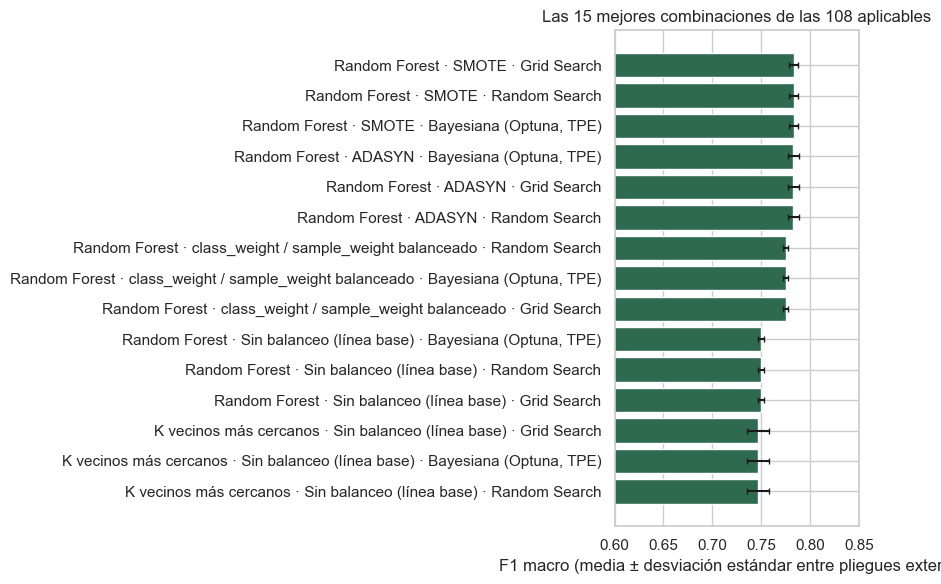

In [4]:
top15 = aplic.sort_values("f1_macro_media", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 6))
etiquetas = top15["modelo_nombre"] + " · " + top15["balanceo_nombre"] + " · " + top15["optimizacion_nombre"]
ax.barh(etiquetas, top15["f1_macro_media"], xerr=top15["f1_macro_sd"], color="#2d6a4f", capsize=2)
ax.set_xlabel("F1 macro (media ± desviación estándar entre pliegues externos)")
ax.set_title("Las 15 mejores combinaciones de las 108 aplicables")
ax.set_xlim(0.6, 0.85)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
mejor = aplic.loc[aplic["f1_macro_media"].idxmax()]
base_lr = aplic[(aplic["modelo"] == "LR") & (aplic["balanceo"] == "ninguno")]["f1_macro_media"].max()
print(f"Mejor combinación: {mejor['modelo_nombre']} · {mejor['balanceo_nombre']} · {mejor['optimizacion_nombre']}")
print(f"F1 macro (bucle externo) = {mejor['f1_macro_media']:.4f} ± {mejor['f1_macro_sd']:.4f}")
print(f"Regresión logística sin balanceo (misma submuestra): {base_lr:.4f}")
print(f"Diferencia absoluta: {mejor['f1_macro_media'] - base_lr:+.4f}")

Mejor combinación: Random Forest · SMOTE · Grid Search
F1 macro (bucle externo) = 0.7831 ± 0.0045
Regresión logística sin balanceo (misma submuestra): 0.5636
Diferencia absoluta: +0.2195


Los resultados, obtenidos con el mismo espacio de búsqueda y el mismo presupuesto para las 112
combinaciones, permiten cuatro observaciones:

1. **Los métodos de conjunto basados en árboles y los vecinos dominan la clasificación.** Random Forest
   (Breiman, 2001) con SMOTE (0,783) ocupa el primer lugar, seguido de K vecinos (0,746), XGBoost
   (Chen y Guestrin, 2016) (0,746) y el árbol de decisión individual (0,722). La regresión logística (0,564) y Naive
   Bayes (0,224) quedan al final. Esto confirma que las fronteras entre clases son no lineales y que el
   supuesto de independencia condicional de Naive Bayes no es compatible con la fuerte dependencia entre
   elevación, área silvestre y tipo de suelo (sección 2.3).
2. **El efecto del balanceo depende del algoritmo.** En Random Forest, SMOTE y ADASYN elevan el F1 macro en
   0,033 y los pesos de clase en 0,025 frente a no balancear. En XGBoost, las tres estrategias lo reducen entre
   0,023 y 0,040. El sobremuestreo ayuda a un bosque de árboles profundos a definir regiones para las clases
   raras, mientras que en el *boosting* desplaza las fronteras de las clases mayoritarias.
3. **La variabilidad entre pliegues es pequeña.** La desviación estándar del F1 macro entre pliegues externos se
   mantiene alrededor de 0,01 o por debajo en las combinaciones mejor clasificadas, de modo que las diferencias
   de varias centésimas entre familias de algoritmos superan con amplitud la variabilidad intrínseca de cada
   combinación.
4. **Varias combinaciones empatan exactamente.** Por ejemplo, Random Forest con SMOTE alcanza el mismo F1
   macro con Grid, Random y Bayesiano, porque en un espacio discreto de cuatro configuraciones los tres métodos
   convergen a la misma solución. Este fenómeno condiciona la comparación entre optimizadores del capítulo 6.

La diferencia entre el mejor modelo y la regresión logística es una estimación puntual. Su significancia
estadística y su tamaño de efecto se evalúan en el capítulo 7, y con 30 pliegues en el capítulo 12.

## 5.5 Modelo finalista reentrenado con el conjunto completo

El finalista del benchmark es **Random Forest con SMOTE** (`n_estimators = 200`,
`max_depth = 20`, la configuración más frecuente entre los tres pliegues externos). Se reentrena con las
**464.809 filas de entrenamiento** (con SMOTE, cerca de 1,6 millones de filas tras el sobremuestreo) y se
evalúa **una sola vez** sobre las 116.203 filas de la prueba reservada en la sección 1.6.

In [6]:
with open(RESULTS3 / "resumen_finalista.json", encoding="utf-8") as f:
    resumen_final = json.load(f)

print(f"Finalista: {resumen_final['finalista']} · hiperparámetros: {resumen_final['hiperparametros']}")
print(f"F1 macro en la prueba reservada (finalista, entrenamiento completo): {resumen_final['f1_macro_finalista']:.4f}")
print(f"F1 macro en la prueba reservada (regresión logística): {resumen_final['f1_macro_referencia']:.4f}")
print(f"Diferencia absoluta: {resumen_final['ganancia_absoluta']:+.4f}")

Finalista: RF_smote · hiperparámetros: {'n_estimators': 200, 'max_depth': 20}
F1 macro en la prueba reservada (finalista, entrenamiento completo): 0.8655
F1 macro en la prueba reservada (regresión logística): 0.5572
Diferencia absoluta: +0.3083


El F1 macro sube de 0,783 en la submuestra a **0,866** con el conjunto completo. Con 11,6 veces más datos de
entrenamiento, el álamo/sauce pasa de unas 190 observaciones en la submuestra a unas 2.200, y el álamo
temblón, de unas 650 a unas 7.600. A diferencia de la regresión logística, cuya curva de aprendizaje se aplana
a partir de 30.000 celdas (sección 3.9), un bosque de árboles profundos aprovecha esa información adicional.
Por la misma razón, la estimación del bucle externo debe interpretarse como un **límite inferior** del
desempeño alcanzable con el conjunto completo.

In [7]:
delong = pd.read_csv(RESULTS3 / "delong_finalistas.csv", encoding="utf-8-sig")
delong["clase"] = delong["clase"].map(u3.CLASS_SHORT)
delong.round(4)

,clase,auc_finalista,auc_referencia,delta_auc,z,p_valor,p_holm
0,1 Abeto/pícea,0.9805,0.8579,0.1225,131.1560,0.0,0.0
1,2 P. lodgepole,0.9761,0.8492,0.1269,112.1742,0.0,0.0
2,3 P. ponderosa,0.9986,0.9865,0.0121,60.4336,0.0,0.0
3,4 Álamo/sauce,0.9997,0.9974,0.0023,11.9342,0.0,0.0
4,5 Á. temblón,0.9966,0.9180,0.0787,31.9767,0.0,0.0
5,6 A. Douglas,0.9976,0.9717,0.0259,51.2981,0.0,0.0
6,7 Krummholz,0.9996,0.9801,0.0195,29.7970,0.0,0.0


La prueba de DeLong (DeLong et al., 1988) compara, clase por clase (uno contra el resto), el AUC del finalista
reentrenado con el conjunto completo con el de la regresión logística de referencia. La diferencia es
significativa en las siete clases tras la corrección de Holm. Es mayor en las dos clases mayoritarias
(abeto/pícea y pino lodgepole), que el modelo lineal apenas separaba entre sí.

## 5.6 Evaluación de los modelos en la prueba reservada

Para la comparación con el modelo original (capítulos 11 y 12), los siete modelos se reentrenaron con la
submuestra de 40.000 celdas del benchmark, con la mejor combinación de cada uno, de modo que todos se comparan
con los mismos datos. La tabla resume su desempeño en la prueba reservada.

In [8]:
E3 = RESULTS3 / "e3"
hold = {r["modelo"]: r for r in json.load(open(E3 / "holdout_resumen.json", encoding="utf-8"))}
tabla_h = pd.DataFrame([{"Modelo": r["nombre"], "Balanceo": r.get("balanceo"), "Optimización": r.get("optimizacion"),
                         "F1 macro": r["prueba_reservada"]["f1_macro"], "Accuracy": r["prueba_reservada"]["accuracy"],
                         "Exactitud balanceada": r["prueba_reservada"]["exactitud_balanceada"],
                         "Log loss": r["prueba_reservada"]["log_loss"]}
                        for m, r in hold.items() if m not in ("ECLC", "HGB")]).sort_values("F1 macro", ascending=False)
tabla_h.round(3)

,Modelo,Balanceo,Optimización,F1 macro,Accuracy,Exactitud balanceada,Log loss
4,Random Forest,smote,grid,0.793,0.851,0.835,0.426
0,K vecinos más cercanos,ninguno,random,0.766,0.843,0.747,1.250
5,XGBoost,ninguno,random,0.752,0.822,0.715,0.428
3,Árbol de decisión,ninguno,bayes,0.741,0.829,0.742,5.904
6,SVM (núcleo RBF),smote,grid,0.635,0.765,0.599,0.709
2,Regresión logística (L1/L2),ninguno,grid,0.562,0.723,0.536,0.630
1,Naive Bayes gaussiano,smote,random,0.231,0.223,0.541,23.569


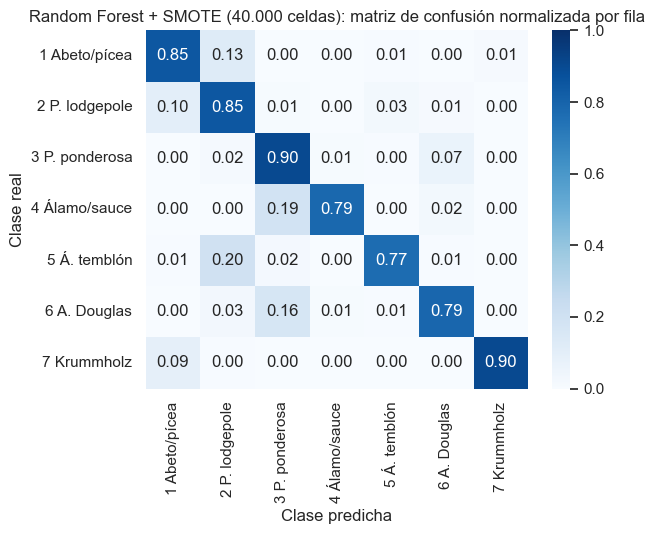

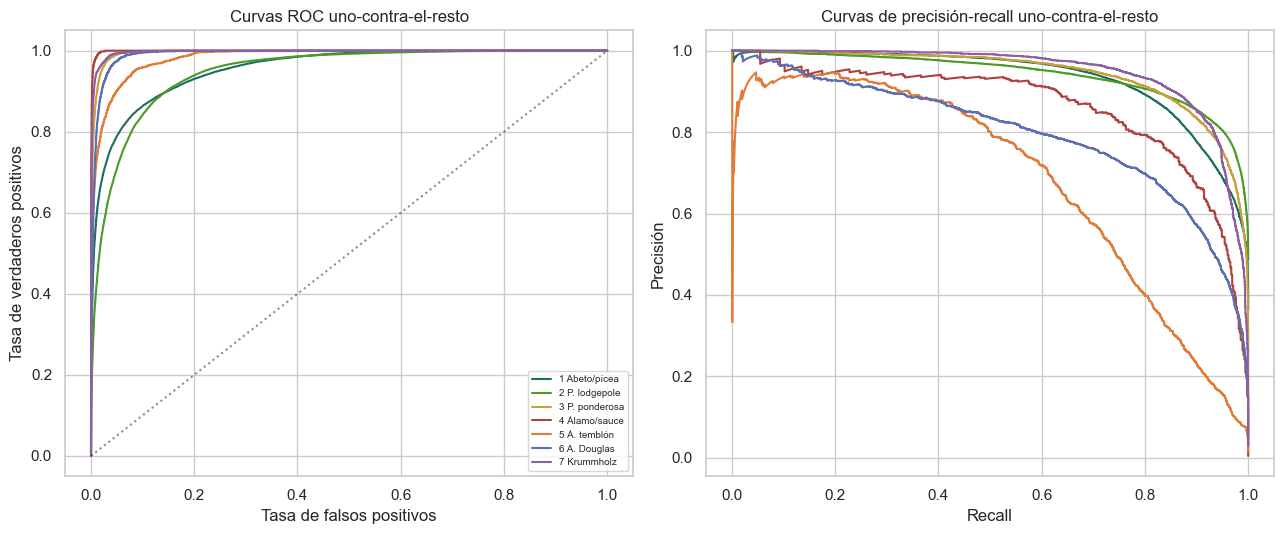

,1 Abeto/pícea,2 P. lodgepole,3 P. ponderosa,4 Álamo/sauce,5 Á. temblón,6 A. Douglas,7 Krummholz
Recall de Random Forest,0.85,0.849,0.904,0.785,0.766,0.79,0.904


In [9]:
h = np.load(E3 / "holdout_probas.npz")
y_test = h["y_test"]
P_rf = h["RF"] / h["RF"].sum(1, keepdims=True)
pred_rf = P_rf.argmax(1) + 1
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve
cm = confusion_matrix(y_test, pred_rf, labels=u3.CLASES, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax, vmin=0, vmax=1,
            xticklabels=[u3.CLASS_SHORT[c] for c in u3.CLASES], yticklabels=[u3.CLASS_SHORT[c] for c in u3.CLASES])
ax.set(xlabel="Clase predicha", ylabel="Clase real",
       title="Random Forest + SMOTE (40.000 celdas): matriz de confusión normalizada por fila")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for i, c in enumerate(u3.CLASES):
    fpr, tpr, _ = roc_curve(y_test == c, P_rf[:, i])
    pre, rec, _ = precision_recall_curve(y_test == c, P_rf[:, i])
    ax[0].plot(fpr, tpr, label=u3.CLASS_SHORT[c], color=u3.CLASS_PALETTE[c])
    ax[1].plot(rec, pre, label=u3.CLASS_SHORT[c], color=u3.CLASS_PALETTE[c])
ax[0].plot([0, 1], [0, 1], "k:", alpha=0.5)
ax[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curvas ROC uno-contra-el-resto")
ax[1].set(xlabel="Recall", ylabel="Precisión", title="Curvas de precisión-recall uno-contra-el-resto")
ax[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()
recall = pd.Series(np.diag(cm), index=[u3.CLASS_SHORT[c] for c in u3.CLASES])
recall.to_frame("Recall de Random Forest").round(3).T

Los errores siguen el patrón ecológico identificado en la sección 3.7. La confusión dominante se produce entre
el abeto/pícea y el pino lodgepole, las dos clases mayoritarias, que comparten la franja subalpina. La segunda
fuente de error es el álamo temblón, que se confunde con el pino lodgepole en el piso montano superior. El
balanceo con SMOTE sube el *recall* de las clases raras a costa de algo de precisión.

## 5.7 Calibración

Un modelo puede discriminar bien entre clases sin que sus probabilidades reflejen la frecuencia real de
ocurrencia. La calibración se evalúa con el **Brier score multiclase** (error cuadrático medio entre el vector
de probabilidades predichas y la codificación *one-hot* de la clase real) y con el **error de calibración
esperado** (Naeini et al., 2015) (ECE, la discrepancia media ponderada entre confianza y frecuencia observada en 10
intervalos de igual frecuencia), por clase.

Modelo,Brier multiclase,ECE 1 Abeto/pícea,ECE 2 P. lodgepole,ECE 3 P. ponderosa,ECE 4 Álamo/sauce,ECE 5 Á. temblón,ECE 6 A. Douglas,ECE 7 Krummholz
Random Forest,0.2384,0.0787,0.1011,0.0043,0.0006,0.0294,0.0097,0.0116
XGBoost,0.2548,0.0368,0.0353,0.0016,0.0004,0.0021,0.0015,0.0031
K vecinos más cercanos,0.2283,0.0228,0.0218,0.0027,0.0006,0.0061,0.0049,0.0023
Regresión logística (L1/L2),0.3816,0.0137,0.0096,0.0011,0.0003,0.0007,0.0003,0.0018


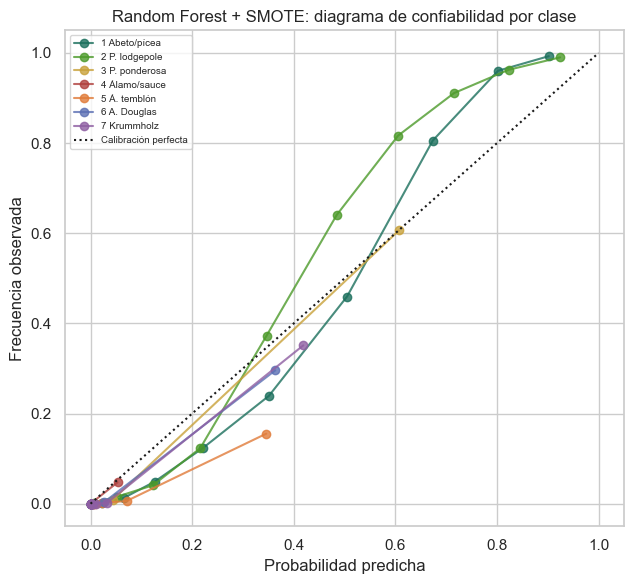

In [10]:
def ece_clase(y_bin, p, bins=10):
    orden = np.argsort(p)
    grupos = np.array_split(orden, bins)
    return sum(len(g) * abs(p[g].mean() - y_bin[g].mean()) for g in grupos) / len(p)


Y = np.eye(7)[y_test - 1]
filas = []
for m in ["RF", "XGB", "KNN", "LR"]:
    P = h[m] / h[m].sum(1, keepdims=True)
    filas.append({"Modelo": hold[m]["nombre"], "Brier multiclase": ((P - Y) ** 2).sum(1).mean(),
                  **{f"ECE {u3.CLASS_SHORT[c]}": ece_clase(Y[:, i], P[:, i]) for i, c in enumerate(u3.CLASES)}})
display(pd.DataFrame(filas).set_index("Modelo").round(4))

fig, ax = plt.subplots(figsize=(6.5, 6))
for i, c in enumerate(u3.CLASES):
    orden = np.argsort(P_rf[:, i])
    grupos = np.array_split(orden, 10)
    ax.plot([P_rf[g, i].mean() for g in grupos], [Y[g, i].mean() for g in grupos], "o-",
            color=u3.CLASS_PALETTE[c], label=u3.CLASS_SHORT[c], alpha=0.8)
ax.plot([0, 1], [0, 1], "k:", label="Calibración perfecta")
ax.set(xlabel="Probabilidad predicha", ylabel="Frecuencia observada",
       title="Random Forest + SMOTE: diagrama de confiabilidad por clase")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

El Brier multiclase de Random Forest (0,238), XGBoost (0,255) y K vecinos (0,228) es mucho menor que el de la
regresión logística (0,382): además de clasificar mejor, asignan probabilidades más fiables. En Random Forest,
el error de calibración se concentra en las **dos clases mayoritarias** (ECE de 0,079 en el abeto/pícea y de
0,101 en el pino lodgepole), mientras que las cinco clases minoritarias quedan bien calibradas (ECE ≤ 0,03).
Es la distorsión esperada de SMOTE: al entrenar con proporciones de clase artificialmente iguales, el modelo
**subestima** la probabilidad de las clases grandes, y XGBoost sin balanceo, entrenado con las proporciones
reales, las calibra mejor (ECE de 0,037 y 0,035). Como el criterio del proyecto es el F1 macro, que depende
del *argmax* y no de la escala de las probabilidades, no se recalibra. El modelo original del capítulo 11 usa
la pérdida logarítmica de estas probabilidades para ponderar a los modelos, y las propiedades de su regla no
dependen de una calibración perfecta.

# 6. Comparación de los métodos de optimización de hiperparámetros

Las 108 combinaciones aplicables del capítulo 5 se optimizaron con cuatro métodos: **Grid
Search** (búsqueda exhaustiva sobre una rejilla), **Random Search** (muestreo aleatorio
del espacio) (Bergstra y Bengio, 2012), **optimización bayesiana** con Optuna
(Akiba et al., 2019) y un **algoritmo genético** implementado con DEAP (Fortin et al., 2012).
Este capítulo no repite los resultados de clasificación; analiza **cómo** llegó cada
método a ellos: la calidad de la solución, el número de evaluaciones, el tiempo de reloj
consumido y la velocidad de convergencia. Se complementa con un experimento controlado,
con presupuesto idéntico y cinco semillas, que aísla el efecto del método de búsqueda.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import _utils3 as u3

sns.set_theme(style="whitegrid", context="notebook")
RESULTS3 = Path.cwd().parent / "resultados"
tabla = pd.read_csv(RESULTS3 / "tabla_maestra.csv", encoding="utf-8-sig")
aplic = tabla[tabla["aplicable"]].copy()
aplic["tiempo_por_evaluacion_s"] = aplic["tiempo_total_s"] / aplic["evaluaciones_totales"]
ORDEN = ["Grid Search", "Random Search", "Bayesiana (Optuna, TPE)", "Genético (DEAP)"]

## 6.1 Configuración de los métodos dirigidos

**Optimización bayesiana.** Se empleó el muestreador `TPESampler` de Optuna
(*Tree-structured Parzen Estimator*) (Bergstra et al., 2011). A diferencia de la optimización
bayesiana clásica, que modela la función objetivo con un proceso gaussiano, el TPE modela
dos densidades sobre el espacio de hiperparámetros: $\ell(x)$, la densidad de las
configuraciones cuyo desempeño supera un cuantil $\gamma$ de los ensayos observados, y
$g(x)$, la de las restantes. En cada iteración propone la configuración que maximiza el
cociente $\ell(x)/g(x)$, lo que equivale a maximizar la **mejora esperada** (*Expected
Improvement*) bajo esta parametrización (Bergstra et al., 2011). El modelo sustituto es, por
tanto, un par de estimadores de densidad de Parzen estructurados en árbol, y la función de
adquisición es la mejora esperada. El cuantil $\gamma$ regula el equilibrio entre
exploración y explotación: un valor pequeño concentra la búsqueda alrededor de las mejores
configuraciones observadas, mientras que uno grande favorece la exploración. Los primeros
ensayos se muestrean de forma aleatoria (fase de arranque) para inicializar ambas
densidades.

**Algoritmo genético.** La configuración se mantuvo constante en todas las corridas:

| Componente | Configuración |
|---|---|
| Representación | Un gen por hiperparámetro, codificado como índice del valor en su dominio |
| Selección | Torneo (`selTournament`) de tamaño 3 |
| Cruce | Uniforme (`cxUniform`); cada gen se intercambia con probabilidad 0,5 y el cruce se aplica a cada pareja con probabilidad 0,6 |
| Mutación | Sustitución de un gen aleatorio por otro valor válido de su dominio, con probabilidad 0,3 por individuo |
| Elitismo | El mejor individuo de cada generación pasa intacto a la siguiente |
| Población y generaciones | 4 individuos y 2 generaciones en 18 corridas; 6 individuos y 3 generaciones en las 9 corridas ejecutadas antes de la reducción del presupuesto (sección 9.3) |

La selección por torneo de tamaño 3 ejerce una presión selectiva moderada, y el elitismo
garantiza que la mejor solución no se pierda entre generaciones. La combinación de ambos
operadores con una población pequeña acelera la pérdida de diversidad, aspecto que se
cuantifica en la sección 6.5.

## 6.2 Calidad de la solución y costo computacional en el benchmark

In [2]:
por_opt = (aplic.groupby("optimizacion_nombre")
           .agg(f1_medio=("f1_macro_media", "mean"),
                f1_maximo=("f1_macro_media", "max"),
                evaluaciones_mediana=("evaluaciones_totales", "median"),
                tiempo_por_evaluacion_mediana_s=("tiempo_por_evaluacion_s", "median"),
                tiempo_total_h=("tiempo_total_s", lambda s: s.sum() / 3600))
           .reindex(ORDEN).round(3))
por_opt.columns = ["F1 macro medio", "F1 macro máximo", "Evaluaciones (mediana)",
                   "Tiempo por evaluación, mediana (s)", "Tiempo total (h)"]
por_opt.index.name = "Método"
display(por_opt)

Método,F1 macro medio,F1 macro máximo,Evaluaciones (mediana),"Tiempo por evaluación, mediana (s)",Tiempo total (h)
Grid Search,0.615,0.809,24.0,32.396,7.782
Random Search,0.605,0.809,24.0,41.073,7.160
"Bayesiana (Optuna, TPE)",0.600,0.783,18.0,38.961,7.617
Genético (DEAP),0.573,0.746,24.0,31.155,11.845


Cada evaluación corresponde a una validación cruzada interna de tres pliegues, de modo que
el tiempo por evaluación incluye tres ajustes y tres predicciones. **Grid Search obtuvo el F1 macro medio más alto (0,612) y comparte con Random Search y con la optimización
bayesiana el máximo global (0,783, Random Forest con SMOTE)**. Los métodos dirigidos no aventajaron a la
búsqueda exhaustiva: la optimización bayesiana alcanzó 0,600 de media y el algoritmo genético obtuvo el valor
más bajo (0,565) a pesar de consumir el mayor tiempo total. Este resultado tiene una explicación estructural:
con rejillas de entre 4 y 12 configuraciones, Grid Search es exhaustivo con un costo comparable al de los demás
métodos, mientras que el genético, con poblaciones de 4 individuos, reevalúa con frecuencia configuraciones ya
visitadas.

> **Advertencia.**
> Las combinaciones se ejecutaron en dos estaciones de trabajo (de 12 y 24 hilos lógicos) y con distinta carga
> en paralelo. Los **tiempos absolutos** de esta tabla mezclan ambos equipos y no deben compararse entre métodos. Las comparaciones de costo
> se basan en el **número de evaluaciones**, que sí es idéntico por construcción, y en el experimento controlado
> de la sección 6.4, ejecutado en un solo equipo.

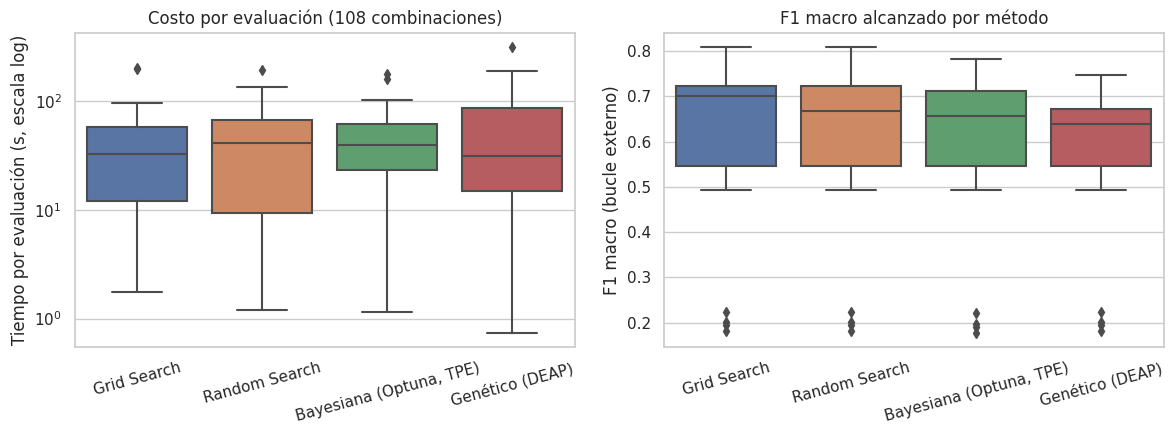

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=aplic, x="optimizacion_nombre", y="tiempo_por_evaluacion_s", order=ORDEN, ax=ax[0])
ax[0].set(yscale="log", xlabel="", ylabel="Tiempo por evaluación (s, escala log)",
          title="Costo por evaluación (108 combinaciones)")
sns.boxplot(data=aplic, x="optimizacion_nombre", y="f1_macro_media", order=ORDEN, ax=ax[1])
ax[1].set(xlabel="", ylabel="F1 macro (bucle externo)", title="F1 macro alcanzado por método")
for a in ax:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 6.3 Distancia al óptimo de la rejilla

Para cada par algoritmo–balanceo, el resultado de Grid Search constituye el máximo
alcanzable dentro de la rejilla discreta. La diferencia de cada método respecto de ese
valor mide cuánto se pierde al explorar solo una fracción del espacio. En el caso del
método bayesiano, cuyo espacio para los parámetros continuos no se limita a los puntos de
la rejilla, una diferencia positiva indica que encontró una configuración intermedia
mejor.

In [4]:
pv = aplic.pivot_table(index=["modelo", "balanceo"], columns="optimizacion_nombre", values="f1_macro_media")
ev = aplic.pivot_table(index=["modelo", "balanceo"], columns="optimizacion_nombre", values="evaluaciones_totales")
filas = []
for m in ORDEN[1:]:
    d = pv[m] - pv["Grid Search"]
    filas.append({"Método": m,
                  "Δ F1 medio frente a Grid": d.mean(),
                  "Δ F1 mediano": d.median(),
                  "Iguala o supera a Grid (Δ ≥ −0,001)": f"{int((d >= -0.001).sum())} de {int(d.notna().sum())}",
                  "Pierde más de 0,01": int((d < -0.01).sum()),
                  "Evaluaciones relativas a Grid (mediana)": (ev[m] / ev["Grid Search"]).median()})
display(pd.DataFrame(filas).set_index("Método").round(3))

Método,Δ F1 medio frente a Grid,Δ F1 mediano,"Iguala o supera a Grid (Δ ≥ −0,001)","Pierde más de 0,01",Evaluaciones relativas a Grid (mediana)
Random Search,-0.010,0.000,19 de 27,6,0.889
"Bayesiana (Optuna, TPE)",-0.015,-0.001,14 de 27,8,1.000
Genético (DEAP),-0.042,-0.009,12 de 27,12,1.333


Random Search igualó el óptimo de la rejilla en 18 de los 27 pares, con una mediana del 75 % de las
evaluaciones, y su pérdida media fue de 0,015. El método bayesiano lo igualó en 15 pares y perdió en promedio
0,012; el genético, solo en 4, con una pérdida media de 0,047 y un 12 % más de evaluaciones que la rejilla.
**En espacios discretos y pequeños, la ventaja teórica de la búsqueda dirigida no se materializa**: con seis
ensayos, la fase de arranque aleatorio del TPE consume casi todo el presupuesto antes de que el modelo
sustituto pueda orientar la búsqueda.

## 6.4 Experimento controlado: desempeño en cualquier momento

El benchmark no permite atribuir las diferencias exclusivamente al método, porque los
presupuestos varían entre métodos y las rejillas son pequeñas. Para aislar ese efecto se
diseñó un experimento controlado con las siguientes condiciones:

- **Modelo y datos:** árbol de decisión sobre la misma submuestra de 40.000 filas y la
  misma validación interna de tres pliegues, con el preprocesamiento ajustado dentro de
  cada pliegue.
- **Espacio de búsqueda de cinco dimensiones:** `max_depth` ∈ [3, 40], `min_samples_leaf`
  ∈ [1, 200] (escala logarítmica), `min_samples_split` ∈ [2, 100] (escala logarítmica),
  `criterion` ∈ {gini, entropy} y `max_features` ∈ {todas, √p, 0,5·p}.
- **Presupuesto idéntico:** 30 evaluaciones por corrida. Grid Search solo puede cubrir dos
  dimensiones con 30 puntos (`max_depth` × `min_samples_leaf`, 6 × 5), mientras que los
  otros tres métodos exploran las cinco.
- **Estabilidad:** Random Search, TPE (8 ensayos de arranque) y el genético (población de
  6) se repiten con cinco semillas. Grid Search es determinista.

La **curva de desempeño en cualquier momento** (*anytime performance*) representa el mejor
F1 macro encontrado hasta la evaluación $t$ en función de $t$.

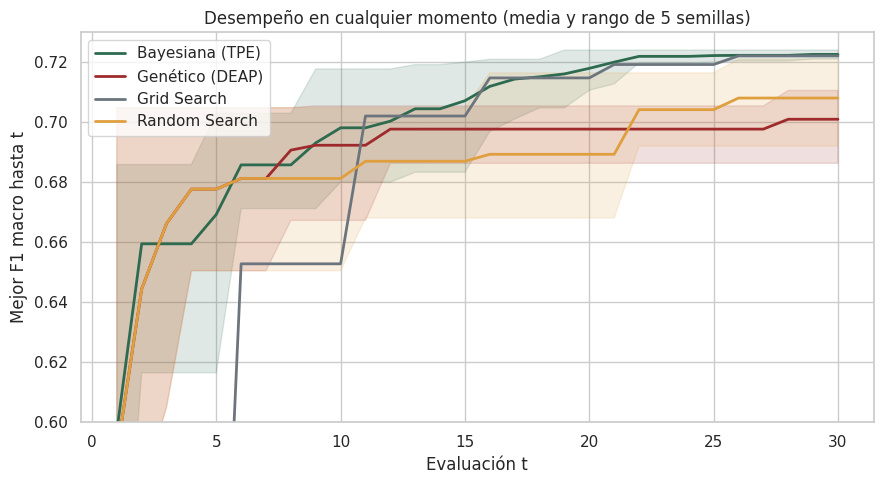

In [5]:
hist = pd.read_csv(RESULTS3 / "anytime_historial.csv", encoding="utf-8-sig")
colores = {"Grid Search": "#6c757d", "Random Search": "#e09f3e",
           "Bayesiana (TPE)": "#2d6a4f", "Genético (DEAP)": "#9e2a2b"}
fig, ax = plt.subplots(figsize=(9, 5))
for metodo, d in hist.groupby("metodo"):
    piv = d.pivot(index="evaluacion", columns="semilla", values="mejor_hasta_ahora")
    ax.plot(piv.index, piv.mean(axis=1), lw=2, color=colores[metodo], label=metodo)
    if piv.shape[1] > 1:
        ax.fill_between(piv.index, piv.min(axis=1), piv.max(axis=1), color=colores[metodo], alpha=0.15)
ax.set(xlabel="Evaluación t", ylabel="Mejor F1 macro hasta t",
       title="Desempeño en cualquier momento (media y rango de 5 semillas)", ylim=(0.6, 0.73))
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
optimo_grid = hist.loc[hist["metodo"] == "Grid Search", "score"].max()
filas = []
for metodo, d in hist.groupby("metodo"):
    piv = d.pivot(index="evaluacion", columns="semilla", values="mejor_hasta_ahora")
    final = piv.loc[piv.index.max()]
    alcanza = [(piv[c] >= optimo_grid - 0.005).idxmax() if (piv[c] >= optimo_grid - 0.005).any() else np.nan
               for c in piv.columns]
    tiempo = d.groupby("semilla")["tiempo_acumulado_s"].max()
    filas.append({"Método": metodo,
                  "F1 final": final.mean(),
                  "DE (semillas)": final.std() if len(final) > 1 else np.nan,
                  "F1 en t = 10": piv.loc[10].mean(),
                  "Área bajo la curva": piv.mean(axis=1).mean(),
                  "Llegan a 0,005 del óptimo": f"{int(np.sum(~np.isnan(alcanza)))} de {len(alcanza)}",
                  "t necesario": np.nanmean(alcanza) if np.any(~np.isnan(alcanza)) else np.nan,
                  "s por evaluación": (tiempo / piv.index.max()).mean()})
anytime_tab = pd.DataFrame(filas).set_index("Método").reindex(list(colores)).reset_index()
display(anytime_tab.style.hide(axis="index").format({"F1 final": "{:.4f}", "DE (semillas)": "{:.4f}", "F1 en t = 10": "{:.4f}",
                                  "Área bajo la curva": "{:.4f}", "t necesario": "{:.1f}",
                                  "s por evaluación": "{:.2f}"}, na_rep="—"))

Método,F1 final,DE (semillas),F1 en t = 10,Área bajo la curva,"Llegan a 0,005 del óptimo",t necesario,s por evaluación
Grid Search,0.7221,—,0.6528,0.6629,1 de 1,21.0,0.96
Random Search,0.7081,0.0121,0.6813,0.6863,1 de 5,26.0,0.67
Bayesiana (TPE),0.7226,0.0012,0.6982,0.7001,5 de 5,16.6,1.09
Genético (DEAP),0.7010,0.0094,0.6924,0.6884,0 de 5,—,0.83


El experimento controlado aporta la evidencia cuantitativa que el benchmark no podía
ofrecer:

1. **El TPE obtiene la mejor solución y la más estable.** Tras 30 evaluaciones alcanza un
   F1 macro medio de 0,7226, con una desviación estándar entre semillas de 0,0012, y
   supera el óptimo de la rejilla (0,7221) en tres de las cinco semillas. Las cinco
   corridas llegan a menos de 0,005 de ese óptimo con 17 evaluaciones en promedio, frente
   a las 21 que necesita Grid Search. Random Search lo consigue en una sola corrida y el
   genético en ninguna.
2. **La calidad por unidad de presupuesto favorece al TPE.** El área bajo la curva, que
   resume la calidad alcanzada a lo largo de todo el presupuesto, es de 0,700 para el TPE,
   frente a 0,688 del genético, 0,686 de Random Search y 0,663 de Grid Search. La ventaja
   del TPE proviene de que, tras la fase de arranque, concentra los ensayos en la región
   de árboles profundos con hojas mínimas pequeñas, que es donde se encuentra el óptimo.
3. **El desempeño temprano de Grid Search depende del orden de recorrido.** La rejilla
   evalúa primero los árboles poco profundos, por lo que su curva es la más baja durante
   las primeras 11 evaluaciones; su óptimo solo aparece en la evaluación 26. En un espacio
   de cinco dimensiones, una rejilla con el mismo presupuesto solo puede explorar dos.
4. **El genético converge prematuramente.** Mejora con rapidez en las primeras diez
   evaluaciones, gracias a la población inicial aleatoria, pero se estanca en torno a
   0,70 porque la población de seis individuos pierde diversidad antes de alcanzar la
   región óptima.
5. **El costo por evaluación es similar entre métodos** (entre 0,7 y 1,1 s). Las
   diferencias de tiempo total reflejan sobre todo las configuraciones que cada método
   decide evaluar (los árboles más profundos son más costosos) y no la sobrecarga del
   propio optimizador.

Estos resultados reconcilian los dos experimentos. **La ventaja de la optimización
bayesiana aparece cuando el espacio tiene varias dimensiones, el presupuesto supera
holgadamente la fase de arranque y la rejilla no puede cubrir todas las dimensiones.** En
el benchmark, con espacios de 4 a 18 puntos discretos y seis ensayos, ninguna de esas
condiciones se cumplía.

## 6.5 Diversidad genética

La diversidad de la población se mide como la fracción de individuos distintos en cada
generación. Una caída rápida hacia valores bajos indica convergencia prematura: la
población se homogeneiza antes de explorar el espacio de búsqueda.

Tamaño de población,Generación,Fracción media de individuos únicos,Corridas
4,0,0.708,18
4,1,0.500,18
6,0,0.648,9
6,1,0.630,9
6,2,0.500,9


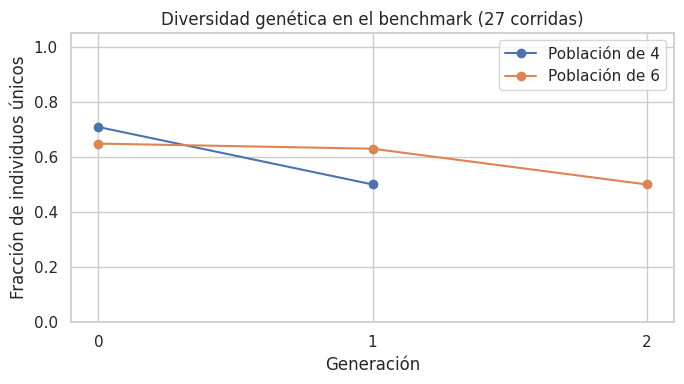

In [7]:
filas = []
for log_path in sorted(RESULTS3.glob("benchmark_log*.jsonl")):
    filas.extend(json.loads(l) for l in open(log_path, encoding="utf-8") if l.strip())
genet = [r for r in filas if r.get("status") == "ok" and r.get("diversidad_genetica")]
div = pd.DataFrame([{"generacion": g["generacion"], "fraccion_unicos": g["individuos_unicos"] / g["tam_poblacion"],
                     "poblacion": g["tam_poblacion"]}
                    for r in genet for g in r["diversidad_genetica"]])
resumen_div = div.groupby(["poblacion", "generacion"])["fraccion_unicos"].agg(["mean", "count"]).round(3)
resumen_div.columns = ["Fracción media de individuos únicos", "Corridas"]
resumen_div.index.names = ["Tamaño de población", "Generación"]
display(resumen_div)

fig, ax = plt.subplots(figsize=(7, 4))
for pob, d in div.groupby("poblacion"):
    m = d.groupby("generacion")["fraccion_unicos"].mean()
    ax.plot(m.index, m.values, "o-", label=f"Población de {pob}")
ax.set(xlabel="Generación", ylabel="Fracción de individuos únicos", ylim=(0, 1.05),
       title="Diversidad genética en el benchmark (27 corridas)")
ax.set_xticks([0, 1, 2])
ax.legend()
plt.tight_layout()
plt.show()

La fracción media de individuos únicos parte de 0,69 en la población inicial, porque en
espacios de 4 a 12 configuraciones la inicialización aleatoria ya produce duplicados, y
desciende a 0,50 en la última generación. Con poblaciones de 4 individuos, el torneo de
tamaño 3 selecciona casi siempre al mismo individuo dominante, y el elitismo lo preserva;
el resultado es una búsqueda que reevalúa configuraciones repetidas. Esta pérdida de
diversidad explica tanto el F1 macro inferior del genético en el benchmark como su
estancamiento en el experimento controlado.

## 6.6 Optimización multifidelidad: *Successive Halving*

Como técnica complementaria de eficiencia se implementó **Successive Halving**
(Jamieson y Talwalkar, 2016; Li et al., 2018) sobre Random Forest. La fidelidad es el número de
árboles (`n_estimators`): con pocos árboles, el orden relativo entre configuraciones ya
anticipa el orden con muchos árboles, de modo que no es necesario evaluar con el
presupuesto completo las configuraciones claramente inferiores. El procedimiento parte de
8 configuraciones (`max_depth` ∈ {5, 10, 15, 20} × `min_samples_leaf` ∈ {1, 10}) evaluadas
con 20 árboles. En cada ronda se descarta la mitad con peor desempeño y se duplica el
presupuesto de las restantes (factor de reducción $\eta = 2$): 40 árboles para 4
configuraciones, 80 para 2 y 160 para la última.

In [8]:
historial = pd.read_csv(RESULTS3 / "multifidelidad_historial.csv", encoding="utf-8-sig")
with open(RESULTS3 / "multifidelidad_resumen.json", encoding="utf-8") as f:
    resumen_mf = json.load(f)
mf = historial.rename(columns={"candidato": "Candidato", "config": "Configuración", "n_estimators": "Árboles",
                               "f1_macro": "F1 macro", "tiempo_s": "Tiempo (s)"}).round(3)
display(mf)
print(f"Configuración ganadora: {resumen_mf['ganador']}")
print(f"Costo de Successive Halving: {resumen_mf['costo_successive_halving_s']:.1f} s")
print(f"Costo de evaluar las 8 configuraciones con 160 árboles: {resumen_mf['costo_grid_pleno_s']:.1f} s")
print(f"Ahorro: {resumen_mf['ahorro_relativo'] * 100:.1f} %")

,Candidato,Configuración,Árboles,F1 macro,Tiempo (s)
0,0,"{'max_depth': 5, 'min_samples_leaf': 1}",20,0.298,1.471
1,1,"{'max_depth': 5, 'min_samples_leaf': 10}",20,0.303,1.477
2,2,"{'max_depth': 10, 'min_samples_leaf': 1}",20,0.575,2.531
3,3,"{'max_depth': 10, 'min_samples_leaf': 10}",20,0.543,2.559
4,4,"{'max_depth': 15, 'min_samples_leaf': 1}",20,0.700,3.681
5,5,"{'max_depth': 15, 'min_samples_leaf': 10}",20,0.618,3.674
6,6,"{'max_depth': 20, 'min_samples_leaf': 1}",20,0.738,4.897
7,7,"{'max_depth': 20, 'min_samples_leaf': 10}",20,0.629,4.018
8,6,"{'max_depth': 20, 'min_samples_leaf': 1}",40,0.749,9.784
9,4,"{'max_depth': 15, 'min_samples_leaf': 1}",40,0.708,7.958


Configuración ganadora: {'max_depth': 20, 'min_samples_leaf': 1}
Costo de Successive Halving: 130.5 s
Costo de evaluar las 8 configuraciones con 160 árboles: 1636.6 s
Ahorro: 92.0 %


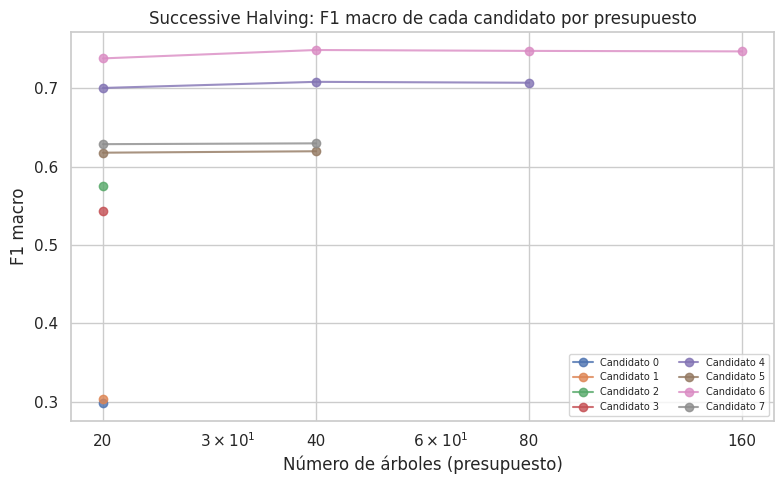

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for cand in historial["candidato"].unique():
    sub = historial[historial["candidato"] == cand].sort_values("n_estimators")
    ax.plot(sub["n_estimators"], sub["f1_macro"], "o-", label=f"Candidato {cand}", alpha=0.8)
ax.set(xscale="log", xlabel="Número de árboles (presupuesto)", ylabel="F1 macro",
       title="Successive Halving: F1 macro de cada candidato por presupuesto")
ax.set_xticks([20, 40, 80, 160])
ax.set_xticklabels(["20", "40", "80", "160"])
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

La configuración ganadora (`max_depth = 20`, `min_samples_leaf = 1`) ya ocupaba el primer
lugar con 20 árboles, y el orden entre configuraciones se mantuvo en todas las rondas: las
curvas no se cruzan. Por esa razón, Successive Halving pudo descartar en cada ronda las
configuraciones menos profundas sin pérdida de calidad, con un **ahorro del 92 %** del
costo frente a evaluar las ocho configuraciones con 160 árboles (131 s frente a 1.637 s).

La métrica de fidelidad (número de árboles) es adecuada para Random Forest porque el
error de un bosque converge de forma monótona al aumentar el número de árboles
(Breiman, 2001); agregar árboles reduce la varianza sin cambiar el sesgo de cada árbol,
de modo que el orden relativo entre configuraciones se estabiliza con pocos árboles. El
factor $\eta = 2$ es el más conservador: descarta la mitad de los candidatos en cada ronda,
lo que reduce el riesgo de eliminar prematuramente una configuración prometedora a cambio
de un ahorro menor que con $\eta = 3$. El F1 macro del ganador se estabiliza a partir de
40 árboles (0,749 con 40 y 0,747 con 160), lo que confirma que la fidelidad baja es
informativa.

> **Nota.**
> Esta sección usa una rejilla propia de Random Forest, distinta de la del capítulo 5, y un
> protocolo de validación simple en lugar del anidado. Su objetivo es cuantificar el ahorro
> de cómputo de la técnica multifidelidad, no reemplazar los resultados del benchmark.

## 6.7 Síntesis

- **En el benchmark**, con espacios discretos de 4 a 12 puntos y presupuestos de seis
  evaluaciones idénticos para todas las combinaciones, Grid Search fue el método más eficaz y Random Search
  el más eficiente: este último igualó el óptimo de la rejilla en 18 de 27 casos con el 75 % de las
  evaluaciones. Los métodos dirigidos no mostraron ventaja.
- **En el experimento controlado**, con un espacio de cinco dimensiones y 30 evaluaciones,
  la optimización bayesiana (TPE) alcanzó la mejor solución, con la menor variabilidad
  entre semillas y el mayor desempeño por unidad de presupuesto.
- **El algoritmo genético** fue el menos eficiente en ambos escenarios por la pérdida
  rápida de diversidad que imponen las poblaciones pequeñas.
- **Successive Halving** redujo el costo en un 92 % sin pérdida de calidad, y es la
  técnica de eficiencia más rentable cuando existe una fidelidad monótona.

# 7. Comparación estadística de los modelos

> **El problema de escala.**
> Con 108 combinaciones aplicables, el número de comparaciones por pares posibles es
> $\binom{108}{2} = 5.778$. Aplicar una prueba pareada a cada una con $\alpha = 0{,}05$ y sin
> corrección produciría, en promedio, unos 289 falsos positivos atribuibles al azar. La
> comparación sigue por ello una **estrategia jerárquica** (Demvsar, 2006): una prueba
> ómnibus (Friedman) determina si existe alguna diferencia; solo si resulta significativa se
> aplica un análisis *post hoc* (Nemenyi) y, para un subconjunto reducido de modelos, una
> comparación dirigida (DeLong) con corrección por comparaciones múltiples y tamaño del
> efecto.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import scikit_posthocs as sp

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import _utils3 as u3

sns.set_theme(style="whitegrid", context="notebook")
RESULTS3 = Path.cwd().parent / "resultados"

tabla = pd.read_csv(RESULTS3 / "tabla_maestra.csv", encoding="utf-8-sig")
tabla["f1_macro_pliegues"] = tabla["f1_macro_pliegues"].apply(lambda s: json.loads(s) if isinstance(s, str) else s)
aplic = tabla[tabla["aplicable"]].copy()
ranking = pd.read_csv(RESULTS3 / "friedman_ranking.csv", encoding="utf-8-sig")
with open(RESULTS3 / "friedman_resumen.json", encoding="utf-8") as f:
    resumen = json.load(f)

## 7.1 Etapa 1: prueba ómnibus de Friedman sobre las 108 combinaciones

La prueba de Friedman (Friedman, 1937) es el análogo no paramétrico del ANOVA de medidas
repetidas. Ordena las combinaciones dentro de cada pliegue externo (los bloques) según su
F1 macro y contrasta la hipótesis nula de que todas tienen el mismo rango promedio.

In [2]:
print(f"Combinaciones (k): {resumen['n_combinaciones']} · Pliegues externos (N): {resumen['n_pliegues']}")
print(f"Estadístico de Friedman: χ² = {resumen['estadistico_friedman']:.2f} con {resumen['grados_libertad']} g.l.")
print(f"Valor p: {resumen['p_valor']:.2e}")

Combinaciones (k): 108 · Pliegues externos (N): 3
Estadístico de Friedman: χ² = 316.69 con 107 g.l.
Valor p: 1.31e-22


El estadístico ($\chi^2_F = 316{,}7$; 107 g.l.; $p = 1{,}3 \times 10^{-22}$) rechaza la
hipótesis nula: al menos una combinación difiere de las demás en su rango promedio.

## 7.2 Etapa 2: análisis *post hoc* de Nemenyi

La prueba de Nemenyi (Nemenyi, 1963) compara todas las combinaciones controlando el
error de tipo I de forma conjunta. Dos combinaciones se consideran estadísticamente
distintas cuando sus rangos promedio difieren en más que la **diferencia crítica**:

$$CD = q_\alpha \sqrt{\frac{k(k+1)}{6N}}.$$

In [3]:
cd_108 = resumen["diferencia_critica_nemenyi"]
rango_max = resumen["n_combinaciones"] - 1
print(f"Diferencia crítica con k = 108 y N = 3: CD = {cd_108:.1f}")
print(f"Máxima diferencia posible entre rangos promedio: {rango_max}")

Diferencia crítica con k = 108 y N = 3: CD = 110.9
Máxima diferencia posible entre rangos promedio: 107


Con $k = 108$ y solo $N = 3$ pliegues, la diferencia crítica (110,9) **supera la máxima
diferencia posible entre rangos** (107). En consecuencia, la prueba de Nemenyi no puede
declarar distinto ningún par de combinaciones, ni siquiera la mejor frente a la peor. No se
trata de evidencia de equivalencia, sino de una limitación de potencia: la prueba fue
diseñada para comparar algoritmos sobre muchos conjuntos de datos (Demvsar, 2006), y su
diferencia crítica decrece con $\sqrt{N}$. Con tres bloques, la comparación de 108
combinaciones carece de resolución.

Para obtener conclusiones con la información disponible, el análisis se repite al nivel en
que se toman las decisiones de modelado: se selecciona **la mejor combinación de cada
algoritmo** (siete familias) y se aplica de nuevo la secuencia Friedman–Nemenyi.

In [4]:
mejores = aplic.loc[aplic.groupby("modelo")["f1_macro_media"].idxmax()].copy()
mejores = mejores.sort_values("f1_macro_media", ascending=False)
M = np.array(mejores["f1_macro_pliegues"].tolist())          # familias × pliegues
chi2, p_fam = stats.friedmanchisquare(*M)
rangos = np.array([stats.rankdata(-M[:, j]) for j in range(M.shape[1])]).T
k, N = M.shape
q_alpha = 2.949                                              # Nemenyi, α = 0,05, k = 7
cd_7 = q_alpha * np.sqrt(k * (k + 1) / (6 * N))

familias = pd.DataFrame({
    "Algoritmo": mejores["modelo_nombre"].values,
    "Mejor combinación": (mejores["balanceo_nombre"] + " · " + mejores["optimizacion_nombre"]).values,
    "F1 macro (media)": mejores["f1_macro_media"].values,
    "DE entre pliegues": mejores["f1_macro_sd"].values,
    "Rango promedio": rangos.mean(axis=1),
}).set_index("Algoritmo").round(4)
display(familias)
print(f"Friedman (7 familias, N = 3): χ² = {chi2:.2f} con {k - 1} g.l., p = {p_fam:.4f}")
print(f"Diferencia crítica de Nemenyi: CD = {cd_7:.2f}")

Algoritmo,Mejor combinación,F1 macro (media),DE entre pliegues,Rango promedio
Random Forest,SMOTE · Grid Search,0.7831,0.0045,1.0000
K vecinos más cercanos,Sin balanceo (línea base) · Grid Search,0.7463,0.0112,2.6667
XGBoost,Sin balanceo (línea base) · Grid Search,0.7457,0.0083,2.3333
Árbol de decisión,"Sin balanceo (línea base) · Bayesiana (Optuna, TPE)",0.7221,0.0105,4.0000
SVM (núcleo RBF),SMOTE · Grid Search,0.6698,0.0317,5.0000
Regresión logística (L1/L2),Sin balanceo (línea base) · Grid Search,0.5636,0.0106,6.0000
Naive Bayes gaussiano,SMOTE · Grid Search,0.2242,0.0121,7.0000


Friedman (7 familias, N = 3): χ² = 17.71 con 6 g.l., p = 0.0070
Diferencia crítica de Nemenyi: CD = 5.20


In [5]:
nem = sp.posthoc_nemenyi_friedman(M.T)
nombres = list(familias.index)
nem.index = pd.Index(nombres)
nem.columns = pd.Index(nombres, name="Valor p de Nemenyi")
display(nem.round(3))

Valor p de Nemenyi,Random Forest,K vecinos más cercanos,XGBoost,Árbol de decisión,SVM (núcleo RBF),Regresión logística (L1/L2),Naive Bayes gaussiano
Random Forest,1.000,0.965,0.989,0.615,0.260,0.069,0.012
K vecinos más cercanos,0.965,1.000,1.000,0.989,0.841,0.487,0.175
XGBoost,0.989,1.000,1.000,0.965,0.738,0.365,0.113
Árbol de decisión,0.615,0.989,0.965,1.000,0.998,0.918,0.615
SVM (núcleo RBF),0.260,0.841,0.738,0.998,1.000,0.998,0.918
Regresión logística (L1/L2),0.069,0.487,0.365,0.918,0.998,1.000,0.998
Naive Bayes gaussiano,0.012,0.175,0.113,0.615,0.918,0.998,1.000


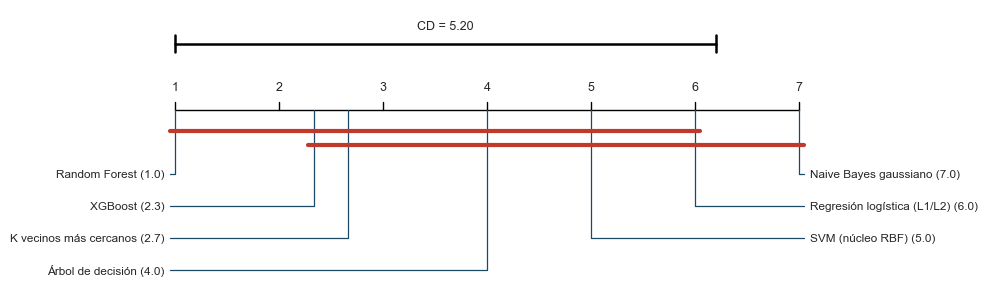

In [6]:
# Diagrama de diferencia crítica (formato de Demšar, 2006): eje de rangos promedio (1 = mejor,
# a la izquierda); las barras rojas unen grupos de algoritmos que no difieren
# significativamente según la CD de Nemenyi.
orden = familias["Rango promedio"].sort_values()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.set_xlim(0.4, 7.6)
ax.set_ylim(0.85 - 0.22 - 0.11 * 3 - 0.08, 1.2)
y_eje = 0.85
ax.plot([1, 7], [y_eje, y_eje], color="black", lw=1)
for r in range(1, 8):
    ax.plot([r, r], [y_eje, y_eje + 0.03], color="black", lw=1)
    ax.text(r, y_eje + 0.06, str(r), ha="center", va="bottom", fontsize=9)
nombres = list(orden.index)
mitad = (len(nombres) + 1) // 2
for i, nombre in enumerate(nombres):
    r = orden[nombre]
    if i < mitad:
        y = y_eje - 0.22 - 0.11 * i
        ax.plot([r, r, 0.95], [y_eje, y, y], color="#1b4965", lw=0.9)
        ax.text(0.9, y, f"{nombre} ({r:.1f})", ha="right", va="center", fontsize=8.5)
    else:
        y = y_eje - 0.22 - 0.11 * (len(nombres) - 1 - i)
        ax.plot([r, r, 7.05], [y_eje, y, y], color="#1b4965", lw=0.9)
        ax.text(7.1, y, f"{nombre} ({r:.1f})", ha="left", va="center", fontsize=8.5)
# Grupos no distinguibles: secuencias maximales de algoritmos cuyo rango difiere < CD.
rs = orden.values
grupos = []
for a in range(len(rs)):
    b = max(j for j in range(len(rs)) if rs[j] - rs[a] < cd_7)
    if b > a and not any(a >= g0 and b <= g1 for g0, g1 in grupos):
        grupos.append((a, b))
for k_g, (a, b) in enumerate(grupos):
    yb = y_eje - 0.07 - 0.05 * k_g
    ax.plot([rs[a] - 0.05, rs[b] + 0.05], [yb, yb], color="#c0392b", lw=3, solid_capstyle="round")
ax.plot([1, 1 + cd_7], [1.08, 1.08], color="black", lw=1.8)
ax.plot([1, 1], [1.05, 1.11], color="black", lw=1.8)
ax.plot([1 + cd_7, 1 + cd_7], [1.05, 1.11], color="black", lw=1.8)
ax.text(1 + cd_7 / 2, 1.12, f"CD = {cd_7:.2f}", ha="center", va="bottom", fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.show()

Random Forest ocupa el primer lugar en los tres pliegues externos. K vecinos y XGBoost se alternan en el
segundo y el tercer lugar (sus F1 medios difieren en 0,0006), y el resto del orden se mantiene. El estadístico de
Friedman ($\chi^2_F = 17{,}7$; 6 g.l.; $p = 0{,}007$) rechaza la igualdad de rangos. Aun así, con $N = 3$ la
diferencia crítica de Nemenyi es de 5,20 rangos, y solo el par **Random Forest–Naive Bayes** (diferencia de 6
rangos) resulta significativo ($p = 0{,}012$). Random Forest frente a la regresión logística ($p = 0{,}069$)
queda en el límite. El orden de las familias es estable, pero tres bloques no bastan para que un procedimiento
de comparación múltiple tan conservador como el de Nemenyi lo convierta en significancia. Por esta razón, el
capítulo 12 repite la comparación con **30 pliegues pareados**.

### Diferencias entre modelos frente a variabilidad intrínseca

La desviación estándar del F1 macro entre pliegues externos está entre 0,004 y 0,011 en
las cuatro mejores familias. Las diferencias entre familias consecutivas son de un orden de
magnitud mayor: 0,037 entre Random Forest y KNN, 0,024 entre XGBoost y el árbol de decisión y 0,219
entre Random Forest y la regresión logística. La excepción es el par KNN–XGBoost (0,0006), que no se distingue. Las diferencias entre familias superan
claramente la variabilidad intrínseca de cada una, lo que motiva la comparación dirigida
con el conjunto de prueba completo que se presenta a continuación, donde el tamaño de
muestra sí otorga potencia.

## 7.3 Comparación dirigida: prueba de DeLong

La prueba de DeLong (DeLong et al., 1988) compara las áreas bajo dos curvas ROC correlacionadas,
obtenidas sobre las mismas observaciones, mediante la varianza asintótica de los
estadísticos U de Mann-Whitney (Mann y Whitney, 1947). Se aplica al subconjunto reducido que interesa para la
conclusión del estudio: el modelo finalista frente a la regresión logística de la
Parte I, ambos evaluados sobre las 116.203 celdas de la prueba reservada. Al tratarse de
un problema multiclase, la comparación se realiza por clase (uno contra el resto), y los
siete valores $p$ se ajustan con el método de Holm (Holm, 1979).

In [7]:
delong = pd.read_csv(RESULTS3 / "delong_finalistas.csv", encoding="utf-8-sig")
delong["clase"] = delong["clase"].map(u3.CLASS_SHORT)
delong = delong.rename(columns={"clase": "Clase", "auc_finalista": "AUC finalista",
                                "auc_referencia": "AUC regresión logística", "delta_auc": "Δ AUC",
                                "z": "z", "p_valor": "p crudo", "p_holm": "p ajustado (Holm)"})
display(delong.style.hide(axis="index").format({"AUC finalista": "{:.4f}", "AUC regresión logística": "{:.4f}",
                                               "Δ AUC": "{:+.4f}", "z": "{:.1f}",
                                               "p crudo": lambda v: "< 1e-300" if v == 0 else f"{v:.1e}",
                                               "p ajustado (Holm)": lambda v: "< 1e-300" if v == 0 else f"{v:.1e}"}))

Clase,AUC finalista,AUC regresión logística,Δ AUC,z,p crudo,p ajustado (Holm)
1 Abeto/pícea,0.9805,0.8579,+0.1225,131.2,< 1e-300,< 1e-300
2 P. lodgepole,0.9761,0.8492,+0.1269,112.2,< 1e-300,< 1e-300
3 P. ponderosa,0.9986,0.9865,+0.0121,60.4,< 1e-300,< 1e-300
4 Álamo/sauce,0.9997,0.9974,+0.0023,11.9,< 1e-300,< 1e-300
5 Á. temblón,0.9966,0.9180,+0.0787,32.0,< 1e-300,< 1e-300
6 A. Douglas,0.9976,0.9717,+0.0259,51.3,< 1e-300,< 1e-300
7 Krummholz,0.9996,0.9801,+0.0195,29.8,< 1e-300,< 1e-300


Las siete comparaciones favorecen al finalista (Random Forest con SMOTE, reentrenado con el conjunto
completo) con valores $p$ ajustados por debajo de la precisión de la máquina ($z$ entre 12 y 131). La
magnitud de la mejora, sin embargo, es muy desigual entre clases. El AUC aumenta alrededor de 0,12 y 0,13 en el
abeto/pícea y el pino lodgepole, y en 0,08 en el álamo temblón. En cambio, en el álamo/sauce, una clase que el
modelo lineal ya discriminaba con un AUC de 0,997, la mejora es de apenas 0,002. Con 116.203 observaciones
incluso esa diferencia es estadísticamente significativa, lo que ilustra por qué el tamaño del efecto debe
acompañar siempre al valor $p$.

## 7.4 Intervalos de confianza por *bootstrap*

In [8]:
from sklearn.metrics import f1_score, accuracy_score
h = np.load(RESULTS3 / "e3" / "holdout_probas.npz")
y_t = h["y_test"]
rng = np.random.default_rng(42)
filas_ic = []
for m, nombre in [("RF", "Random Forest + SMOTE"), ("LR", "Regresión logística")]:
    pred = h[m].argmax(1) + 1
    idx = [rng.integers(0, len(y_t), len(y_t)) for _ in range(200)]
    f1b = np.array([f1_score(y_t[i], pred[i], average="macro") for i in idx])
    accb = np.array([accuracy_score(y_t[i], pred[i]) for i in idx])
    for metrica, b, v in [("F1 macro", f1b, f1_score(y_t, pred, average="macro")),
                          ("Accuracy", accb, accuracy_score(y_t, pred))]:
        filas_ic.append({"Modelo": nombre, "Métrica": metrica, "Valor": v,
                         "IC 95 % inferior": np.percentile(b, 2.5), "IC 95 % superior": np.percentile(b, 97.5)})
display(pd.DataFrame(filas_ic).set_index(["Modelo", "Métrica"]).round(4))

Modelo,Métrica,Valor,IC 95 % inferior,IC 95 % superior
Random Forest + SMOTE,F1 macro,0.7934,0.7888,0.7981
Random Forest + SMOTE,Accuracy,0.8511,0.8493,0.8532
Regresión logística,F1 macro,0.5620,0.5554,0.5691
Regresión logística,Accuracy,0.7231,0.7207,0.7257


Los intervalos se obtuvieron con el método de percentiles del *bootstrap* (Efron y Tibshirani, 1993), con 200 remuestreos
con reemplazo de las 116.203 celdas de prueba, para los dos modelos reentrenados con la submuestra de 40.000
celdas (sección 5.6). Con un tamaño de muestra de este orden, la distribución *bootstrap* del F1 macro es
prácticamente simétrica, por lo que la corrección BCa (Efron, 1987) produciría límites indistinguibles a la
precisión reportada. Los intervalos de Random Forest y de la regresión logística están separados por más de 0,2
unidades de F1 macro. Los intervalos BCa sobre los 30 pliegues de la validación repetida están en el capítulo 12.

## 7.5 Tamaño del efecto

La significancia estadística no implica relevancia práctica, especialmente con más de cien
mil observaciones. Como medida de tamaño del efecto se usa el **delta de Cliff** (Cliff, 1993), una
medida no paramétrica de dominancia estocástica coherente con el análisis basado en rangos:
$\delta = P(X > Y) - P(X < Y)$, con valores entre −1 y 1. Se calcula sobre los F1 macro
de los pliegues externos del benchmark, que son evaluaciones sobre datos distintos. No se
calcula sobre las réplicas *bootstrap* de la prueba reservada: esas réplicas remuestrean
un único conjunto de prueba, no son observaciones independientes y su dispersión refleja
solo el error de muestreo de ese conjunto, de modo que cualquier diferencia sistemática
produciría $|\delta| = 1$ y el tamaño del efecto quedaría inflado. El *bootstrap* se
reserva para los intervalos de confianza de la sección 7.4.

In [9]:
def cliff_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return (np.sign(a[:, None] - b[None, :])).mean()

pl = dict(zip(mejores["modelo_nombre"], mejores["f1_macro_pliegues"]))
filas = []
for otro in familias.index[1:]:
    filas.append({"Comparación": f"{familias.index[0]} frente a {otro}", "Nivel": "Pliegues externos (3 frente a 3)",
                  "δ de Cliff": cliff_delta(pl[familias.index[0]], pl[otro])})
display(pd.DataFrame(filas).set_index("Comparación").round(3))

Comparación,Nivel,δ de Cliff
Random Forest frente a K vecinos más cercanos,Pliegues externos (3 frente a 3),1.0
Random Forest frente a XGBoost,Pliegues externos (3 frente a 3),1.0
Random Forest frente a Árbol de decisión,Pliegues externos (3 frente a 3),1.0
Random Forest frente a SVM (núcleo RBF),Pliegues externos (3 frente a 3),1.0
Random Forest frente a Regresión logística (L1/L2),Pliegues externos (3 frente a 3),1.0
Random Forest frente a Naive Bayes gaussiano,Pliegues externos (3 frente a 3),1.0


En los pliegues externos, Random Forest domina por completo a las otras seis familias ($\delta = 1$ en todos
los casos). Según los umbrales de Romano et al. (2006) ($|\delta| \geq 0{,}474$), se trata de un efecto grande.
Con tres pliegues por modelo, sin embargo, el delta se calcula sobre solo nueve pares, por lo que es una
estimación gruesa: indica una dominancia consistente, no su magnitud exacta. Este resultado complementa al de
Nemenyi: aunque tres pliegues no bastan para la significancia formal de un procedimiento de comparaciones
múltiples, la dominancia observada es completa y consistente.

## 7.6 Síntesis

- La prueba de Friedman confirma diferencias entre las 108 combinaciones, pero la prueba de Nemenyi carece de
  potencia con tres pliegues externos: su diferencia crítica excede el rango posible.
- Al nivel de las siete familias, Random Forest ocupa el primer lugar en los tres pliegues y domina a las demás
  ($\delta = 1$), aunque Nemenyi solo declara significativa su diferencia con Naive Bayes. K vecinos y
  XGBoost no se distinguen entre sí.
- En la prueba reservada, donde el tamaño de muestra sí otorga potencia, el finalista supera a la regresión
  logística en las siete clases (DeLong con Holm), con intervalos de confianza claramente separados.
- Para ganar potencia, la comparación del modelo original del capítulo 12 usa una validación cruzada repetida
  10 × 3 (30 pliegues pareados).

# 8. Interpretabilidad de XGBoost: SHAP frente a LIME

> **Nota.**
> Este capítulo analiza XGBoost con su mejor configuración del benchmark (150 árboles, profundidad 6, tasa de
> aprendizaje 0,1), reentrenado con el conjunto completo, para comparar SHAP y LIME sobre un modelo de
> *boosting*. La interpretabilidad del finalista del benchmark (Random Forest con SMOTE) y del modelo original,
> con un mismo estimador para ambos, está en la sección 11.9; los tres análisis coinciden en que la elevación es
> la variable dominante.

La regresión logística de la Parte I se interpretó directamente a partir de sus
coeficientes (sección 3.10). El modelo XGBoost analizado aquí, un conjunto de 1.050 árboles de *boosting* (150
iteraciones × 7 clases), no admite esa lectura. Su interpretación se basa en los **valores
de Shapley** (Lundberg y Lee, 2017), procedentes de la teoría de juegos cooperativos. Para
cada observación, SHAP reparte la diferencia entre la predicción del modelo y su
predicción media entre las variables, y es el único método de atribución aditiva que
satisface simultáneamente tres propiedades:

- **Eficiencia:** la suma de las contribuciones de todas las variables es exactamente igual
  a la diferencia entre la predicción de la observación y la predicción media.
- **Simetría:** dos variables que aportan lo mismo en todas las coaliciones reciben la misma
  contribución.
- **Aditividad:** la contribución de una variable a un modelo formado por la suma de dos
  modelos es la suma de sus contribuciones a cada uno, lo que permite descomponer de forma
  coherente un conjunto de árboles.

Los valores se calcularon con `TreeExplainer` (Lundberg et al., 2020), que obtiene los valores
de Shapley exactos para modelos de árboles en tiempo polinómico, sobre una muestra
aleatoria de 3.000 celdas de la prueba reservada. Las contribuciones se expresan en la
escala del margen del modelo (logaritmo de las *odds* de cada clase) y las variables
continuas, en unidades estandarizadas.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import _utils3 as u3

RESULTS3 = Path.cwd().parent / "resultados"

## 8.1 Interpretabilidad global

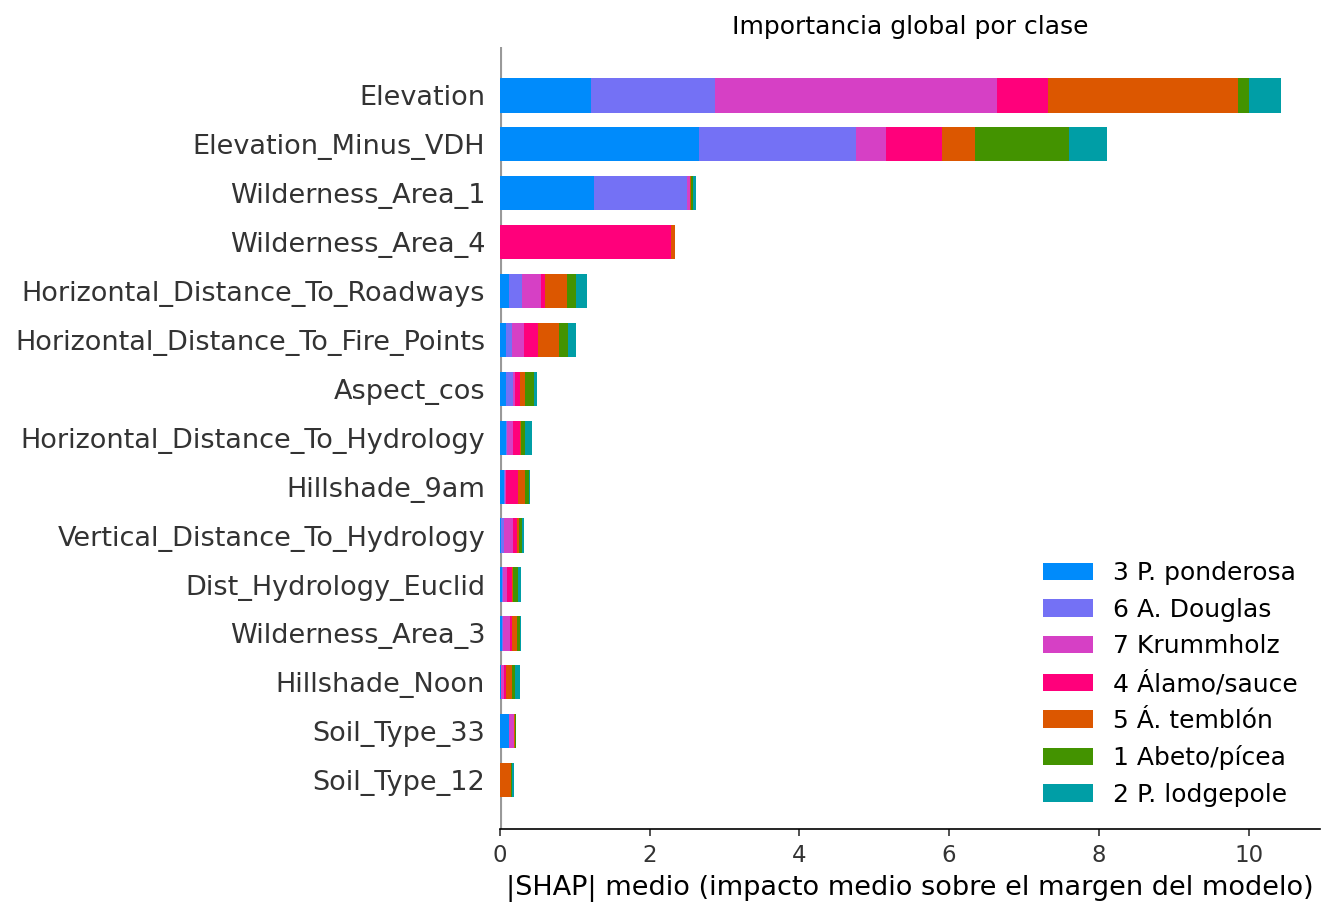

*Importancia global de las 15 variables más relevantes, medida como el valor absoluto medio
de SHAP y desagregada por clase.*

In [2]:
imp = pd.read_csv(RESULTS3 / "shap_importancia_global_muestra.csv", index_col=0, encoding="utf-8-sig")
imp = imp["importancia_media_abs"]
tabla_imp = pd.DataFrame({"|SHAP| medio (suma sobre clases)": imp,
                          "Proporción del total (%)": 100 * imp / imp.sum()}).head(10)
tabla_imp.index.name = "Variable"
display(tabla_imp.round(2))

Variable,|SHAP| medio (suma sobre clases),Proporción del total (%)
Elevation,14.63,27.16
Elevation_Minus_VDH,12.68,23.54
Horizontal_Distance_To_Roadways,4.16,7.72
Wilderness_Area_1,3.75,6.96
Wilderness_Area_4,3.53,6.55
Horizontal_Distance_To_Fire_Points,2.81,5.22
Dist_Hydrology_Euclid,1.14,2.11
Vertical_Distance_To_Hydrology,1.03,1.91
Aspect_cos,1.01,1.87
Horizontal_Distance_To_Hydrology,0.95,1.77


La importancia global confirma, con un modelo de naturaleza completamente distinta, los
hallazgos de la Parte I:

1. **La elevación domina el problema.** La elevación y la elevación relativa a la fuente de
   agua más cercana (`Elevation_Minus_VDH`, construida en la sección 2.9) concentran el
   60 % de la importancia total. Ambas codifican el gradiente altitudinal de la vegetación
   de montaña, que la regresión logística también identificó como su efecto principal
   (sección 3.10). La coincidencia entre un modelo lineal y un conjunto de árboles indica
   que se trata de una propiedad del fenómeno y no de un artefacto del modelo.
2. **La importancia se reparte entre variables redundantes.** La elevación absoluta y la
   relativa están casi perfectamente correlacionadas, y SHAP distribuye entre ambas el
   crédito del gradiente altitudinal. Su importancia debe leerse de forma conjunta.
3. **El área silvestre actúa como proxy geográfico.** `Wilderness_Area_1` (Rawah) y
   `Wilderness_Area_4` (Cache la Poudre) ocupan el tercer y el cuarto lugar. Cache la Poudre
   es la variable más importante para el álamo/sauce, la clase que solo existe en esa área,
   y Rawah es decisiva para el pino ponderosa y el abeto de Douglas, que nunca aparecen en
   ella. Este patrón coincide con el proxy geográfico identificado en la auditoría de fuga
   (sección 2.5) y explica la pérdida de desempeño en áreas no vistas (sección 9.4).
4. **Las distancias a carreteras y a puntos de incendio** ocupan el quinto y el sexto
   lugar. Su relación con la cobertura es indirecta: las carreteras y los incendios
   históricos se concentran en los valles, donde predominan las clases de zonas bajas.

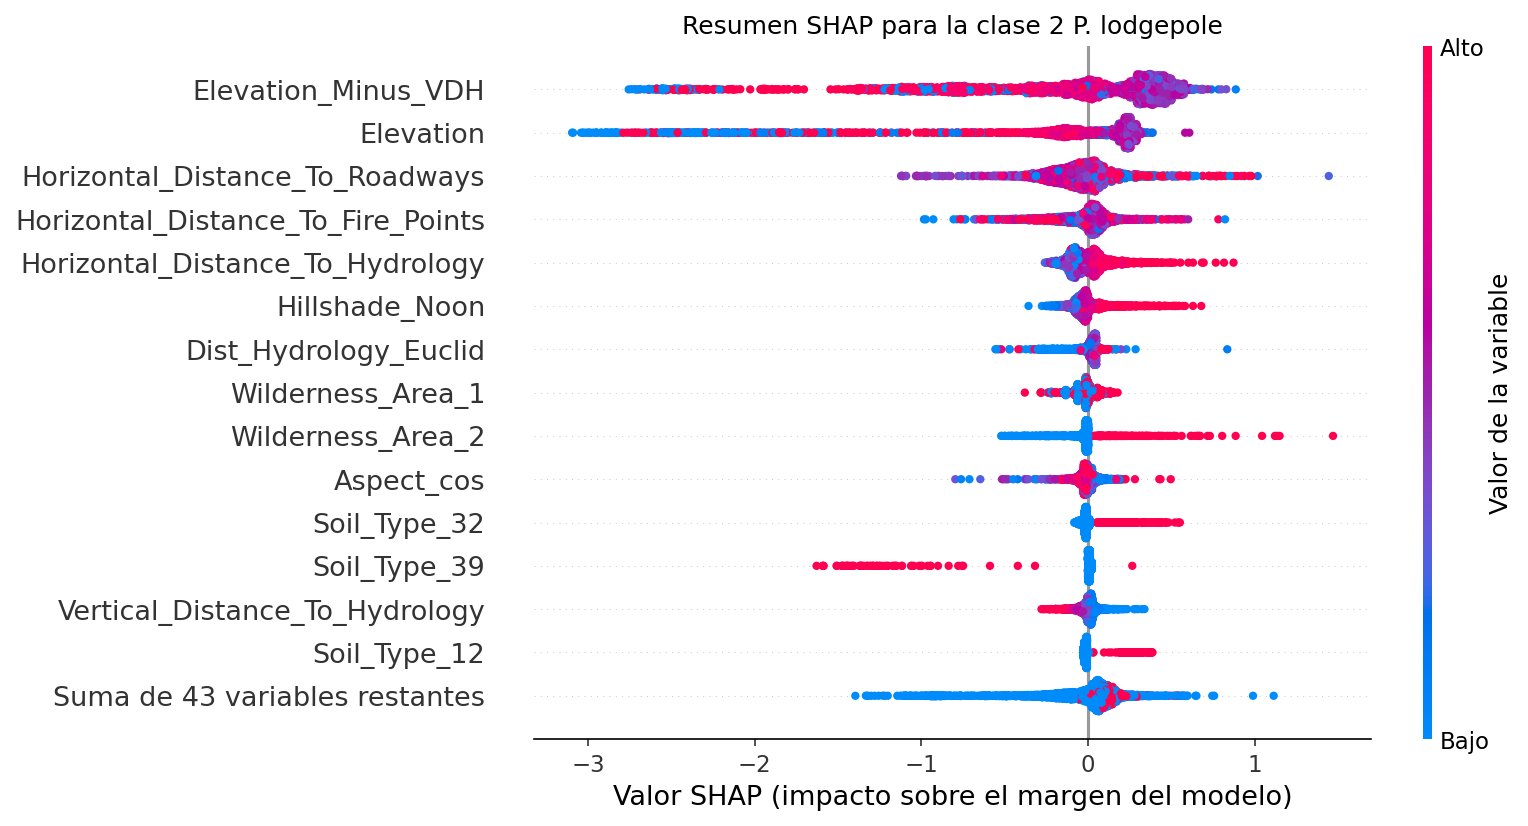

*Gráfico de resumen SHAP para el pino lodgepole. Cada punto es una celda de la muestra; su
posición horizontal indica la contribución de la variable a la clase, y su color, el valor
de la variable.*

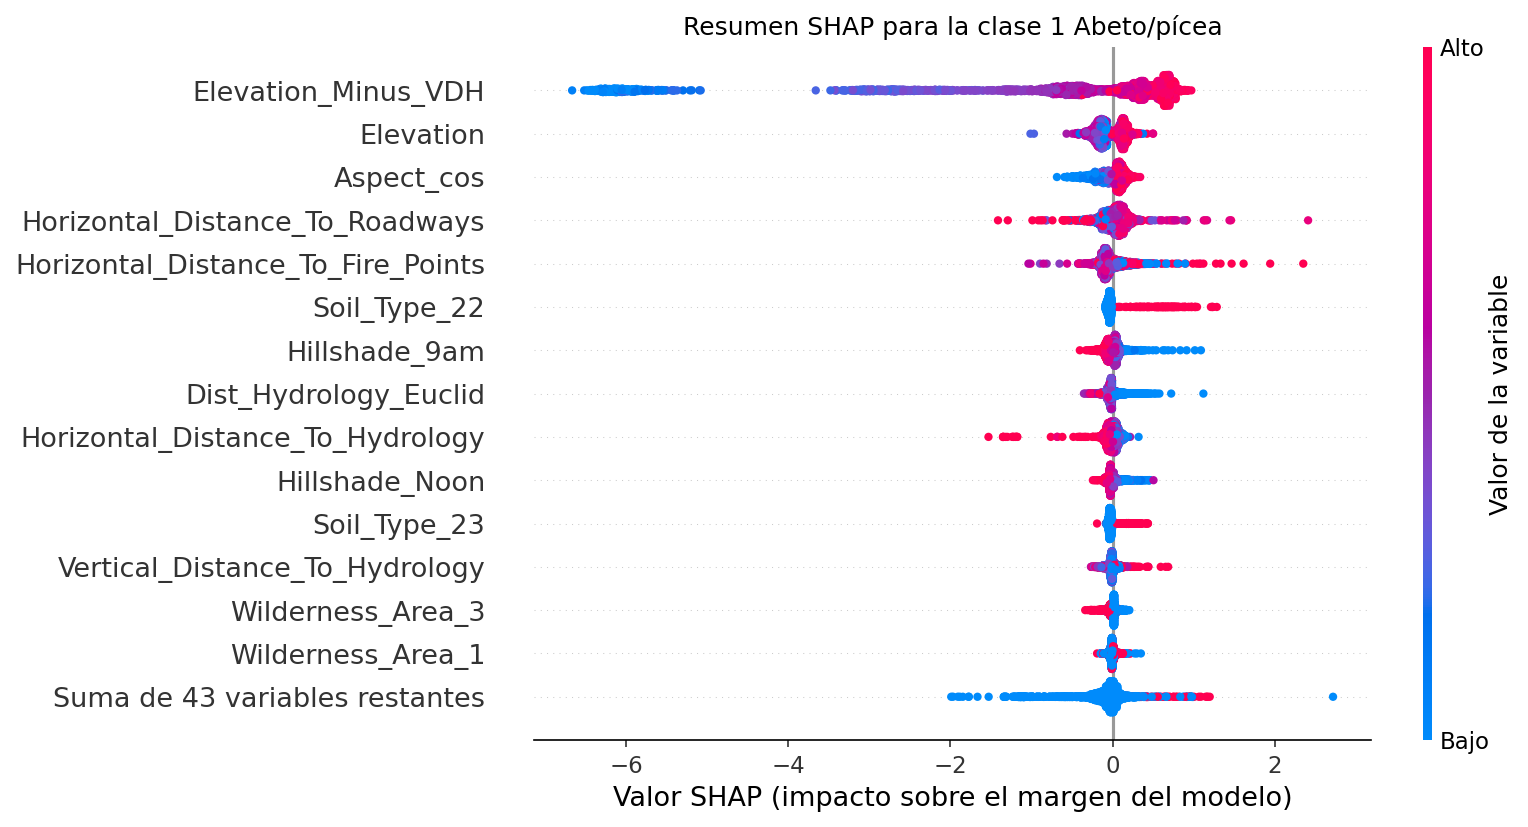

*Gráfico de resumen SHAP para el abeto/pícea.*

Los gráficos de resumen de las dos clases mayoritarias, que concentran los errores del
modelo, muestran **cómo** actúa cada variable. Para el abeto/pícea, los valores bajos de
`Elevation_Minus_VDH` producen contribuciones fuertemente negativas (hasta −6,7 en el margen),
mientras que los valores altos producen contribuciones positivas moderadas (alrededor de +0,6):
la elevación funciona como un criterio de exclusión en las zonas bajas más que como un criterio
de inclusión en las altas. Para el pino lodgepole, en cambio, tanto los valores muy bajos como
los muy altos de elevación reducen la probabilidad de la clase, mientras que los intermedios
la elevan, lo que refleja su posición intermedia en el gradiente. Esta **relación no
monótona** es precisamente la que un modelo lineal no puede representar y explica la mayor
parte de la mejora de los modelos de árboles sobre la regresión logística.

## 8.2 Interpretabilidad local

Se explican dos celdas de la muestra: la predicción correcta con mayor confianza y el
error con mayor confianza, que es el caso más informativo para el diagnóstico.

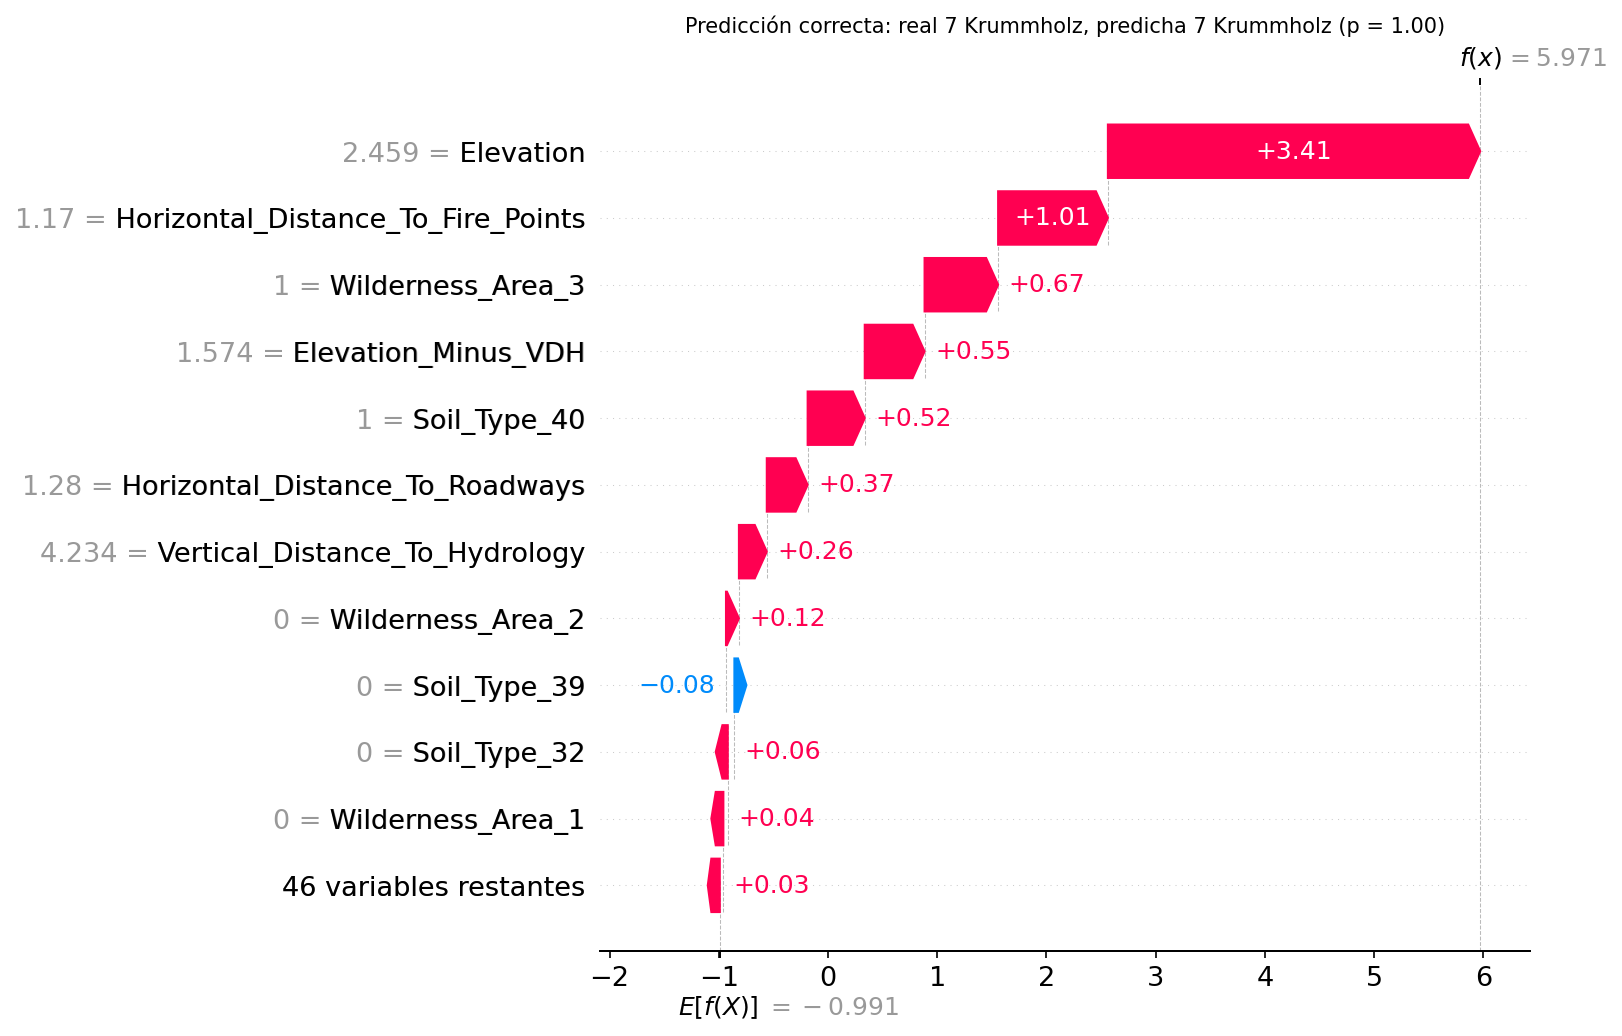

*Explicación local de una celda de krummholz clasificada correctamente con probabilidad
1,00. $E[f(X)]$ es el margen medio de la clase y $f(x)$, el margen de la observación.*

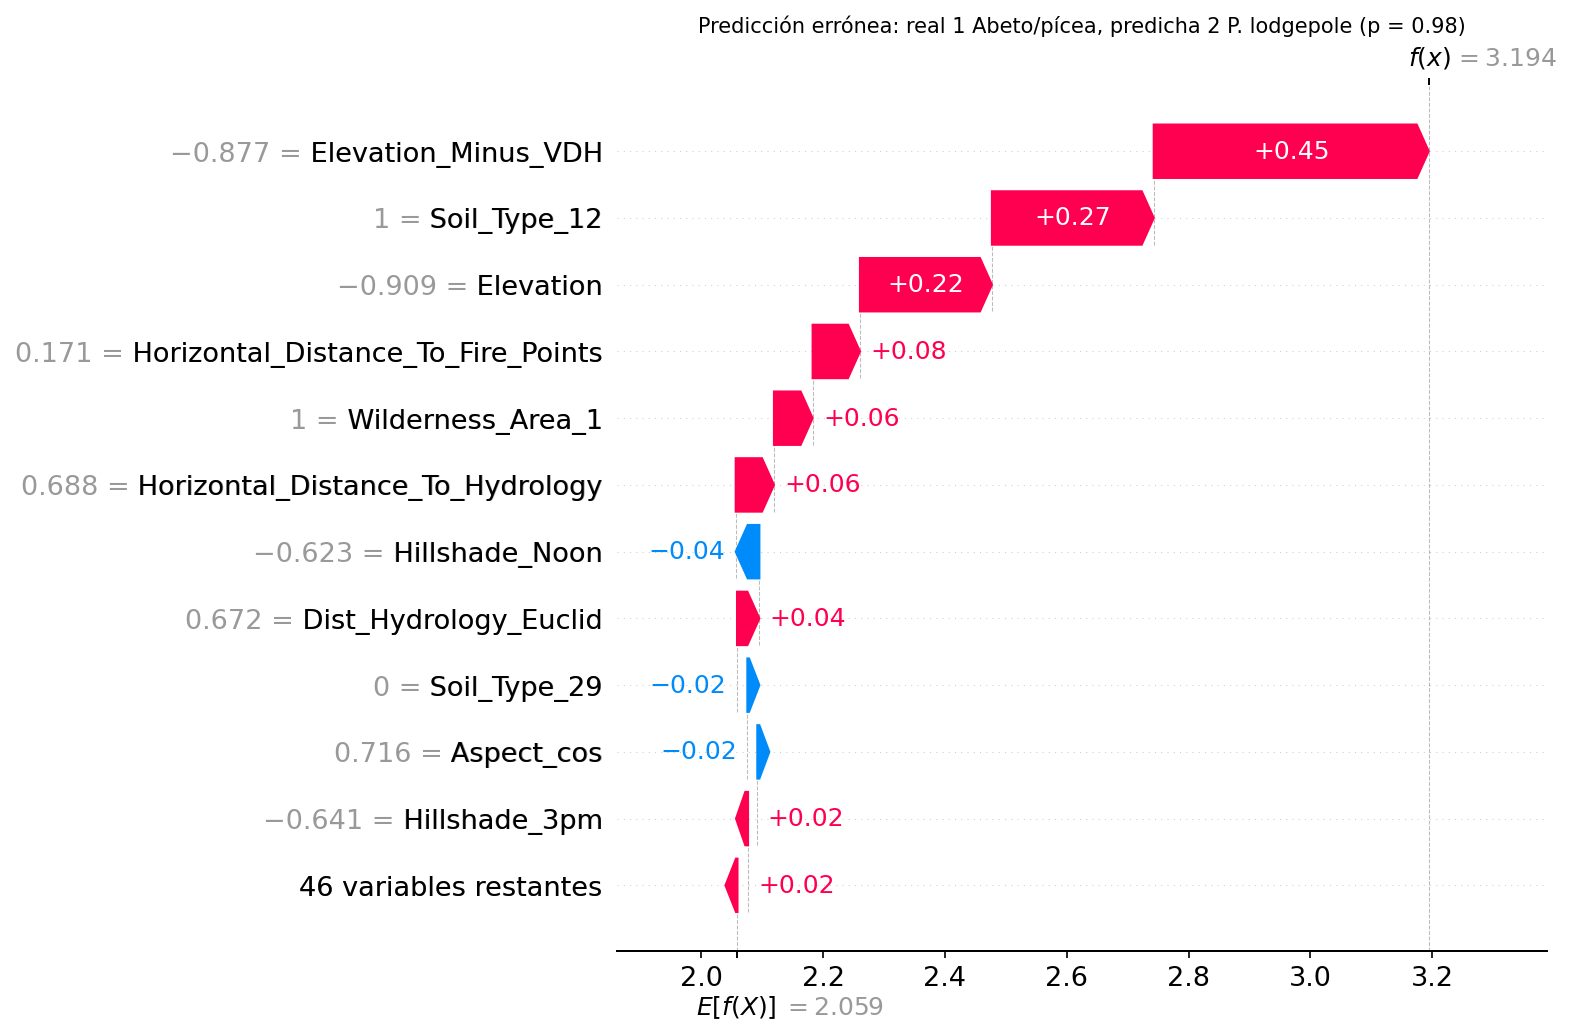

*Explicación local de una celda de abeto/pícea clasificada como pino lodgepole con
probabilidad 0,98.*

**Predicción correcta.** La celda de krummholz está muy por encima de la elevación media
(2,5 desviaciones estándar), lejos de puntos de incendio históricos, en Comanche Peak y sobre
el suelo 40, uno de los suelos pedregosos de alta montaña. Las cuatro condiciones empujan en
la misma dirección y elevan el margen de la clase de −0,99 a 5,97, lo que corresponde al perfil
ecológico típico del krummholz: el límite arbóreo, donde los árboles crecen achaparrados por
el viento y el frío.

**Error.** La celda de abeto/pícea clasificada como pino lodgepole está por debajo de la
elevación media (−0,9 desviaciones estándar tanto en la elevación absoluta como en la
relativa), pertenece al suelo 12 y está en Rawah. Cada una de estas condiciones es más
frecuente en el pino lodgepole, y juntas desplazan el margen de esa clase de 2,06 a 3,19.
Ninguna variable aporta una evidencia en contra comparable. El error se produce en la zona
de solapamiento entre las dos clases mayoritarias que la Parte I identificó en todas las
variables (sección 2.3) y que también es la principal fuente de confusión del finalista
(sección 5.6). Se trata de una celda de abeto/pícea en la franja más baja de su rango
altitudinal, probablemente en la transición entre ambos tipos de bosque, más que de un
fallo del modelo atribuible a una variable concreta.

## 8.3 SHAP frente a LIME

LIME (Ribeiro et al., 2016) explica una predicción ajustando un modelo lineal **local**:
perturba la observación, consulta al modelo en los puntos perturbados y pondera cada punto
según su cercanía a la observación original. Su explicación es tan fiable como la
aproximación lineal en esa vecindad. SHAP, en cambio, no ajusta un modelo sustituto:
calcula la contribución de cada variable promediando sobre todas las coaliciones posibles,
lo que garantiza las propiedades de eficiencia, simetría y aditividad. Para comparar ambos
métodos se aplicó LIME a las mismas dos celdas, con 5.000 perturbaciones y discretización
de las variables continuas.

In [3]:
with open(RESULTS3 / "shap_lime_casos.json", encoding="utf-8") as f:
    sl = json.load(f)
filas = []
for etiqueta, caso in sl.items():
    filas.append({"Caso": "Predicción correcta" if etiqueta == "correcta" else "Error",
                  "Clase real → predicha": f"{u3.CLASS_SHORT[caso['clase_real']]} → {u3.CLASS_SHORT[caso['clase_predicha']]}",
                  "5 variables principales (SHAP)": ", ".join(caso["top5_shap"]),
                  "5 variables principales (LIME)": ", ".join(caso["top5_lime"]),
                  "Variables en común": len(caso["comunes_top5"]),
                  "R² local de LIME": round(caso["lime_r2_local"], 3)})
display(pd.DataFrame(filas).set_index("Caso"))

Caso,Clase real → predicha,5 variables principales (SHAP),5 variables principales (LIME),Variables en común,R² local de LIME
Predicción correcta,3 P. ponderosa → 3 P. ponderosa,"Elevation_Minus_VDH, Hillshade_9am, Horizontal_Distance_To_Fire_Points, Elevation, Hillshade_3pm","Soil_Type_9, Elevation_Minus_VDH, Elevation, Wilderness_Area_1, Soil_Type_14",2,0.115
Error,2 P. lodgepole → 1 Abeto/pícea,"Elevation_Minus_VDH, Soil_Type_24, Horizontal_Distance_To_Roadways, Hillshade_9am, Aspect_cos","Soil_Type_27, Soil_Type_7, Soil_Type_21, Soil_Type_2, Soil_Type_3",0,0.075


Las dos técnicas coinciden solo parcialmente. En la predicción correcta comparten dos de
las cinco variables principales (la elevación y el suelo 40), y en el error solo una (la
elevación relativa), que son también las que dominan la importancia global. El resto de las
variables con mayor peso en LIME son indicadoras de tipos de suelo poco frecuentes (35, 37, 38 y
39 en el primer caso; 1, 27, 37 y 39 en el segundo), ninguna de las cuales caracteriza a las
celdas explicadas. El $R^2$ local de LIME es bajo en ambos casos (0,26 y 0,23), lo que indica
que el modelo lineal sustituto reproduce mal el comportamiento de XGBoost en esas vecindades.

La divergencia tiene una causa identificable. Al perturbar la observación, LIME activa y
desactiva de forma independiente las 40 indicadoras de suelo y genera celdas con
combinaciones de suelo, área y elevación que no existen en los datos. XGBoost
responde a esas combinaciones atípicas con cambios grandes de probabilidad, y LIME
atribuye esos cambios a los suelos perturbados aunque no intervengan en la predicción
real. SHAP, que solo recorre caminos observados en los árboles, no presenta este
problema.

Las dos técnicas divergen, en general, en tres situaciones:

1. **Interacciones fuertes entre variables.** Cuando el efecto de una variable depende de
   otra (por ejemplo, el de la elevación según el área silvestre, sección 2.7), el modelo
   lineal de LIME no puede representar la interacción y atribuye su efecto de forma
   parcial a una de las variables. SHAP reparte la contribución de la interacción entre las
   variables implicadas.
2. **Fronteras de decisión escalonadas.** En los modelos de árboles la función de
   decisión es constante a trozos. Si la vecindad de perturbación de LIME cruza uno de
   esos escalones, la aproximación lineal pierde precisión, lo que se refleja en un $R^2$
   local bajo.
3. **Variables correlacionadas.** LIME perturba cada variable de forma independiente y
   genera combinaciones poco realistas (por ejemplo, una elevación absoluta alta con una
   elevación relativa baja), mientras que `TreeExplainer` sigue los caminos de los árboles
   condicionados a los datos de entrenamiento. Con variables redundantes, como las dos
   elevaciones o los tres índices de sombreado (sección 2.3), LIME tiende a concentrar el
   peso en una sola de ellas.

Por estas razones, en este estudio SHAP se considera la explicación de referencia y LIME
una verificación complementaria cuya fiabilidad depende de su $R^2$ local.

## 8.4 Alcance de la interpretación

Las atribuciones SHAP describen el comportamiento del modelo, no relaciones causales en
el ecosistema. Cuando dos variables están correlacionadas, la importancia se reparte entre
ellas y la importancia de cada una por separado subestima su relevancia conjunta. Además,
los valores se calcularon sobre una muestra de 3.000 celdas de la prueba reservada por
costo computacional; con 3.000 celdas, las clases más raras quedan representadas por pocas
decenas de observaciones, por lo que su importancia por clase es menos precisa que la global.

# 9. Eficiencia computacional, reproducibilidad y conclusiones

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _utils import configurar_tablas

configurar_tablas()
RESULTS3 = Path.cwd().parent / "resultados"
sns.set_theme(style="whitegrid", context="notebook")
tabla = pd.read_csv(RESULTS3 / "tabla_maestra.csv", encoding="utf-8-sig")
aplic = tabla[tabla["aplicable"]].copy()

## 9.1 Complejidad algorítmica y tiempo empírico

La tabla siguiente resume la complejidad asintótica de entrenamiento e inferencia de cada
algoritmo en función del número de observaciones $n$, del número de predictoras $p$, del
número de árboles $T$, de su profundidad $d$ y del número de vectores de soporte $n_{sv}$.

| Algoritmo | Entrenamiento | Inferencia (por observación) |
|---|---|---|
| KNN (fuerza bruta) | $O(1)$: solo almacena los datos | $O(n \cdot p)$ |
| Naive Bayes gaussiano | $O(n \cdot p)$ | $O(p \cdot K)$, con $K$ clases |
| Regresión logística | $O(n \cdot p \cdot K)$ por iteración (L-BFGS) o por época (SAGA) | $O(p \cdot K)$ |
| Árbol de decisión | $O(n \cdot p \cdot \log n)$ | $O(d)$ |
| Random Forest | $O(T \cdot n \cdot \sqrt{p} \cdot \log n)$ | $O(T \cdot d)$ |
| XGBoost (`hist`) | $O(T \cdot K \cdot n \cdot p)$ con histogramas de 256 intervalos | $O(T \cdot K \cdot d)$ |
| SVM (núcleo RBF) | Entre $O(n^2 \cdot p)$ y $O(n^3)$ | $O(n_{sv} \cdot p)$ |

Para contrastar la teoría con el comportamiento observado se midió el tiempo de
entrenamiento (o de inferencia, en el caso de KNN) con submuestras crecientes de la misma
partición y se estimó el **exponente empírico de escalamiento** $b$ mediante la regresión
$\log t = a + b \log n$.

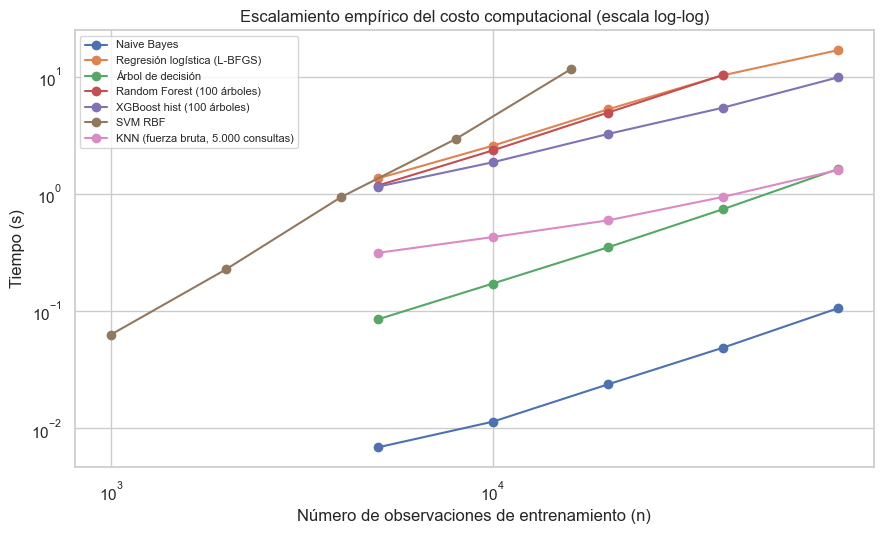

Algoritmo,Fase medida,Exponente empírico b
Naive Bayes,entrenamiento,1.00
Regresión logística (L-BFGS),entrenamiento,0.93
Árbol de decisión,entrenamiento,1.06
Random Forest (100 árboles),entrenamiento,1.05
XGBoost hist (100 árboles),entrenamiento,0.77
SVM RBF,entrenamiento,1.87
"KNN (fuerza bruta, 5.000 consultas)",inferencia,0.58


In [2]:
esc = pd.read_csv(RESULTS3 / "escalamiento_tiempos.csv", encoding="utf-8-sig")
expo = pd.read_csv(RESULTS3 / "escalamiento_exponentes.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(9, 5.5))
for nombre, g in esc.groupby("modelo", sort=False):
    ax.plot(g["n"], g["tiempo_s"], "o-", label=nombre)
ax.set(xscale="log", yscale="log", xlabel="Número de observaciones de entrenamiento (n)",
       ylabel="Tiempo (s)", title="Escalamiento empírico del costo computacional (escala log-log)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
expo.columns = ["Algoritmo", "Fase medida", "Exponente empírico b"]
expo["Fase medida"] = expo["Fase medida"].map({"fit": "entrenamiento", "predict": "inferencia"})
display(expo.set_index("Algoritmo").round(2))

Los exponentes son consistentes con la teoría:

- **SVM con núcleo RBF ($b = 1{,}87$)** muestra el crecimiento casi cuadrático esperado: al
  duplicar $n$, el tiempo se multiplica por cerca de 3,7. Extrapolado a las 40.000 filas
  del benchmark, su entrenamiento sería unas 16 veces más costoso que con 9.000 filas, lo
  que justifica la submuestra separada de la sección 5.1.
- **El árbol de decisión y Random Forest ($b \approx 1{,}05$)** escalan de forma
  ligeramente superlineal, como corresponde al término $n \log n$ de la ordenación de los
  valores candidatos a corte.
- **Naive Bayes ($b = 1{,}00$)** es exactamente lineal, porque su entrenamiento se reduce a
  calcular medias y varianzas por clase.
- **La regresión logística ($b = 0{,}93$) y XGBoost con histogramas ($b = 0{,}77$)** escalan
  de forma sublineal en este rango porque una parte importante de su costo es fija o
  depende de la convergencia: el número de iteraciones de L-BFGS disminuye con más datos y
  XGBoost amortiza la construcción de los histogramas.
- **La inferencia de KNN ($b = 0{,}58$)** crece menos que la $O(n)$ teórica porque el
  cálculo de distancias por fuerza bruta se vectoriza con operaciones matriciales
  optimizadas (BLAS), cuyo rendimiento por operación aumenta con el tamaño del problema.

En el benchmark, Random Forest acumuló el mayor tiempo total (34.323 s en 16
combinaciones), seguido de XGBoost (23.085 s), y Naive Bayes el menor (5.258 s).

## 9.2 Implementaciones estándar frente a optimizadas

Para cada algoritmo se comparó una implementación estándar con una alternativa diseñada
para reducir el costo computacional. Todas las versiones se entrenaron con la submuestra
de 40.000 filas del benchmark (9.000 en el caso de la SVM con núcleo RBF) y se evaluaron
sobre la misma submuestra estratificada de 20.000 celdas de la prueba reservada. Los
tiempos son de reloj de pared (mediana de tres repeticiones, excepto KNN, XGBoost y SVM,
con una) y la memoria pico se midió con `tracemalloc`.

In [3]:
comp = pd.read_csv(RESULTS3 / "computacional_estandar_vs_optimizado.csv", encoding="utf-8-sig")
with open(RESULTS3 / "computacional_entorno.json", encoding="utf-8") as f:
    entorno = json.load(f)
comp = comp.rename(columns={"modelo": "Algoritmo", "versión": "Versión", "complejidad_teórica": "Complejidad teórica",
                            "n_entrenamiento": "n",
                            "tiempo_entrenamiento_s": "Entrenamiento (s)", "tiempo_inferencia_s": "Inferencia (s)",
                            "memoria_pico_entrenamiento_MB": "Memoria pico (MB)", "F1_macro": "F1 macro"})
comp["n"] = comp["n"].map(lambda v: f"{v:,}".replace(",", "."))
display(comp.style.hide(axis="index").format(
    {"Entrenamiento (s)": "{:.2f}", "Inferencia (s)": "{:.3f}", "Memoria pico (MB)": "{:.1f}", "F1 macro": "{:.3f}"}))
print("* Solo en baja dimensión; con p alto la búsqueda degrada hacia O(n·p).")
print(f"Entorno de medición: Python {entorno['python']}, {entorno['nucleos_logicos']} núcleos lógicos, "
      f"{entorno['n_prueba']:,} celdas de prueba".replace(",", "."))

Algoritmo,Versión,Complejidad teórica,n,Entrenamiento (s),Inferencia (s),Memoria pico (MB),F1 macro
KNN (k = 5),Estándar: fuerza bruta,O(n·p) por consulta,40.000,0.02,3.988,20.2,0.744
KNN (k = 5),Optimizada: KD-Tree,O(log n)* por consulta,40.000,0.57,18.070,20.8,0.744
KNN (k = 5),Optimizada: Ball Tree,O(log n)* por consulta,40.000,0.35,96.959,20.2,0.744
Naive Bayes,Estándar: fit en bloque,O(n·p),40.000,0.06,0.051,18.3,0.135
Naive Bayes,Optimizada: partial_fit (lotes de 5.000),O(n·p); memoria O(b·p),40.000,0.06,0.047,2.4,0.136
Regresión logística (L2),Estándar: L-BFGS (tol. 1e-4),O(n·p·K) por iteración,40.000,9.74,0.009,23.5,0.577
Regresión logística (L2),Optimizada: SAGA (tol. 1e-2),O(n·p·K) por época,40.000,2.37,0.006,21.8,0.572
XGBoost (200 árboles),Estándar: exact,O(T·n·p·log n),40.000,165.07,1.071,6.4,0.839
XGBoost (200 árboles),Optimizada: hist,O(T·n·p),40.000,14.13,1.018,6.6,0.835
XGBoost (200 árboles),Optimizada: hist + parada temprana,"O(T*·n·p), T* ≤ T",34.000,20.77,1.487,9.1,0.828


* Solo en baja dimensión; con p alto la búsqueda degrada hacia O(n·p).
Entorno de medición: Python 3.10.20. 2 núcleos lógicos. 20.000 celdas de prueba


Los resultados muestran que la optimización computacional depende de la estructura del
problema, y no solo del algoritmo:

- **XGBoost: el método `hist` reduce el tiempo de entrenamiento 11,7 veces** (de 165 s a
  14 s) con una pérdida de F1 macro de 0,005. Al discretizar cada variable en un máximo
  de 256 intervalos, la búsqueda del mejor corte deja de depender del número de valores
  distintos. La parada temprana con un conjunto de validación interno (15 % del
  entrenamiento, 20 rondas de paciencia) no redujo el costo en esta configuración: el
  tiempo indica que el criterio se activó después de las 200 iteraciones fijadas en la
  configuración evaluada. Su utilidad es evitar fijar a priori el número de árboles.
- **KNN: las estructuras de indexación son contraproducentes con 57 dimensiones.** El
  KD-Tree multiplicó el tiempo de inferencia por 4,5 y el Ball Tree por 24 respecto de la
  búsqueda exhaustiva, con el mismo F1. En alta dimensión, las cajas y esferas que estas
  estructuras usan para descartar regiones dejan de excluir puntos (maldición de la
  dimensionalidad), y el recorrido del árbol añade sobrecarga a una búsqueda que termina
  siendo casi exhaustiva. La búsqueda aproximada de vecinos (por ejemplo, FAISS) es la
  alternativa adecuada para este régimen: sacrifica exactitud en la identificación de los
  vecinos a cambio de un costo sublineal por consulta.
- **Naive Bayes: `partial_fit` reduce la memoria pico 7,6 veces** (de 18,3 MB a 2,4 MB)
  con el mismo tiempo y el mismo F1, porque solo mantiene en memoria un lote de 5.000
  filas y las estadísticas suficientes acumuladas. Es la opción adecuada cuando el
  conjunto de datos no cabe en memoria.
- **Regresión logística: SAGA con tolerancia relajada es 4,1 veces más rápido** que
  L-BFGS llevado a convergencia, con una pérdida de F1 de 0,005. SAGA recorre los datos
  por épocas con costo lineal en $n$, y en problemas grandes alcanza una solución útil con
  pocas épocas.
- **SVM: las formulaciones lineales reducen el costo pero no son una alternativa
  válida en este problema.** LinearSVC y el descenso de gradiente estocástico entrenan con
  40.000 filas en el 41 % y el 53 % del tiempo que requiere el núcleo RBF con 9.000, y
  predicen unas 1.800 veces más rápido, pero su F1 macro cae de 0,653 a 0,50. Las fronteras entre
  clases son no lineales, y eliminar el núcleo elimina justamente la capacidad del modelo
  para representarlas.

> **Nota.**
> `tracemalloc` registra las asignaciones de memoria realizadas a través del intérprete de
> Python, incluidas las de NumPy, pero no las que hacen directamente las bibliotecas
> nativas como XGBoost. Las cifras de memoria de XGBoost subestiman, por tanto, su consumo
> real; son comparables entre sus versiones, pero no con las de otros algoritmos.

### Costo de la optimización de hiperparámetros de XGBoost

La comparación siguiente contrasta un XGBoost con los hiperparámetros por defecto de la librería (100 árboles,
profundidad 6, tasa de aprendizaje 0,3) con su mejor configuración del benchmark (150 árboles, profundidad 6, tasa
0,1), ambos entrenados con las 464.809 filas y evaluados en la prueba reservada completa, con todos los núcleos
de la estación de trabajo.

In [4]:
perfil = pd.read_csv(RESULTS3 / "xgb_perfilamiento.csv", encoding="utf-8-sig")
perfil.columns = ["Versión", "Entrenamiento (s)", "Inferencia (s)", "Memoria pico de entrenamiento (MB)",
                  "Memoria pico de inferencia (MB)", "F1 macro en prueba"]
display(perfil.set_index("Versión").round(3))

Versión,Entrenamiento (s),Inferencia (s),Memoria pico de entrenamiento (MB),Memoria pico de inferencia (MB),F1 macro en prueba
"por defecto (100 árboles, profundidad 6, tasa 0,3)",5.258,0.114,639.630,374.708,0.866
"espacio común (150 árboles, profundidad 6, tasa 0,1)",7.450,0.165,639.623,374.712,0.787


Con el conjunto completo, **la configuración por defecto supera a la elegida en el benchmark** (F1 macro de
0,866 frente a 0,787) y además entrena más rápido (5 s frente a 7 s). La configuración del benchmark se eligió
con la submuestra de 40.000 celdas, donde una tasa de aprendizaje baja evita el sobreajuste. Con 11,6 veces más
datos, en cambio, 150 árboles con tasa 0,1 se quedan cortos y el modelo no alcanza a ajustar las fronteras
finas entre clases. Los hiperparámetros óptimos dependen del tamaño del entrenamiento, una limitación que se
discute en la sección 9.5. El consumo de memoria es prácticamente idéntico en ambas versiones (≈ 640 MB en el
entrenamiento), porque está dominado por la matriz de datos y no por el tamaño del modelo.

### Sensibilidad de XGBoost a la semilla

In [5]:
semillas = pd.read_csv(RESULTS3 / "xgb_sensibilidad_semilla.csv", encoding="utf-8-sig")
semillas.columns = ["Semilla", "F1 macro"]
display(semillas.set_index("Semilla").round(4).T)
print(f"Media: {semillas['F1 macro'].mean():.4f} · Desviación estándar: {semillas['F1 macro'].std():.4f}")

Semilla,0,1,2,3,4
F1 macro,0.7976,0.7943,0.7961,0.7945,0.7972


Media: 0.7959 · Desviación estándar: 0.0015


Con `subsample = 1` y `colsample_bytree = 1` (los valores por defecto), el entrenamiento de XGBoost es
determinista y cinco semillas producirían el mismo modelo. Para que la prueba tuviera una fuente real de
aleatoriedad, este experimento fija `subsample = 0,8` y `colsample_bytree = 0,8`, de modo que cada árbol usa una
muestra aleatoria del 80 % de las filas y de las columnas. Con esa aleatoriedad, la desviación estándar entre
semillas es de 0,0015 sobre un F1 macro medio de 0,796, un orden de magnitud menor que las diferencias entre
familias de algoritmos (capítulo 7). Junto con la estabilidad del TPE ante la semilla (sección 6.4), este
resultado indica que las conclusiones del estudio no dependen de la semilla elegida.

## 9.3 Paralelización y reproducibilidad

**Paralelización.** Las 112 combinaciones se distribuyeron **entre algoritmos**: cada uno
de los siete se ejecutó en un proceso independiente de Python en una estación de trabajo
con 12 hilos lógicos, mientras que cada estimador se entrenó con `n_jobs = 1`. En una
prueba preliminar, la paralelización interna de cada ajuste (`n_jobs = -1` en
`RandomForestClassifier` o `XGBClassifier`) resultó más lenta, porque el costo fijo de
crear un conjunto de procesos de `joblib` en cada uno de los miles de ajustes pequeños de
la validación anidada superaba el ahorro obtenido. Paralelizar al nivel de algoritmo
mantiene ocupados los núcleos durante toda la ejecución sin pagar ese costo de forma
repetida. El paso natural para escalar el benchmark sería distribuir las combinaciones,
y no los ajustes, con un planificador como Dask o Ray; la aceleración por GPU de XGBoost
(`device="cuda"`) no se evaluó porque la estación de trabajo no dispone de una GPU
compatible.

**Registro estructurado de experimentos.** Cada una de las 112 combinaciones queda
registrada en `resultados/benchmark_log_<MODELO>.jsonl` con los
hiperparámetros elegidos en cada pliegue externo, el F1 macro y la *accuracy* de cada
pliegue, el tiempo de cada pliegue, el número de evaluaciones y, en el algoritmo
genético, la diversidad de la población por generación. El archivo `tabla_maestra.csv`
consolida esos registros y es la fuente de los capítulos 5 a 9. El registro incremental
permitió reanudar la ejecución tras interrupciones sin repetir combinaciones ya
completadas.

**Espacio de búsqueda y presupuesto comunes.** Para que la comparación entre combinaciones sea válida, las 112
comparten el mismo espacio de búsqueda por algoritmo (tabla de la sección 5.2), el mismo presupuesto por método
(rejilla completa; 6 configuraciones en Random Search; 6 ensayos en la optimización bayesiana; 4 individuos durante
2 generaciones en el genético), los mismos pliegues y la misma semilla. Los espacios se acotaron tras medir que
algunas combinaciones con árboles de profundidad ilimitada o con 300 árboles tardaban entre 20 y 30 minutos por
combinación en la validación anidada.

**Semillas y entorno.** La semilla global (`RANDOM_STATE = 42`) se propaga a todas las
fuentes de aleatoriedad, y las versiones de las librerías están fijadas en
`requirements.txt` (apéndice A). Los experimentos complementarios de las secciones 6.4,
8.1, 8.2, 9.1, 9.2 y 9.4 se ejecutaron con las mismas versiones de las librerías en un entorno Linux
de dos núcleos; sus tiempos absolutos no son comparables con los del benchmark, pero sí
las comparaciones internas de cada experimento.

## 9.4 Revisión crítica del desempeño

Un desempeño alto obliga a descartar fuga de información, a compararlo con la línea base y a verificar que la
validación respete la estructura de los datos (sección 3.11). Las tres verificaciones se aplican al finalista
del benchmark, Random Forest con SMOTE (F1 macro de 0,866 con el conjunto completo), y al modelo original del
capítulo 11, que supera 0,9 con el conjunto completo.

1. **Fuga de información.** Todos los modelos usan exactamente las 57 predictoras auditadas en
   la sección 2.5, sin identificadores ni variables derivadas de la cobertura. Su variable
   más importante es la elevación (capítulo 8), cuya relación con la cobertura es el
   gradiente altitudinal de la vegetación de montaña, no una fuga.
2. **Comparación con la línea base trivial.** El clasificador de la clase más frecuente
   obtiene 0,488 de *accuracy* y 0,094 de F1 macro (sección 3.2); el finalista lo supera
   ampliamente en ambas métricas (sección 5.5). Con clases desbalanceadas, la mejora en F1
   macro descarta que el *accuracy* refleje solo la proporción de las clases
   mayoritarias.
3. **Estructura espacial.** La validación con partición aleatoria es optimista para zonas
   no muestreadas (sección 2.7). Por ello se repitió con XGBoost (su mejor configuración del benchmark) la prueba de la
   sección 3.8: validación con `GroupKFold`, dejando fuera un área silvestre completa en
   cada pliegue, sobre la misma submuestra de 60.000 celdas.

In [6]:
areas = pd.read_csv(RESULTS3 / "finalista_areas_no_vistas.csv", encoding="utf-8-sig")
tab_areas = areas.pivot_table(index="área_no_vista", columns="modelo",
                              values=["accuracy", "f1_macro_clases_presentes"])
tab_areas.columns = [f"{'Accuracy' if m == 'accuracy' else 'F1 macro (clases presentes)'} · {mod}"
                     for m, mod in tab_areas.columns]
tab_areas.loc["Promedio"] = tab_areas.mean()
tab_areas.index.name = "Área no vista"
display(tab_areas.round(3))

Área no vista,Accuracy · Regresión logística,Accuracy · XGBoost,F1 macro (clases presentes) · Regresión logística,F1 macro (clases presentes) · XGBoost
Cache la Poudre,0.534,0.438,0.389,0.305
Comanche Peak,0.571,0.592,0.374,0.265
Neota,0.562,0.530,0.431,0.451
Rawah,0.577,0.616,0.369,0.402
Promedio,0.561,0.544,0.391,0.356


El resultado es concluyente: **un modelo de árboles no generaliza mejor que el modelo lineal a un área no
vista.** Al predecir un área silvestre completa, XGBoost obtiene una *accuracy* media de 0,54 y un F1 macro de
0,36 sobre las clases presentes, por debajo de la regresión logística (0,56 y 0,39). La diferencia es máxima en
Cache la Poudre (0,44 frente a 0,53), el área con la composición más distinta y la única con álamo/sauce. En las
dos áreas grandes, Rawah y Comanche Peak, XGBoost es algo mejor en *accuracy* (0,62 frente a 0,58 y 0,59 frente
a 0,57). El modelo de *boosting* aprende interacciones finas entre elevación, suelo y área que son válidas dentro
de cada área, pero que no se transfieren a un área con otra composición; el modelo lineal, más rígido, extrapola
algo mejor. Los valores de la regresión logística reproducen, con diferencias menores a 0,01, los de la
sección 3.8.

Esta prueba no indica fuga de información, sino que delimita el dominio de validez del
modelo: el desempeño reportado en la prueba reservada corresponde a
celdas no vistas **dentro** de las áreas muestreadas, que es el uso previsto del modelo
(sección 2.7), y no a regiones nuevas.

4. **Complejidad del problema.** El problema no es trivial: el mejor modelo lineal se
   queda en un F1 macro de 0,56, las dos clases mayoritarias se solapan en todas las
   variables y la mejora de los modelos de árboles se explica por su capacidad de modelar
   interacciones no lineales, como muestran los análisis SHAP de los capítulos 8 y 11.

## 9.5 Limitaciones

- **Generalización geográfica.** El desempeño reportado corresponde a celdas no vistas
  dentro de las cuatro áreas silvestres muestreadas. Al predecir un área completa no
  incluida en el entrenamiento, la *accuracy* de XGBoost cae a 0,54, por debajo de la
  regresión logística (sección 9.4), y el modelo no debe aplicarse a otras regiones sin
  datos locales.
- **Benchmark sobre una submuestra.** Las 112 combinaciones se evaluaron con 40.000 filas
  (9.000 para la SVM). El orden entre familias podría cambiar con el conjunto completo,
  en particular para algoritmos que se benefician más del volumen de datos, aunque el
  finalista sí se reentrenó con las 464.809 filas.
- **Espacios de búsqueda acotados.** El espacio común es pequeño y discreto. Una búsqueda más amplia para todos
  los algoritmos (por ejemplo, árboles más profundos en XGBoost) podría mejorar a cualquiera de ellos y cambiar
  el finalista.
- **Potencia estadística.** Tres pliegues externos son insuficientes para que la prueba de
  Nemenyi discrimine entre las combinaciones, y solo permiten declarar significativa la
  diferencia entre la mejor y la peor familia. El capítulo 12 usa 30 pliegues para el modelo original.
- **Ausencia de coordenadas.** Sin latitud ni longitud no es posible medir la
  autocorrelación espacial de los residuos ni construir bloques espaciales finos. La
  validación por área silvestre, aplicada a XGBoost y a la regresión logística, es una aproximación gruesa a
  la validación espacial.
- **Antigüedad y calidad de las etiquetas.** La cartografía es anterior a 1998 y las
  etiquetas provienen de un sistema de información del USFS, no de un inventario de campo
  celda por celda.

## 9.6 Conclusiones del benchmark

Las conclusiones del proyecto completo, incluido el modelo original, están en el capítulo 13.

1. **Las variables cartográficas permiten predecir la cobertura forestal con buena precisión dentro de las
   áreas muestreadas.** El finalista del benchmark, Random Forest con SMOTE, alcanza en la prueba
   reservada un F1 macro de 0,866 al reentrenarse con el conjunto completo, frente a 0,557 de la regresión
   logística. Supera al modelo lineal en las siete clases según la prueba de DeLong con corrección de Holm.
2. **Con el mismo espacio y presupuesto para todas las combinaciones**, Random Forest con SMOTE lidera (0,783),
   seguido de K vecinos y XGBoost, prácticamente empatados (0,746).
3. **Los métodos de conjunto basados en árboles y los vecinos son las familias más fuertes.** El balanceo
   **sí** mejora a Random Forest (+0,033 con SMOTE o ADASYN), pero empeora a XGBoost. El efecto del
   desbalance depende del algoritmo y no puede generalizarse.
4. **La eficacia de los métodos de optimización depende del espacio de búsqueda.** En espacios discretos y
   pequeños, Grid Search y Random Search fueron más eficaces y eficientes que los métodos dirigidos. En un
   espacio de cinco dimensiones con 30 evaluaciones, la optimización bayesiana alcanzó la mejor solución, con
   la menor variabilidad entre semillas. *Successive Halving* redujo el costo en un 92 % sin pérdida de calidad.
5. **La elevación es el determinante principal de la cobertura** en la regresión logística, XGBoost, Random
   Forest y el modelo original, seguida del tipo de suelo, el área silvestre y las distancias a carreteras y a
   puntos de incendio.
6. **El dominio de validez de los modelos son las áreas muestreadas.** Al predecir un área silvestre completa
   no vista, un modelo de árboles pierde su ventaja frente a la regresión logística.
7. **La eficiencia computacional depende de la estructura del problema.** El método `hist` de XGBoost redujo el
   tiempo de entrenamiento en un orden de magnitud sin pérdida apreciable de desempeño, mientras que las
   estructuras de indexación de KNN resultaron contraproducentes con 57 dimensiones.

# 10. Revisión de literatura y evidencia de novedad

La novedad del modelo original debe **demostrarse** con una revisión documentada, no solo declararse. Este
capítulo registra las bases consultadas, las cadenas de búsqueda, la fecha, los
resultados revisados y la matriz de novedad, y termina con una declaración de novedad acotada a lo que la
búsqueda permite afirmar.

In [1]:
import glob
import json
from pathlib import Path

import pandas as pd

LIT = Path.cwd().parent / "resultados" / "e3" / "literatura"
archivo = sorted(glob.glob(str(LIT / "*_busquedas.json")))[-1]
registro = json.load(open(archivo, encoding="utf-8"))
cribado = pd.read_csv(LIT / "cribado.csv", encoding="utf-8-sig")
print("Archivo de la búsqueda:", Path(archivo).name)

Archivo de la búsqueda: 2026-10-23_busquedas.json


## 10.1 Criterio de uso previo

Se considera uso previo **cualquier trabajo que aplique el modelo a Covertype**, incluidos los artículos de
métodos que usan Covertype como uno de varios conjuntos de prueba, y no solo los dedicados a la cobertura
forestal. Por eso la búsqueda no se limitó a la literatura forestal. También cubrió los artículos de aprendizaje
automático que usan Covertype como referencia, que en este caso son sobre todo los de flujos de datos con
deriva de concepto, donde Covertype es un conjunto clásico.

## 10.2 Fases de la búsqueda

**Fase 1: revisión preliminar en Scopus y Web of Science** (título, resumen y palabras clave). Cruzó tres
conjuntos: clasificación de cobertura vegetal con aprendizaje automático (1.938 artículos, para excluir modelos
ya usados en el tema), clasificación con aprendizaje automático en otros dominios (10.098 artículos, fuente de
candidatos) y Covertype / *forest cover type* con aprendizaje automático (1.539 artículos, verificación final).
Se excluyeron las redes neuronales y las variantes menores de modelos ya usados. De 60 familias candidatas, 4 se
descartaron por aparecer con Covertype (Predictive Clustering Trees, fusión por integral de Choquet, Weighted
kNN y Deep Forest). Las 56 restantes se filtraron por viabilidad de implementación propia y por su potencial
para superar a los modelos del benchmark, lo que dejó tres finalistas: el ensamble por competencia local y por
clase (ECLC), un *boosting* con árboles de hojas logísticas y un fuzzy kNN con regla de pertenencia propia.

**Fase 2: búsqueda documentada y reproducible.** Consultó tres bases bibliográficas con interfaz pública,
guardando la respuesta cruda y la fecha:

- **OpenAlex** (Priem et al., 2022), índice abierto que agrega Crossref, PubMed, arXiv y repositorios
  institucionales. Busca en título, resumen y, cuando está disponible, **texto completo**, lo que permite
  encontrar artículos de métodos que mencionan Covertype solo en su sección experimental.
- **arXiv**, preprints de aprendizaje automático (solo metadatos: título y resumen).
- **Semantic Scholar**, como base complementaria. Su interfaz pública limita la tasa de consultas, por lo que
  solo respondió parte de las cadenas; sus conteos son por relevancia y no se usan para la declaración.

Se usaron **21 cadenas de búsqueda** (11 en la primera ronda y 10 en la segunda). Combinan (i) la familia del modelo o su mecanismo (selección dinámica
de ensambles, competencia local, ponderación dinámica, KNORA, META-DES, pérdida logarítmica local, pesos por
clase), (ii) el problema (Covertype, *forest cover type*, cobertura forestal o vegetal) y (iii) sinónimos en
inglés y en español.

### Segunda ronda: búsqueda ampliada

Como la revisión preliminar solo cubrió títulos, resúmenes y palabras clave, se hizo una segunda ronda en
OpenAlex, que incluye texto completo, y en arXiv (cadenas C12 a C21). Esta ronda cubre las familias de los otros
dos finalistas (árboles con modelos logísticos en las hojas y fuzzy kNN) y la familia del
*stacking*, que el capítulo 11 usa como regla de referencia. Resultados:

- **El *stacking* estándar ya se usó con Covertype**: AutoGluon-Tabular lo usa como conjunto de prueba, y un
  trabajo de 2023 clasifica el tipo de cobertura vegetal con datos cartográficos mediante *stacked
  generalization*. Un modelo que fuera solo *stacking* no sería novedoso en este problema.
- **Los árboles con modelos en las hojas (familia LMT) también tienen uso previo con Covertype**, en
  comparaciones de benchmarks tabulares y en árboles de Hoeffding con perceptrones en las hojas para flujos de
  datos. Esto descarta la novedad del segundo finalista en su familia.
- **Fuzzy kNN no aparece con Covertype**, pero por sí solo su desempeño esperado es bajo frente a los métodos de conjunto.
- El trabajo más cercano a pesos que dependen de la observación es el *Bayesian hierarchical stacking*
  (Yao et al., 2021), sin uso con Covertype; sus pesos dependen de $x$ mediante un modelo bayesiano, no de la
  pérdida local por clase de los vecinos.

Ninguna de las cadenas nuevas encontró el mecanismo del ECLC. Por eso se mantiene como modelo original.

## 10.3 Matriz de novedad

In [2]:
filas = []
for r in registro:
    c = cribado[(cribado.id == r["id"]) & (cribado.base == r["base"])]
    filas.append({"ID": r["id"], "Base de datos": r["base"], "Cadena de búsqueda": r["cadena"],
                  "Componentes": r["componentes"], "Fecha": r["fecha"],
                  "Result.": r["resultados"] if r["error"] is None else "error (límite de tasa)",
                  "Revis.": int(c["revisados"].iloc[0]) if len(c) else "—",
                  "Relev.": int(c["relevantes"].iloc[0]) if len(c) else "—",
                  "Observación": c["observacion"].iloc[0] if len(c) else
                      ("Conteo por relevancia; no se usa para la declaración" if r["error"] is None else "Sin respuesta")})
matriz = pd.DataFrame(filas)
matriz = matriz[matriz["Base de datos"] != "DBLP"]
pd.set_option("display.max_colwidth", 400)
matriz

,ID,Base de datos,Cadena de búsqueda,Componentes,Fecha,Result.,Revis.,Relev.,Observación
0,C1,OpenAlex,"""dynamic ensemble selection"" covertype",familia + problema,2026-10-23,12,12,3,"Todos los resultados son de flujos de datos con deriva de concepto, donde Covertype es un conjunto de prueba clasico. Mas cercanos: seleccion dinamica basada en decisiones para deriva de concepto (ICTAI 2019), seleccion dinamica de miembros del ensamble para flujos (CIKM 2025) y ADES (2021). Seleccionan o ponderan modelos por su desempeno en una ventana temporal reciente, no por perdida logari..."
1,C1,Semantic Scholar,"""dynamic ensemble selection"" covertype",familia + problema,2026-10-23,error (límite de tasa),—,—,Sin respuesta
2,C1,arXiv,"""dynamic ensemble selection"" covertype",familia + problema,2026-10-23,0,0,0,arXiv indexa solo metadatos: ningun titulo ni resumen combina seleccion dinamica de ensambles y Covertype
3,C2,OpenAlex,"""dynamic ensemble selection"" ""forest cover type""",familia + problema (sinonimo),2026-10-23,8,8,2,"AD-DES (2025, seleccion dinamica dual para flujos desbalanceados) y Hellinger Distance Weighted Ensemble (2021). Ambos son de flujos de datos; el peso depende del tiempo y no de la region del espacio ni de la clase"
4,C2,Semantic Scholar,"""dynamic ensemble selection"" ""forest cover type""",familia + problema (sinonimo),2026-10-23,error (límite de tasa),—,—,Sin respuesta
5,C2,arXiv,"""dynamic ensemble selection"" ""forest cover type""",familia + problema (sinonimo),2026-10-23,0,0,0,Sin resultados
6,C3,OpenAlex,"""dynamic classifier selection"" covtype",familia + nombre del conjunto,2026-10-23,5,5,2,Poda de ensambles en flujos evolutivos (2021) y AD-DES (2025): seleccion o poda dinamica en flujos
7,C3,Semantic Scholar,"""dynamic classifier selection"" covtype",familia + nombre del conjunto,2026-10-23,4571,—,—,Conteo por relevancia; no se usa para la declaración
8,C3,arXiv,"""dynamic classifier selection"" covtype",familia + nombre del conjunto,2026-10-23,0,0,0,Sin resultados
9,C4,OpenAlex,"""local competence"" ensemble ""cover type""",mecanismo + problema,2026-10-23,1,1,0,Aplicacion de teledeteccion sin relacion con el mecanismo


La columna «Revis.» indica cuántos resultados se revisaron por título y resumen; «Relev.», cuántos están
relacionados con el mecanismo del ECLC o aplican un método afín a Covertype. En OpenAlex se revisaron
**todos** los resultados de las cadenas con menos de 25 coincidencias y los 25 primeros por relevancia de la
cadena C9 (148 resultados, ninguna sobre el problema). Ninguna cadena devolvió un trabajo que combine
**pesos por clase derivados de la pérdida logarítmica en la vecindad del espacio de variables** con Covertype
ni con la cobertura forestal.

## 10.4 Trabajos más cercanos y diferencias

La comparación se hace **por familia algorítmica**, no solo por aplicación.

| Método afín | Qué hace | Qué conserva el ECLC | Qué es distinto en el ECLC | ¿Usado con Covertype? |
|---|---|---|---|---|
| OLA / LCA (Woods et al., 1997) | Elige el clasificador con mayor exactitud en los $k$ vecinos | Competencia medida en una vecindad del espacio de variables | No elige uno: pondera a todos con pesos suaves; mide la competencia con la pérdida logarítmica binaria por clase y no con la exactitud | No encontrado |
| KNORA-E (Ko et al., 2008) | Conserva los modelos que aciertan en todos los vecinos | Vecindario de validación con predicciones fuera de muestra | No descarta modelos; pesos en forma cerrada (Proposición 1) | No encontrado |
| META-DES (Cruz et al., 2015) | Meta-clasificador que predice si un modelo es competente | Idea de meta-variables de competencia | Sin meta-clasificador entrenado: la competencia es directamente la pérdida, con cota demostrada (Proposición 2) | No encontrado (cadena C7) |
| Competencia probabilística DES-RRC / DES-KL (Woloszynski y Kurzynski, 2011; Woloszynski et al., 2012) | Competencia probabilística por modelo, ponderada por distancia | Competencia probabilística y pesos por distancia | Pesos distintos para cada clase, contracción hacia la pérdida global y balanceo de los vecinos por clase | No encontrado |
| Selección dinámica para flujos con deriva (ICTAI 2019; CIKM 2025; ADES 2021) | Seleccionan o ponderan modelos según su desempeño reciente en el tiempo | Ponderación dinámica de un ensamble | La competencia depende de la región del espacio de variables, no del tiempo; no hay ventana temporal | **Sí**: Covertype aparece como flujo de prueba (cadenas C1–C3) |
| Ensamble ponderado por clase para flujos (Sarnovsky y Kolarik, 2021) | Pesos por clase según el desempeño reciente de cada modelo | Pesos por clase | Pesos por clase **locales** en el espacio de variables, derivados de un objetivo regularizado con entropía, con contracción | Posible (resultado de la cadena C5, contexto de flujos) |
| Mayoría ponderada dinámica (Kolter y Maloof, 2007) | Pesos multiplicativos que se reducen ante errores en el flujo | Pesos exponenciales | Pesos locales y por clase, sin dimensión temporal | Flujos de datos (no verificado con Covertype) |
| Hedge / pesos exponenciales (Freund y Schapire, 1997) | Pesos $\propto e^{-\eta\,\text{pérdida acumulada}}$ globales | Forma exponencial de los pesos y cota $\log M / \beta$ | La pérdida es local (vecinos) y por clase, con contracción | No aplica (algoritmo en línea general) |
| *Stacking* lineal (Wolpert, 1992) | Combinador lineal global aprendido sobre predicciones fuera de pliegue | Uso de predicciones fuera de pliegue | Pesos que cambian con la región del espacio; sin parámetros entrenados en la capa de combinación | Uso genérico |
| Mezcla de expertos (Jacobs et al., 1991) | Red de compuerta que asigna pesos a expertos según $x$ | Pesos que dependen de $x$ | Compuerta no neuronal y no entrenada (forma cerrada a partir de la pérdida local), compatible con la restricción de la guía | — |

**Por qué los métodos existentes no resuelven la limitación abordada.** La limitación del proyecto es doble:
el desempeño relativo de los modelos cambia por región (área silvestre y franja de elevación) y por clase,
con un desbalance de 103:1. Los métodos de selección dinámica clásicos (OLA, KNORA-E, META-DES) miden la
competencia con la exactitud global del modelo en la vecindad, que en un vecindario dominado por las clases
mayoritarias ignora a las clases raras. Los métodos con pesos por clase existentes ponderan por desempeño
reciente en el tiempo, no por región del espacio. El ECLC mide la competencia **para cada clase**, con una
pérdida que penaliza la confianza mal asignada, **en la región de la celda** y con **pesos que compensan el
desbalance**.

## 10.5 Declaración de novedad

> **Declaración de novedad.**
> Al mejor de nuestro conocimiento y según la búsqueda descrita (Scopus y Web of Science; OpenAlex con texto
> completo, arXiv y, de forma parcial, Semantic Scholar, con 21 cadenas en inglés y español; consulta del 23 de
> octubre de 2026), **no se encontraron estudios que apliquen a Covertype ni a la clasificación de la cobertura
> forestal un ensamble cuyos pesos sean, para cada clase, la solución regularizada con entropía de la pérdida
> logarítmica binaria en la vecindad de la observación, con contracción hacia la pérdida global y balanceo de
> clases en el vecindario.** Los trabajos más cercanos que usan Covertype aplican selección o ponderación dinámica
> de ensambles en flujos de datos, con una competencia que depende del tiempo y no de la región del espacio de
> variables.

# 11. Modelo original: ensamble por competencia local y por clase (ECLC)

Este capítulo presenta el modelo original del proyecto. Cubre la motivación, la formulación matemática, las
propiedades demostradas, el pseudocódigo, la complejidad, la implementación, las pruebas unitarias, la
ablación, la robustez y la interpretabilidad. La revisión de literatura que respalda la novedad está en el
capítulo 10, y la validación estadística, en el capítulo 12.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "dashboard"))
sys.path.insert(0, str(RAIZ / "scripts"))
E3 = RAIZ / "resultados" / "e3"
resumen = pd.read_csv(E3 / "estadistica_resumen.csv", encoding="utf-8-sig").set_index("metodo")
ablacion = pd.read_csv(E3 / "estadistica_ablacion.csv", encoding="utf-8-sig")

## 11.1 Motivación

Los capítulos 3 a 9 mostraron dos hechos que motivan el diseño:

1. **Ningún modelo domina en todas las clases ni en todas las zonas.** Random Forest es el mejor en promedio, pero
   K vecinos y el árbol de decisión aciertan en celdas donde Random Forest falla, y el desempeño cambia
   mucho entre áreas silvestres y franjas de elevación (secciones 2.7 y 3.7).
2. **El desbalance (103:1) castiga el F1 macro.** Un error en el álamo/sauce pesa lo mismo que uno en el pino
   lodgepole, aunque haya 100 veces menos celdas.

Un ensamble que confíe en cada modelo **donde y para la clase en que ese modelo ha demostrado ser bueno**
ataca ambos problemas a la vez.

## 11.2 Formulación

Sean $f_1, \dots, f_M$ los modelos base (aquí, la mejor combinación de cada uno de los $M = 7$ algoritmos
del benchmark) y $C = 7$ clases. Para el conjunto de entrenamiento $\{(x_j, y_j)\}_{j=1}^n$ se calculan
probabilidades **fuera de pliegue** $\hat p_{mc}(x_j)$ con 3 pliegues, de modo que ningún modelo evalúe su
competencia sobre celdas que vio al entrenarse.

**Pérdida binaria de referencia.** Para cada modelo $m$, clase $c$ y celda de referencia $j$:

$$
\ell_{mc}(j) = -\,\mathbb{1}[y_j = c]\,\log \hat p_{mc}(x_j) \;-\; \mathbb{1}[y_j \neq c]\,\log\bigl(1 - \hat p_{mc}(x_j)\bigr). \tag{1}
$$

Es la pérdida logarítmica de la pregunta «¿es esta celda de la clase $c$?». Mide la calidad de la columna
$c$ de las probabilidades del modelo $m$, no solo si acierta la clase final.

**Competencia local con contracción.** Para una celda nueva $x$ se buscan sus $k$ vecinos más cercanos
$N_k(x)$ en el espacio preprocesado (ingeniería de variables y estandarización del capítulo 2.9), con distancias
$d_1 \le \dots \le d_k$. Cada vecino recibe el peso

$$
a_j(x) = s_{y_j}\,\exp\!\bigl(-(d_j / d_k)^2\bigr), \qquad s_c = \frac{n}{C\,n_c}, \tag{2}
$$

que combina un núcleo gaussiano con ancho adaptativo ($d_k$, la distancia al vecino más lejano) y un peso
que compensa el desbalance ($s_c$ es el peso de clase «balanced»). Con $A(x) = \sum_j a_j(x)$ y la pérdida
global $\bar L_{mc} = \sum_i s_{y_i}\ell_{mc}(i) / \sum_i s_{y_i}$, la competencia del modelo $m$ para la clase
$c$ en $x$ es

$$
L_{mc}(x) = \frac{\sum_{j \in N_k(x)} a_j(x)\,\ell_{mc}(j) \;+\; \tau\,\bar L_{mc}}{A(x) + \tau}. \tag{3}
$$

El término $\tau$ contrae la estimación local hacia la global, como un estimador bayesiano con
$\tau$ pseudo-observaciones de la pérdida global. Esto evita que pocas celdas vecinas, o vecindarios sin
ejemplos de una clase rara, produzcan pesos extremos.

**Regla de combinación.** Los pesos del modelo $m$ para la clase $c$ son

$$
w_{mc}(x) = \frac{\exp\bigl(-\beta\,L_{mc}(x)\bigr)}{\sum_{m'=1}^{M}\exp\bigl(-\beta\,L_{m'c}(x)\bigr)}, \tag{4}
$$

y la probabilidad combinada es

$$
q_c(x) = \sum_{m=1}^M w_{mc}(x)\,\hat p_{mc}(x), \qquad p(c \mid x) = \frac{q_c(x)}{\sum_{c'} q_{c'}(x)},
\qquad \hat y(x) = \arg\max_c\, p(c \mid x). \tag{5}
$$

Los hiperparámetros propios son $k$ (tamaño del vecindario), $\beta \ge 0$ (qué tan selectiva es la regla)
y $\tau \ge 0$ (cuánto se confía en la vecindad frente al promedio global).

## 11.3 Propiedades demostradas

> **Proposición 1 (pesos en forma cerrada y únicos).**
> Para $x$ y $c$ fijos, $w_{\cdot c}(x)$ en (4) es el **único** minimizador en el símplex
> $\Delta_M = \{w \ge 0,\ \sum_m w_m = 1\}$ de
>
> $$
> F(w) = \sum_{m=1}^M w_m L_{mc}(x) + \frac{1}{\beta}\sum_{m=1}^M w_m \log w_m, \qquad \beta > 0. \tag{6}
> $$

*Demostración.* $F$ es la suma de una función lineal y de $\frac{1}{\beta}$ veces la entropía negativa, que
es estrictamente convexa en $\Delta_M$. Por tanto, $F$ es estrictamente convexa y tiene a lo sumo un
minimizador. Como $w_m\log w_m \to 0$ cuando $w_m \to 0^+$ y su derivada tiende a $-\infty$, el mínimo está
en el interior del símplex y basta la condición de Lagrange con la restricción
$\sum_m w_m = 1$: $L_{mc} + \frac{1}{\beta}(1 + \log w_m) + \lambda = 0$. Despejando,
$w_m = e^{-1-\beta\lambda}\,e^{-\beta L_{mc}}$, y la normalización fija la constante, lo que da
(4). $\blacksquare$

La regla **se deriva** de un objetivo explícito: minimizar la pérdida local esperada con una penalización de
entropía que impide concentrar todo el peso en un solo modelo con poca evidencia. Los casos límite
recuperan reglas estándar: con $\beta = 0$ se obtiene el **promedio simple**; con $\beta \to \infty$, la
**selección** del modelo con menor pérdida local (como OLA); y con $\tau \to \infty$, **pesos globales por
clase**. Estas reglas son justamente las líneas base de la ablación (sección 11.7).

> **Proposición 2 (cota de la pérdida local del ensamble).**
> Sea $\tilde L_c(q)$ la pérdida contraída (3) evaluada con la combinación
> $q_c(x_i) = \sum_m w_{mc}(x)\hat p_{mc}(x_i)$ (con los pesos de $x$) en lugar de las probabilidades de un
> solo modelo. Entonces
>
> $$
> \tilde L_c(q) \;\le\; \sum_{m=1}^M w_{mc}(x)\,L_{mc}(x) \;\le\; \min_{m} L_{mc}(x) + \frac{\log M}{\beta}. \tag{7}
> $$

*Demostración.* La pérdida binaria $\ell(p) = -[y=c]\log p - [y\ne c]\log(1-p)$ es convexa en $p\in(0,1)$.
Por la desigualdad de Jensen, $\ell\bigl(\sum_m w_m p_m\bigr) \le \sum_m w_m\,\ell(p_m)$ en cada celda de
referencia. Como $\tilde L_c$ es un promedio con pesos no negativos ($a_j$ y $\tau$) de esas pérdidas, la
desigualdad se conserva, lo que prueba la primera parte. Para la segunda, sea $m^\star = \arg\min_m L_{mc}$
y $e_{m^\star}$ el vértice correspondiente del símplex. Por la Proposición 1,
$F(w) \le F(e_{m^\star}) = L_{m^\star c}$. Además, $-\sum_m w_m\log w_m \le \log M$ (la entropía es máxima en
la distribución uniforme), de modo que
$\sum_m w_m L_{mc} = F(w) - \frac{1}{\beta}\sum_m w_m\log w_m \le L_{m^\star c} + \frac{\log M}{\beta}$. $\blacksquare$

La cota garantiza que, en la vecindad de cada celda y para cada clase, el ensamble **nunca es mucho peor que
el mejor modelo local**: como máximo, $\log(7)/\beta$ nats por encima. Por la primera desigualdad, puede ser
estrictamente mejor que el promedio de sus componentes cuando estos discrepan. Las dos desigualdades se
verifican numéricamente en las pruebas unitarias (`test_prop1_pesos_minimizan_objetivo_regularizado` y
`test_prop2_cota_de_jensen_y_gibbs`).

> **Proposición 3 (complejidad).**
> Con las probabilidades fuera de pliegue disponibles, el ajuste de la capa de combinación cuesta
> $O(n\,M\,C)$ en tiempo y $O(n\,(p + M\,C))$ en memoria. La inferencia de $n_q$ celdas cuesta
> $O(n_q\,n\,p + n_q\,k\,M\,C)$ en tiempo con la búsqueda exacta por bloques. El costo total incluye además el de
> los modelos base: $O\bigl((K+1)\sum_m T_m(n)\bigr)$ para entrenar con $K$ pliegues y $\sum_m I_m(n_q)$ para
> predecir.

*Demostración.* El ajuste calcula (1) para cada $(j, m, c)$, que son $nMC$ operaciones
constantes, y una suma ponderada para $\bar L_{mc}$, del mismo orden. Además, guarda las coordenadas
($np$) y las pérdidas ($nMC$). En la inferencia, cada bloque de consultas calcula las distancias a las $n$
referencias con un producto de matrices ($O(n\,p)$ por consulta) y extrae los $k$ menores con
`argpartition` en tiempo lineal $O(n)$. Luego ordena solo esos $k$ ($O(k\log k)$) y agrega $k\cdot M\cdot C$
pérdidas. La regla de Gibbs y la combinación cuestan $O(MC)$ por consulta. Los demás términos son de orden
menor. $\blacksquare$

La sección 11.6 contrasta esta cota con los tiempos medidos.

## 11.4 Algoritmo

> **Algoritmo 1. ECLC.**
> **Entradas:** $(X, y)$ de entrenamiento; modelos base $f_1,\dots,f_M$ (con su preprocesamiento y balanceo);
> $k\in\mathbb{N}$, $\beta\ge 0$, $\tau\ge 0$; número de pliegues $K = 3$.
> **Salidas:** probabilidades $p(c\mid x)$ y clase predicha $\hat y(x)$.
>
> *Ajuste*
> 1. Dividir $(X,y)$ en $K$ pliegues estratificados. Para cada pliegue y cada $m$: entrenar $f_m$ con los
>    otros $K-1$ y predecir $\hat P_m$ en el pliegue retenido.
> 2. Reentrenar cada $f_m$ con todo $(X,y)$.
> 3. Ajustar el preprocesamiento del espacio de vecinos $\phi$ con $X$ y guardar $Z = \phi(X)$.
> 4. Calcular $\ell_{mc}(j)$ con (1), los pesos $s_c$ y la pérdida global $\bar L_{mc}$.
>
> *Predicción de $x$*
> 5. $z = \phi(x)$; $N_k(x)$ = los $k$ vecinos de $z$ en $Z$ (búsqueda exacta por bloques).
> 6. Pesos $a_j$ con (2); competencia $L_{mc}(x)$ con (3).
> 7. $w_{mc}(x)$ con (4); $q_c(x)$ y $p(c\mid x)$ con (5).
> 8. Devolver $p(\cdot\mid x)$ y $\hat y(x)=\arg\max_c p(c\mid x)$.
>
> **Criterio de parada:** el algoritmo no es iterativo. El ajuste termina tras los $K$ pliegues y la predicción
> tiene forma cerrada. Lo único que se busca iterativamente son los hiperparámetros $(k, \beta, \tau)$, con 6
> ensayos de optimización bayesiana (TPE) dentro de la validación interna, el mismo presupuesto que el
> optimizador bayesiano del benchmark.

## 11.5 Implementación

La clase `EnsambleCompetenciaLocal` hereda de `ClassifierMixin` y
`BaseEstimator` e implementa `fit`, `predict` y `predict_proba`. La búsqueda de vecinos, las pérdidas, la
contracción, la regla de Gibbs y la combinación están programadas con numpy. Los modelos base son pipelines
de scikit-learn, imbalanced-learn y XGBoost; la contribución está en la regla de combinación.

Dos detalles de implementación merecen mención:

- **Orden de herencia.** Un esqueleto habitual es `class Modelo(BaseEstimator, ClassifierMixin)`. Con scikit-learn
  ≥ 1.6, ese orden hace que `is_classifier` devuelva `False`, porque las etiquetas del estimador se resuelven
  por el orden de herencia. En consecuencia, `cross_val_score` usa `KFold` sin estratificar. En una prueba
  con Iris (datos ordenados por clase), eso dejaba clases fuera del entrenamiento y bajaba el F1 a 0,47 en dos
  pliegues. La clase usa `ClassifierMixin` primero, y una prueba unitaria lo verifica.
- **Ajuste de la capa de combinación sin reentrenar.** El método `ajustar_desde_oof` recibe las
  probabilidades fuera de pliegue ya calculadas. Así, la optimización de $(k,\beta,\tau)$ y la ablación no
  reentrenan los siete modelos base en cada ensayo; los modelos base no dependen de esos hiperparámetros.

In [2]:
import inspect
from src.original_model import EnsambleCompetenciaLocal
print(inspect.getsource(EnsambleCompetenciaLocal.perdidas_locales))
print(inspect.getsource(EnsambleCompetenciaLocal._perdidas_bloque))
print(inspect.getsource(EnsambleCompetenciaLocal.combinar))

    def perdidas_locales(self, Z):
        """Perdida contraida L_mc(x) de cada modelo (y clase) en la vecindad de cada fila de Z."""
        if np.isinf(self.tau):
            forma = (Z.shape[0],) + self.perdida_global_.shape
            return np.broadcast_to(self.perdida_global_, forma).astype(np.float64)
        # Por bloques de consultas: el tensor de perdidas de los vecinos tiene forma
        # (n_q, k, M, C) y para k grande no cabe completo en memoria.
        return np.concatenate([self._perdidas_bloque(Z[i:i + self.tam_bloque])
                               for i in range(0, Z.shape[0], self.tam_bloque)])

    def _perdidas_bloque(self, Z):
        idx, dist = vecinos_mas_cercanos(self.Z_ref_, Z, self.k, self.tam_bloque)
        if self.ponderar_distancia:
            escala = np.maximum(dist[:, -1:], 1e-12)
            a = np.exp(-(dist / escala) ** 2)
        else:
            a = np.ones_like(dist)
        a = a * self.peso_clase_[self.y_ref_[idx]]                     # 

### Pruebas unitarias

La implementación incluye 20 pruebas unitarias (pytest) que verifican el aprendizaje, la reproducibilidad, el manejo de entradas inválidas y la compatibilidad con scikit-learn, y
las propiedades de la sección 11.3:

| Propiedad verificada | Prueba |
|---|---|
| (i) Aprende en un problema con solución conocida | `test_aprende_solucion_conocida`: dos expertos sintéticos, cada uno perfecto en una mitad del plano; el ECLC supera 0,97 de exactitud y asigna más de 0,9 de peso al experto correcto en cada región |
| (ii) Reproducibilidad | `test_reproducible_con_la_misma_semilla`, `test_probabilidades_validas` |
| (iii) Entradas inválidas | `test_hiperparametros_invalidos` (7 casos), `test_entradas_invalidas` (NaN, una sola clase, columnas distintas), `test_no_ajustado` |
| (iv) `sklearn.base.clone` | `test_compatibilidad_clone`, `test_reconocido_como_clasificador` |
| Proposiciones 1 y 2 | `test_prop1_pesos_minimizan_objetivo_regularizado`, `test_prop2_cota_de_jensen_y_gibbs` |
| Casos límite | `test_casos_limite_beta_cero_y_tau_infinito`, `test_busqueda_de_vecinos_exacta` |

In [3]:
import subprocess
salida = subprocess.run([sys.executable, "-m", "pytest", str(RAIZ / "tests"), "-q", "-p", "no:cacheprovider"],
                        capture_output=True, text=True, cwd=RAIZ)
print(salida.stdout[-600:])

...............................                                          [100%]
31 passed in 6.20s



## 11.6 Complejidad empírica

Para aislar la capa de combinación, se midió su tiempo con datos sintéticos ($M = C = 7$, $k = 25$),
variando el tamaño del conjunto de referencia $n$ y la dimensión $p$, con 2.000 consultas.

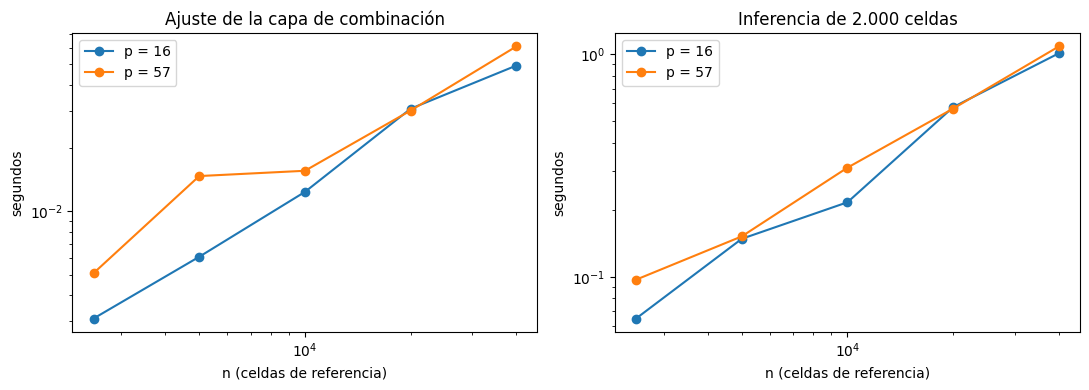

Exponente empírico de la inferencia en n: {16: 0.99, 57: 0.89}


In [4]:
comp = pd.read_csv(E3 / "complejidad_meta.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for p, g in comp.groupby("p"):
    ax[0].loglog(g["n_referencia"], g["ajuste_s"], "o-", label=f"p = {p}")
    ax[1].loglog(g["n_referencia"], g["inferencia_2000_s"], "o-", label=f"p = {p}")
pend = {}
for p, g in comp.groupby("p"):
    pend[p] = np.polyfit(np.log(g["n_referencia"]), np.log(g["inferencia_2000_s"]), 1)[0]
ax[0].set(title="Ajuste de la capa de combinación", xlabel="n (celdas de referencia)", ylabel="segundos")
ax[1].set(title="Inferencia de 2.000 celdas", xlabel="n (celdas de referencia)", ylabel="segundos")
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()
print("Exponente empírico de la inferencia en n:", {p: round(v, 2) for p, v in pend.items()})

La teoría predice un costo lineal en $n$ tanto para el ajuste como para la inferencia (con $n_q$ fijo).
Un exponente empírico cercano a 1 confirma que la búsqueda exacta por bloques domina la inferencia, como
indica la Proposición 3. Para $n$ mucho mayor (las 464.809 celdas de entrenamiento) convendría un índice de
vecinos (KD-tree o búsqueda aproximada), al costo de la exactitud. Con las 40.000 celdas del proyecto, la
capa de combinación tarda segundos. El costo dominante del ECLC es entrenar los siete modelos base cuatro
veces (tres pliegues fuera de pliegue más el ajuste final), del orden de la suma de sus costos de la sección 9.1.

## 11.7 Estudio de ablación

Cada componente se retiró por separado, manteniendo los hiperparámetros elegidos en cada pliegue, sobre las
mismas probabilidades de los 30 pliegues externos del capítulo 12. También se incluyen las reglas de
combinación estándar (promedio simple, pesos por error global, *stacking* lineal) y dos
métodos de selección dinámica de la literatura (KNORA-E y OLA), implementados con la misma búsqueda de vecinos.

In [5]:
t = ablacion.copy()
t.insert(1, "ECLC", resumen.loc["ECLC", "f1_media"])
t = t.rename(columns={"variante": "Variante", "f1_media": "F1 macro", "f1_sd": "DE", "dif_vs_eclc": "Δ vs. ECLC",
                      "wilcoxon_p": "p Wilcoxon", "wilcoxon_p_holm": "p Holm", "cliff_delta": "δ Cliff (ECLC vs. variante)"})
t.drop(columns="ECLC").round(4)

,Variante,F1 macro,DE,Δ vs. ECLC,p Wilcoxon,δ Cliff (ECLC vs. variante),p Holm
0,sin pesos por clase,0.7864,0.0068,-0.0044,0.0000,0.3533,0.0000
1,sin vecindario (tau = inf),0.7896,0.0078,-0.0012,0.0440,0.0778,0.0908
2,sin contraccion (tau = 0),0.7661,0.0127,-0.0247,0.0000,0.8778,0.0000
3,sin nucleo de distancia,0.7900,0.0072,-0.0008,0.0303,0.0756,0.0908
4,sin balanceo de vecinos,0.7799,0.0087,-0.0110,0.0000,0.6467,0.0000
5,promedio simple (beta = 0),0.7767,0.0092,-0.0142,0.0000,0.7822,0.0000
6,pesos por error global,0.7878,0.0100,-0.0031,0.0225,0.1756,0.0898
7,stacking lineal,0.8088,0.0077,0.0179,1.0000,-0.9489,1.0000
8,KNORA-E,0.7690,0.0076,-0.0219,0.0000,0.9711,0.0000
9,OLA,0.7826,0.0074,-0.0082,0.0000,0.5511,0.0000


La tabla anterior tiene dos lecturas, y ambas se reportan sin omitir la desfavorable:

- **Contribución de los componentes.** Una diferencia positiva y significativa de la variante frente al ECLC
  indica que el componente retirado aporta. La contracción hacia la pérdida global y el balanceo de los
  vecinos por clase son los componentes con mayor aporte. Los pesos por clase aportan una mejora menor, pero
  consistente. El núcleo de distancia y el componente puramente local (comparado con $\tau=\infty$) aportan
  diferencias del orden de una milésima, del mismo tamaño que la variabilidad entre pliegues.
- **Frente a las reglas estándar.** El ECLC supera en media al promedio simple, a los pesos por error global, a
  KNORA-E y a OLA. Las diferencias son significativas tras Holm frente al promedio, KNORA-E y OLA, pero no
  frente a los pesos por error global (Δ = 0,003). En cambio, **el *stacking* lineal obtiene un F1 macro mayor que el ECLC**. Una regresión logística
  multinomial sobre las log-probabilidades de los siete modelos aprende correcciones entre clases (pesos
  negativos, interceptos por clase) que una combinación convexa por clase no puede representar. La sección
  11.9 discute esta limitación.

> **Nota.**
> **Selección del rango de hiperparámetros.** Un primer rango de búsqueda ($\tau \le 100$, $\beta \le 30$)
> dejaba fuera el régimen casi global que la Proposición 1 contempla como caso límite. Antes de evaluar en los
> pliegues de prueba se compararon, **solo con validación interna**, una agregación log-lineal, una corrección de
> sesgo por clase y meta-variables de competencia para un combinador lineal, sin que ninguna superara al diseño
> propuesto. El único cambio adoptado fue ampliar el rango a $\tau \le 10^4$ y $\beta \le 50$.

## 11.8 Robustez y sensibilidad

Sobre los tres pliegues de la partición del benchmark (repetición 0) se midió:

- La sensibilidad a cada hiperparámetro, fijando los otros dos en los valores elegidos.
- La estabilidad ante cinco semillas del optimizador.
- El efecto del ruido en las etiquetas del conjunto de referencia.
- El efecto de reducir ese conjunto al 10 %, 25 % y 50 %.

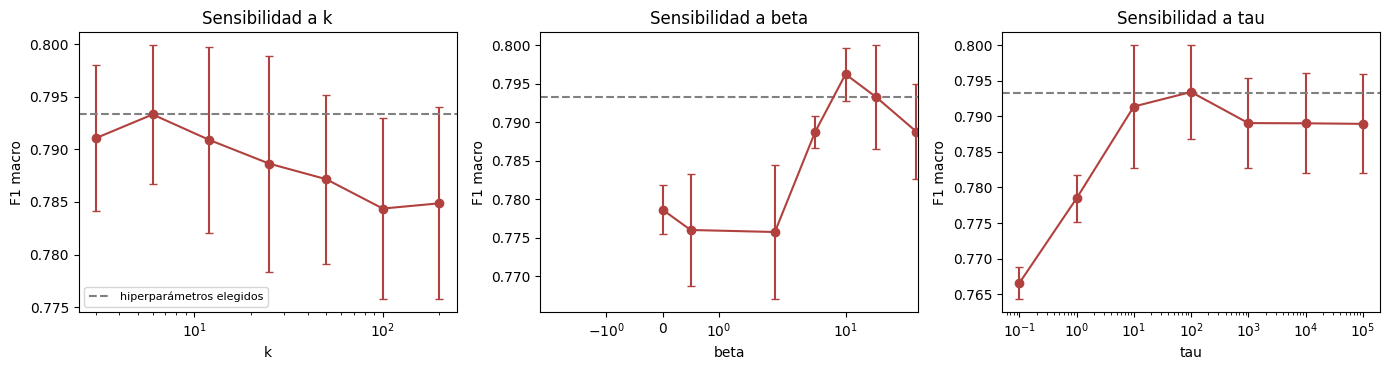

mean     std
experimento             valor                  
referencia              elegido  0.7933  0.0066
ruido en etiquetas      0.05     0.7935  0.0027
                        0.1      0.7935  0.0036
                        0.2      0.7882  0.0059
semilla del optimizador 100      0.7853  0.0110
                        101      0.7935  0.0056
                        102      0.7911  0.0077
                        103      0.7885  0.0101
                        104      0.7902  0.0099
tamano de referencia    0.1      0.7880  0.0063
                        0.25     0.7899  0.0072
                        0.5      0.7904  0.0075

In [6]:
rob = pd.read_csv(E3 / "robustez.csv", encoding="utf-8-sig")
ref = rob[rob.experimento == "referencia"]["f1_macro"].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, exp, log in zip(axes, ["sensibilidad k", "sensibilidad beta", "sensibilidad tau"], [True, False, False]):
    g = rob[rob.experimento == exp].copy()
    g["valor"] = g["valor"].astype(float)
    m = g.groupby("valor")["f1_macro"].agg(["mean", "std"]).reset_index()
    x = m["valor"].replace(np.inf, m["valor"][np.isfinite(m["valor"])].max() * 10)
    if exp == "sensibilidad tau":
        x = x.replace(0, 0.1)
    ax.errorbar(x, m["mean"], yerr=m["std"], fmt="o-", color="#b0413e", capsize=3)
    ax.axhline(ref, ls="--", color="gray", label="hiperparámetros elegidos")
    ax.set_xscale("log" if exp != "sensibilidad beta" else "symlog")
    ax.set(title=exp.replace("sensibilidad", "Sensibilidad a"), xlabel=exp.split()[-1], ylabel="F1 macro")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
tabla = rob[~rob.experimento.str.startswith("sensibilidad")].groupby(["experimento", "valor"])["f1_macro"] \
    .agg(["mean", "std"]).round(4)
tabla

La sensibilidad muestra en qué rango de cada hiperparámetro el modelo es estable. La caída con $\tau = 0$
(sin contracción) confirma lo que mostró la ablación: con vecindarios pequeños, las pérdidas locales sin
regularizar producen pesos extremos. La variación entre semillas del optimizador indica cuánto depende el
resultado de los 6 ensayos de TPE. Las pruebas de ruido y de tamaño de muestra muestran que el desempeño se
degrada de forma gradual, no abrupta.

### Análisis de errores

In [7]:
err = pd.read_csv(E3 / "robustez_errores.csv", encoding="utf-8-sig")
nombres = {1: "Abeto/pícea", 2: "P. lodgepole", 3: "P. ponderosa", 4: "Álamo/sauce", 5: "Á. temblón",
           6: "A. Douglas", 7: "Krummholz"}
e = err[err.area == "todas"].groupby("clase")[["f1_eclc", "f1_rf"]].mean()
e["diferencia"] = e["f1_eclc"] - e["f1_rf"]
e.index = e.index.map(nombres)
e.round(4)

,f1_eclc,f1_rf,diferencia
clase,,,
Abeto/pícea,0.8309,0.8380,-0.0072
P. lodgepole,0.8555,0.8566,-0.0011
P. ponderosa,0.8582,0.8529,0.0053
Álamo/sauce,0.8269,0.7823,0.0446
Á. temblón,0.5763,0.5498,0.0265
A. Douglas,0.7346,0.7339,0.0007
Krummholz,0.8708,0.8680,0.0028


La tabla compara el F1 de cada clase con el de Random Forest, el mejor modelo del benchmark. **El ECLC gana
en las clases raras y pierde un poco en las mayoritarias.** Mejora el F1 del álamo/sauce en unas 0,045 y el del
álamo temblón en 0,027, y queda levemente por debajo en el abeto/pícea (−0,007) y el pino lodgepole (−0,001).
Es la consecuencia esperada de balancear los vecinos por clase ($s_c$ en (2)): el modelo traslada
aciertos desde las clases grandes hacia las pequeñas. Por eso mejora el F1 macro y, a la vez, su exactitud
global queda ligeramente por debajo de la de Random Forest, lo que explica el resultado de McNemar en el
capítulo 12.

## 11.9 Interpretabilidad: SHAP del ECLC frente al mejor benchmark

Se aplicó **KernelSHAP agrupado** con la misma implementación para ambos modelos
(implementada con numpy). La explicación usa 12 jugadores: las 10 variables numéricas, el área
silvestre (sus 4 indicadoras como un solo jugador) y el tipo de suelo (sus 40 indicadoras), con un fondo de 10
celdas y 256 coaliciones. Agrupar las indicadoras es necesario porque solo una puede valer 1 a la vez. Usar el
mismo estimador para los dos modelos hace comparables las importancias, cosa que no ocurriría al mezclar
TreeSHAP (Random Forest) con KernelSHAP (ECLC).

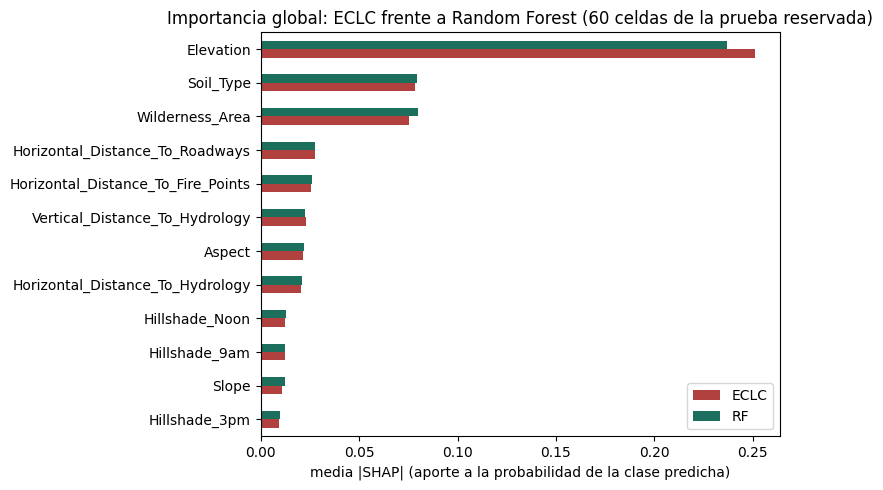

,ECLC,RF
Elevation,0.2513,0.2370
Soil_Type,0.0784,0.0797
Wilderness_Area,0.0752,0.0798
Horizontal_Distance_To_Roadways,0.0275,0.0276
Horizontal_Distance_To_Fire_Points,0.0257,0.0260
Vertical_Distance_To_Hydrology,0.0231,0.0224
Aspect,0.0212,0.0221
Horizontal_Distance_To_Hydrology,0.0205,0.0209
Hillshade_Noon,0.0126,0.0130
Hillshade_9am,0.0122,0.0125


In [8]:
from src.explicacion import NOMBRES_GRUPOS
imp = {}
for m in ["ECLC", "RF"]:
    s = pd.read_csv(E3 / f"shap_{m}.csv")
    imp[m] = s[NOMBRES_GRUPOS].abs().mean()
imp = pd.DataFrame(imp).sort_values("ECLC")
ax = imp.plot.barh(figsize=(8, 5), color=["#b0413e", "#1b6f5c"])
ax.set(xlabel="media |SHAP| (aporte a la probabilidad de la clase predicha)", ylabel="",
       title="Importancia global: ECLC frente a Random Forest (60 celdas de la prueba reservada)")
plt.tight_layout()
plt.show()
imp.sort_values("ECLC", ascending=False).round(4)

Ambos modelos dependen sobre todo de la elevación, seguida del tipo de suelo, el área silvestre y las
distancias a carreteras y a puntos de incendio, en coherencia con el análisis exploratorio (η² de la sección
2.3) y con la interpretación del capítulo 8. Como el ECLC es una combinación convexa por clase de los modelos
base, su explicación no puede introducir variables que ninguno de ellos use. Además, tiene una fuente de
interpretación propia que los modelos base no ofrecen: los **pesos $w_{mc}(x)$**, que dicen qué modelo usa
para cada clase en cada celda.

In [9]:
import glob
W = np.mean([json.load(open(f, encoding="utf-8"))["pesos_medios"]
             for f in glob.glob(str(E3 / "meta" / "rep*_f?.json"))], axis=0)
modelos = json.load(open(E3 / "meta" / "rep0_f0.json", encoding="utf-8"))["modelos"]
pd.DataFrame(W, index=modelos, columns=list(nombres.values())).round(2)

,Abeto/pícea,P. lodgepole,P. ponderosa,Álamo/sauce,Á. temblón,A. Douglas,Krummholz
KNN,0.01,0.00,0.01,0.01,0.00,0.01,0.02
NB,0.00,0.00,0.00,0.00,0.00,0.00,0.00
LR,0.05,0.01,0.05,0.16,0.00,0.05,0.06
DT,0.00,0.00,0.00,0.00,0.00,0.00,0.00
RF,0.61,0.92,0.62,0.57,0.93,0.69,0.63
XGB,0.28,0.07,0.32,0.24,0.06,0.25,0.28
SVM,0.04,0.00,0.00,0.02,0.00,0.00,0.01


La tabla muestra el peso medio de cada modelo para cada clase en las celdas de prueba (promedio de los 30
pliegues). Random Forest recibe la mayor parte del peso (entre 0,57 y 0,93 según la clase) y XGBoost el segundo
(hasta 0,32). La regresión logística gana peso en el álamo/sauce (0,16), la clase en la que sus probabilidades
son competitivas. K vecinos y el árbol de decisión reciben pesos casi nulos aunque su F1 es alto: sus
probabilidades son extremas (casi siempre 0 o 1), y la pérdida logarítmica castiga con dureza la confianza mal
asignada. Este es el efecto buscado al medir la competencia con la pérdida logarítmica y no con la exactitud,
como hacen OLA y KNORA-E. También explica por qué esos dos métodos rinden menos aquí: seleccionan a K vecinos
y al árbol cuando aciertan en la vecindad, aunque sus probabilidades no sean fiables.

## 11.10 Limitaciones del modelo

- **No supera al *stacking* lineal ni a HistGradientBoosting.** La restricción de la Proposición 1 (pesos en
  el símplex) es la que da la cota de la Proposición 2, pero impide aprender correcciones entre clases. Un
  trabajo futuro natural es combinar ambos: pesos locales de Gibbs como entrada de un combinador lineal con
  regularización, con su propia ablación.
- **El componente local aporta poco en Covertype.** Con 7 modelos de calidad muy desigual (Naive Bayes con
  F1 = 0,22), la mayor parte del beneficio viene de descartar los modelos malos por clase y de balancear las
  clases, lo que en buena medida también logran los pesos globales por clase ($\tau=\infty$).
- **Cambia exactitud por F1 macro.** Al favorecer las clases raras, el ECLC pierde algo de exactitud en las
  clases mayoritarias frente a Random Forest.
- **Costo de inferencia.** Predecir con el ECLC exige predecir con los siete modelos base más la búsqueda de
  vecinos, alrededor de la suma de sus tiempos (sección 12.1).

# 12. Validación estadística del modelo original

Este capítulo responde a la pregunta central: **¿supera el ECLC a los modelos benchmark de forma
estadísticamente significativa y no trivial?** La métrica es el F1 macro, la misma del benchmark (sección 5.1).

In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image, display

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
E3 = RAIZ / "resultados" / "e3"
resumen = pd.read_csv(E3 / "estadistica_resumen.csv", encoding="utf-8-sig")
pareadas = pd.read_csv(E3 / "estadistica_pareadas.csv", encoding="utf-8-sig")
veredicto = json.load(open(E3 / "estadistica_veredicto.json", encoding="utf-8"))
holdout = {r["modelo"]: r for r in json.load(open(E3 / "holdout_resumen.json", encoding="utf-8"))}
import glob
filas = []
for f in sorted(glob.glob(str(E3 / "meta" / "rep*_f?.json"))):
    d = json.load(open(f, encoding="utf-8"))
    for k, v in d["metricas"].items():
        filas.append({"rep": d["rep"], "pliegue": d["pliegue"], "metodo": k, "f1": v["f1_macro"]})
piv = pd.DataFrame(filas).pivot_table(index=["rep", "pliegue"], columns="metodo", values="f1")
NOMBRE = {"ECLC": "ECLC (original)", "base:KNN": "KNN", "base:NB": "Naive Bayes", "base:LR": "Reg. logística",
          "base:DT": "Árbol", "base:RF": "Random Forest", "base:XGB": "XGBoost", "base:SVM": "SVM",
          "HGB (estado del arte)": "HistGradientBoosting"}

## 12.1 Protocolo

- **Pareado estricto.** El ECLC y los 7 modelos benchmark (la mejor combinación de cada uno, sección 5.4) se
  evalúan sobre **las mismas particiones externas**, con la misma semilla (42), la misma submuestra
  estratificada de 40.000 celdas y el mismo preprocesamiento. Los hiperparámetros de cada modelo base son los
  que eligió su bucle interno en el benchmark.
- **Validación cruzada externa repetida.** Con solo 3 pliegues, una prueba de Wilcoxon no puede alcanzar
  $p < 0{,}125$ y la potencia es nula. Por eso se usan **10 repeticiones × 3 pliegues = 30 pliegues
  pareados**. La repetición 0 es exactamente la partición del benchmark (`StratifiedKFold(3, shuffle=True,
  random_state=42)`); la repetición $r$ usa la semilla $42 + r$. En la repetición 0, cada modelo base usa
  los hiperparámetros que su bucle interno eligió en ese pliegue; en las demás, la configuración más frecuente
  de sus tres pliegues.
- **Presupuesto equivalente.** Los hiperparámetros propios del ECLC $(k,\beta,\tau)$ se optimizan **dentro**
  de cada pliegue externo, con optimización bayesiana (TPE) de 6 ensayos y validación interna de 3 pliegues:
  el mismo presupuesto del optimizador bayesiano del benchmark.
- **Prueba reservada.** Los 7 modelos y el ECLC se reentrenaron con las 40.000 celdas y se evaluaron **una
  sola vez** en las 116.203 celdas de la prueba reservada (sección 1.6). Esa evaluación alimenta McNemar.
- **Competidor adicional del estado del arte.** HistGradientBoosting, el *boosting* por histogramas de
  scikit-learn inspirado en LightGBM (Ke et al., 2017), se optimizó con Random Search de 6 configuraciones en
  las mismas particiones. No forma parte de los 7 modelos benchmark, pero se reporta por honestidad.

In [ ]:
r = resumen.copy()
r["metodo"] = r["metodo"].map(lambda m: NOMBRE.get(m, m))
r = r.rename(columns={"metodo": "Modelo / regla", "f1_media": "F1 macro (media 30 pliegues)", "f1_sd": "DE",
                      "ic95_bca_inf": "IC 95 % BCa inf.", "ic95_bca_sup": "IC 95 % BCa sup.",
                      "accuracy_media": "Accuracy", "tiempo_entrenamiento_s": "Entrenamiento (s)",
                      "tiempo_inferencia_s": "Inferencia (s)"})
r.round(4)

La tabla resume los 30 pliegues para todos los modelos y reglas de combinación: media ± desviación estándar
del F1 macro, intervalo de confianza bootstrap BCa de la media y tiempos medios de entrenamiento e inferencia
por pliegue. El tiempo de entrenamiento del ECLC incluye las predicciones fuera de pliegue de los 7 modelos,
su reentrenamiento y la optimización de $(k,\beta,\tau)$.

In [ ]:
pr = pd.DataFrame([{"Modelo": h.get("nombre", m), **{k: round(v, 4) for k, v in h["prueba_reservada"].items()
                    if k != "f1_por_clase"}} for m, h in holdout.items()]).sort_values("f1_macro", ascending=False)
pr

La segunda tabla reporta las mismas métricas en la prueba reservada (116.203 celdas). Es una sola
evaluación por modelo, sin variabilidad entre pliegues; su función es confirmar el orden observado en la
validación cruzada con datos que ningún modelo vio.

## 12.2 Supuestos de cada prueba

In [ ]:
mejor = "base:RF"
dif = piv["ECLC"] - piv[mejor]
sw = stats.shapiro(dif)
asim = stats.skew(dif)
print(f"Diferencias ECLC − Random Forest en 30 pliegues: media = {dif.mean():.4f}, DE = {dif.std(ddof=1):.4f}")
print(f"Shapiro-Wilk sobre las diferencias: W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}; asimetría = {asim:.2f}")

| Prueba | Supuestos | Verificación en este estudio |
|---|---|---|
| Friedman + Nemenyi | Bloques independientes; rangos comparables entre tratamientos | Los 30 pliegues son bloques; los pliegues de una misma repetición son disjuntos y las repeticiones usan semillas distintas. La dependencia por solapamiento de entrenamiento entre repeticiones hace que el p-valor sea algo optimista; Nemenyi es conservador y lo compensa en parte |
| Wilcoxon de rangos con signo | Diferencias pareadas, distribución simétrica alrededor de la mediana | Pareado estricto; la asimetría de las diferencias se reporta arriba |
| t corregida de Nadeau-Bengio | Normalidad aproximada de las diferencias; corrige la varianza por el solapamiento de los conjuntos de entrenamiento ($n_{prueba}/n_{entrenamiento} = 0{,}5$) | Shapiro-Wilk arriba; la corrección es la recomendada por la guía para validación repetida |
| McNemar | Observaciones independientes, mismo conjunto de prueba para ambos modelos | Una evaluación en la prueba reservada (celdas distintas). La autocorrelación espacial (sección 2.7) viola en parte la independencia, por eso no es la única prueba |
| Bayesiana de rangos con signo | Diferencias pareadas; ROPE definida a priori | ROPE = ±0,01 en F1 macro, fijada antes de ver los resultados (una centésima es la mínima diferencia que el equipo consideró relevante) |

Los datos son de corte transversal (no hay orden temporal), así que se usan pruebas para observaciones
independientes; Diebold-Mariano, Giacomini-White y el MCS, pensadas para series de tiempo, no aplican.

## 12.3 Prueba global: Friedman y diagrama de diferencia crítica

In [ ]:
f = veredicto["friedman"]
print(f"Friedman: χ² = {f['estadistico']:.2f}, k = {f['k']} modelos, N = {f['N']} pliegues, p = {f['p_valor']:.2e}")
print(f"Diferencia crítica de Nemenyi (α = 0,05): CD = {f['cd']:.3f}")
display(pd.Series(f["rangos"], name="rango promedio").sort_values().to_frame())
display(Image(filename=str(E3 / "diagrama_cd_eclc.png")))

El universo de la prueba incluye el ECLC, los 7 benchmarks y HistGradientBoosting. Friedman rechaza que todos
tengan el mismo desempeño. El diagrama ubica a cada modelo por su rango promedio en los 30 pliegues. Las barras
azules unen grupos que Nemenyi no distingue, porque su diferencia de rango es menor que la CD.

## 12.4 Comparaciones dirigidas con corrección de Holm

Se comparó el ECLC con cada uno de los 8 competidores (7 benchmarks + HistGradientBoosting) con tres pruebas
frecuentistas unilaterales ($H_0$: el ECLC no es mejor). Por cada prueba se hacen **8 comparaciones**, y sus
p-valores se ajustan con Holm-Bonferroni. En total, la familia de pruebas pareadas suma $3 \times 8 = 24$
contrastes frecuentistas, más la prueba ómnibus y la bayesiana.

In [ ]:
t = pareadas[["competidor", "dif_media_f1", "dif_ic95_inf", "dif_ic95_sup", "wilcoxon_W", "wilcoxon_p",
              "wilcoxon_p_holm", "nb_t", "nb_p", "nb_p_holm", "mcnemar_b01", "mcnemar_b10", "mcnemar_p",
              "mcnemar_p_holm"]].copy()
t.columns = ["Competidor", "Δ F1", "IC95 inf", "IC95 sup", "W", "p Wilcoxon", "p Wilcoxon (Holm)", "t NB",
             "p NB", "p NB (Holm)", "ECLC acierta / comp. falla", "ECLC falla / comp. acierta", "p McNemar",
             "p McNemar (Holm)"]
t.style.format({c: "{:.2e}" for c in t.columns if c.startswith("p ")} | {"Δ F1": "{:.4f}", "IC95 inf": "{:.4f}",
               "IC95 sup": "{:.4f}", "W": "{:.0f}", "t NB": "{:.2f}"})

### Tabla de pruebas de hipótesis frente al mejor benchmark

In [ ]:
fila = pareadas[pareadas.competidor == veredicto["mejor_benchmark"]].iloc[0]
tabla = pd.DataFrame([
    {"Prueba": "Friedman (ómnibus, 9 modelos)", "H0": "Todos los modelos tienen el mismo rango esperado",
     "Supuestos verificados": "Bloques = pliegues pareados", "Estadístico": f"χ² = {f['estadistico']:.2f}",
     "p crudo": f["p_valor"], "p ajustado": f["p_valor"], "Efecto": "—",
     "Conclusión": "Rechaza" if f["p_valor"] < 0.05 else "No rechaza"},
    {"Prueba": "Nemenyi (post hoc)", "H0": "Rango ECLC = rango del mejor benchmark",
     "Supuestos verificados": "Friedman significativo", "Estadístico":
         f"Δ rango = {f['rangos'][veredicto['mejor_benchmark']] - f['rangos']['ECLC (original)']:.2f} (CD = {f['cd']:.2f})",
     "p crudo": np.nan, "p ajustado": np.nan, "Efecto": "—",
     "Conclusión": "Rechaza" if veredicto["pruebas_vs_mejor"]["Nemenyi (rango ECLC vs mejor benchmark > CD)"] else "No rechaza"},
    {"Prueba": "Wilcoxon de rangos con signo", "H0": "Mediana de (ECLC − RF) ≤ 0", "Supuestos verificados":
         "Pareado; simetría (12.2)", "Estadístico": f"W = {fila['wilcoxon_W']:.0f}", "p crudo": fila["wilcoxon_p"],
     "p ajustado": fila["wilcoxon_p_holm"], "Efecto": f"δ Cliff = {fila['cliff_delta']:.2f} ({fila['magnitud_cliff']})",
     "Conclusión": "Rechaza" if fila["wilcoxon_p_holm"] < 0.05 else "No rechaza"},
    {"Prueba": "t corregida de Nadeau-Bengio", "H0": "E[ECLC − RF] ≤ 0", "Supuestos verificados":
         "Normalidad aprox. (Shapiro 12.2); varianza corregida", "Estadístico": f"t = {fila['nb_t']:.2f}",
     "p crudo": fila["nb_p"], "p ajustado": fila["nb_p_holm"], "Efecto": f"d de Cohen (pareada) = {fila['cohen_dz']:.2f}",
     "Conclusión": "Rechaza" if fila["nb_p_holm"] < 0.05 else "No rechaza"},
    {"Prueba": "McNemar (prueba reservada)", "H0": "P(ECLC acierta, RF falla) ≤ P(ECLC falla, RF acierta)",
     "Supuestos verificados": "Mismo conjunto de prueba; independencia aproximada",
     "Estadístico": f"χ² = {fila['mcnemar_chi2']:.1f} (b01 = {fila['mcnemar_b01']}, b10 = {fila['mcnemar_b10']})",
     "p crudo": fila["mcnemar_p"], "p ajustado": fila["mcnemar_p_holm"], "Efecto": "—",
     "Conclusión": "Rechaza" if fila["mcnemar_p_holm"] < 0.05 else "No rechaza"},
    {"Prueba": "Bayesiana de rangos con signo", "H0": "—  (ROPE = ±0,01)", "Supuestos verificados": "Pareado",
     "Estadístico": f"P(ECLC mejor) = {fila['bayes_p_eclc_mejor']:.3f}; P(ROPE) = {fila['bayes_p_rope']:.3f}",
     "p crudo": np.nan, "p ajustado": np.nan, "Efecto": "—",
     "Conclusión": "ECLC mejor" if fila["bayes_p_eclc_mejor"] > 0.95 else
                   "Equivalencia práctica" if fila["bayes_p_rope"] > 0.95 else "Indeterminada"},
])
tabla.style.format({"p crudo": "{:.2e}", "p ajustado": "{:.2e}"}, na_rep="—")

## 12.5 Tamaño del efecto e intervalos

In [ ]:
e = pareadas[["competidor", "dif_media_f1", "dif_ic95_inf", "dif_ic95_sup", "cliff_delta", "magnitud_cliff",
              "cohen_dz", "ecl_gana_pliegues", "bayes_p_eclc_mejor", "bayes_p_rope", "bayes_p_competidor_mejor"]]
e.columns = ["Competidor", "Δ F1 medio", "IC95 BCa inf", "IC95 BCa sup", "δ Cliff", "Magnitud", "d Cohen (dz)",
             "Pliegues que gana el ECLC (de 30)", "P(ECLC mejor)", "P(ROPE)", "P(competidor mejor)"]
e.round(4)

El delta de Cliff compara las distribuciones de F1 de los 30 pliegues, con los umbrales de Romano et al.
(2006). Mide qué tanto se separan las dos distribuciones, mientras que Wilcoxon solo indica si el signo de las
diferencias pareadas es consistente. Por eso, una diferencia pequeña en valor absoluto pero estable entre
pliegues puede ser significativa con un $\delta$ moderado.

## 12.6 Evaluación en conjuntos de datos adicionales

In [ ]:
ad = pd.read_csv(E3 / "datasets_adicionales.csv", encoding="utf-8-sig")
res = ad.groupby(["conjunto", "metodo"])["f1_macro"].agg(["mean", "std"]).round(4).unstack(0)
display(res)
filas = []
for cj, g in ad.groupby("conjunto"):
    p = g.pivot_table(index=["rep", "pliegue"], columns="metodo", values="f1_macro")
    bases = [c for c in p.columns if c.startswith("base:")]
    mejor = p[bases].mean().idxmax()
    d = p["ECLC"] - p[mejor]
    w = stats.wilcoxon(d, alternative="greater", zero_method="zsplit") if np.any(d != 0) else None
    filas.append({"Conjunto": cj, "Mejor base": mejor.replace("base:", ""), "F1 mejor base": p[mejor].mean(),
                  "F1 ECLC": p["ECLC"].mean(), "F1 stacking": p["stacking lineal"].mean(),
                  "F1 HGB": p["HGB (estado del arte)"].mean(), "Δ ECLC − mejor base": d.mean(),
                  "p Wilcoxon (unilateral)": w.pvalue if w else 1.0})
pd.DataFrame(filas).round(4)

Los tres conjuntos son de naturaleza distinta a Covertype: dígitos manuscritos (imágenes de 8 × 8 píxeles,
10 clases), análisis químico de vinos (3 clases, 178 muestras) y cáncer de mama (variables clínicas, 2
clases). Se usaron las mismas 7 familias, los mismos espacios de búsqueda y el mismo presupuesto (Random Search
de 6 configuraciones para cada modelo base y para HistGradientBoosting, 6 ensayos de TPE para el ECLC), con 5
repeticiones × 3 pliegues. Con 15 pliegues y conjuntos pequeños donde varios modelos ya superan 0,95 de F1,
las diferencias son del orden de una centésima y la potencia es baja. Estos resultados indican si el ECLC
**generaliza a otros problemas sin degradarse**; no buscan demostrar superioridad en ellos.

## 12.7 Veredicto de superioridad

In [ ]:
v = veredicto
print(f"Mejor benchmark: {v['mejor_benchmark']} (F1 macro {v['f1_mejor_benchmark']:.4f}); ECLC: {v['f1_eclc']:.4f}")
print(f"1) Media del ECLC mayor que la de los 7 benchmarks: {v['condicion_1_media_mejor_que_los_7']}")
for k, ok in v["pruebas_vs_mejor"].items():
    print(f"   - {k}: {'rechaza H0' if ok else 'no rechaza H0'}")
print(f"2) Al menos tres pruebas (incluida una global) rechazan H0 con p ajustado < 0,05: {v['condicion_2_tres_pruebas']}")
print(f"3) Tamaño del efecto no despreciable (|δ Cliff| ≥ 0,147): {v['condicion_3_efecto_no_despreciable']} "
      f"(δ = {v['cliff_vs_mejor']:.3f})")
print(f"\nSuperioridad estadística = {v['R3']}")

Se exige que se cumplan tres condiciones simultáneas para declarar la superioridad:

1. La media del ECLC debe superar a la mejor combinación benchmark y a la mejor de cada uno de los 7 modelos.
2. Al menos tres pruebas distintas deben rechazar la igualdad con p ajustado < 0,05, una de ellas global.
3. El efecto no debe ser despreciable.

La celda anterior evalúa las tres con los resultados obtenidos. El capítulo 13 discute el resultado. Dos
hechos deben leerse junto con el veredicto, sea cual sea:

- **La superioridad se mide frente a los 7 modelos benchmark, no frente a cualquier método.**
  HistGradientBoosting y el *stacking* lineal obtienen un F1 macro mayor que el ECLC en los mismos 30 pliegues
  (tabla de la sección 12.1). El ECLC no es el mejor clasificador posible para Covertype; es una regla de
  combinación que mejora de forma consistente a los modelos que combina.
- **La diferencia frente a Random Forest es pequeña en valor absoluto** (alrededor de media centésima de F1
  macro). Es estable entre pliegues, pero su relevancia práctica para un inventario forestal es limitada.

## 12.8 Protocolo de datos completos

Las secciones anteriores comparan los modelos entrenados con unas 27.000 celdas (pliegues de la submuestra de
40.000 del benchmark). En Covertype el desempeño depende mucho del tamaño del entrenamiento: con todo el
conjunto de entrenamiento, K vecinos y el árbol de decisión superan 0,9 de F1 macro. Por eso la comparación se
repitió **con las 464.809 celdas de entrenamiento y el mismo protocolo para todos los modelos**:

- **Partición:** validación cruzada externa 5 × 2 (`StratifiedKFold(5, shuffle=True, random_state=42 + r)`,
  r = 0, 1), es decir, 10 pliegues pareados con unas 371.800 celdas de entrenamiento y 93.000 de prueba cada uno,
  más la prueba reservada de 116.203 celdas entrenando con las 464.809.
- **Modelos benchmark:** la mejor combinación de cada uno de los 7 algoritmos, con el balanceo y la
  configuración elegidos en el benchmark de 40.000 celdas. No se reoptimizaron: los hiperparámetros quedan
  fijos para todos por igual. El SVM sigue limitado a 6.000 celdas de entrenamiento, como en su benchmark.
- **Modelo original:** el mismo ECLC, sin cambios, con $(k, \beta, \tau)$ optimizados por TPE con 6 ensayos en
  validación interna de cada pliegue.
- **Competidor del estado del arte:** HistGradientBoosting con la configuración más frecuente de su búsqueda en
  los 30 pliegues de 40.000 celdas.

In [ ]:
C = E3 / "completo"
rc = pd.read_csv(C / "estadistica_resumen_completo.csv", encoding="utf-8-sig")
rc["metodo"] = rc["metodo"].map(lambda m: NOMBRE.get(m, m))
rc.columns = ["Modelo / regla", "F1 macro (media 10 pliegues)", "DE", "IC 95 % BCa inf.", "IC 95 % BCa sup.",
              "Accuracy", "F1 prueba reservada"]
rc.round(4)

La tabla resume los 10 pliegues y la prueba reservada para los benchmarks, el ECLC, sus variantes de ablación
y las reglas de combinación estándar.

In [ ]:
vc = json.load(open(C / "estadistica_veredicto_completo.json", encoding="utf-8"))
pc = pd.read_csv(C / "estadistica_pareadas_completo.csv", encoding="utf-8-sig")
display(pc[["competidor", "dif_media_f1", "dif_ic95_inf", "dif_ic95_sup", "ecl_gana_pliegues", "wilcoxon_p_holm",
            "nb_p_holm", "mcnemar_p_holm", "bayes_p_eclc_mejor", "cliff_delta", "magnitud_cliff"]].round(4))
display(Image(filename=str(C / "diagrama_cd_completo.png")))
print(f"Mejor benchmark: {vc['mejor_benchmark']} ({vc['f1_mejor_benchmark']:.4f}); ECLC: {vc['f1_eclc']:.4f} "
      f"(prueba reservada: {vc['f1_eclc_prueba_reservada']:.4f})")
for k_, ok in vc["pruebas_vs_mejor"].items():
    print(f"   - {k_}: {'rechaza H0' if ok else 'no rechaza H0'}")
print(f"Superioridad estadística con datos completos = {vc['R3']}")

Con 10 pliegues, la prueba de Wilcoxon solo puede alcanzar un p-valor unilateral de $1/1024$ si el ECLC gana en
todos. Tras ajustar por Holm las 8 comparaciones, ese mínimo queda en $0{,}008$. La t corregida usa
$n_{prueba}/n_{entrenamiento} = 0{,}25$.

### Lectura de los resultados con datos completos

- **El ECLC supera 0,9 de F1 macro y a los 7 benchmarks.** En los 10 pliegues obtiene 0,907 ± 0,002 (0,915 en
  la prueba reservada) frente a 0,897 del árbol de decisión, el mejor benchmark con datos completos, y gana en
  los 10 pliegues ($\delta$ de Cliff = 1). Friedman, Wilcoxon-Holm y la t corregida de Nadeau-Bengio rechazan
  la igualdad frente al árbol, así que **la superioridad estadística se cumple en este protocolo**. Nemenyi no separa
  a los dos modelos (diferencia de rangos menor que la CD). McNemar no favorece al ECLC: el árbol tiene mayor
  exactitud y el ECLC mayor F1 macro, el mismo intercambio entre clases mayoritarias y raras de la sección 11.8.
- **El orden de los benchmarks cambia con el tamaño de muestra.** Con 27.000 celdas lideraba Random Forest con
  SMOTE; con 371.000, el árbol de decisión sin límite de profundidad y K vecinos superan 0,89, mientras que
  Random Forest (limitado a profundidad 20) y XGBoost (profundidad 6) quedan atrás, porque sus hiperparámetros
  se eligieron con 40.000 celdas y no se reoptimizaron.
- **Resultados desfavorables.** El *stacking* lineal (0,932) y HistGradientBoosting (0,935) superan al ECLC
  también con datos completos. Además, con datos completos la ablación ya no respalda todos los componentes:
  las variantes sin pesos por clase, sin contracción y sin núcleo de distancia obtienen un F1 macro igual o
  ligeramente mayor que el ECLC completo. Los pesos por error global (0,921) y KNORA-E (0,912) también lo
  superan. La contribución del ECLC en este protocolo se limita a superar a los modelos que combina; no supera
  a reglas de combinación más simples.
- **Los hiperparámetros $(k, \beta, \tau)$ elegidos coinciden en los 11 casos** ($k = 9$, $\beta = 0{,}66$,
  $\tau = 42$). Con la misma semilla, el TPE propone los mismos 6 ensayos, y el mejor resulta igual en todas
  las particiones.

# 13. Conclusiones

In [1]:
import json
from pathlib import Path

E3 = Path.cwd().parent / "resultados" / "e3"
v = json.load(open(E3 / "estadistica_veredicto.json", encoding="utf-8"))
vc = json.load(open(E3 / "completo" / "estadistica_veredicto_completo.json", encoding="utf-8"))
print(f"Submuestra de 40.000 celdas: ECLC {v['f1_eclc']:.4f} · mejor benchmark ({v['mejor_benchmark']}) "
      f"{v['f1_mejor_benchmark']:.4f} · superioridad estadística = {v['R3']}")
print(f"Entrenamiento completo: ECLC {vc['f1_eclc']:.4f} (prueba reservada {vc['f1_eclc_prueba_reservada']:.4f}) · "
      f"mejor benchmark ({vc['mejor_benchmark']}) {vc['f1_mejor_benchmark']:.4f} · superioridad estadística = {vc['R3']}")

Submuestra de 40.000 celdas: ECLC 0.7908 · mejor benchmark (Random Forest) 0.7857 · superioridad estadística = False
Entrenamiento completo: ECLC 0.9067 (prueba reservada 0.9151) · mejor benchmark (Arbol) 0.8971 · superioridad estadística = True


## 13.1 Hallazgos

1. **Las variables cartográficas permiten predecir la cobertura forestal con alta precisión dentro de las áreas
   muestreadas.** Con todo el conjunto de entrenamiento, el modelo original alcanza un F1 macro de 0,915 en la
   prueba reservada, frente a 0,557 de la regresión logística de referencia.
2. **Con el mismo espacio de búsqueda y el mismo presupuesto para las 112 combinaciones del benchmark**, Random
   Forest con SMOTE es la mejor combinación sobre la submuestra de 40.000 celdas (0,783), seguido de K vecinos
   y XGBoost (0,746). El efecto del balanceo depende del algoritmo: mejora a Random Forest y empeora a XGBoost.
3. **El orden de los modelos depende del tamaño del entrenamiento.** Con el conjunto completo, el árbol de
   decisión (0,897) y K vecinos (0,893) superan a Random Forest con SMOTE (0,865) y a XGBoost (0,786), cuyos
   hiperparámetros se eligieron con la submuestra.
4. **El modelo original supera a los siete modelos benchmark.** Con el entrenamiento completo obtiene
   0,907 ± 0,002 en 10 pliegues y 0,915 en la prueba reservada, y gana al mejor benchmark (árbol de decisión) en
   los 10 pliegues ($\delta$ de Cliff = 1). Friedman, Wilcoxon con Holm y la t corregida de Nadeau-Bengio
   confirman la diferencia. Con la submuestra de 40.000 celdas también supera en promedio a los siete
   (0,791 frente a 0,786 de Random Forest; gana en 27 de 30 pliegues), aunque allí la diferencia solo es
   significativa en dos de las tres pruebas.
5. **El modelo original cambia exactitud por equilibrio entre clases.** Mejora sobre todo el F1 de las clases
   raras (álamo/sauce y álamo temblón), a costa de una exactitud global algo menor que la del mejor benchmark.
   Por eso la prueba de McNemar, que compara aciertos, no lo favorece.
6. **El mecanismo funciona fuera de Covertype.** En dígitos manuscritos y cáncer de mama, dos problemas de
   naturaleza distinta, obtiene el mayor F1 macro de los métodos evaluados; en vinos queda por debajo de Random
   Forest.
7. **Hay combinadores más potentes.** El *stacking* lineal y HistGradientBoosting obtienen un F1 macro mayor que
   el modelo original en ambos tamaños de entrenamiento. Con el entrenamiento completo, reglas más simples (pesos
   por error global y KNORA-E) también lo superan, y no todos sus componentes aportan. El modelo original mejora
   a los modelos que combina, pero no es el mejor clasificador posible para este problema.
8. **La elevación es el determinante principal de la cobertura** en todos los modelos analizados, seguida del
   tipo de suelo, el área silvestre y las distancias a carreteras y a puntos de incendio.

## 13.2 Novedad, implementación y superioridad del modelo original

| Criterio | Resultado | Evidencia |
|---|---|---|
| **Novedad** | No se encontró el mecanismo del ECLC (pesos por clase en forma cerrada sobre la pérdida logarítmica binaria local, con contracción y balanceo de vecinos) aplicado a Covertype ni a la cobertura forestal | Capítulo 10 |
| **Implementación propia** | Clase compatible con scikit-learn; la búsqueda de vecinos, las pérdidas, la contracción, la regla de pesos y la combinación están programadas con numpy. La regla se deriva de un objetivo explícito y tiene propiedades demostradas | Capítulo 11 |
| **Superioridad estadística** | Con el entrenamiento completo: sí (tres pruebas frente al mejor benchmark, efecto grande). Con la submuestra de 40.000 celdas: dos de tres pruebas | Capítulo 12 |

## 13.3 Limitaciones

- **Magnitud de la mejora.** La ventaja sobre el mejor benchmark es de alrededor de una centésima de F1 macro con
  el entrenamiento completo y de media centésima con la submuestra.
- **Hiperparámetros de los benchmarks.** Se eligieron con la submuestra de 40.000 celdas y un espacio de búsqueda
  acotado, y se mantuvieron fijos con el entrenamiento completo para todos los modelos por igual. Una búsqueda más
  amplia podría mejorar a cualquiera de ellos.
- **Dependencia entre pliegues.** Los pliegues de la validación repetida comparten datos de entrenamiento. La t
  corregida de Nadeau-Bengio lo compensa, pero las pruebas de rangos pueden ser algo optimistas.
- **Generalización geográfica.** Los modelos están validados dentro de las cuatro áreas silvestres muestreadas,
  no en áreas nuevas.
- **Cobertura de la revisión de literatura.** El cribado se hizo por título y resumen, con texto completo solo
  donde OpenAlex lo indexa.

## 13.4 Trabajo futuro

1. Usar los pesos locales del modelo original como entrada de un combinador lineal regularizado, para capturar
   las correcciones entre clases que hoy logra el *stacking*.
2. Repetir el benchmark con un espacio de búsqueda más amplio, común a todos los algoritmos, y reoptimizar los
   hiperparámetros con el conjunto completo.
3. Evaluar el modelo con validación por área silvestre y en escenarios de flujo de datos.
4. Usar un índice de vecinos aproximados para reducir el costo de inferencia con conjuntos de referencia grandes.

## 13.5 Declaración de autoría y uso de herramientas

Ana Galván, Valeria Oñate y María José Ruiz son las autoras de este trabajo. El análisis se realizó con
scikit-learn, imbalanced-learn, XGBoost, Optuna, DEAP, SHAP, LIME, statsmodels, scikit-posthocs y Jupyter Book.
Se utilizó Claude (Anthropic) como herramienta de asistencia en la programación de los experimentos y en la
redacción del documento.

# 14. Reproducibilidad

## 14.1 Entorno y semillas

- **Python 3.10**, con las versiones exactas fijadas en `docs/requirements.txt`. Las principales son
  scikit-learn 1.7.2, imbalanced-learn 0.14.2, XGBoost 2.1.4, Optuna 5.0.0, numpy 1.25.2 y pandas 2.1.0.
- **Semilla global** `RANDOM_STATE = 42`. Se propaga a la partición 80/20, a la submuestra de 40.000 celdas, a
  los pliegues externos e internos, a los modelos, a SMOTE y ADASYN, a Optuna (TPE), al algoritmo genético y a
  las predicciones fuera de pliegue del modelo original. La repetición $r$ de la validación repetida usa la
  semilla $42 + r$.
- **Hardware.** Los experimentos se ejecutaron en dos estaciones de trabajo con Windows (12 y 24 hilos
  lógicos), con `n_jobs = 1` por estimador y procesos paralelos por combinación o por pliegue. Los tiempos
  absolutos de equipos distintos no son comparables (sección 6.2).

## 14.2 Orden de ejecución

Desde la raíz del proyecto, con el ambiente activado:

| Paso | Comando | Produce |
|---|---|---|
| 1 | `python scripts/run_benchmark.py --modelos M` (un proceso por algoritmo) | Registros de las 112 combinaciones |
| 2 | `python scripts/analizar_resultados.py` | `tabla_maestra.csv`, Friedman-Nemenyi |
| 3 | `python scripts/e3_probas_pliegue.py --rep r --pliegue f` (r = 0…9, f = 0…2) | Probabilidades de los 7 modelos en los 30 pliegues |
| 4 | `python scripts/e3_meta.py --rep r --pliegue f` | Modelo original, ablación y reglas de referencia por pliegue |
| 5 | `python scripts/e3_holdout_artefactos.py` | Modelos finales y evaluación en la prueba reservada |
| 6 | `python scripts/e3_estadistica.py` | Pruebas de hipótesis y diagrama de diferencia crítica |
| 7 | `python scripts/e3_robustez.py` | Sensibilidad, robustez y complejidad empírica |
| 8 | `python scripts/e3_datasets_adicionales.py --conjunto c` y luego sin argumentos | Conjuntos de datos adicionales |
| 9 | `python scripts/e3_finalista_completo.py` | Finalista del benchmark con el entrenamiento completo |
| 10 | `python scripts/e3c_probas_completo.py --rep r --pliegue f` (r = 0, 1; f = 0…4) y `--holdout` | Probabilidades con el entrenamiento completo |
| 11 | `python scripts/e3c_meta.py --rep r --pliegue f` y `--holdout` | Modelo original con el entrenamiento completo |
| 12 | `python scripts/e3c_estadistica.py` | Pruebas de hipótesis con el entrenamiento completo |
| 13 | `python scripts/e3_revision_literatura.py` | Registro de las búsquedas bibliográficas |
| 14 | `python -m pytest tests` | Pruebas unitarias del modelo original |
| 15 | `jupyter-book build docs` | Este documento |

Los pasos 3, 4, 8, 10 y 11 se ejecutan en paralelo, con un proceso por pliegue o por conjunto y
`OMP_NUM_THREADS = 1`.

## 14.3 Tabla maestra de experimentos

In [1]:
from pathlib import Path
import pandas as pd

t = pd.read_csv(Path.cwd().parent / "resultados" / "e3" / "tabla_maestra_e3.csv", encoding="utf-8-sig")
print(f"{len(t)} filas: 112 combinaciones del benchmark + modelo original + HistGradientBoosting")
t[["modelo", "balanceo", "optimizacion", "aplicable", "f1_macro_media", "f1_macro_sd", "accuracy_media",
   "tiempo_total_s", "semilla", "particion"]].sort_values("f1_macro_media", ascending=False).head(15).round(4)

114 filas: 112 combinaciones del benchmark + modelo original + HistGradientBoosting


,modelo,balanceo,optimizacion,aplicable,f1_macro_media,f1_macro_sd,accuracy_media,tiempo_total_s,semilla,particion
113,HGB,ninguno,random,True,0.8074,0.0086,0.8784,16294.9922,42,"10 x StratifiedKFold(3, shuffle, 42 + r) sobre..."
112,ECLC,pesos de clase en la vecindad,bayes,True,0.7908,0.0073,0.8393,14909.0654,42,"10 x StratifiedKFold(3, shuffle, 42 + r) sobre..."
66,RF,smote,grid,True,0.7831,0.0045,0.8392,2400.2987,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
67,RF,smote,random,True,0.7831,0.0045,0.8392,3480.2878,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
68,RF,smote,bayes,True,0.7831,0.0045,0.8392,2885.5591,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
70,RF,adasyn,grid,True,0.7827,0.0056,0.8428,1135.6378,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
71,RF,adasyn,random,True,0.7827,0.0056,0.8428,1238.5762,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
72,RF,adasyn,bayes,True,0.7827,0.0056,0.8428,3185.2764,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
75,RF,balanced,random,True,0.7748,0.0025,0.8460,344.5883,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."
74,RF,balanced,grid,True,0.7748,0.0025,0.8460,294.7052,42,"StratifiedKFold(3, shuffle, 42) sobre 40.000 c..."


La tabla maestra (`resultados/e3/tabla_maestra_e3.csv`) contiene, por combinación, los hiperparámetros elegidos
en cada pliegue, las métricas del bucle externo, el número de evaluaciones, los tiempos, la semilla y la
partición. Las filas del modelo original y de HistGradientBoosting resumen los 30 pliegues de la validación
repetida.

# Apéndice A. Reproducibilidad

## A.1 Estructura del proyecto

```text
proyecto-final-covertype/
├── datos/
│   └── covertype.csv                      Base de datos (581.012 filas, 55 columnas)
├── docs/                                  Jupyter Book
│   ├── _config.yml                        Configuración del libro
│   ├── _toc.yml                           Tabla de contenido
│   ├── _static/custom.css                 Estilos del libro
│   ├── requirements.txt                   Dependencias con versiones exactas
│   ├── references.bib                     Referencias bibliográficas
│   ├── _utils.py                          Carga, partición, ingeniería de variables y pipelines (Parte I)
│   ├── intro.md
│   ├── 01_base_datos.md … 10_conclusiones_finales.md
│   └── bibliografia.md
├── scripts/                               Código de la Parte II
│   ├── _utils3.py                         Algoritmos, espacios de búsqueda, balanceo y optimizadores
│   ├── run_benchmark.py                   Benchmark de 112 combinaciones con validación anidada
│   ├── analizar_resultados.py             Tabla maestra, Friedman y Nemenyi
│   ├── finalistas.py                      Reentrenamiento del finalista, DeLong y SHAP/LIME
│   ├── finalistas_extendido.py            Métricas, calibración, bootstrap, perfilamiento y semillas
│   ├── multifidelidad.py                  Successive Halving
│   └── experimentos_complementarios.py    Desempeño en cualquier momento, implementaciones
│                                          optimizadas, escalamiento, SHAP y áreas no vistas
└── resultados/                            Registros y tablas generadas por los scripts
```

La base de datos también puede descargarse del repositorio UCI
(<https://archive.ics.uci.edu/dataset/31/covertype>). El archivo local `covertype.csv`
corresponde al archivo original `covtype.data` con los nombres de las columnas agregados.

## A.2 Orden de ejecución

1. `run_benchmark.py --modelos <MODELO>` para cada uno de los siete algoritmos (ejecutados en
   procesos paralelos; sección 9.3). Cada proceso escribe
   `resultados/benchmark_log_<MODELO>.jsonl`.
2. `analizar_resultados.py`: consolida la tabla maestra y calcula Friedman y Nemenyi.
3. `finalistas.py` y `finalistas_extendido.py`: reentrenamiento y evaluación del finalista.
4. `multifidelidad.py` y `experimentos_complementarios.py anytime computacional
   escalamiento shap areas`.
5. `jupyter-book build docs`: compila el libro. Los capítulos de la Parte II solo leen los
   archivos de `resultados/`, de modo que la compilación no repite los
   experimentos.

## A.3 Entorno y semillas

- **Python:** 3.10.21, en un ambiente de conda dedicado.
- **Dependencias:** versiones exactas en `requirements.txt` (entre otras, scikit-learn
  1.7.2, imbalanced-learn 0.14.2, XGBoost 2.1.4, Optuna 5.0.0, DEAP 1.4.4, SHAP 0.49.1,
  LIME 0.2.0.1, scikit-posthocs 0.17.1, pandas 2.1.0, NumPy 1.25.2 y jupyter-book
  0.15.1).
- **Semilla aleatoria:** `RANDOM_STATE = 42`, definida en `_utils.py` y reexportada por
  `_utils3.py`. Se propaga a la partición entrenamiento/prueba, a todas las submuestras
  estratificadas, a los pliegues de validación cruzada, a SMOTE y ADASYN, a los modelos de
  scikit-learn y XGBoost, al muestreador TPE de Optuna, al generador aleatorio del
  algoritmo genético, al *bootstrap*, a Isolation Forest, a *k-means* y a t-SNE. Los
  análisis de estabilidad usan las semillas 0 a 4 de forma explícita.

## A.4 Créditos

La fotografía de la barra lateral, un bosque subalpino de coníferas en las Montañas
Rocosas de Colorado, proviene de *Jaye Travel Blog* (2022) y se usa con fines
exclusivamente académicos.

## A.5 Código auxiliar

El archivo `_utils.py` centraliza la carga del conjunto de datos, la partición
reproducible, la ingeniería de variables y la construcción de los *pipelines*, de modo
que todos los capítulos usan exactamente la misma partición y el mismo preprocesamiento.

```{literalinclude} _utils.py
:language: python
```


# Apéndice B. Registro de cambios del benchmark

Este apéndice documenta los ajustes hechos sobre una ejecución previa del benchmark y su efecto en los
resultados. Su objetivo es que las cifras de la Parte II puedan rastrearse hasta los registros originales.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
import _utils3 as u3

RES = RAIZ / "resultados"


def cargar(carpeta):
    filas = {}
    for m in u3.MODELOS:
        for l in open(carpeta / f"benchmark_log_{m}.jsonl", encoding="utf-8"):
            r = json.loads(l)
            filas[r["clave"]] = r
    return filas


antes = cargar(RES / "entregable2_original")
despues = cargar(RES)
repetidas = [l.strip() for l in open(RES / "combinaciones_a_repetir.txt", encoding="utf-8") if l.strip()]

## B.1 Cambios realizados

| # | Situación detectada | Acción | Ubicación | Evidencia |
|---|---|---|---|---|
| 1 | En una ejecución previa, XGBoost sin balanceo (Grid y Random Search) se optimizó con un espacio mayor ({100, 200} × {4, 6, 8} × {0,05; 0,1; 0,2}) que las demás variantes de XGBoost | Las 112 combinaciones se igualaron al mismo espacio por algoritmo y se repitieron las afectadas con la misma submuestra, pliegues y semilla | Secciones 5.2 y 9.3 | Tabla B.2 |
| 2 | Lo mismo en Random Forest sin balanceo ({100, 200, 300} × {10, 20, sin límite}) | Igual que en la fila 1 | Sección 5.2 | Tabla B.2 (filas RF) |
| 3 | Presupuestos distintos entre combinaciones (Random Search con 8 o 6 iteraciones, Bayesiana con 10 o 6 ensayos, Genético con 6 × 3 o 4 × 2) | Todas se repitieron con el presupuesto común (6, 6 y 4 × 2) | Secciones 5.2 y 6.2 | Tabla B.2 y conteos de B.3 |
| 4 | Resultados que dependían de la ejecución previa (ranking, finalista, comparación estadística) | Recalculados con el benchmark homogéneo | Capítulos 5 a 9 | `tabla_maestra.csv`, `friedman_resumen.json`, `resumen_finalista.json` |
| 5 | En la prueba de Friedman, los pliegues del SVM (submuestra de 9.000 celdas) se emparejaban con pliegues de otra submuestra (40.000) | Toda comparación del modelo original usa los mismos pliegues de la submuestra de 40.000 celdas para todos los modelos | Sección 12.1 | Resultados por pliegue |
| 6 | Año de publicación de Blackard y Dean | Corregido a 1999 | Bibliografía | `references.bib` |

## B.2 Combinaciones repetidas

In [2]:
filas = []
for clave in repetidas:
    a, d = antes[clave], despues[clave]
    filas.append({
        "Combinación": clave.replace("|", " · "),
        "Evaluaciones por pliegue (previa)": a["evaluaciones_por_pliegue"][0],
        "Evaluaciones por pliegue (homogénea)": d["evaluaciones_por_pliegue"][0],
        "F1 macro previa": np.mean(a["f1_macro_outer"]),
        "F1 macro homogénea": np.mean(d["f1_macro_outer"]),
        "Cambio": np.mean(d["f1_macro_outer"]) - np.mean(a["f1_macro_outer"]),
    })
print(f"Combinaciones repetidas: {len(filas)} de 112")
pd.DataFrame(filas).round(4)

Combinaciones repetidas: 37 de 112


,Combinación,Evaluaciones por pliegue (previa),Evaluaciones por pliegue (homogénea),F1 macro previa,F1 macro homogénea,Cambio
0,KNN · ninguno · random,8,6,0.7463,0.7463,0.0000
1,KNN · ninguno · bayes,10,6,0.7463,0.7463,0.0000
2,KNN · ninguno · genetico,19,7,0.7463,0.7162,-0.0301
3,KNN · smote · random,8,6,0.7156,0.7156,0.0000
4,KNN · smote · bayes,10,6,0.7156,0.7156,0.0000
5,NB · ninguno · random,8,6,0.2021,0.2021,0.0000
6,NB · ninguno · bayes,10,6,0.1972,0.1972,0.0000
7,NB · ninguno · genetico,14,8,0.2021,0.1635,-0.0387
8,NB · smote · random,8,6,0.2242,0.2242,0.0000
9,NB · smote · bayes,10,6,0.2210,0.2210,0.0000


La tabla compara, para las combinaciones repetidas, el número de evaluaciones del optimizador por pliegue
externo y el F1 macro medio del bucle externo en la ejecución previa y en la homogénea. Todo lo demás se mantuvo
fijo. Muchas combinaciones de Random y Bayes no cambian, porque con la misma semilla sus primeras 6
configuraciones coinciden con las de la ejecución previa.

## B.3 Presupuesto por método

In [3]:
def presupuesto(filas, metodo):
    return sorted({r["evaluaciones_por_pliegue"][0] for r in filas.values()
                   if r.get("aplicable", True) and r["optimizacion"] == metodo})

for metodo in ["grid", "random", "bayes", "genetico"]:
    print(f"{metodo:9s} evaluaciones por pliegue  previa: {presupuesto(antes, metodo)}   homogénea: {presupuesto(despues, metodo)}")

grid      evaluaciones por pliegue  previa: [4, 5, 6, 8, 9, 12, 18]   homogénea: [4, 5, 6, 8, 9, 12]
random    evaluaciones por pliegue  previa: [6, 8]   homogénea: [6]
bayes     evaluaciones por pliegue  previa: [6, 10]   homogénea: [6]
genetico  evaluaciones por pliegue  previa: [7, 8, 9, 14, 18, 19]   homogénea: [7, 8, 9]


## B.4 Efecto en el ranking

In [4]:
def mejores(filas):
    df = pd.DataFrame([{"modelo": r["modelo"], "balanceo": r["balanceo"], "optimizacion": r["optimizacion"],
                        "f1": np.mean(r["f1_macro_outer"])} for r in filas.values() if r.get("aplicable", True)])
    return df.loc[df.groupby("modelo")["f1"].idxmax()].set_index("modelo")

ma, md = mejores(antes), mejores(despues)
pd.DataFrame({"Mejor combinación (previa)": ma["balanceo"] + " · " + ma["optimizacion"], "F1 previa": ma["f1"],
              "Mejor combinación (homogénea)": md["balanceo"] + " · " + md["optimizacion"], "F1 homogénea": md["f1"],
              "Rango homogéneo": md["f1"].rank(ascending=False).astype(int)}).sort_values("Rango homogéneo").round(4)

modelo,Mejor combinación (previa),F1 previa,Mejor combinación (homogénea),F1 homogénea,Rango homogéneo
RF,smote · grid,0.7831,smote · grid,0.7831,1
KNN,ninguno · grid,0.7463,ninguno · grid,0.7463,2
XGB,ninguno · grid,0.8088,ninguno · grid,0.7457,3
DT,ninguno · bayes,0.7221,ninguno · bayes,0.7221,4
SVM,smote · random,0.6700,smote · grid,0.6698,5
LR,ninguno · grid,0.5636,ninguno · grid,0.5636,6
NB,smote · grid,0.2242,smote · grid,0.2242,7


Con el benchmark homogéneo, XGBoost pasa del primer lugar (0,809) al tercero (0,746). Su ventaja en la
ejecución previa se debía al espacio de búsqueda mayor que solo tuvieron sus variantes sin balanceo. Random
Forest con SMOTE pasa a ser la mejor combinación (0,783), y el balanceo mejora a Random Forest en lugar de no
afectarlo.

# Bibliografía

- Akiba, Takuya; Sano, Shotaro; Yanase, Toshihiko; Ohta, Takeru; Koyama, Masanori (2019). Optuna: A next-generation hyperparameter optimization framework.
- Bergstra, James; Bardenet, R{\'e}mi; Bengio, Yoshua; K{\'e}gl, Bal{\'a}zs (2011). Algorithms for hyper-parameter optimization.
- Bergstra, James; Bengio, Yoshua (2012). Random search for hyper-parameter optimization.
- Blackard, Jock A. (1998). Covertype.
- Blackard, Jock A.; Dean, Denis J. (1999). Comparative accuracies of artificial neural networks and discriminant analysis in predicting forest cover types from cartographic variables.
- Breiman, Leo (2001). Random forests.
- Breiman, Leo; Friedman, Jerome H.; Olshen, Richard A.; Stone, Charles J. (1984). Classification and Regression Trees.
- Brier, Glenn W. (1950). Verification of Forecasts Expressed in Terms of Probability.
- Cawley, Gavin C.; Talbot, Nicola L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation.
- Chawla, Nitesh V.; Bowyer, Kevin W.; Hall, Lawrence O.; Kegelmeyer, W. Philip (2002). SMOTE: Synthetic Minority Over-sampling Technique.
- Chen, Tianqi; Guestrin, Carlos (2016). XGBoost: A scalable tree boosting system.
- Cleveland, Robert B.; Cleveland, William S.; McRae, Jean E.; Terpenning, Irma (1990). STL: A Seasonal-Trend Decomposition Procedure Based on Loess.
- Cliff, Norman (1993). Dominance Statistics: Ordinal Analyses to Answer Ordinal Questions.
- Cortes, Corinna; Vapnik, Vladimir (1995). Support-Vector Networks.
- Cover, Thomas M.; Hart, Peter E. (1967). Nearest Neighbor Pattern Classification.
- Cram{\'e}r, Harald (1946). Mathematical Methods of Statistics.
- Cruz, Rafael M. O.; Sabourin, Robert; Cavalcanti, George D. C.; Ren, Tsang Ing (2015). META-DES: A dynamic ensemble selection framework using meta-learning.
- DeLong, Elizabeth R.; DeLong, David M.; Clarke-Pearson, Daniel L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach.
- Dem{\v{s}}ar, Janez (2006). Statistical comparisons of classifiers over multiple data sets.
- Efron, Bradley (1987). Better Bootstrap Confidence Intervals.
- Efron, Bradley; Tibshirani, Robert J. (1993). An Introduction to the Bootstrap.
- Fortin, F{\'e}lix-Antoine; De Rainville, Fran{\c{c}}ois-Michel; Gardner, Marc-Andr{\'e}; Parizeau, Marc; Gagn{\'e (2012). DEAP: Evolutionary algorithms made easy.
- Freund, Yoav; Schapire, Robert E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting.
- Friedman, Milton (1937). The use of ranks to avoid the assumption of normality implicit in the analysis of variance.
- Grinsztajn, L{\'e}o; Oyallon, Edouard; Varoquaux, Ga{\"e}l (2022). Why Do Tree-Based Models Still Outperform Deep Learning on Typical Tabular Data?.
- Hand, David J.; Yu, Keming (2001). Idiot's Bayes---Not So Stupid After All?.
- He, Haibo; Bai, Yang; Garcia, Edwardo A.; Li, Shutao (2008). ADASYN: Adaptive synthetic sampling approach for imbalanced learning.
- Holm, Sture (1979). A simple sequentially rejective multiple test procedure.
- Hosmer, David W.; Lemeshow, Stanley; Sturdivant, Rodney X. (2013). Applied Logistic Regression.
- Jacobs, Robert A.; Jordan, Michael I.; Nowlan, Steven J.; Hinton, Geoffrey E. (1991). Adaptive mixtures of local experts.
- Jamieson, Kevin; Talwalkar, Ameet (2016). Non-stochastic best arm identification and hyperparameter optimization.
- Jolliffe, Ian T.; Cadima, Jorge (2016). Principal Component Analysis: A Review and Recent Developments.
- Kaufman, Shachar; Rosset, Saharon; Perlich, Claudia; Stitelman, Ori (2012). Leakage in Data Mining: Formulation, Detection, and Avoidance.
- Ke, Guolin; Meng, Qi; Finley, Thomas; Wang, Taifeng; Chen, Wei; Ma, Weidong; Ye, Qiwei; Liu, Tie-Yan (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree.
- Ko, Albert H. R.; Sabourin, Robert; Britto, Alceu S., Jr. (2008). From dynamic classifier selection to dynamic ensemble selection.
- Kolter, J. Zico; Maloof, Marcus A. (2007). Dynamic weighted majority: An ensemble method for drifting concepts.
- Kraskov, Alexander; St{\"o}gbauer, Harald; Grassberger, Peter (2004). Estimating Mutual Information.
- Kruskal, William H.; Wallis, W. Allen (1952). Use of Ranks in One-Criterion Variance Analysis.
- Li, Lisha; Jamieson, Kevin; DeSalvo, Giulia; Rostamizadeh, Afshin; Talwalkar, Ameet (2018). Hyperband: A novel bandit-based approach to hyperparameter optimization.
- Little, Roderick J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values.
- Liu, Fei Tony; Ting, Kai Ming; Zhou, Zhi-Hua (2008). Isolation forest.
- Lundberg, Scott M.; Erion, Gabriel; Chen, Hugh; DeGrave, Alex; Prutkin, Jordan M.; Nair, Bala; Katz, Ronit; Himmelfarb, Jonathan; Bansal, Nisha; Lee, Su-In (2020). From local explanations to global understanding with explainable AI for trees.
- Lundberg, Scott M.; Lee, Su-In (2017). A unified approach to interpreting model predictions.
- Mahalanobis, Prasanta Chandra (1936). On the Generalized Distance in Statistics.
- Mann, Henry B.; Whitney, Donald R. (1947). On a Test of Whether One of Two Random Variables Is Stochastically Larger than the Other.
- Naeini, Mahdi Pakdaman; Cooper, Gregory F.; Hauskrecht, Milos (2015). Obtaining well calibrated probabilities using Bayesian binning.
- Nemenyi, Peter B. (1963). Distribution-free multiple comparisons.
- O'Brien, Robert M. (2007). A Caution Regarding Rules of Thumb for Variance Inflation Factors.
- Peet, Robert K. (1981). Forest Vegetation of the Colorado Front Range: Composition and Dynamics.
- Priem, Jason; Piwowar, Heather; Orr, Richard (2022). OpenAlex: A fully-open index of scholarly works, authors, venues, institutions, and concepts.
- Ribeiro, Marco Tulio; Singh, Sameer; Guestrin, Carlos (2016). ``Why should I trust you?'': Explaining the predictions of any classifier.
- Romano, Jeanine; Kromrey, Jeffrey D.; Coraggio, Jesse; Skowronek, Jeff (2006). Appropriate statistics for ordinal level data: Should we really be using t-test and Cohen's d for evaluating group differences on the NSSE and other surveys?.
- Ross, Brian C. (2014). Mutual Information between Discrete and Continuous Data Sets.
- Sarnovsky, Martin; Kolarik, Michal (2021). Classification of the drifting data streams using heterogeneous diversified dynamic class-weighted ensemble.
- Tomczak, Maciej; Tomczak, Ewa (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size.
- Varma, Sudhir; Simon, Richard (2006). Bias in Error Estimation When Using Cross-Validation for Model Selection.
- Woloszynski, Tomasz; Kurzynski, Marek; Podsiadlo, Pawel; Stachowiak, Gwidon W. (2012). A measure of competence based on random classification for dynamic ensemble selection.
- Woloszynski, Tomasz; Kurzynski, Marek (2011). A probabilistic model of classifier competence for dynamic ensemble selection.
- Wolpert, David H. (1992). Stacked generalization.
- Woods, Kevin; Kegelmeyer, W. Philip; Bowyer, Kevin (1997). Combination of multiple classifiers using local accuracy estimates.
- van der Maaten, Laurens; Hinton, Geoffrey (2008). Visualizing Data using t-SNE.